Light Curve Analysis of Type-Ia Supernovae
 ---

  Objective:

*   To Plot Flux vs Time for different Supernova
*   Fitting the light curve with SALT-2 extended model to obtain the parameters, such as x_0(peak magnitude), x_1(Stretch), t_0(peak time), c(color)
*   Try to compare the observed distance modulus from the obtained parameters with the lcdm model.

Type-Ia Supernova
---

Type-Ia Supernovae are among the most energetic explosions in the universe. They occur in binary systems where a white dwarf accretes matter from its companion. Upon approaching the Chandrasekhar limit (~1.4 solar masses), the balance between gravity and electron degeneracy pressure collapses, triggering a thermonuclear runaway that completely disrupts the white dwarf. This Object's acts as a standardize candle, means consistent peak mangnitude. Therefore used to inferred distances using their luminosities.



Data Description
---
Here in the analysis we took the photometric data of around 203 low-z type-Ia Supernova from Dark Energy Survey(DES) 3YR data set. The data column we are interested in the analysis are the 'MJD'(observation time), 'FLUXCAL'(Magnitude), 'FLUXCALERR'(Corresponding error), and redshift at which it located. Also we have also the information of the filters, used here are the g(green), r(red), i(infrared), z(more red, towards longer wavelength).


Drive Link
---
https://drive.google.com/drive/folders/1EOFcGCZxWzgYoqYBitloIBgV9KlJ5e02?usp=sharing






In [ ]:
!pip install sncosmo          # required for light-curve analysis, specifically for handling supernovae

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 241.8/241.8 kB 7.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 621.0/621.0 kB 30.7 MB/s eta 0:00:00
  Created wheel for sncosmo: filename=sncosmo-2.13.1-cp313-cp313-linux_x86_64.whl size=771398 sha256=1b4570b5a4be324ed182e91d9f23f418f84d9fcecc3c6e9043739c1448bec0fe
  Stored in directory: /root/.cache/pip/wheels/78/cc/c5/bfca3b0b907ac99e4d42aa6727304508fc1cdcd67cc70e9f7d
Successfully built sncosmo


In [ ]:
!pip install iminuit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 469.0/469.0 kB 12.9 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
from astropy.table import Table
import sncosmo
import matplotlib.pyplot as plt
import re

# Here in this cell, first we seperate out all the redshift correspond to respective supernova. Because later in the analysis for model fitting, the model needs a redshift as an input.
# We have to also take care of accessing the data, which starts from after 'VARLIST' (can see below).
# We have to also rename the column('MJD', 'BAND', 'FLUXCAL', 'FLUXCALERR') according to the sncosmo readable, and for the 'BAND' as we are using DES data have to rename band name also.
# Two other coulumn required for analysis, are the 'zp'(zero-point) and 'zpsys'(zero-point system)

#--- Example for showcasing the strucutre of .dat file---
pd.set_option('display.max_rows', None)
DF = pd.read_csv('/content/drive/MyDrive/DES-SN/des_01346387.dat')





def read_sn_file(filepath):
    with open(filepath, 'r') as f:
        lines = f.readlines()

    # --- Extract redshift ---
    redshift_line = [line for line in lines if "REDSHIFT_FINAL" in line][0]
    redshift = float(re.search(r'REDSHIFT_FINAL:\s+([0-9.]+)', redshift_line).group(1))

    # --- Find where observation data starts ---
    data_start_index = next(i for i, line in enumerate(lines) if line.startswith('VARLIST'))

    # Get column names (after 'VARLIST:')
    colnames = lines[data_start_index].split(':')[1].split()


    # Extract the observation lines
    obs_lines = lines[data_start_index + 1:]
    obs_lines = [line.split('OBS: ')[1] for line in obs_lines if line.startswith('OBS:')]

    # Convert to DataFrame
    df = pd.DataFrame([line.split() for line in obs_lines], columns=colnames)

    # --- Select and rename relevant columns for sncosmo ---
    df = df[['MJD', 'BAND', 'FLUXCAL', 'FLUXCALERR']]
    df.columns = ['time', 'band', 'flux', 'fluxerr']

    # ✅ Map bands to DES filter names
    band_map = {'g': 'desg', 'r': 'desr', 'i': 'desi', 'z': 'desz'}
    df['band'] = df['band'].map(band_map)

    # --- Convert data types explicitly ---
    df['time'] = df['time'].astype(float)
    df['flux'] = df['flux'].astype(float)
    df['fluxerr'] = df['fluxerr'].astype(float)

    # Add zp and zpsys
    df['zp'] = 27.5 # reference magnitude

    df['zpsys'] = 'ab' # magnitude system, required because, the model uses the energy units for flux but in astronomy the telescope and better representation 'magnitude' system is preferred.

    return Table.from_pandas(df), redshift

In [ ]:
print(DF)

   SURVEY:     DES                                     
0                    SNID:       1346387               
1                    IAUC:       NULL                  
2                                    FILTERS:    griz  
3                                     FAKE:         0  
4                                     TYPE:         1  
5                            MASK_FLUXCOR_SNANA:    3  
6        RA:            52.695011               # deg  
7        DECL:         -28.649330               # deg  
8   MWEBV:        0.008                    # MW E(...  
9   MWEBV_ERR:    0.000                    # MW E(...  
10    PIXSIZE:     0.2700                    # arcSec  
11                             PEAKMJD:     57393.219  
12     REDSHIFT_FINAL:   0.3445 +-  0.0050    # (CMB)  
13   REDSHIFT_HELIO:   0.3450 +-  0.0050    # (HELIO)  
14                        HOSTGAL_OBJID:        44830  
15   HOSTGAL_PHOTOZ:    0.3290 +-  0.0809   # (HELIO)  
16   HOSTGAL_SPECZ:     0.3362 +- -9.0000   # (H

In [ ]:
pd.DataFrame(DF)

,SURVEY: DES
0,SNID: 1346387
1,IAUC: NULL
2,FILTERS: griz
3,FAKE: 0
4,TYPE: 1
5,MASK_FLUXCOR_SNANA: 3
6,RA: 52.695011 # deg
7,DECL: -28.649330 # deg
8,MWEBV: 0.008 # MW E(...
9,MWEBV_ERR: 0.000 # MW E(...


In [ ]:
# In this cell we define function to evaluate the fitness of the model to the observed data within 2 sigma.


def evaluate_model_fitness(data_table, model):
    """
    Returns the fraction of data points where the model prediction is within 2σ of the observed flux.
    """
    times = data_table['time']
    bands = data_table['band']
    flux_obs = data_table['flux']
    flux_err = data_table['fluxerr']



    count_within_2sigma = 0
    total = len(data_table)

    for t, b, f_obs, ferr in zip(times, bands, flux_obs, flux_err):
        try:
            f_model = model.bandflux(b, t, zp=27.5, zpsys='ab')
            if abs(f_model - f_obs) <= 2 * ferr:
                count_within_2sigma += 1
        except Exception:
            pass  # Skip problematic points

    return count_within_2sigma / total if total > 0 else 0

In [ ]:
# In this cell we are doing model fitting with 'salt2-extended' model. The model returns the following parameters 't0', 'x0', 'x1', 'c'
# t0 : time of the peak magnitude, x0 : interpret the apparent peak magnitude, x1 : tells the stretch of the curve, c : color, gives information about dust interferring

def fit_sn(filepath):
    data_table, redshift = read_sn_file(filepath)

    model = sncosmo.Model(source='salt2-extended')
    model.set(z=redshift)

    result, fitted_model= sncosmo.fit_lc(data_table, model,
                                          ['t0', 'x0', 'x1', 'c'],
                                         bounds={'t0': (data_table['time'].min() - 10, data_table['time'].max() + 10), 'x1': (-3,3), 'c':(-0.3,0.3)})


      # Evaluate fitness within 2σ
    fitness_2sigma = evaluate_model_fitness(data_table, fitted_model)
    print(f"Fitness within 2σ: {fitness_2sigma:.2%}")
    # Optional Plot
    sncosmo.plot_lc(data_table, model=fitted_model,errors=result.errors)
    plt.title(filepath.split('/')[-1])
    plt.show()

    return result, redshift, fitness_2sigma


Processing: des_01248677 (1).dat
Fitness within 2σ: 86.44%


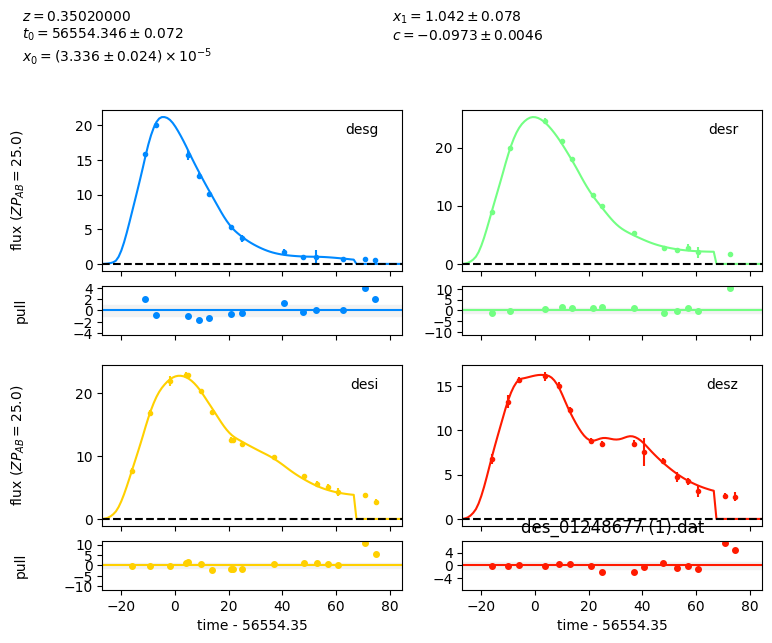

Processing: des_01250017.dat
Fitness within 2σ: 81.67%


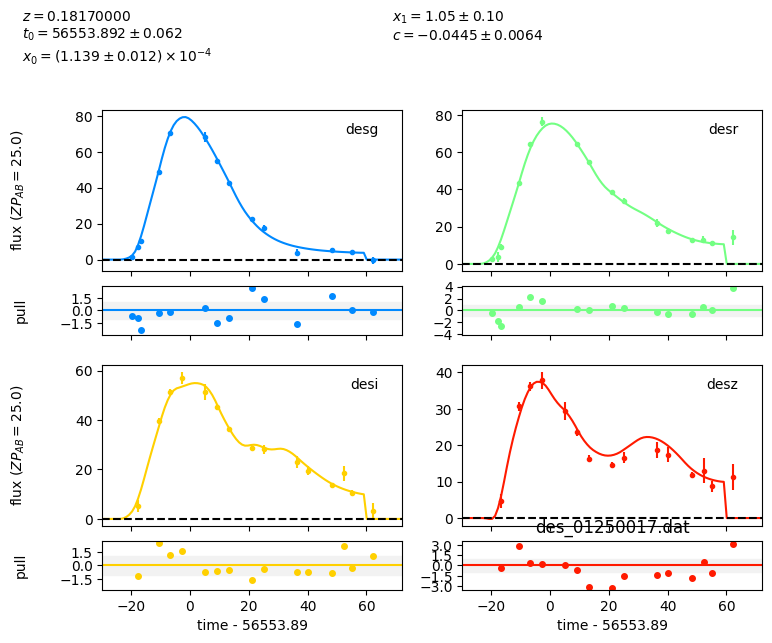

Processing: des_01253039.dat
Fitness within 2σ: 93.24%


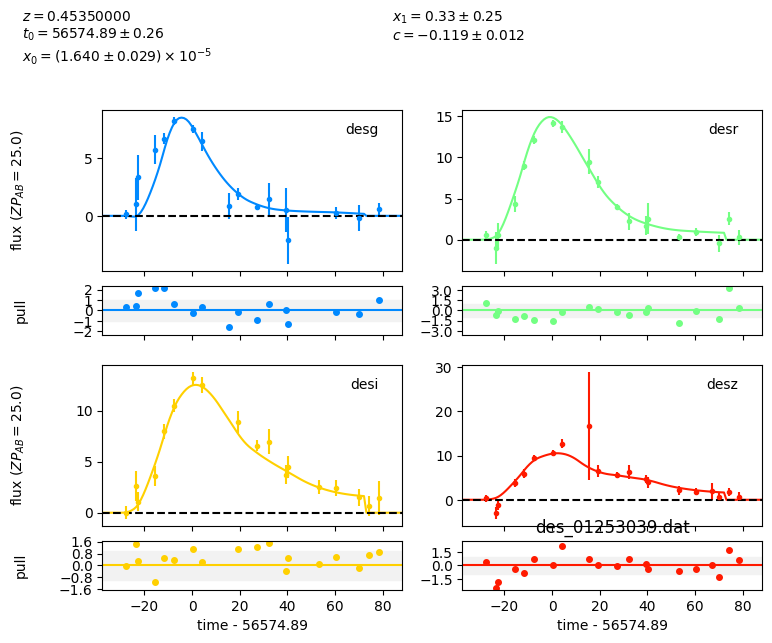

Processing: des_01253101.dat
Fitness within 2σ: 95.59%


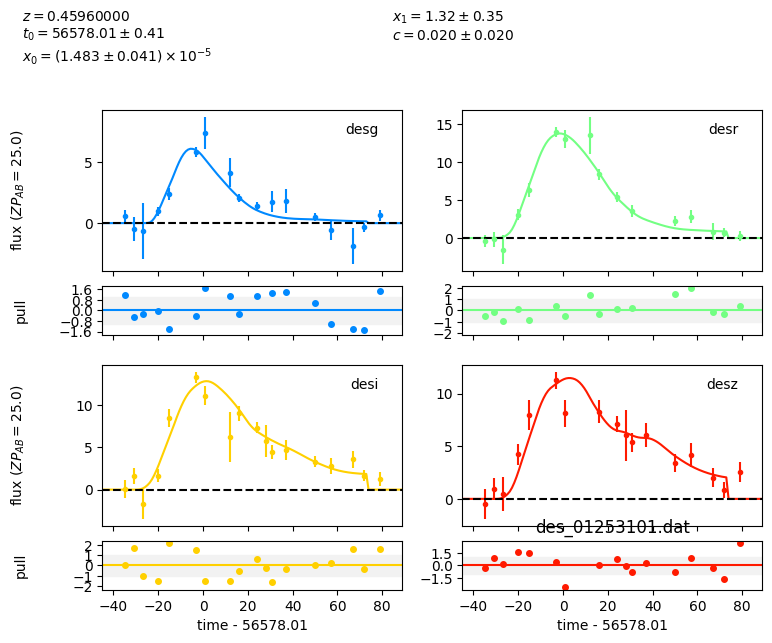

Processing: des_01253920.dat
Fitness within 2σ: 82.76%


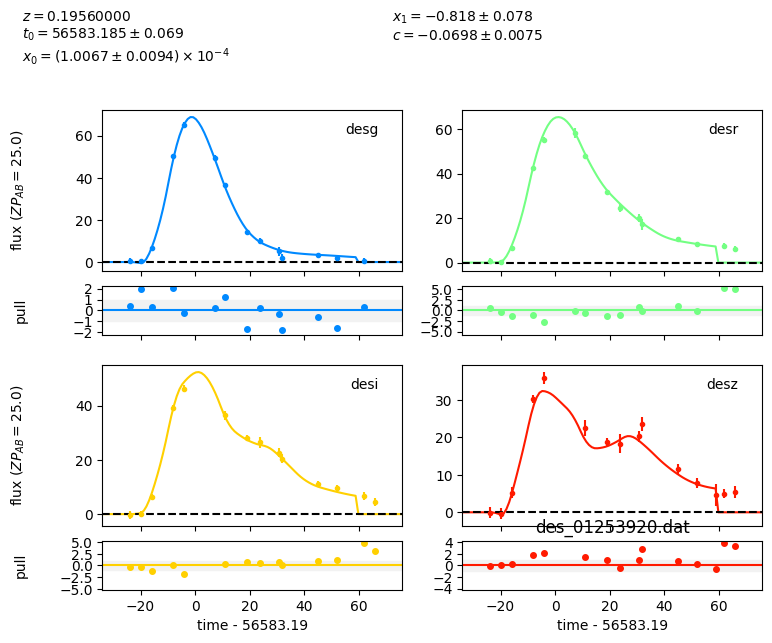

Processing: des_01255502.dat
Fitness within 2σ: 68.97%


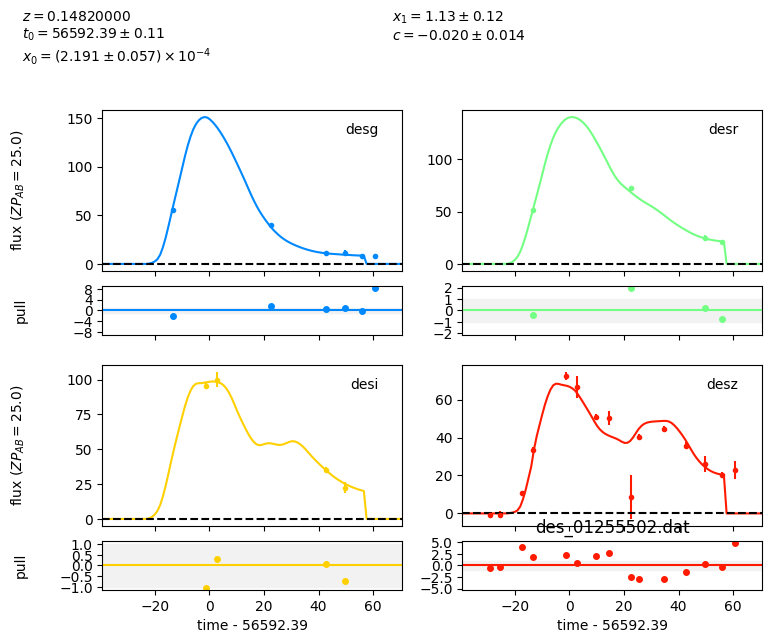

Processing: des_01257366.dat
Fitness within 2σ: 87.50%


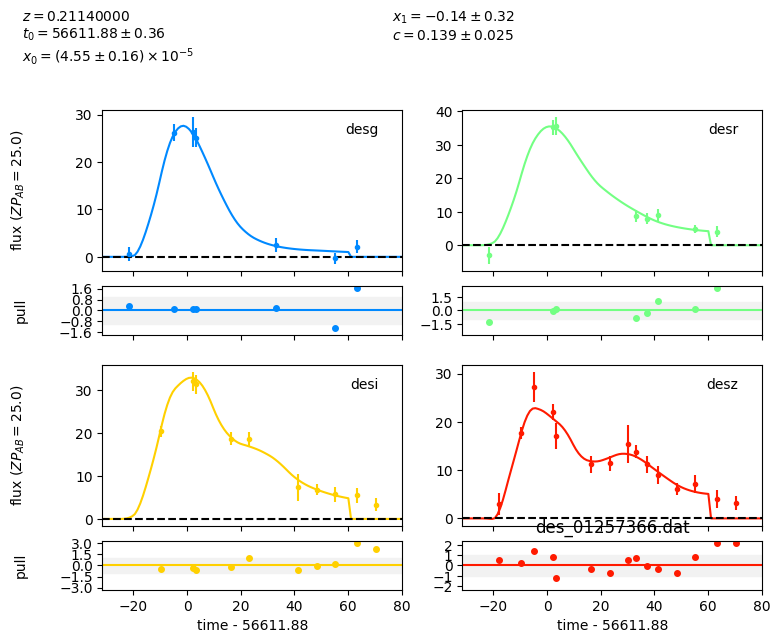

Processing: des_01257695.dat
Fitness within 2σ: 75.00%


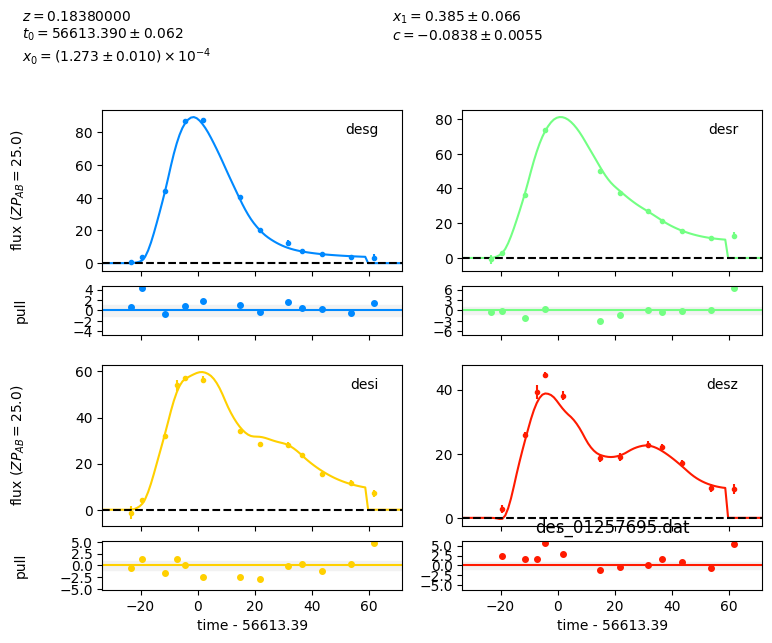

Processing: des_01258906.dat
Fitness within 2σ: 94.64%


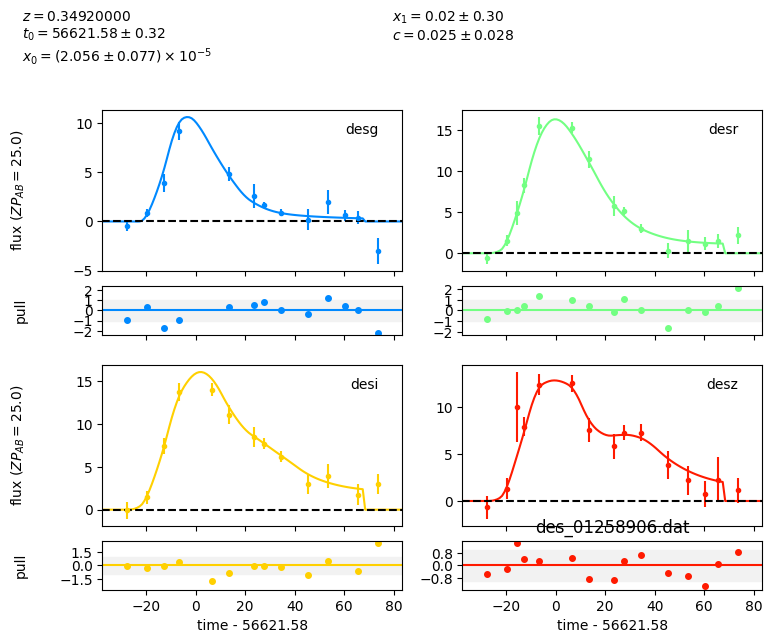

Processing: des_01258940.dat
Fitness within 2σ: 97.14%


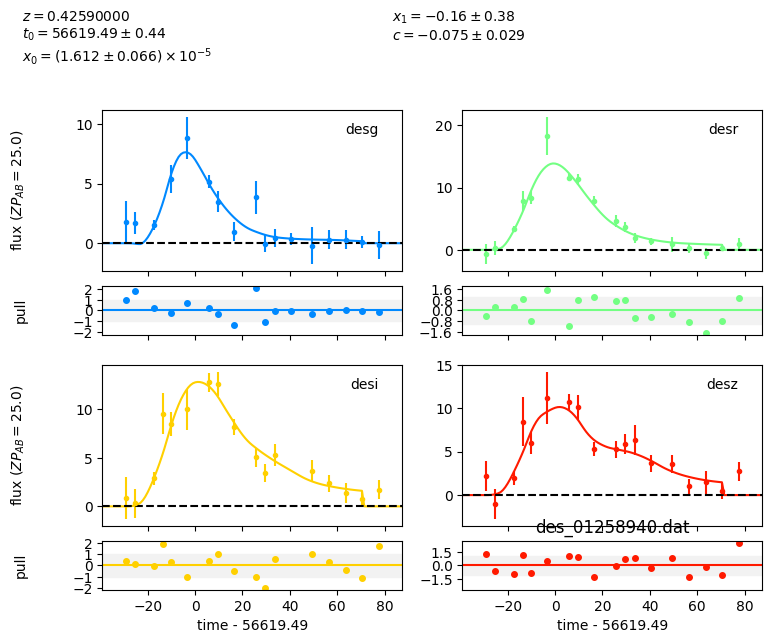

Processing: des_01259412.dat
Fitness within 2σ: 89.36%


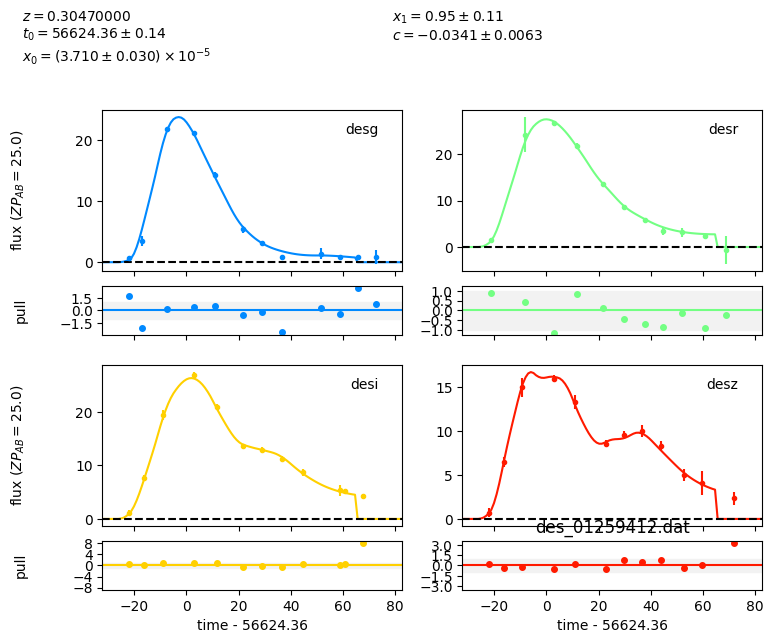

Processing: des_01261579.dat
Fitness within 2σ: 92.50%


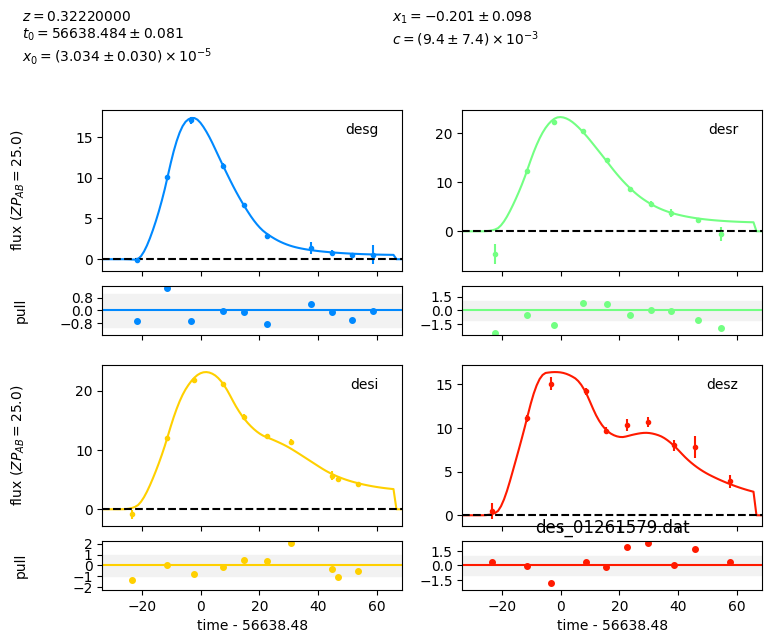

Processing: des_01262214.dat
Fitness within 2σ: 91.18%


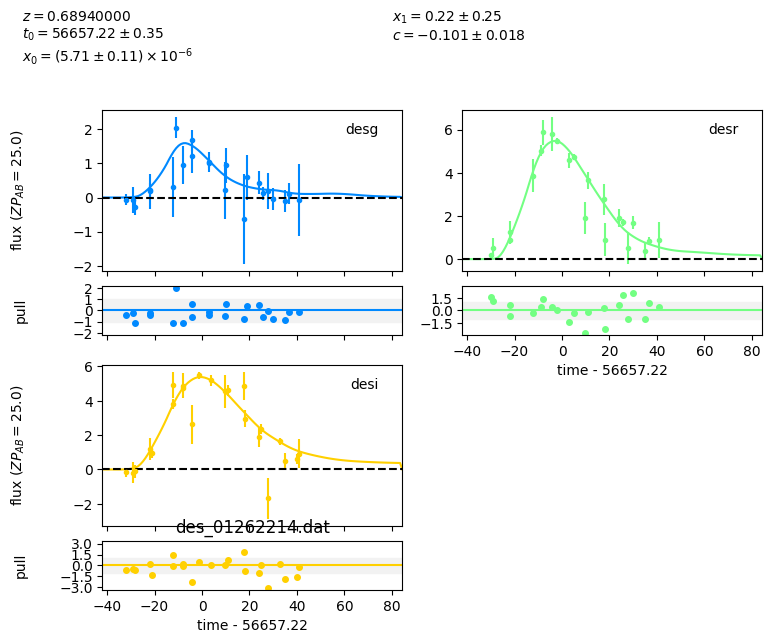

Processing: des_01262715.dat
Fitness within 2σ: 97.83%


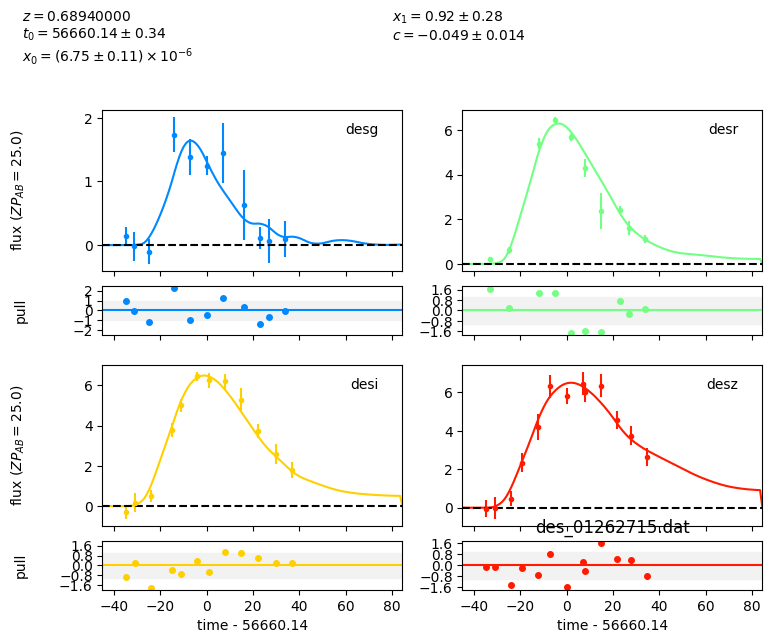

Processing: des_01263369.dat
Fitness within 2σ: 100.00%


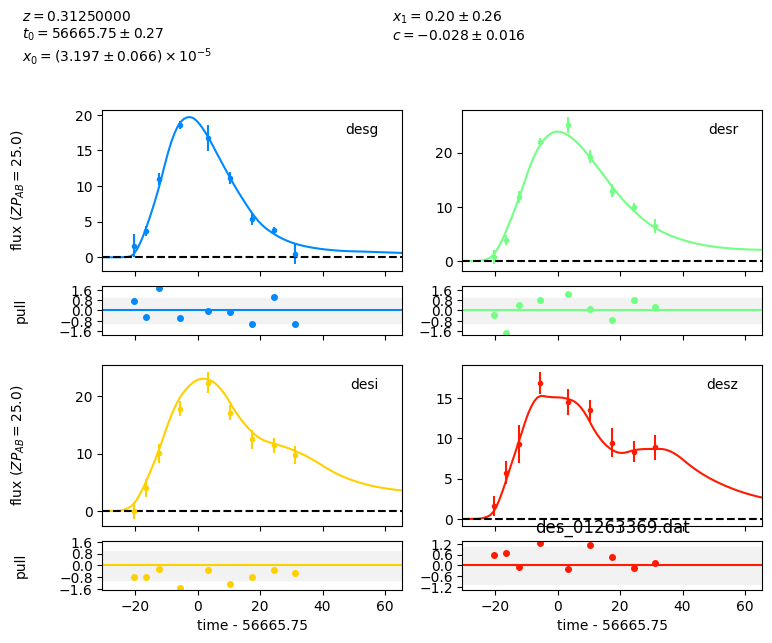

Processing: des_01263715.dat
Fitness within 2σ: 100.00%


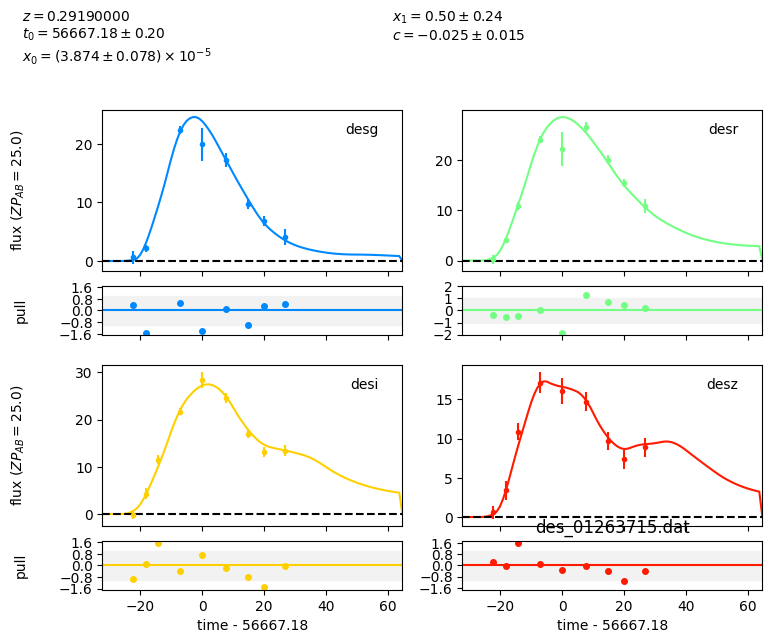

Processing: des_01275946.dat
Fitness within 2σ: 83.33%


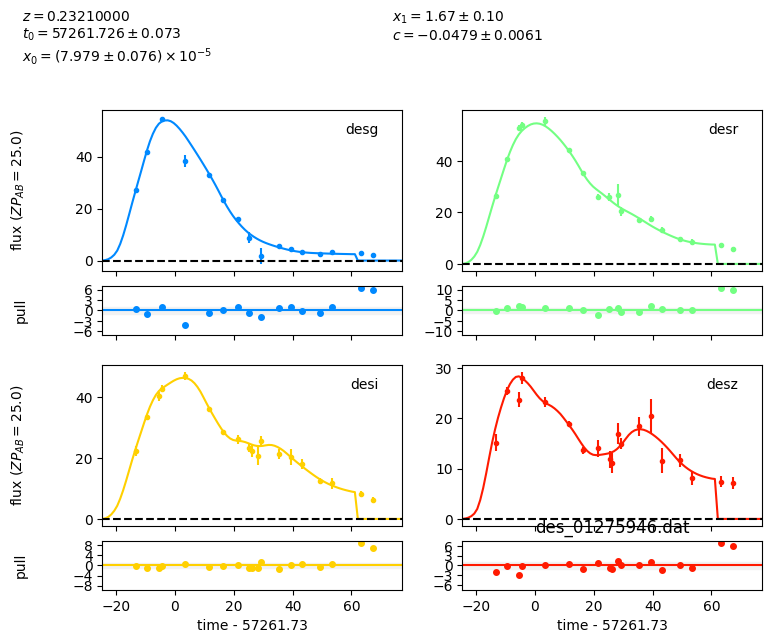

Processing: des_01279500.dat
Fitness within 2σ: 86.67%


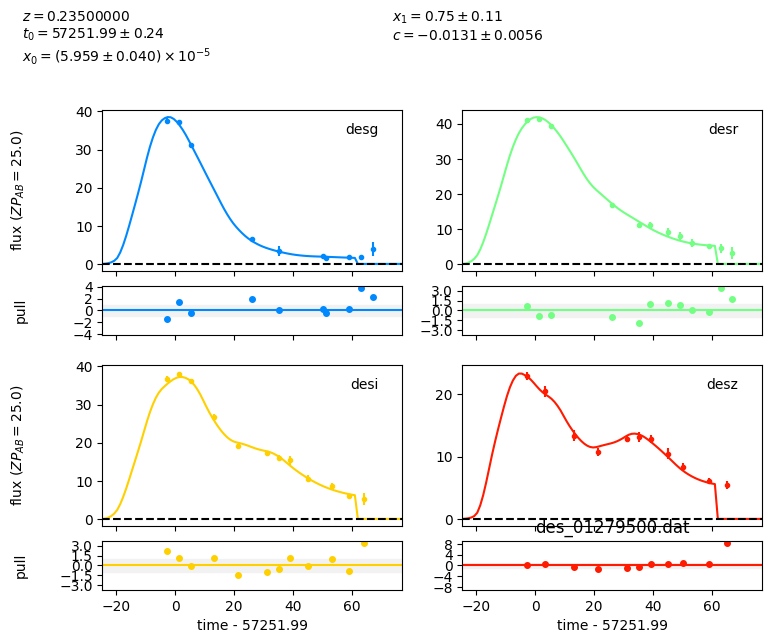

Processing: des_01280217.dat
Fitness within 2σ: 82.54%


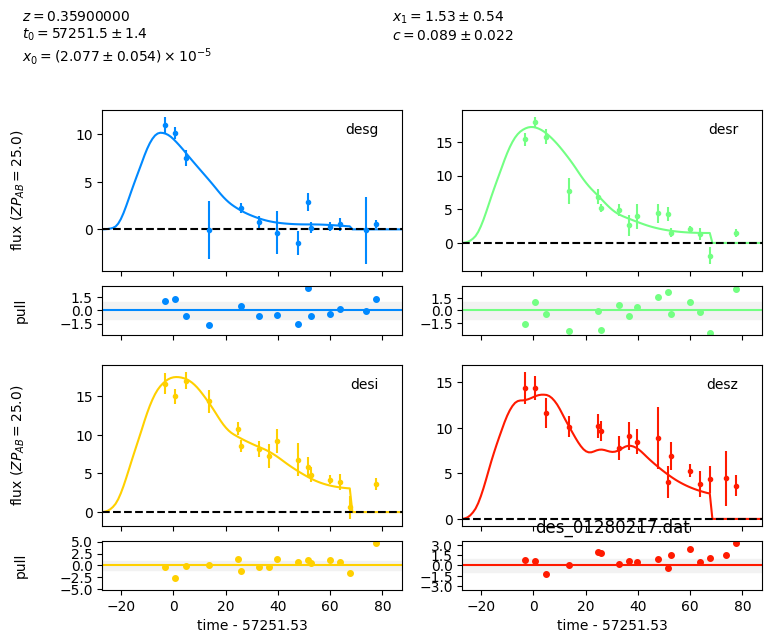

Processing: des_01281668.dat
Fitness within 2σ: 91.57%


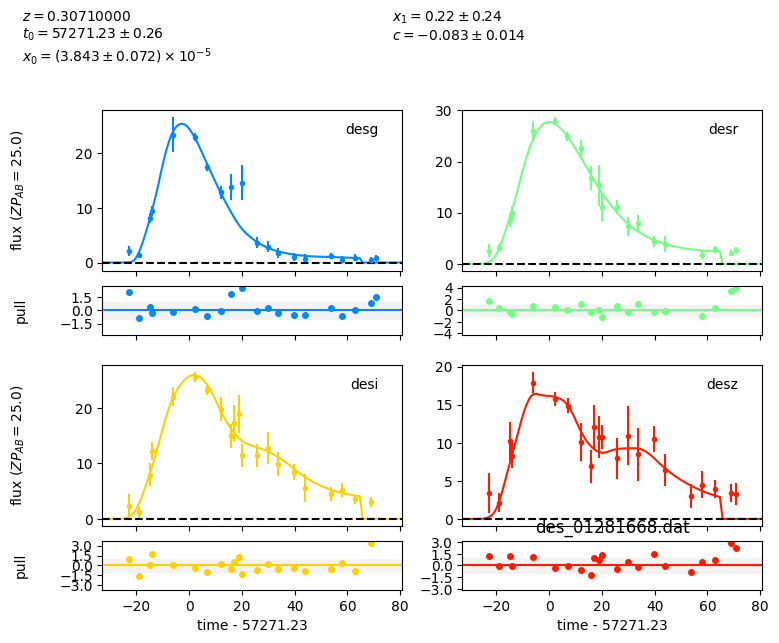

Processing: des_01281886.dat
Fitness within 2σ: 95.71%


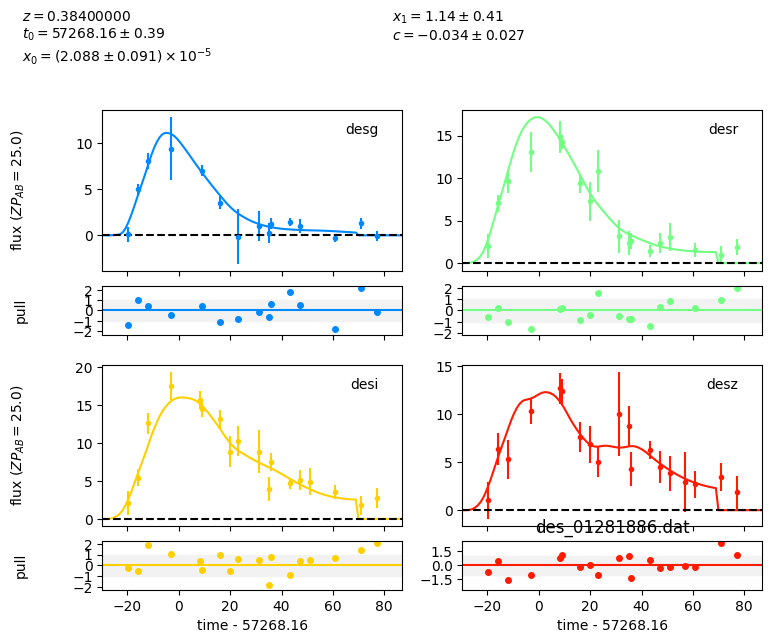

Processing: des_01282736.dat
Fitness within 2σ: 100.00%


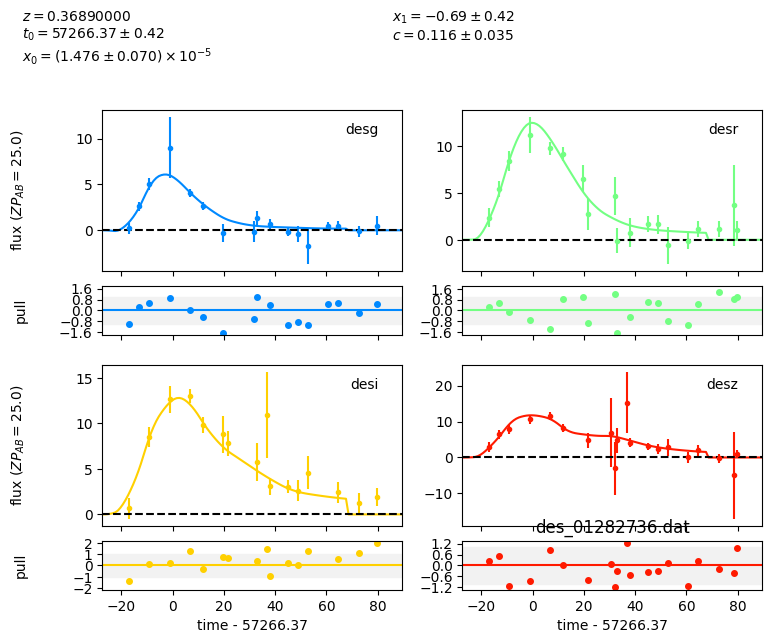

Processing: des_01283878.dat
Fitness within 2σ: 100.00%


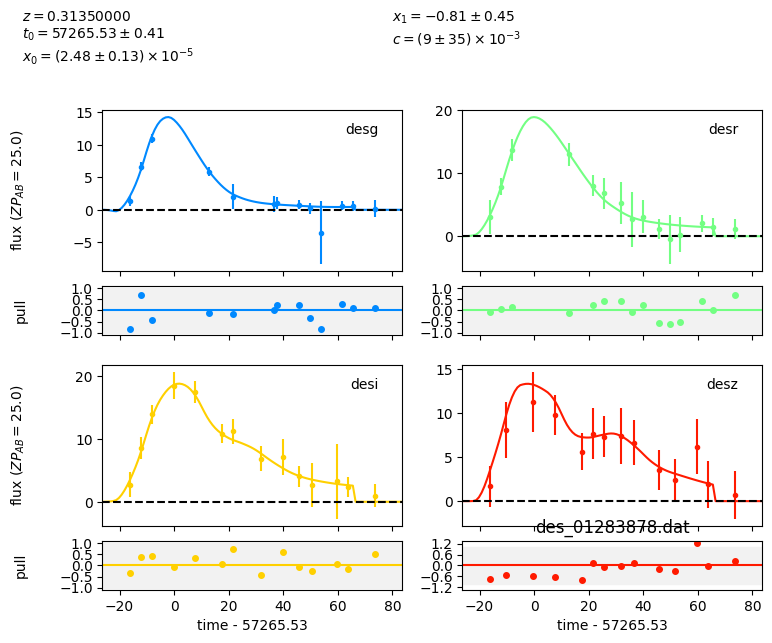

Processing: des_01283373.dat
Fitness within 2σ: 81.97%


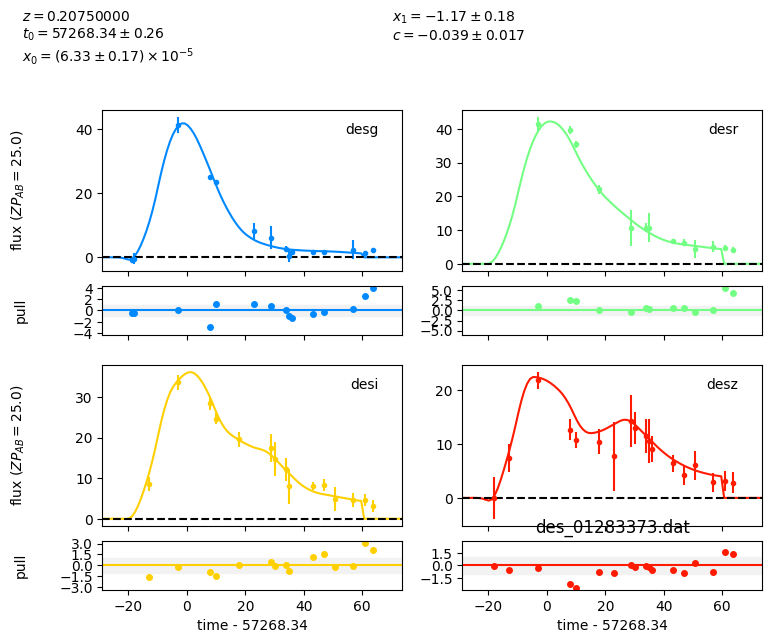

Processing: des_01346966.dat
Fitness within 2σ: 100.00%


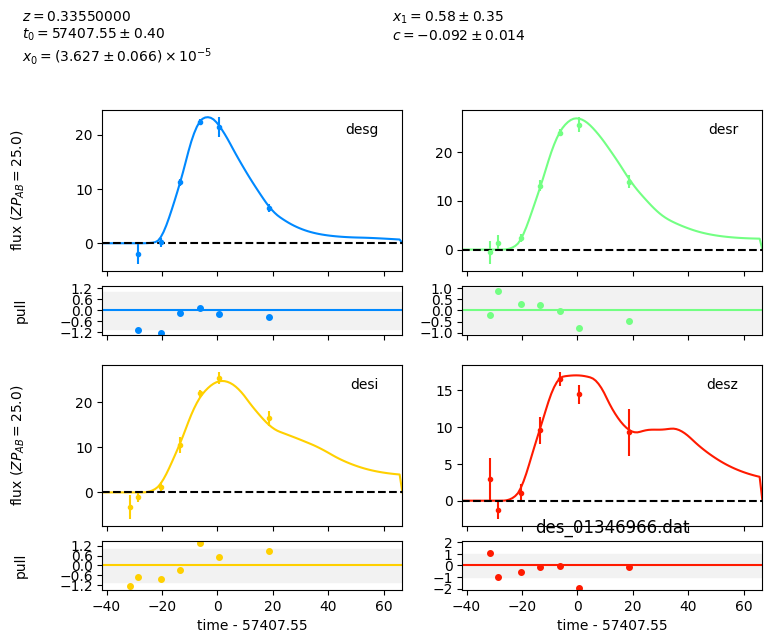

Processing: des_01283936.dat
Fitness within 2σ: 98.82%


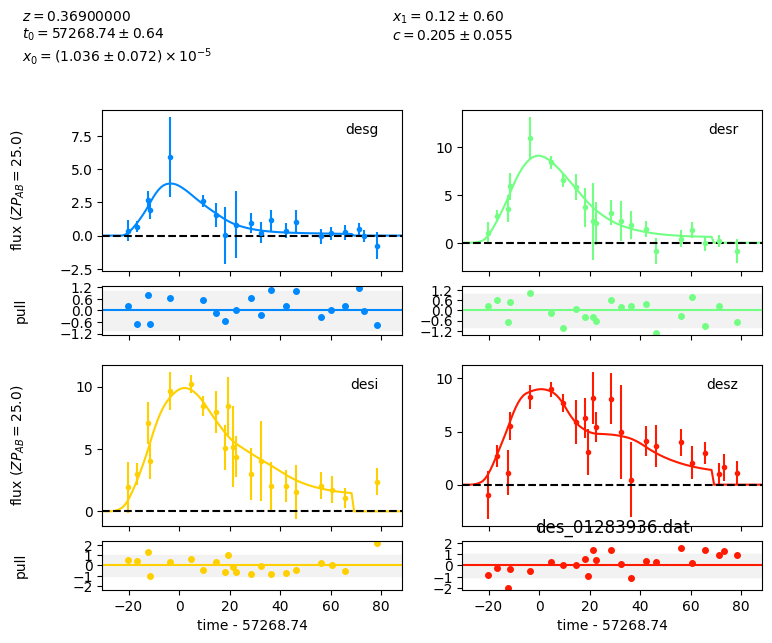

Processing: des_01285160.dat
Fitness within 2σ: 93.06%


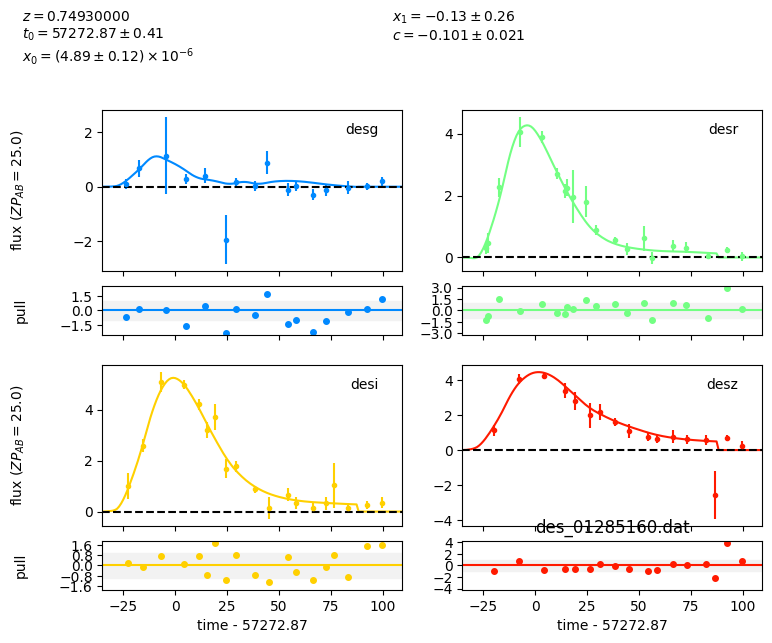

Processing: des_01285317.dat
Fitness within 2σ: 98.91%


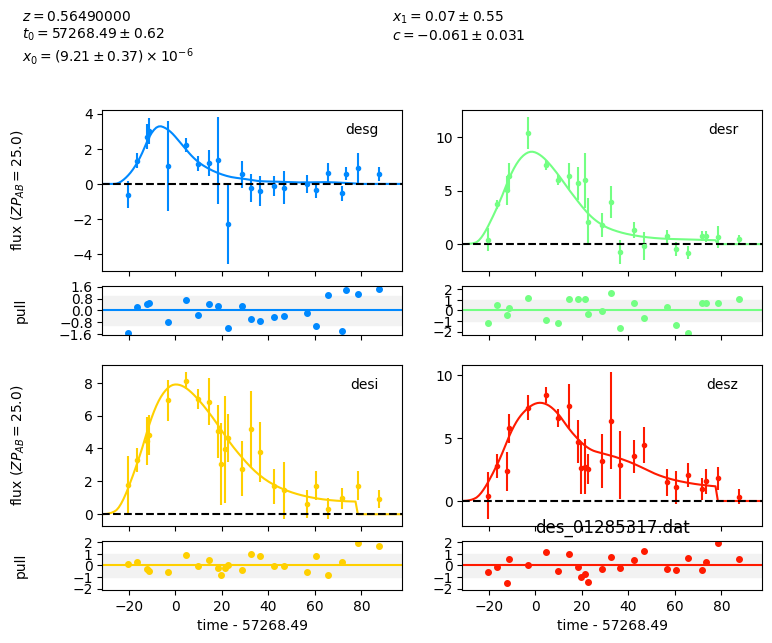

Processing: des_01286398.dat
Fitness within 2σ: 86.54%


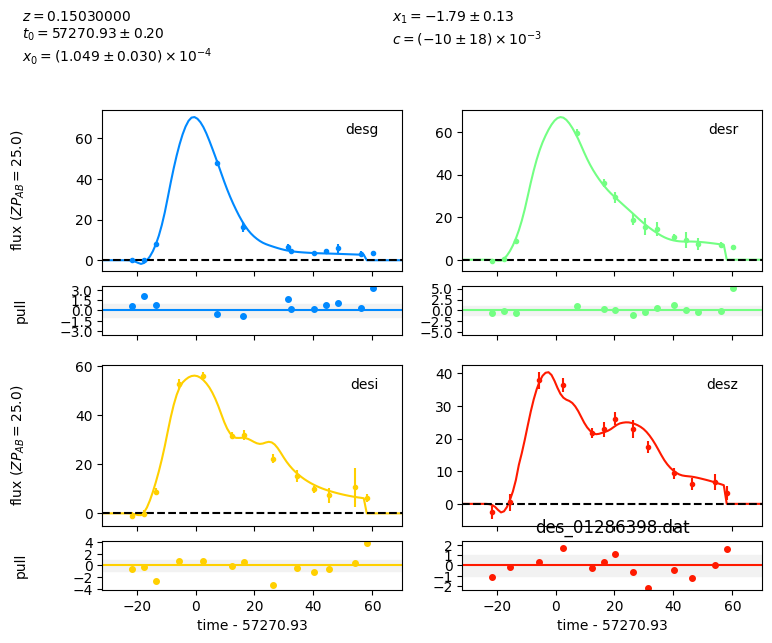

Processing: des_01287626.dat
Fitness within 2σ: 95.65%


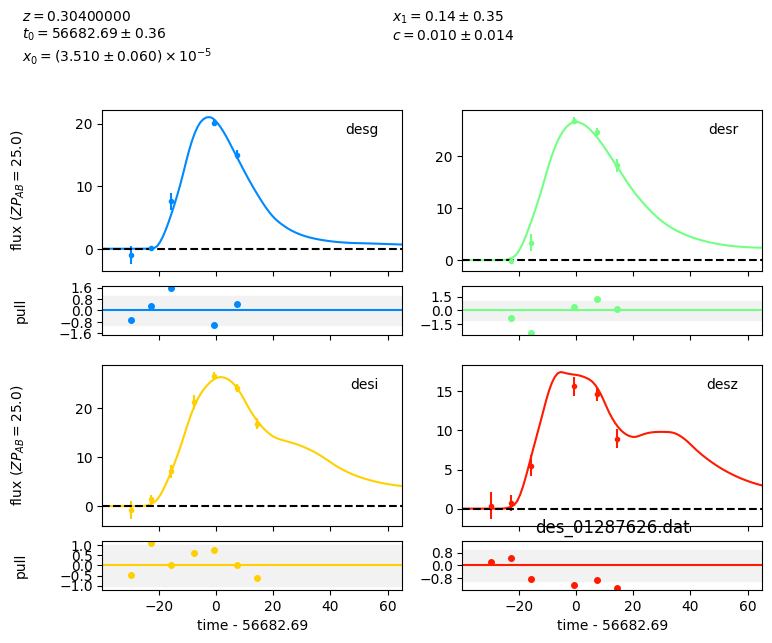

Processing: des_01289288 (1).dat
Fitness within 2σ: 96.30%


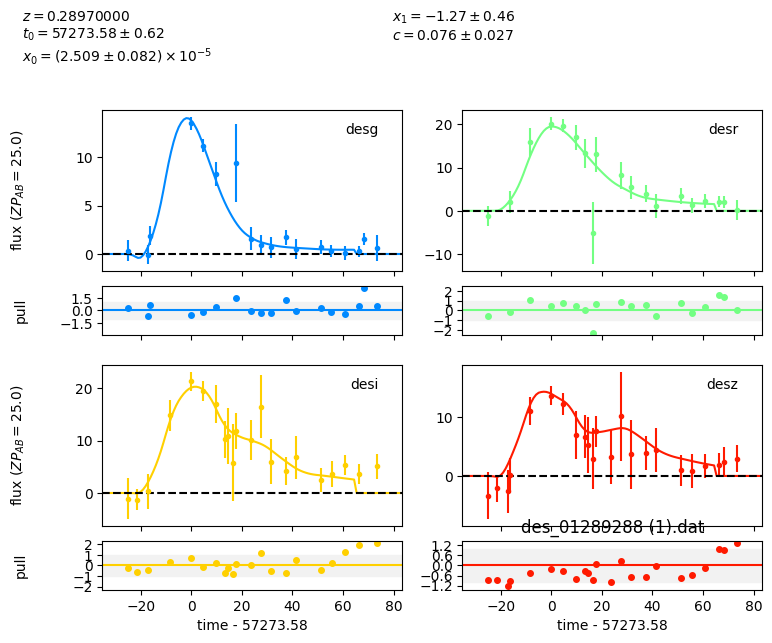

Processing: des_01289656.dat
Fitness within 2σ: 98.67%


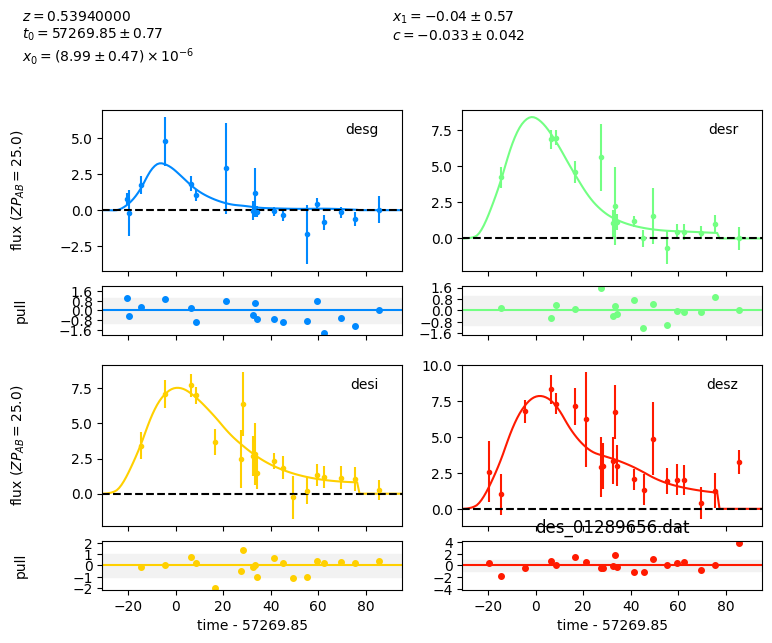

Processing: des_01289664.dat
Fitness within 2σ: 82.81%


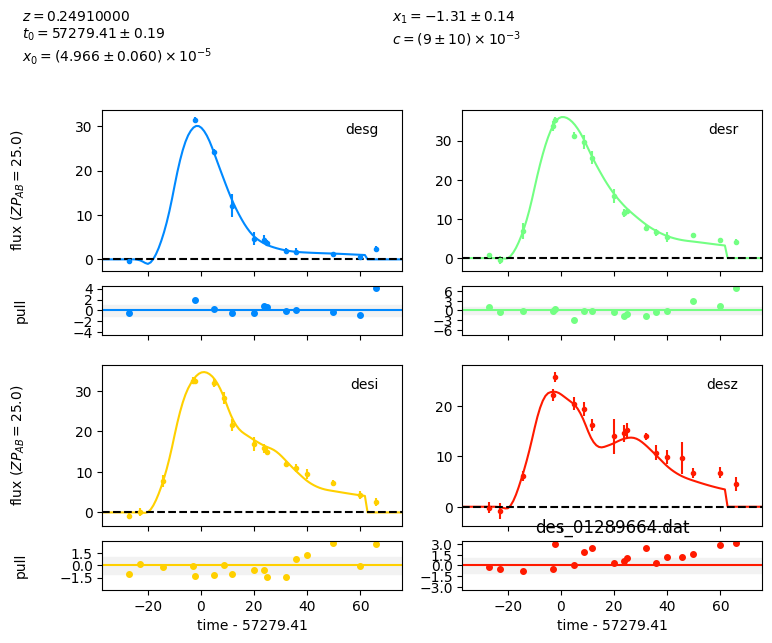

Processing: des_01290779.dat
Fitness within 2σ: 100.00%


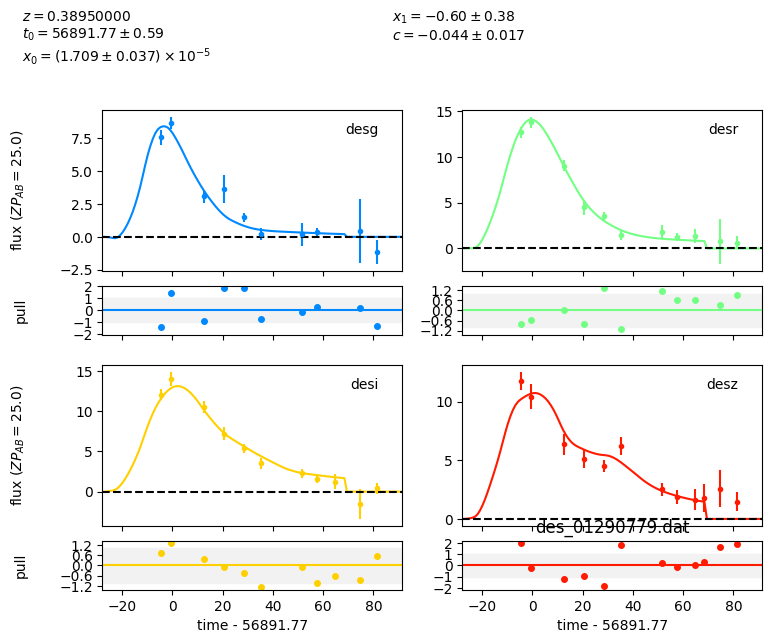

Processing: des_01290816.dat
Fitness within 2σ: 80.00%


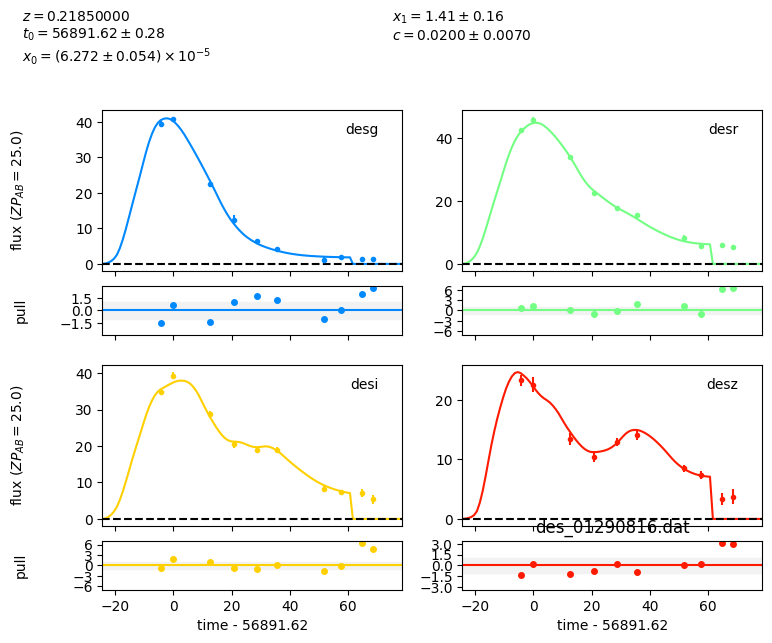

Processing: des_01291080.dat
Fitness within 2σ: 92.31%


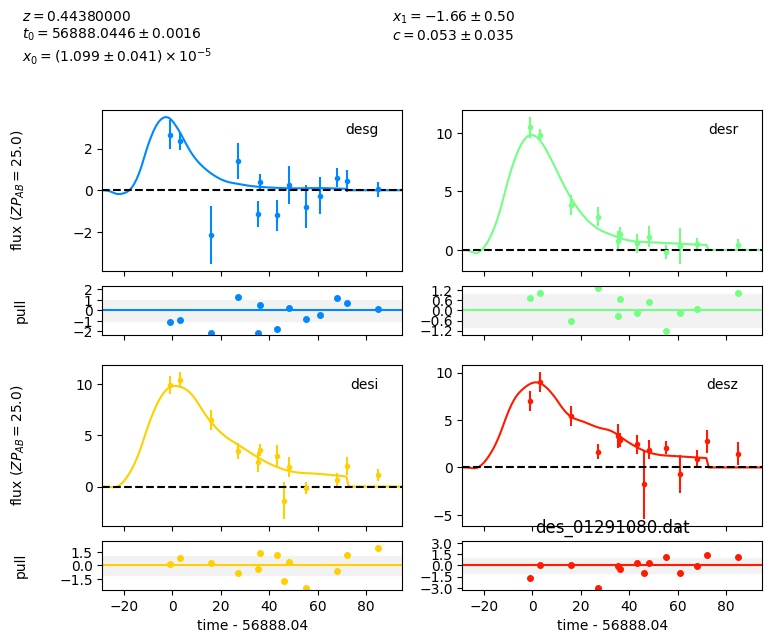

Processing: des_01291090.dat
Fitness within 2σ: 92.16%


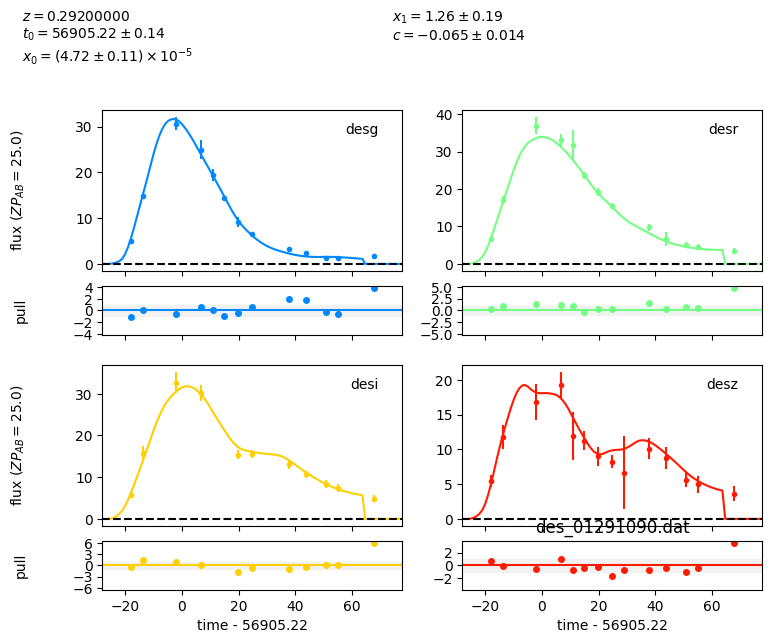

Processing: des_01291794.dat
Fitness within 2σ: 100.00%


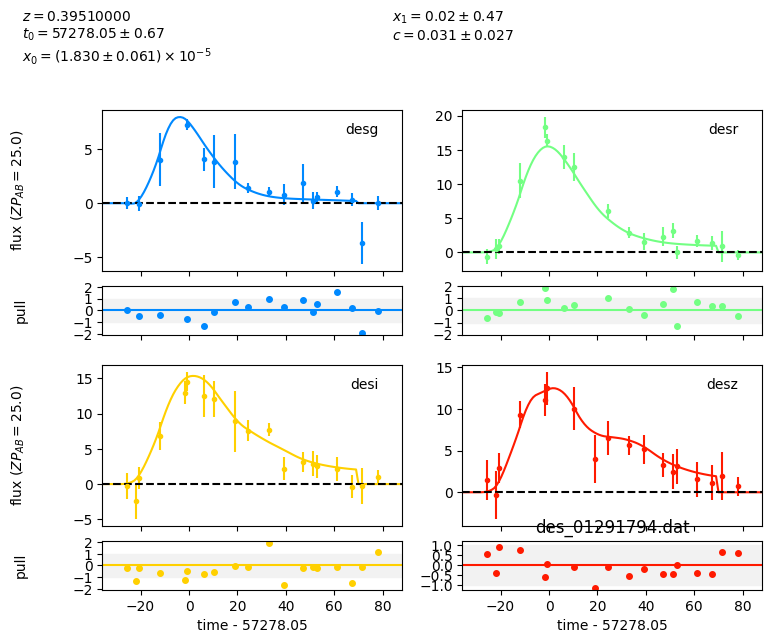

Processing: des_01291957.dat
Fitness within 2σ: 88.33%


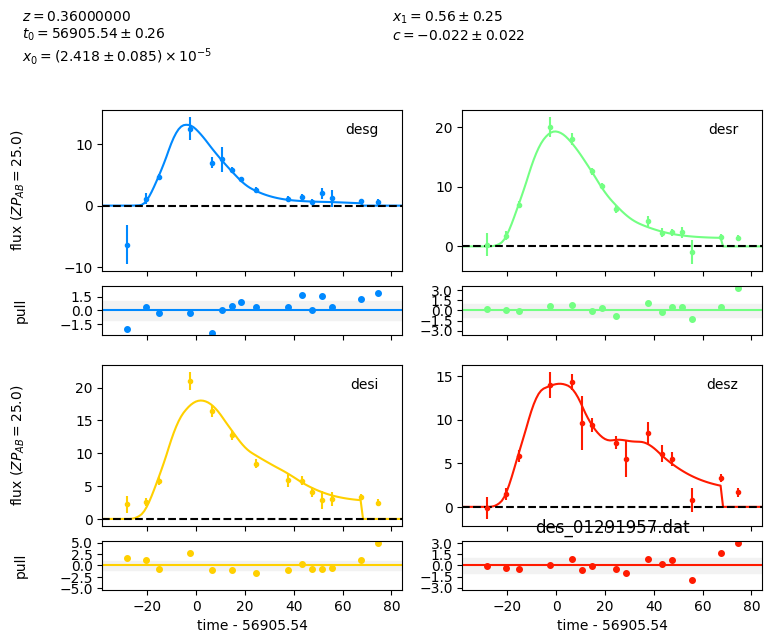

Processing: des_01292145.dat
Fitness within 2σ: 100.00%


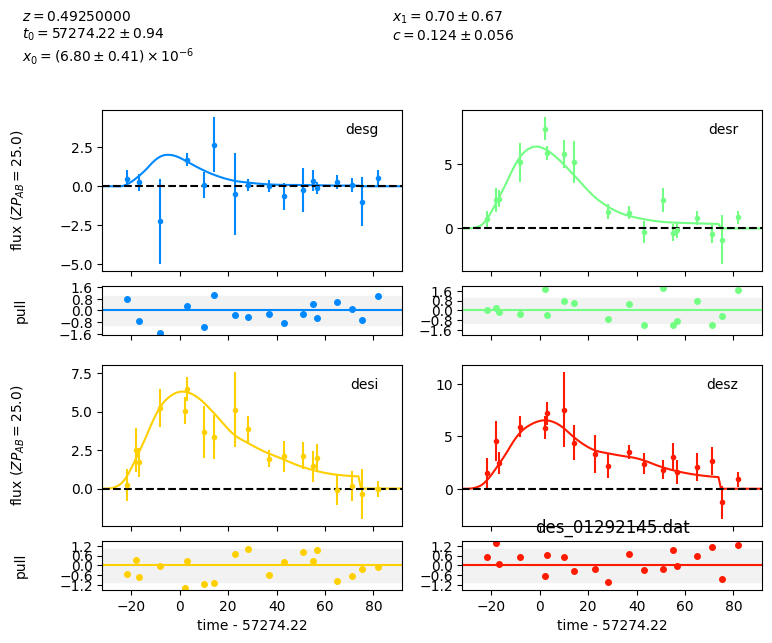

Processing: des_01292195.dat
Fitness within 2σ: 93.83%


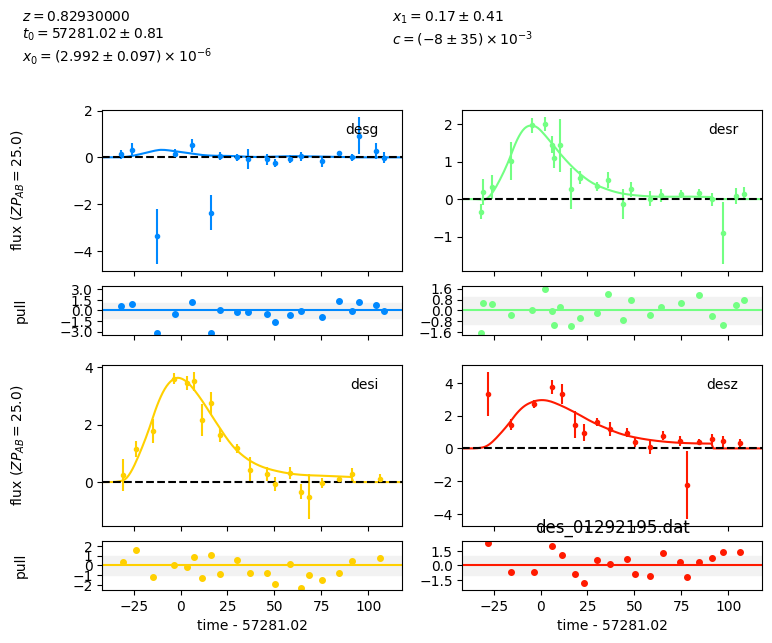

Processing: des_01292336.dat
Fitness within 2σ: 83.67%


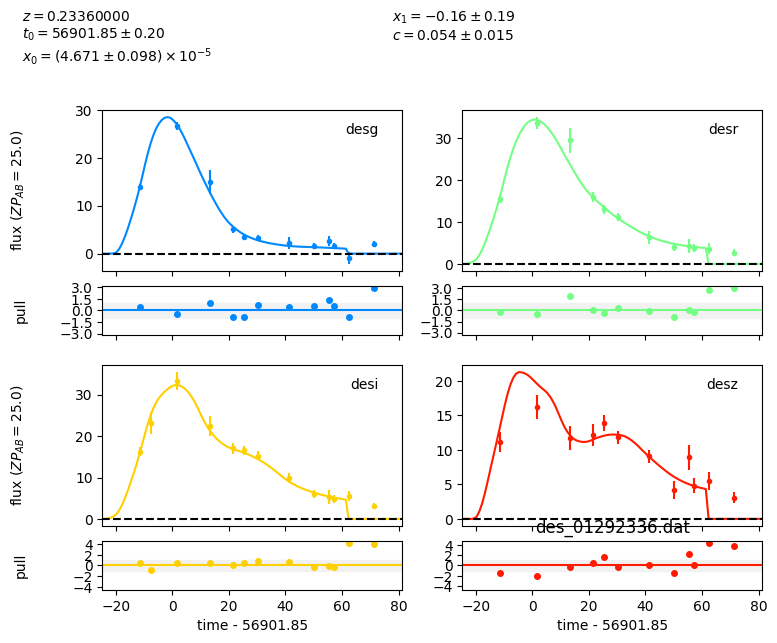

Processing: des_01292332.dat
Fitness within 2σ: 93.88%


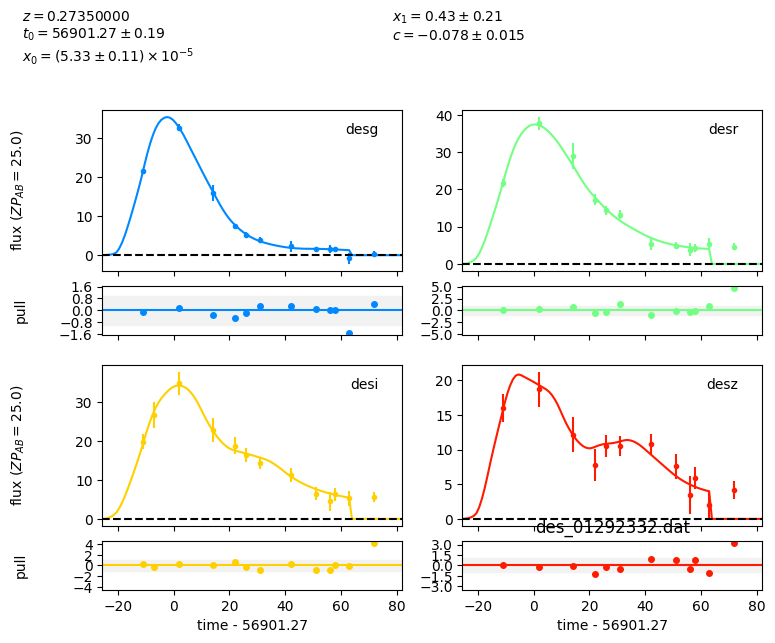

Processing: des_01292560.dat
Fitness within 2σ: 91.67%


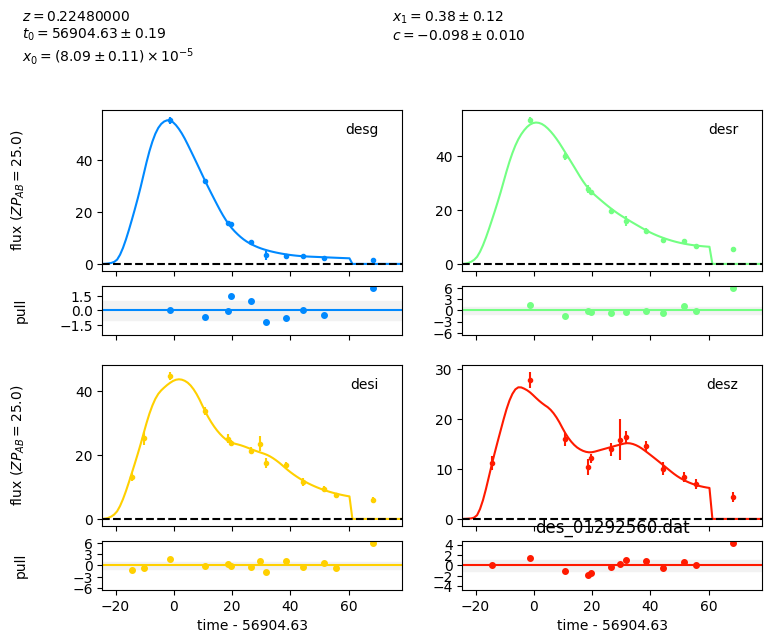

Processing: des_01293319.dat
Fitness within 2σ: 87.72%


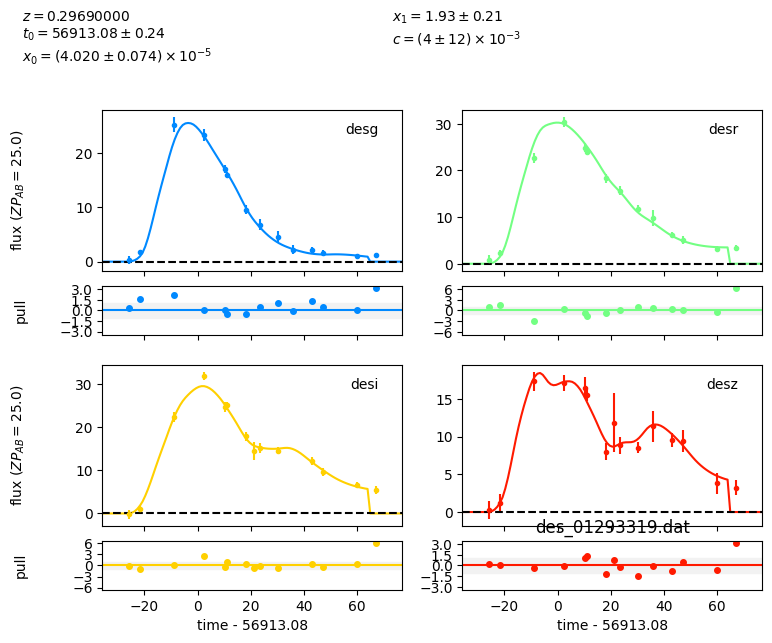

Processing: des_01293758.dat
Fitness within 2σ: 82.86%


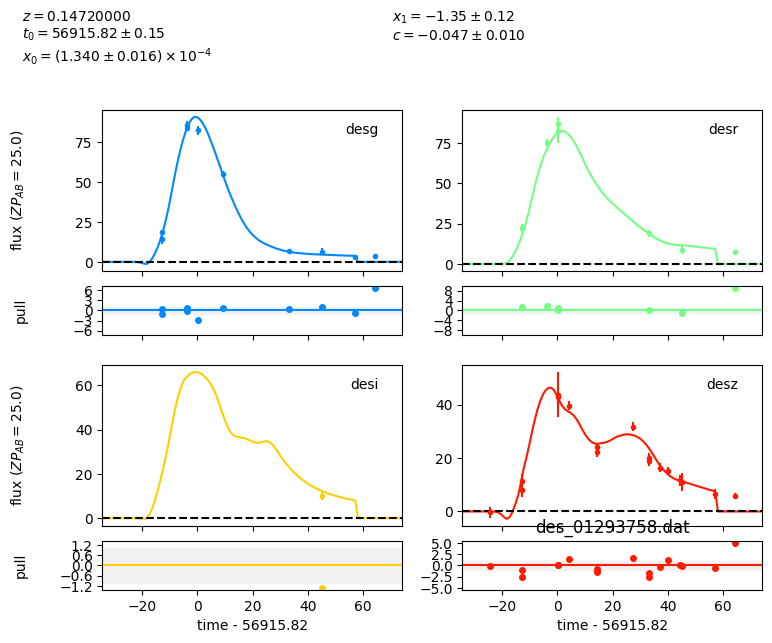

Processing: des_01294014.dat
Fitness within 2σ: 89.74%


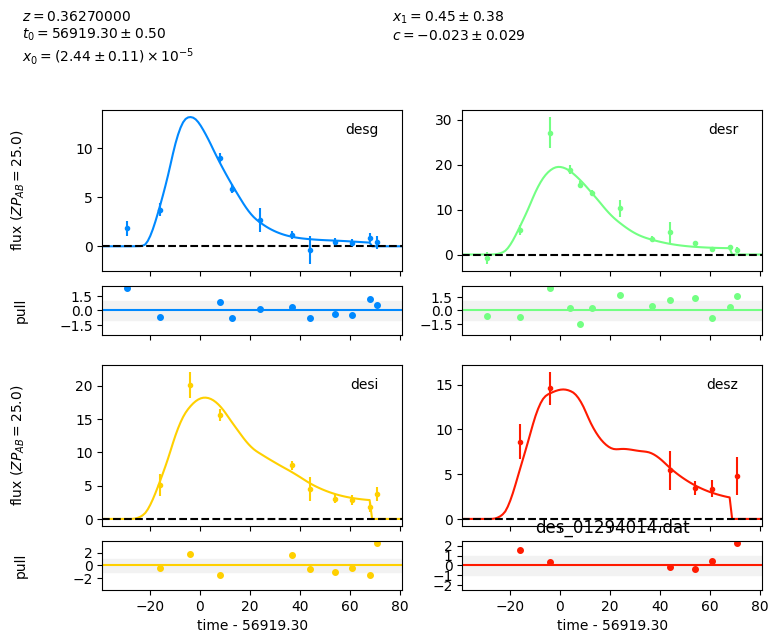

Processing: des_01294743.dat
Fitness within 2σ: 91.49%


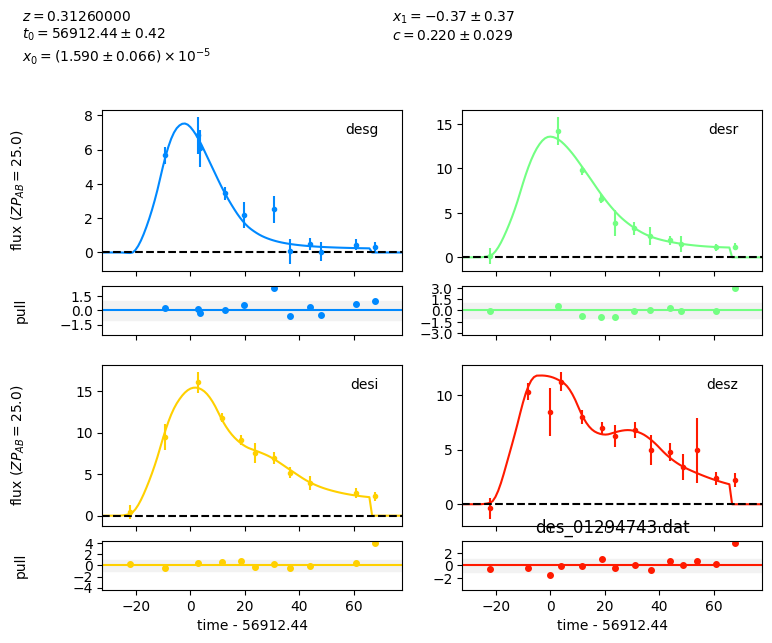

Processing: des_01295027.dat
Fitness within 2σ: 98.59%


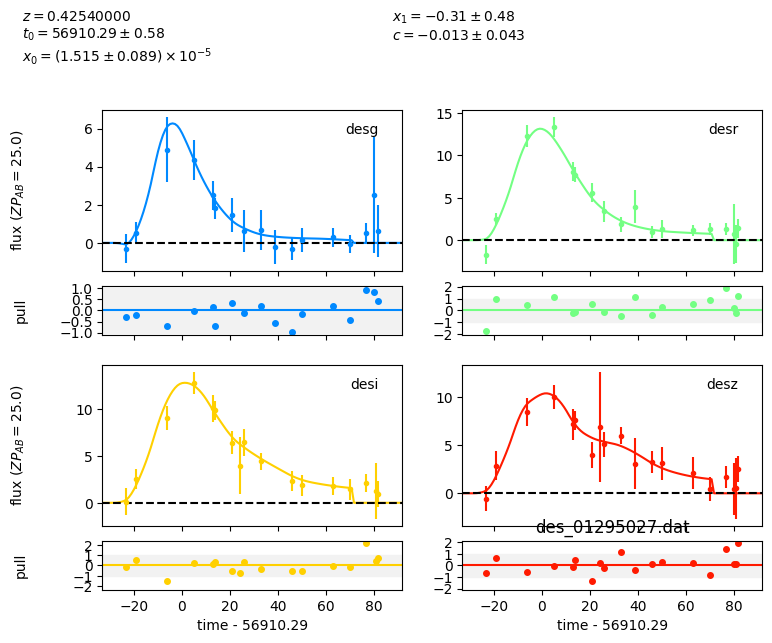

Processing: des_01295256.dat
Fitness within 2σ: 95.00%


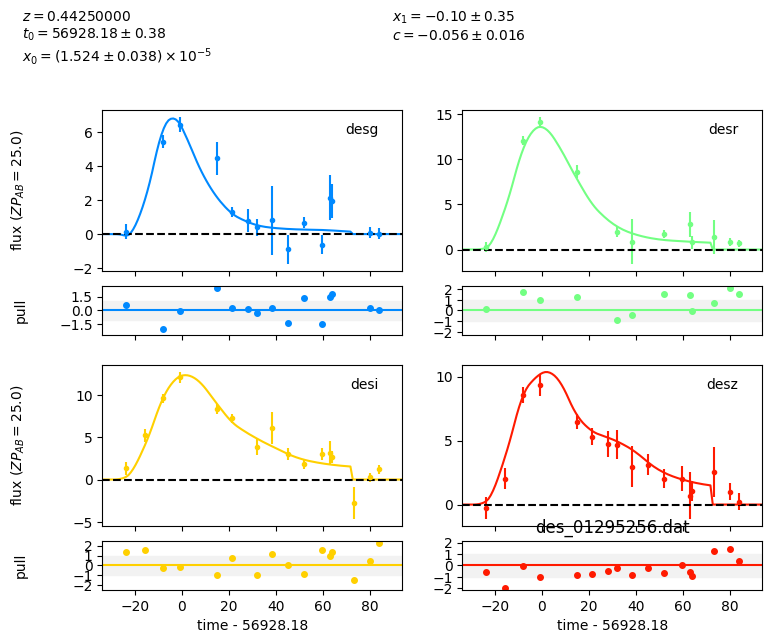

Processing: des_01295305.dat
Fitness within 2σ: 93.65%


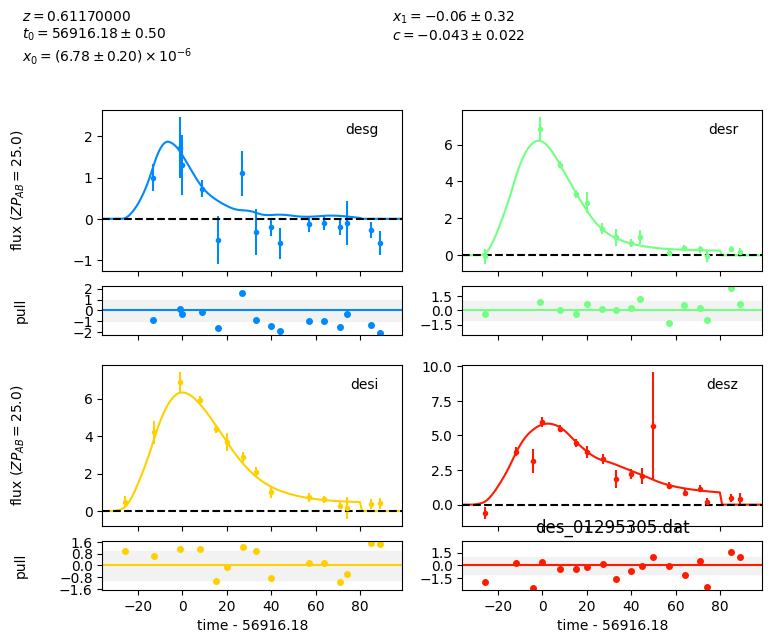

Processing: des_01296273.dat
Fitness within 2σ: 84.13%


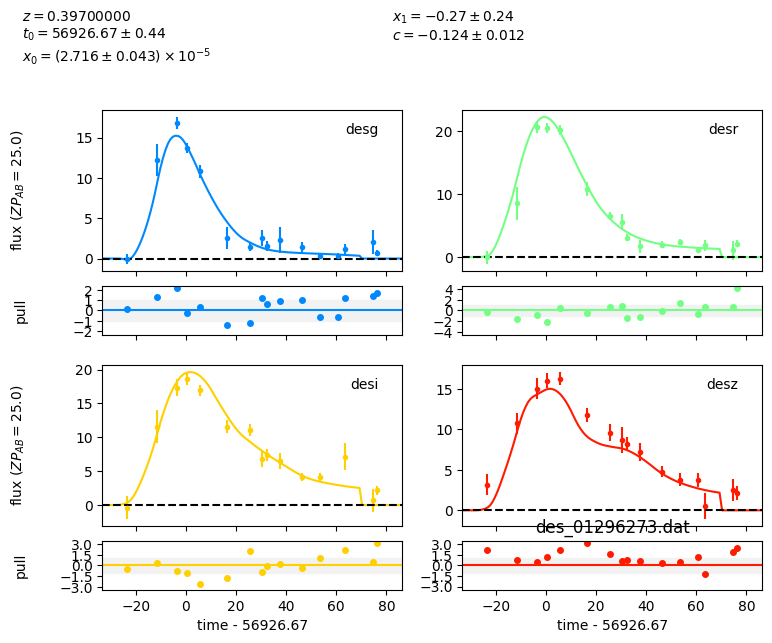

Processing: des_01295921.dat
Fitness within 2σ: 96.30%


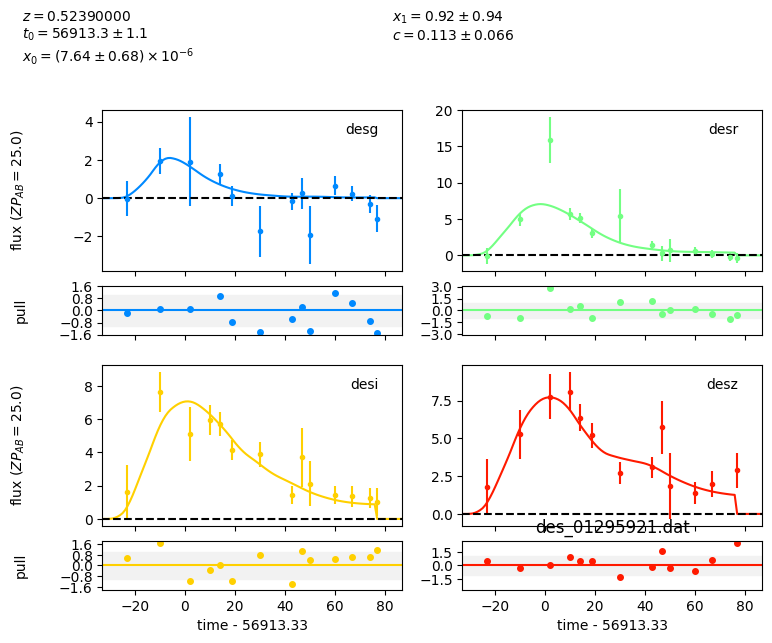

Processing: des_01296321.dat
Fitness within 2σ: 94.12%


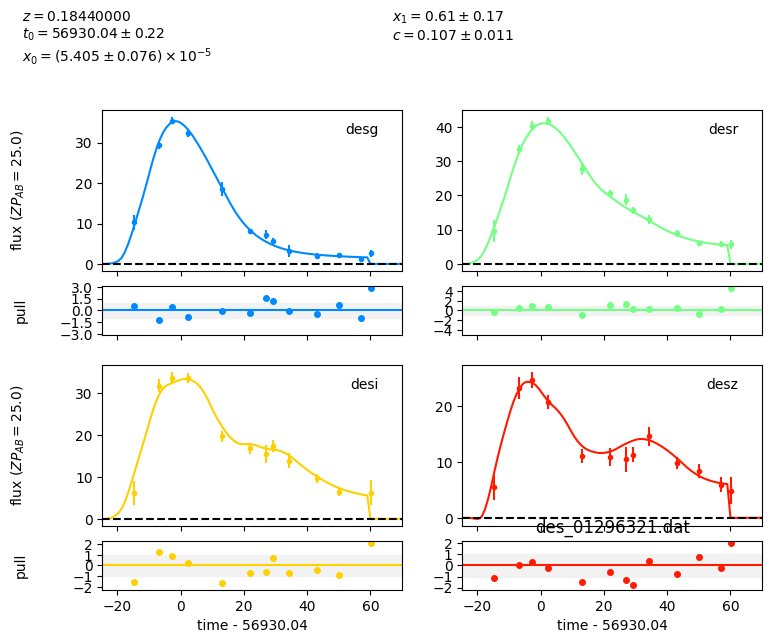

Processing: des_01296657.dat
Fitness within 2σ: 87.50%


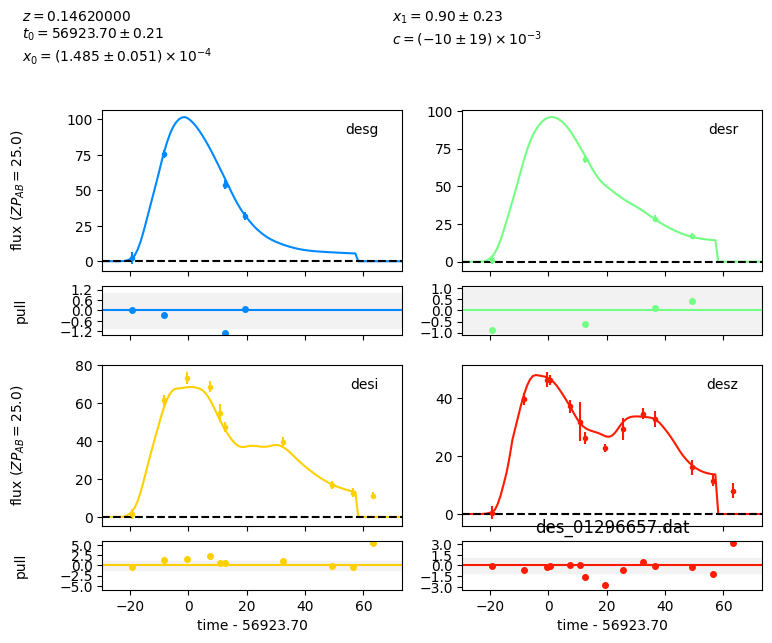

Processing: des_01297465.dat
Fitness within 2σ: 93.55%


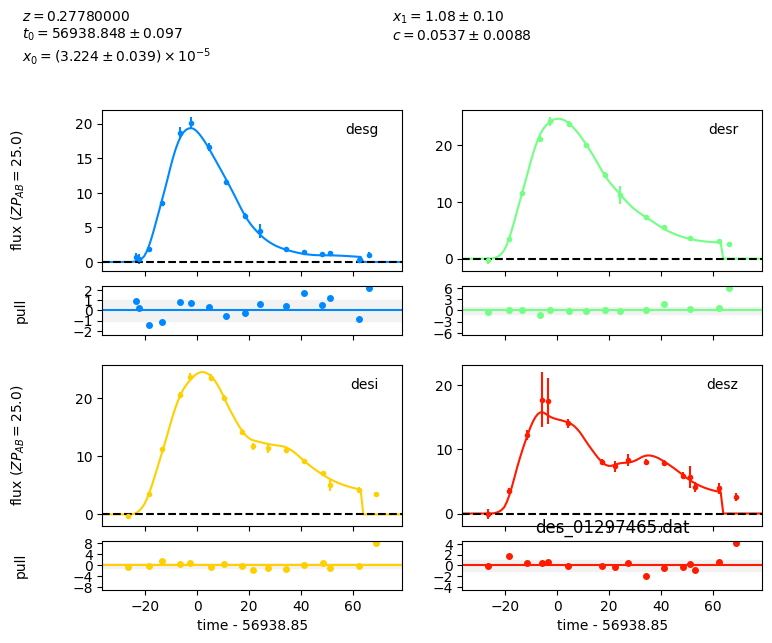

Processing: des_01297026.dat
Fitness within 2σ: 94.64%


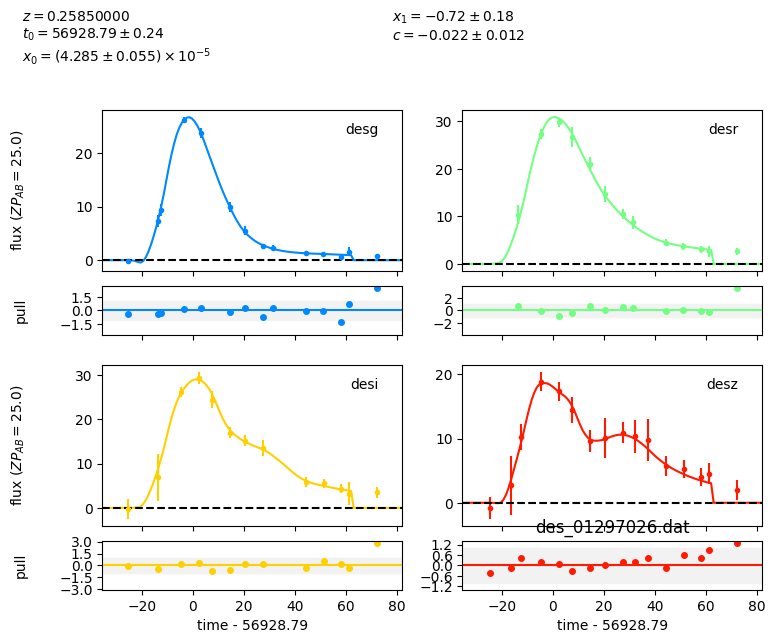

Processing: des_01298281.dat
Fitness within 2σ: 96.55%


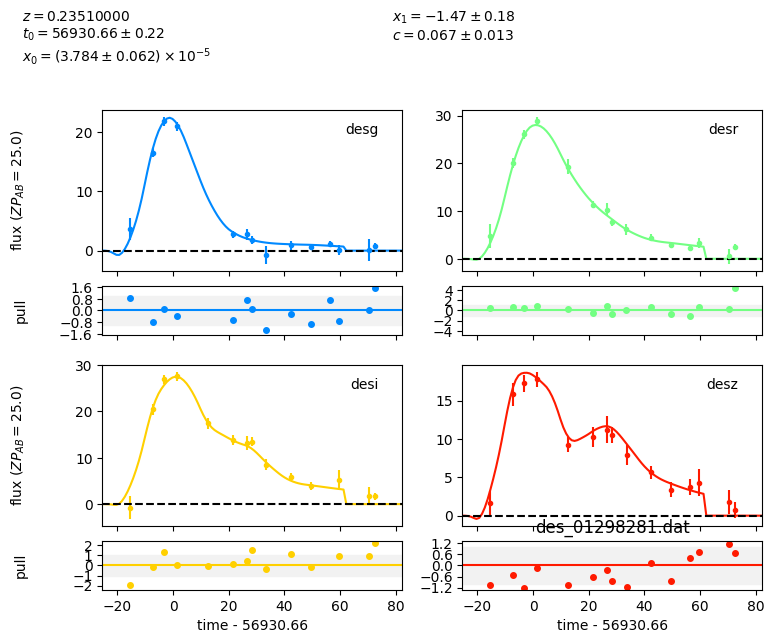

Processing: des_01298893.dat
Fitness within 2σ: 100.00%


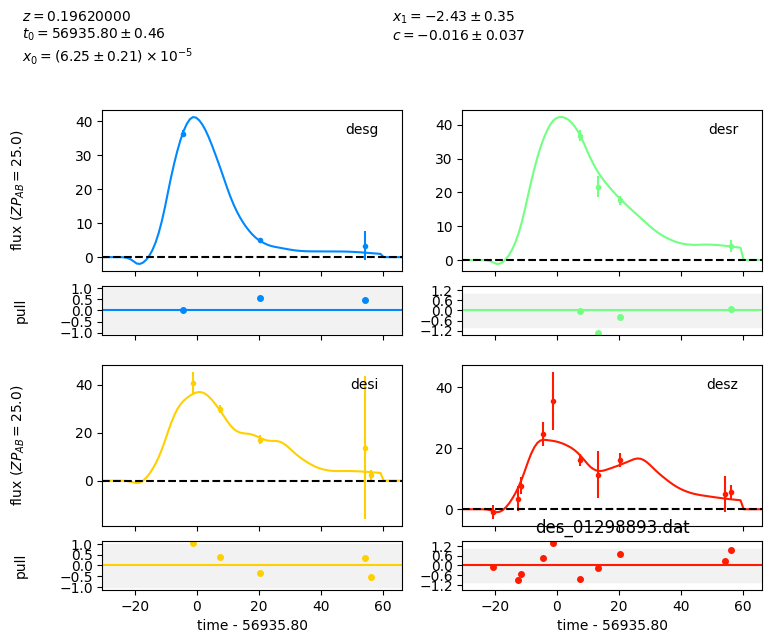

Processing: des_01299643.dat
Fitness within 2σ: 93.94%


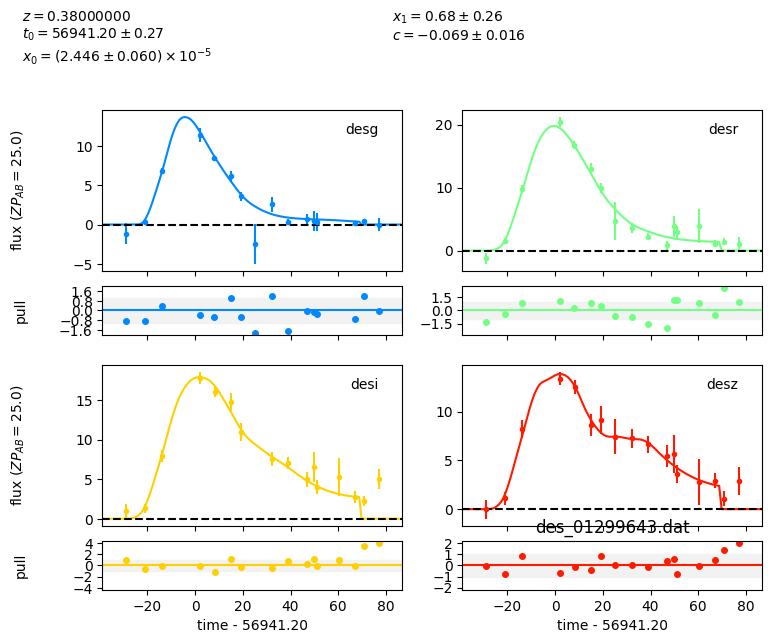

Processing: des_01299775.dat
Fitness within 2σ: 91.89%


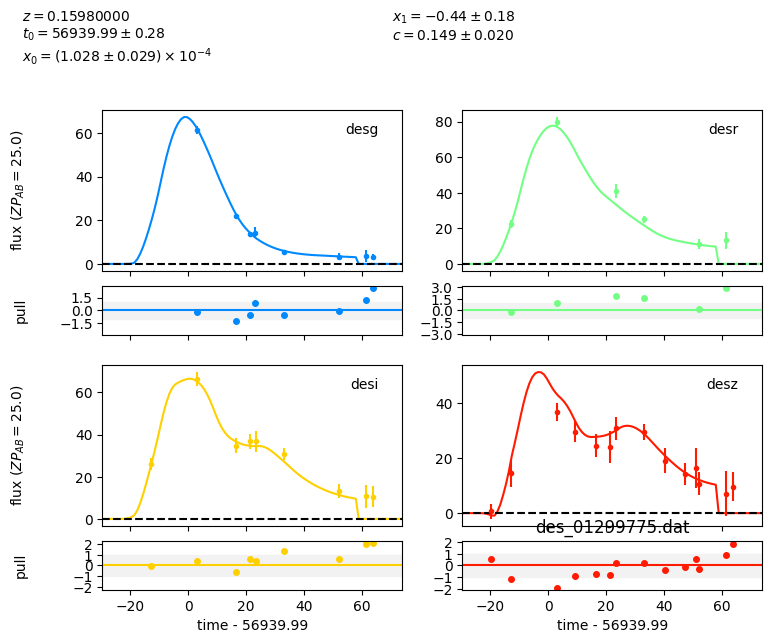

Processing: des_01299785.dat
Fitness within 2σ: 98.44%


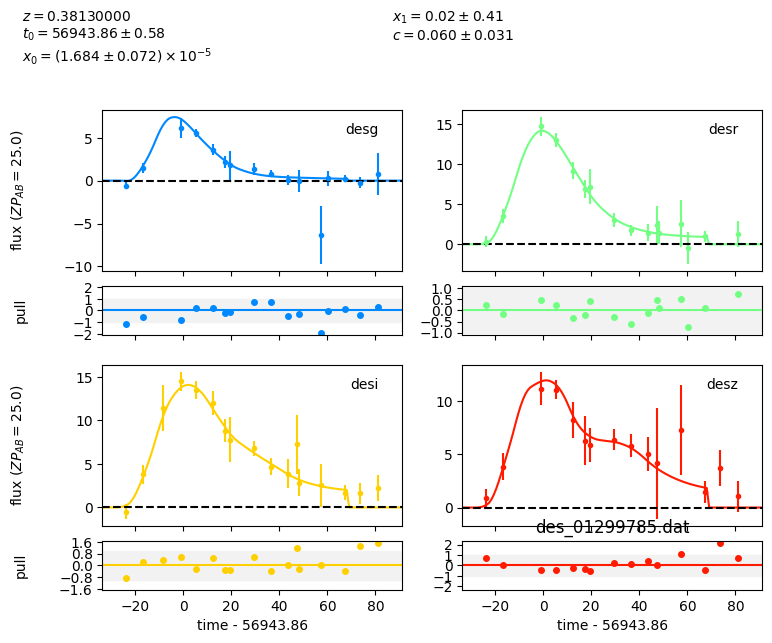

Processing: des_01300516.dat
Fitness within 2σ: 92.75%


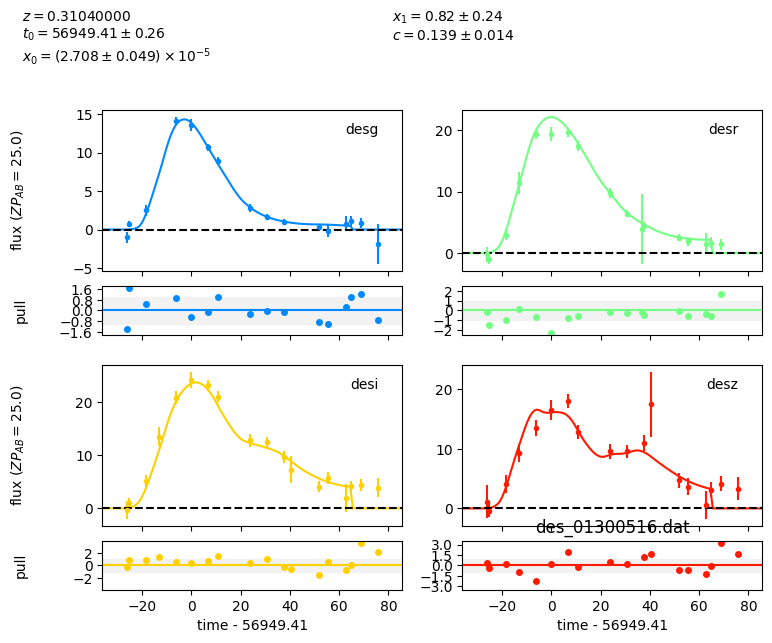

Processing: des_01300912.dat
Fitness within 2σ: 95.38%


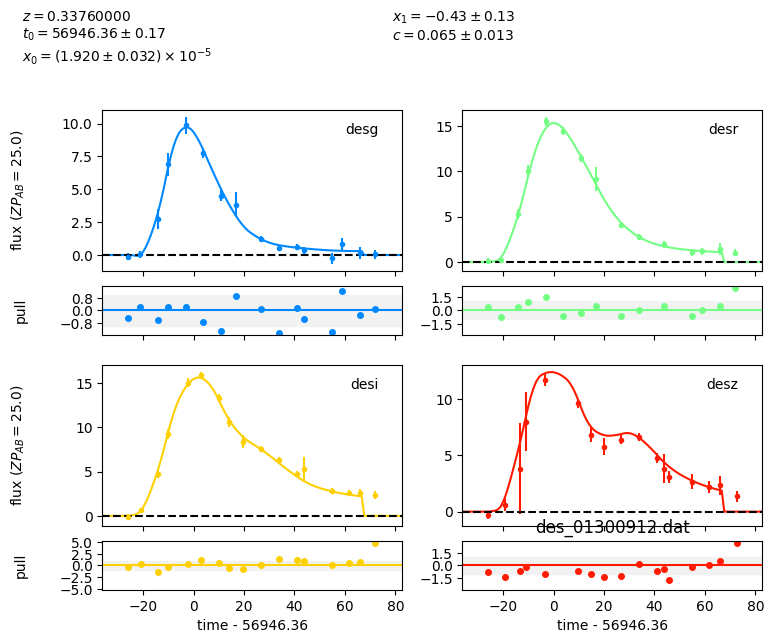

Processing: des_01301933.dat
Fitness within 2σ: 80.33%


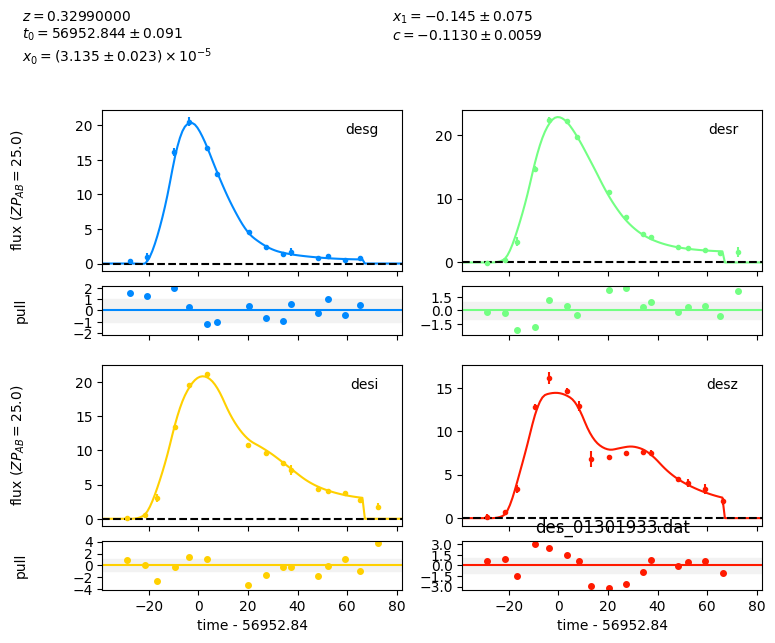

Processing: des_01302141.dat
Fitness within 2σ: 95.60%


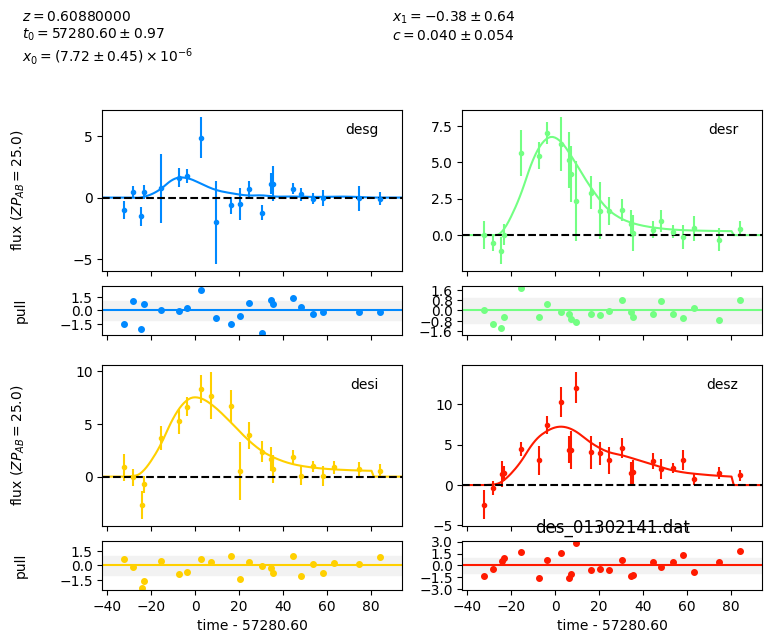

Processing: des_01302058.dat
Fitness within 2σ: 85.71%


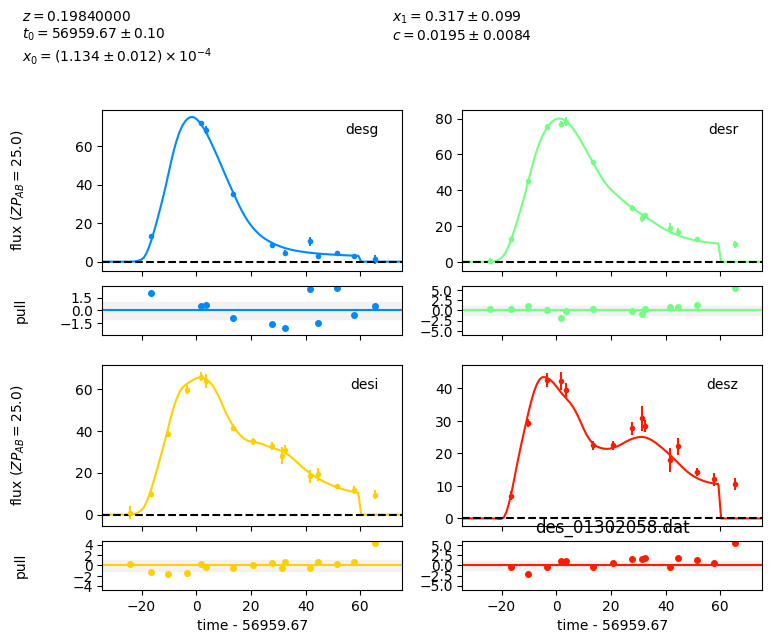

Processing: des_01302187.dat
Fitness within 2σ: 98.00%


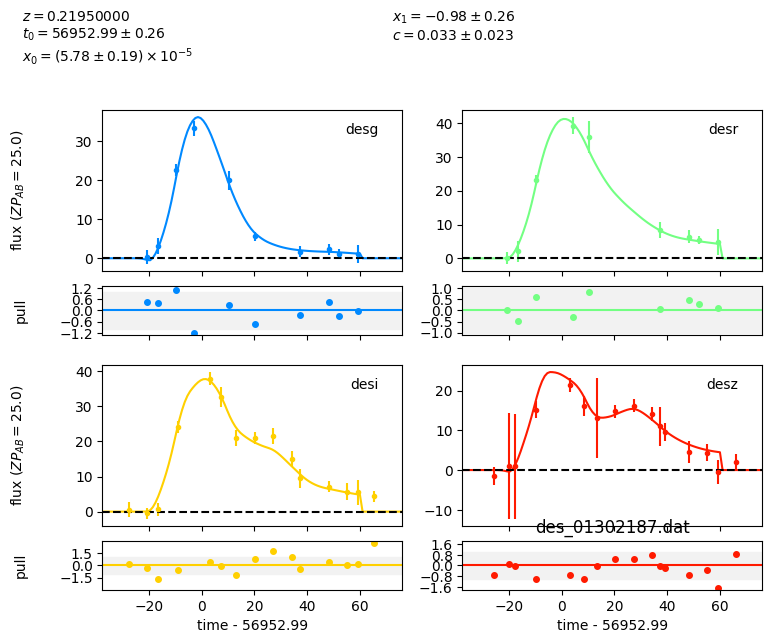

Processing: des_01302523.dat
Fitness within 2σ: 92.86%


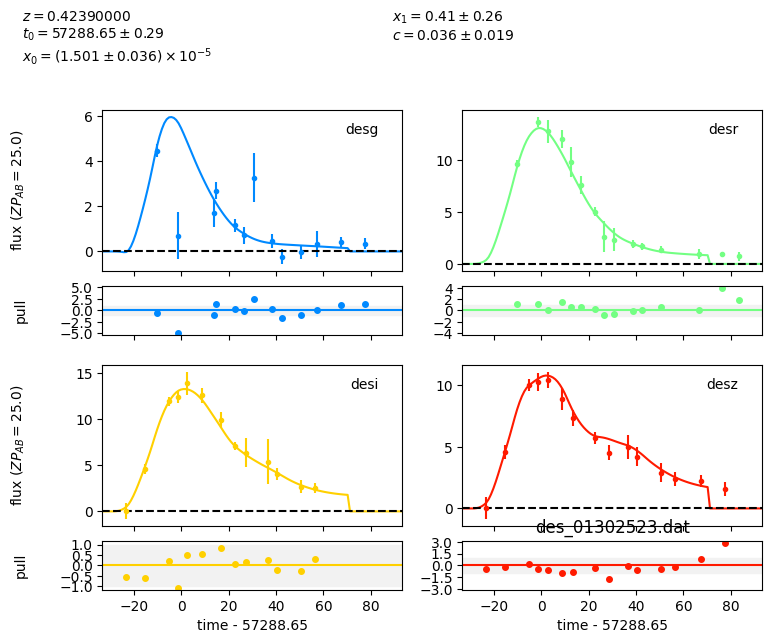

Processing: des_01302648.dat
Fitness within 2σ: 89.47%


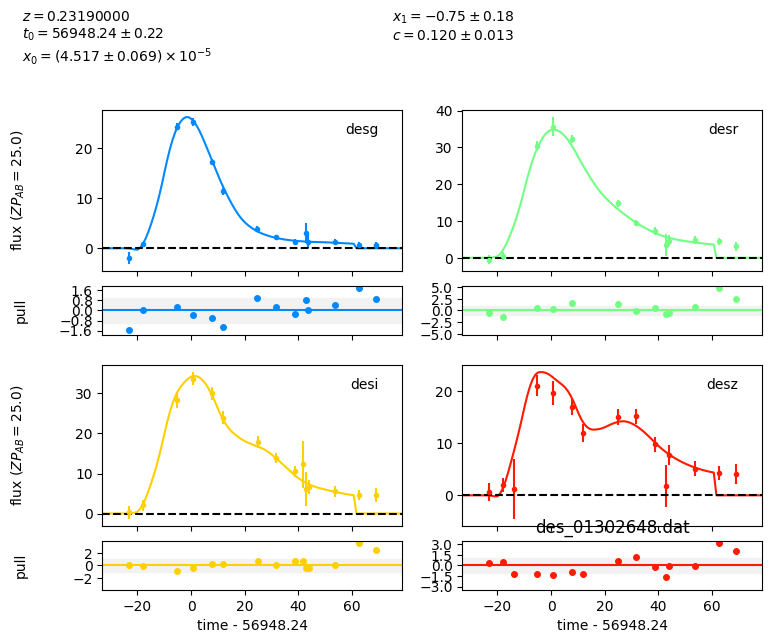

Processing: des_01303279.dat
Fitness within 2σ: 79.07%


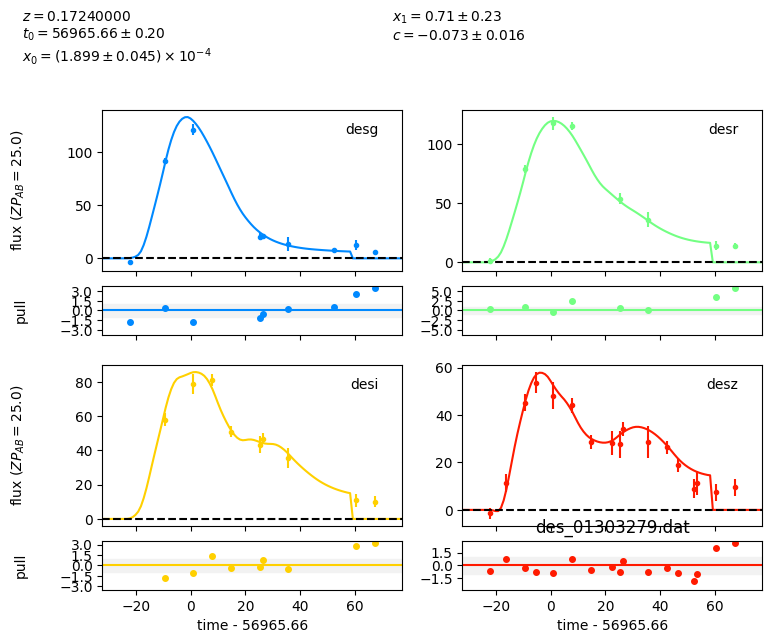

Processing: des_01303004.dat
Fitness within 2σ: 91.67%


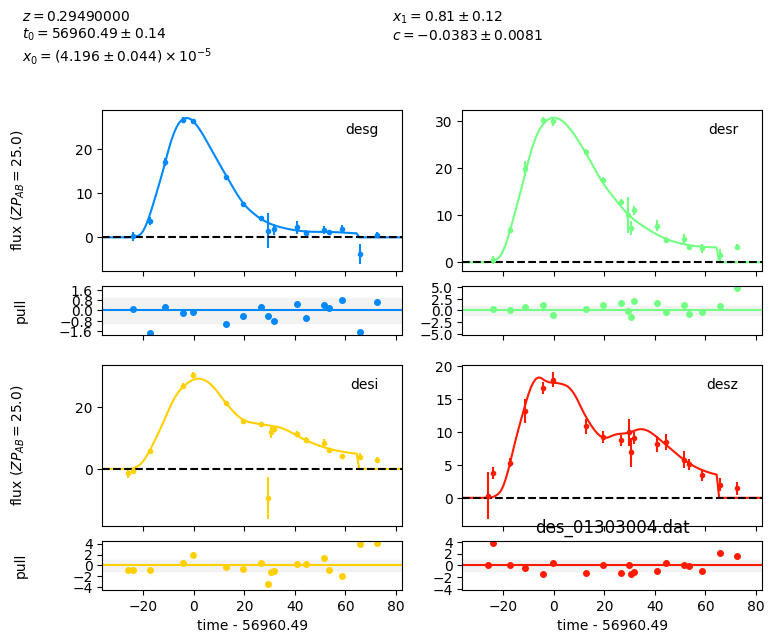

Processing: des_01303496.dat
Fitness within 2σ: 92.68%


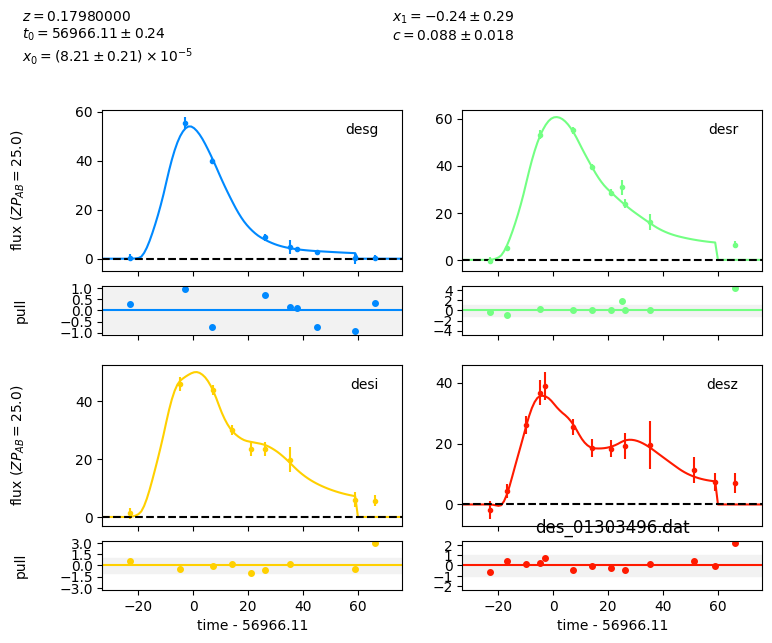

Processing: des_01303883.dat
Fitness within 2σ: 94.52%


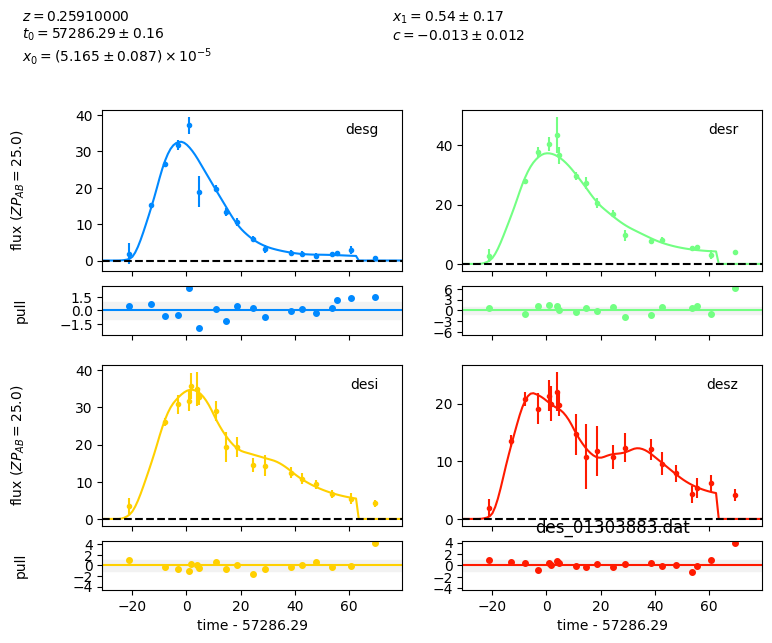

Processing: des_01304127.dat
Fitness within 2σ: 95.18%


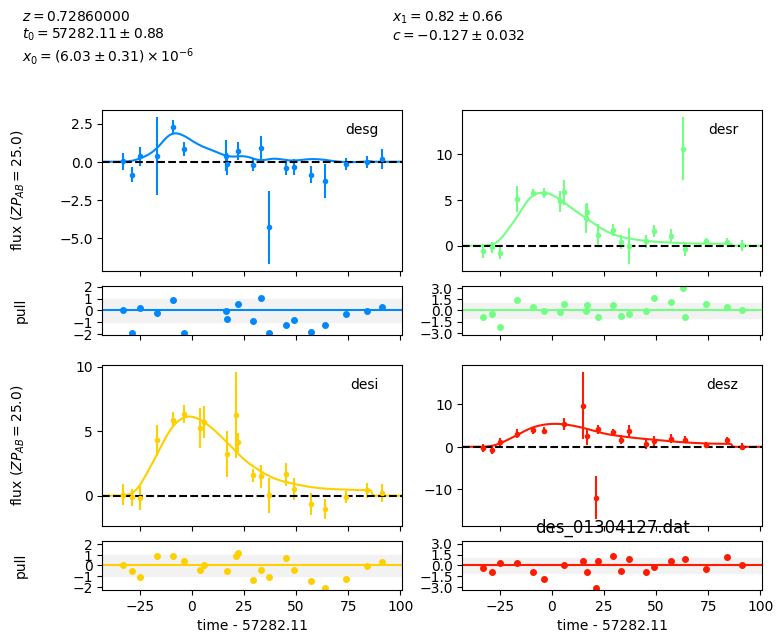

Processing: des_01303952.dat
Fitness within 2σ: 96.43%


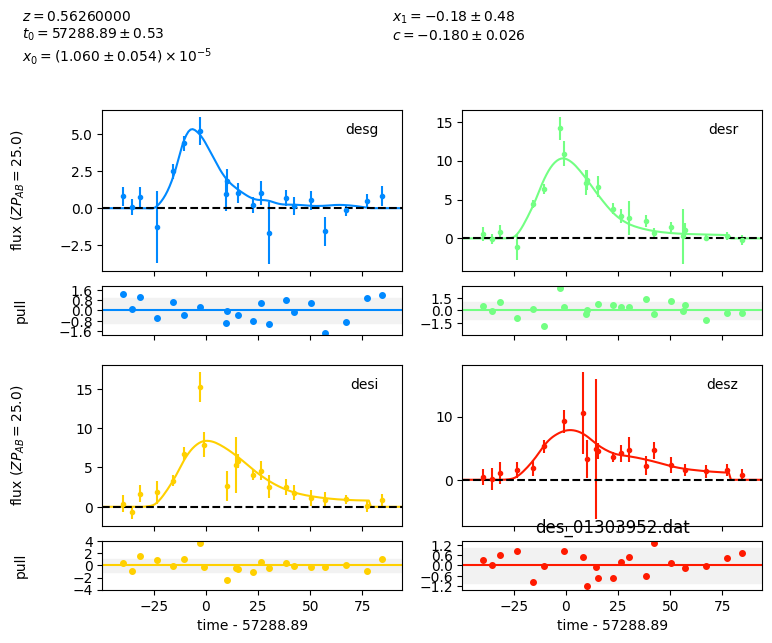

Processing: des_01304442.dat
Fitness within 2σ: 93.75%


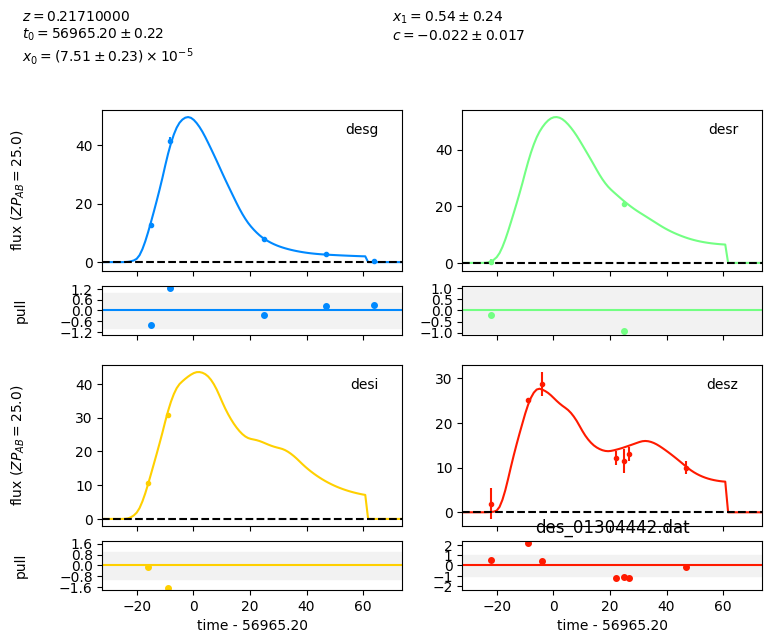

Processing: des_01304678.dat
Fitness within 2σ: 100.00%


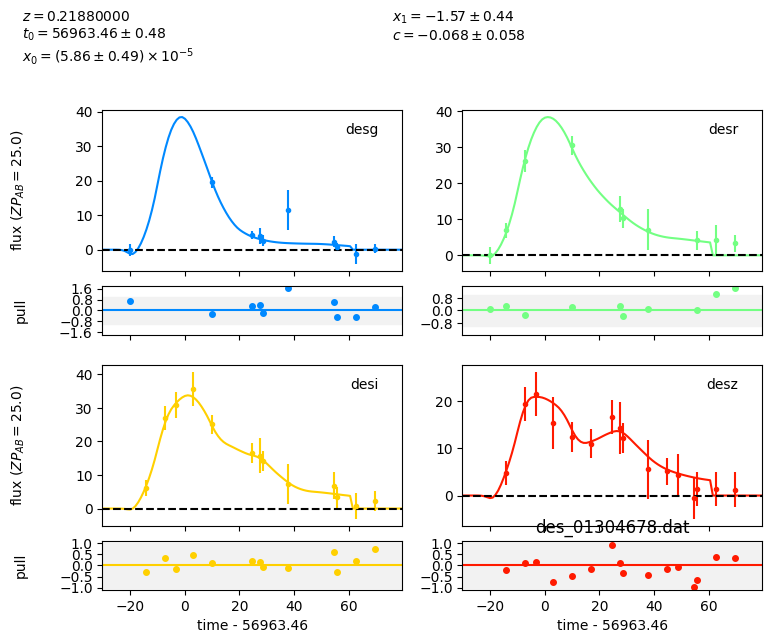

Processing: des_01305626.dat
Fitness within 2σ: 87.27%


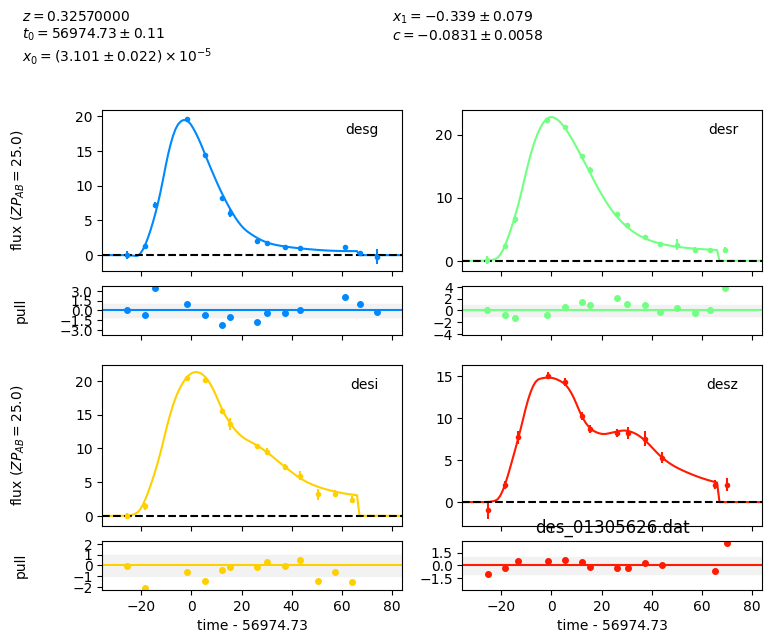

Processing: des_01305504.dat
Fitness within 2σ: 95.00%


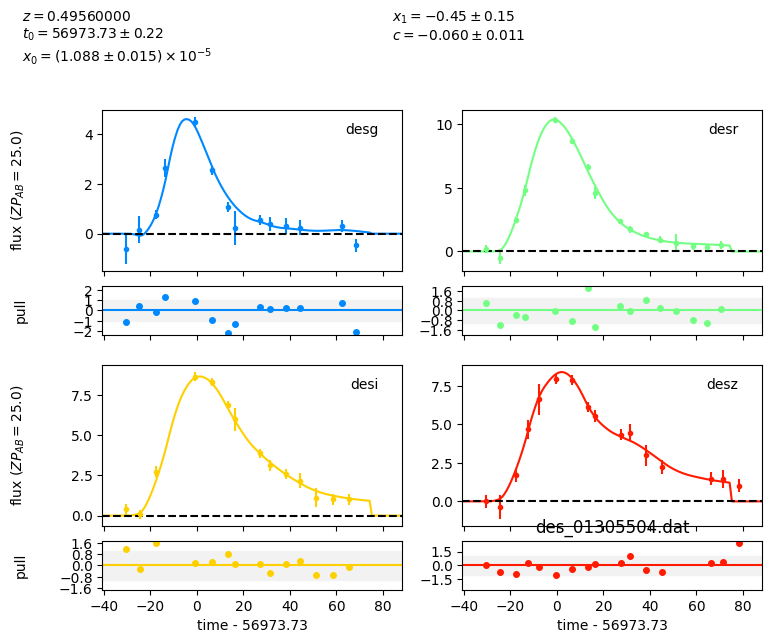

Processing: des_01306073 (1).dat
Fitness within 2σ: 98.21%


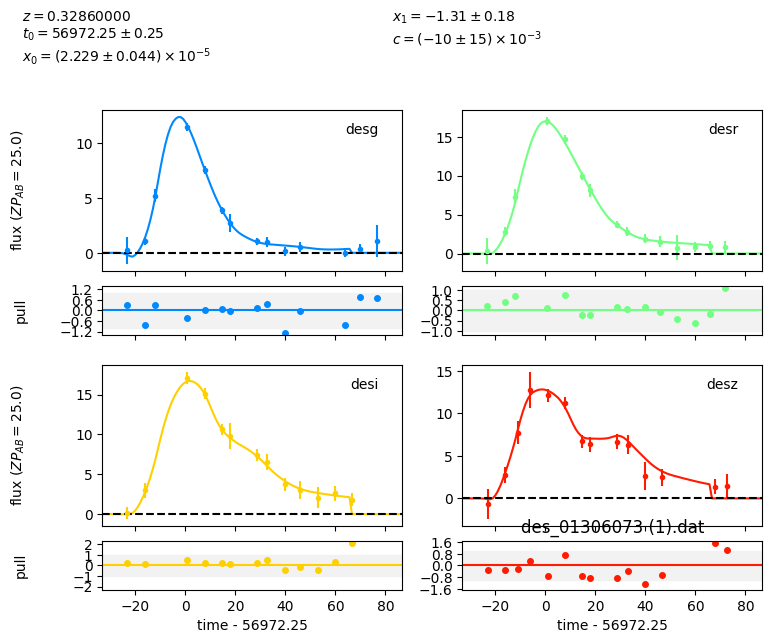

Processing: des_01306029.dat
Fitness within 2σ: 94.59%


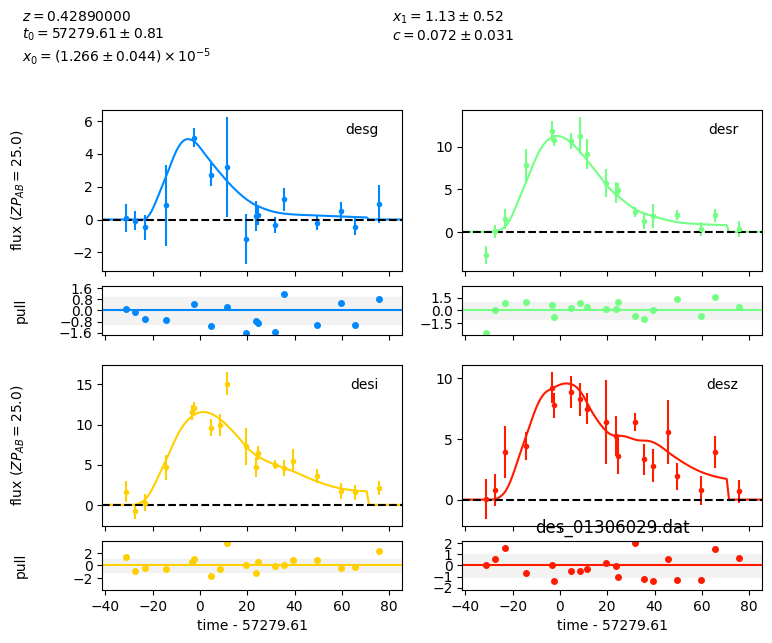

Processing: des_01306141.dat
Fitness within 2σ: 93.85%


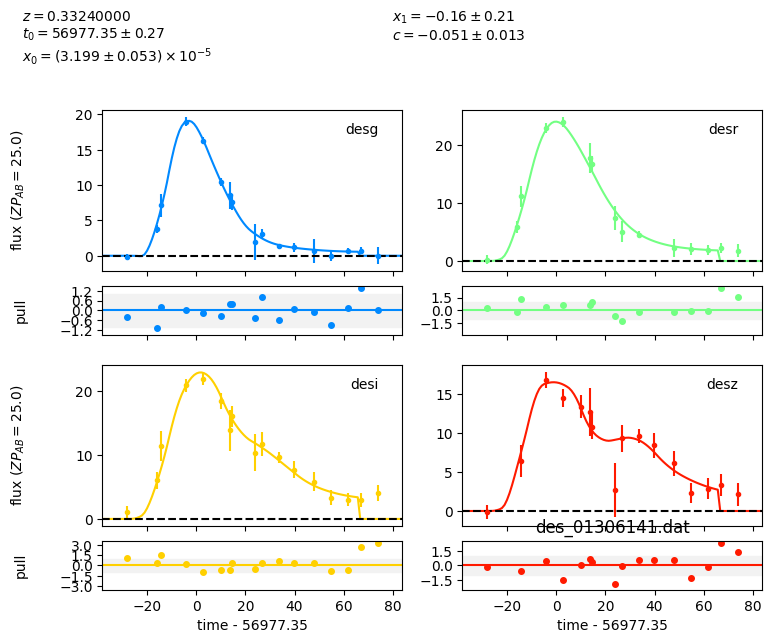

Processing: des_01306360.dat
Fitness within 2σ: 97.37%


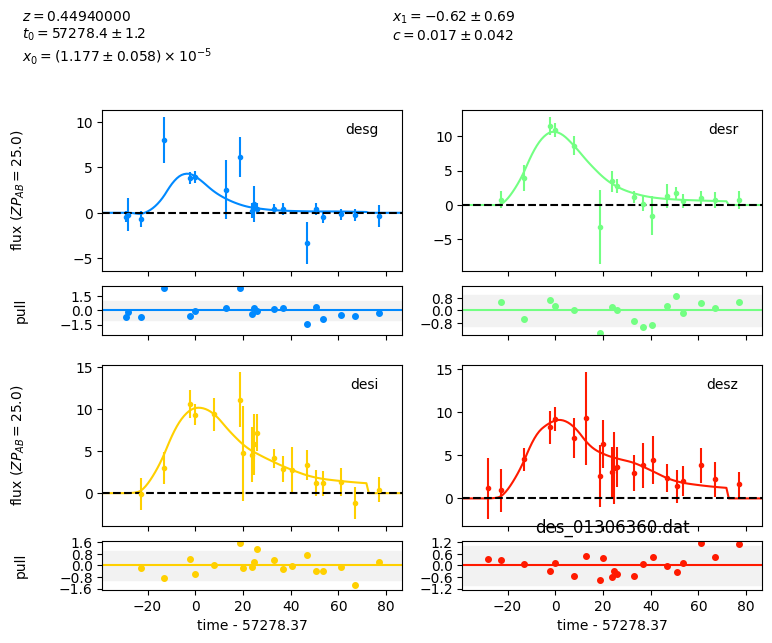

Processing: des_01306537.dat
Fitness within 2σ: 94.74%


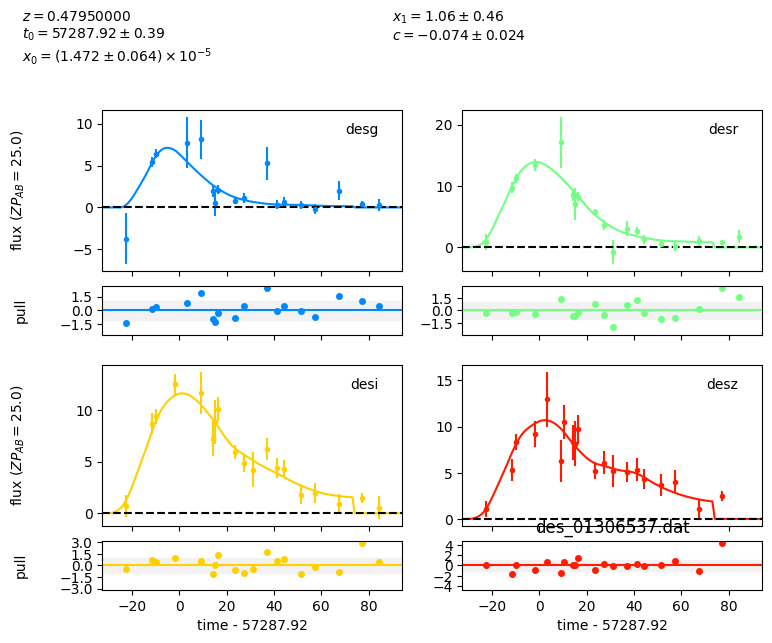

Processing: des_01306390.dat
Fitness within 2σ: 100.00%


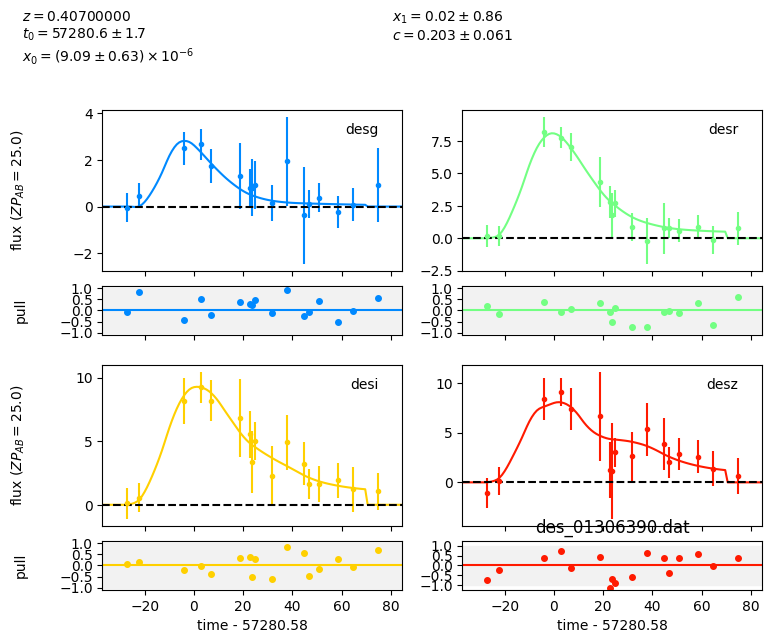

Processing: des_01306785.dat
Fitness within 2σ: 97.62%


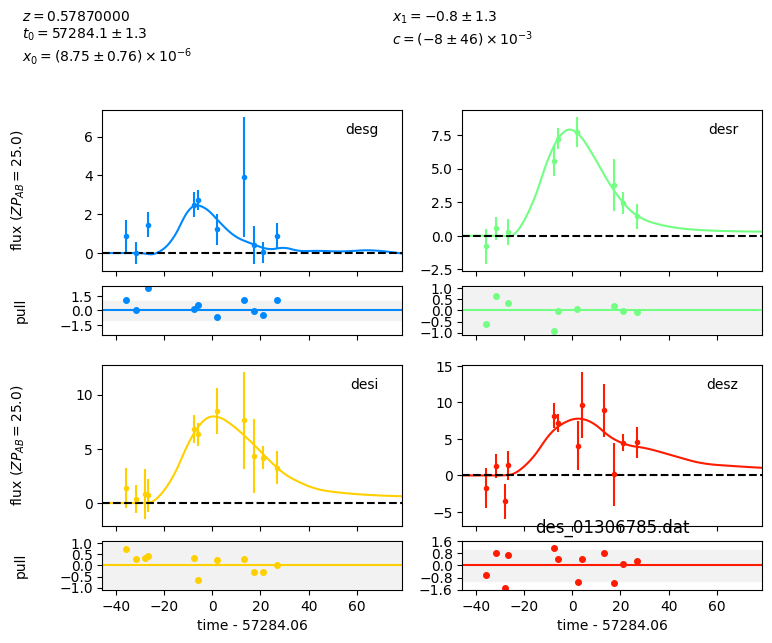

Processing: des_01306626.dat
Fitness within 2σ: 97.26%


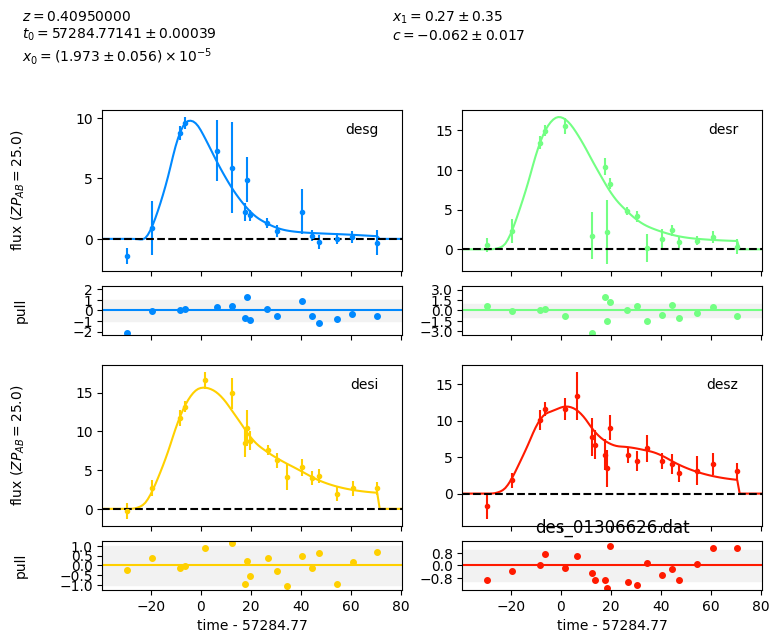

Processing: des_01306980.dat
Fitness within 2σ: 96.51%


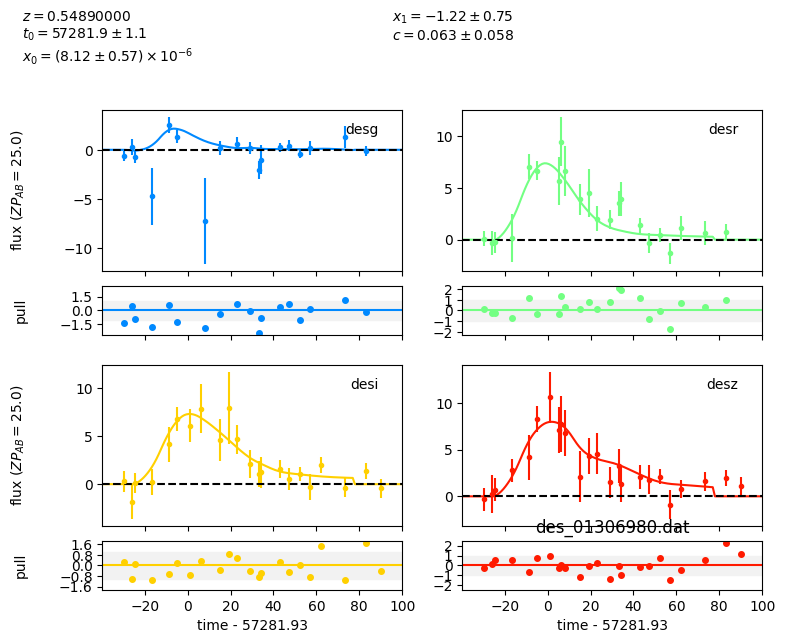

Processing: des_01306991.dat
Fitness within 2σ: 97.22%


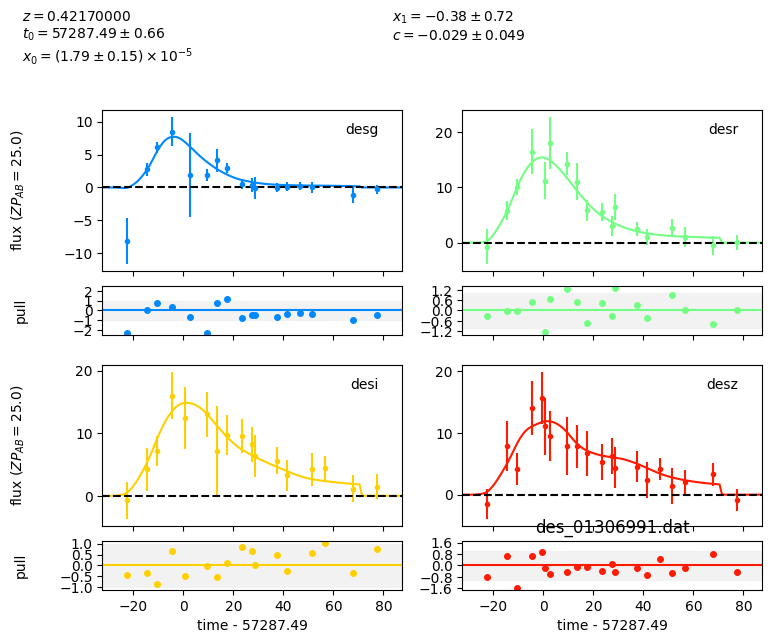

Processing: des_01307277.dat
Fitness within 2σ: 100.00%


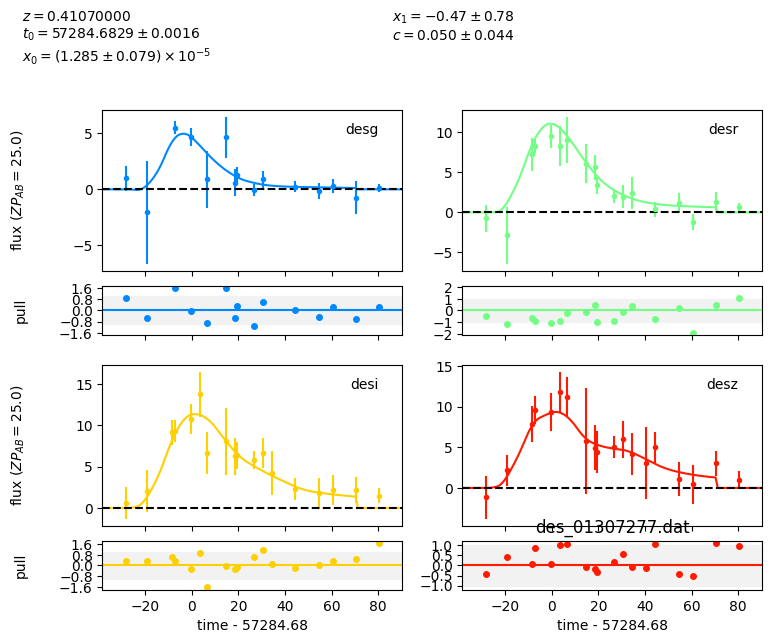

Processing: des_01307830.dat
Fitness within 2σ: 93.22%


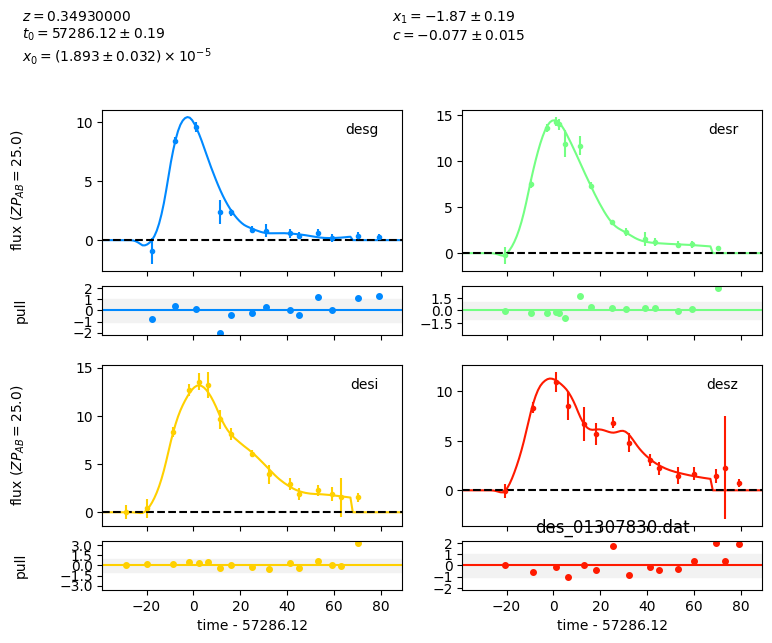

Processing: des_01308314.dat
Fitness within 2σ: 93.24%


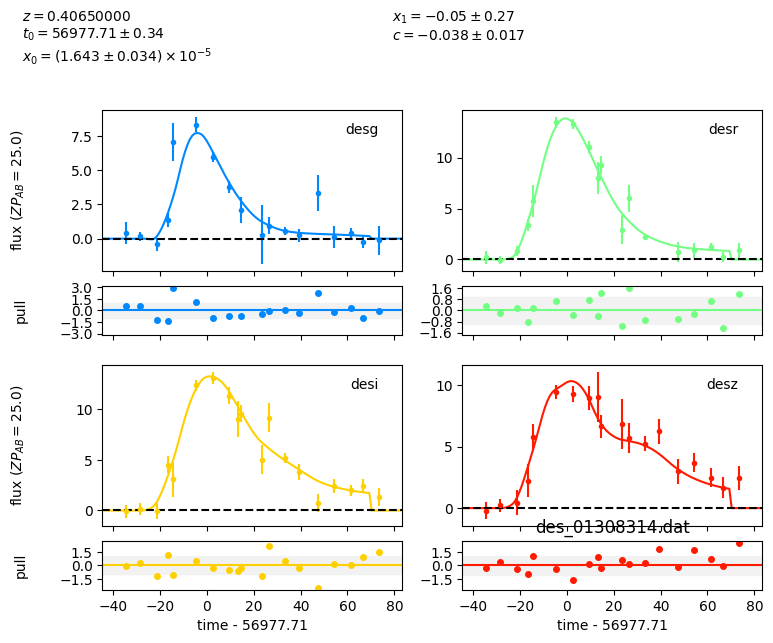

Processing: des_01308326.dat
Fitness within 2σ: 96.83%


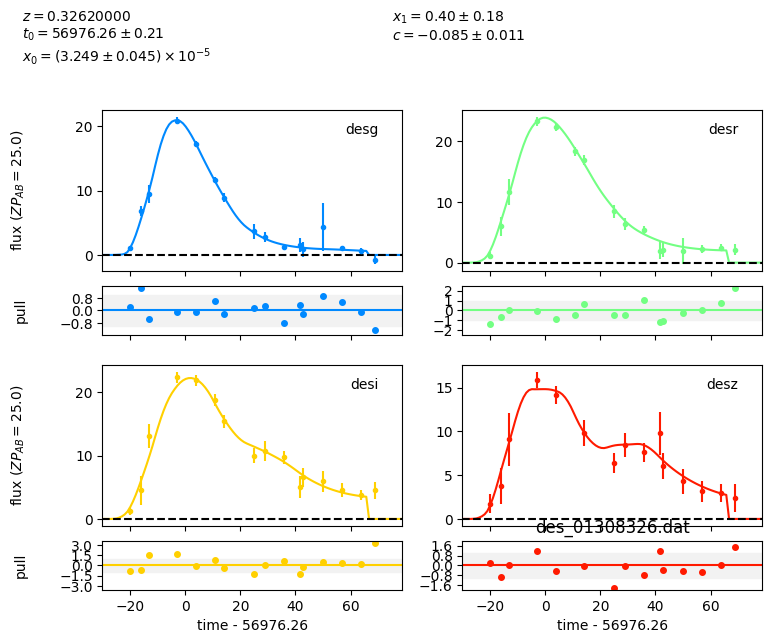

Processing: des_01308568.dat
Fitness within 2σ: 94.44%


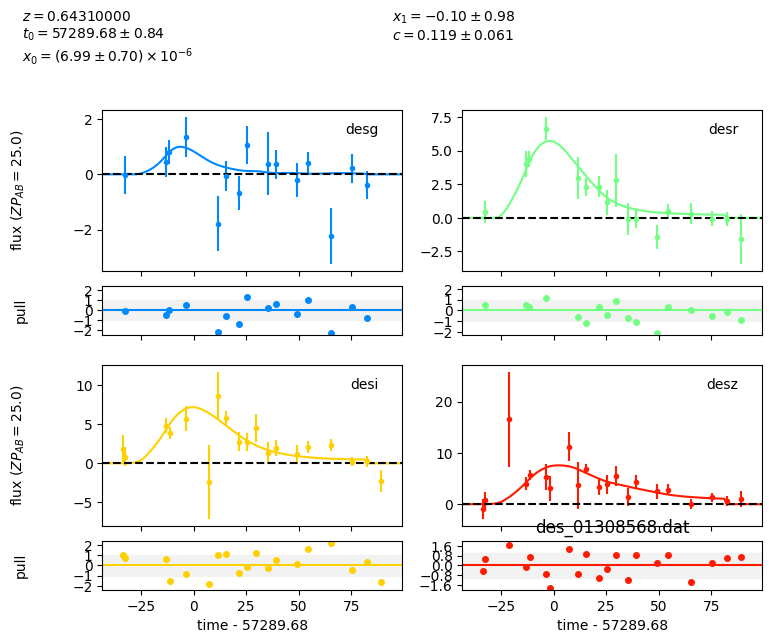

Processing: des_01308884.dat
Fitness within 2σ: 25.00%


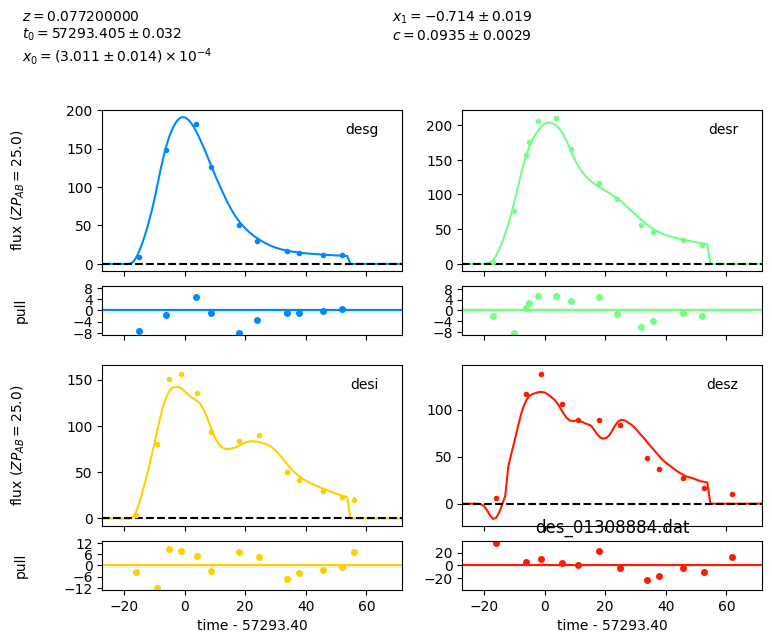

Processing: des_01308957.dat
Fitness within 2σ: 94.44%


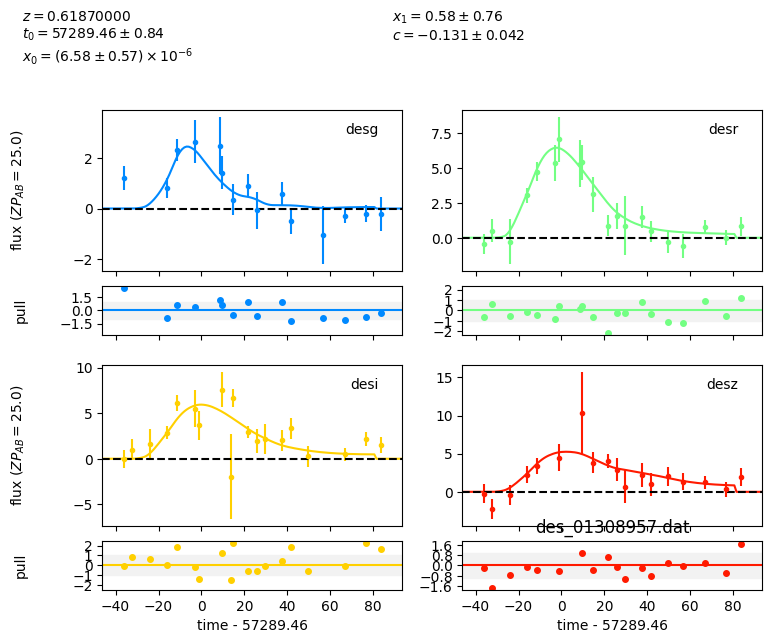

Processing: des_01309288.dat
Fitness within 2σ: 100.00%


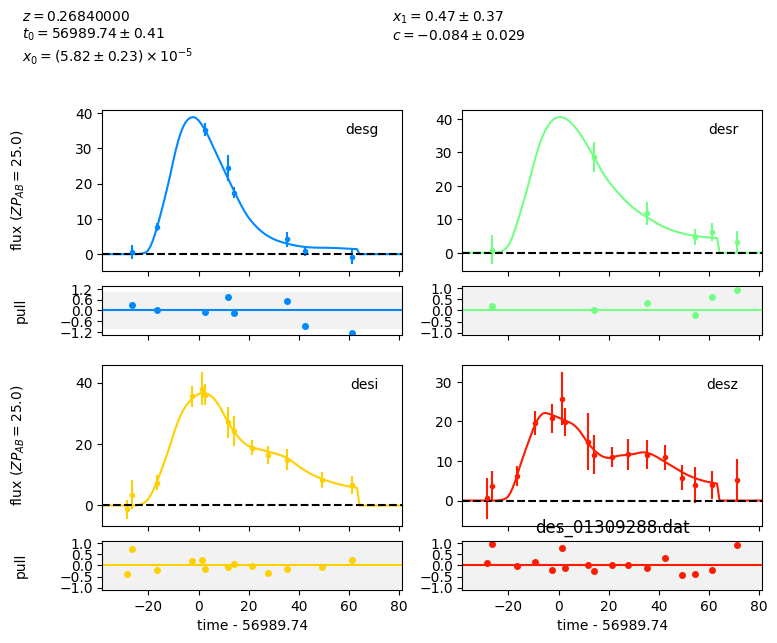

Processing: des_01309492.dat
Fitness within 2σ: 88.52%


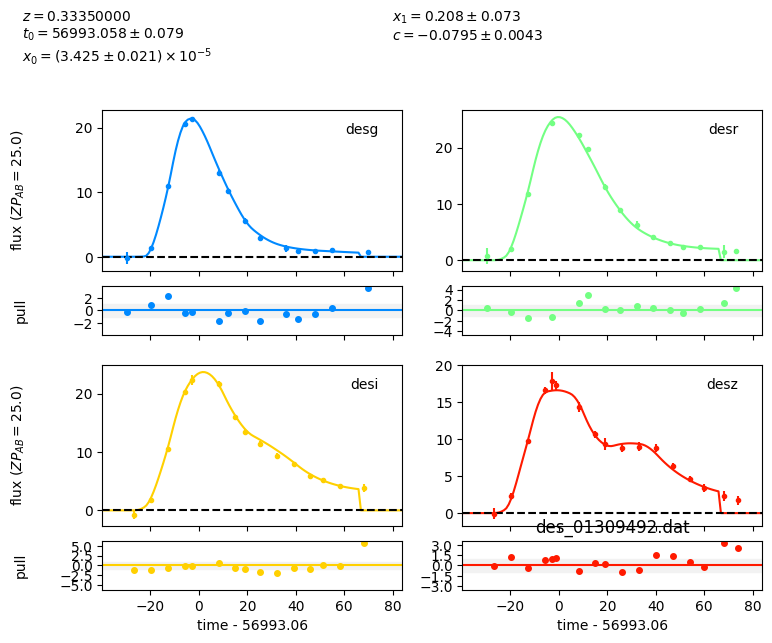

Processing: des_01309749.dat
Fitness within 2σ: 100.00%


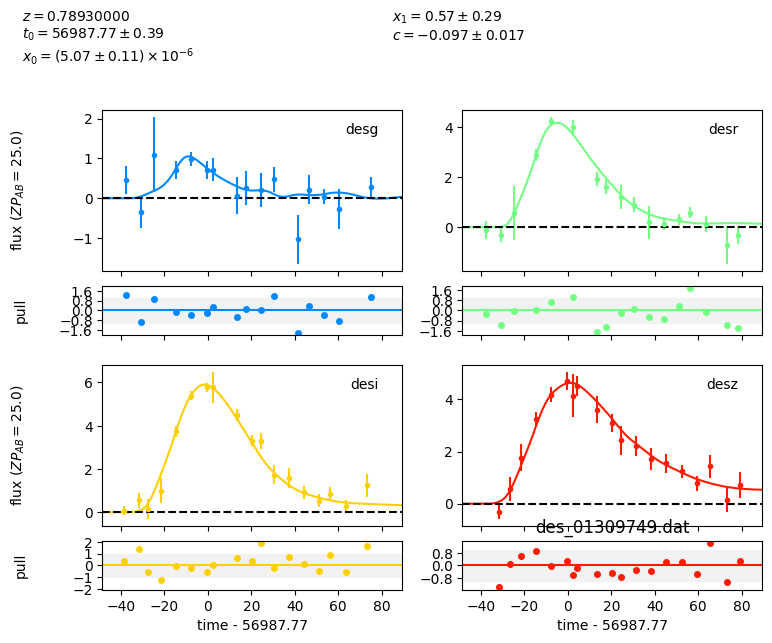

Processing: des_01310338.dat
Fitness within 2σ: 98.41%


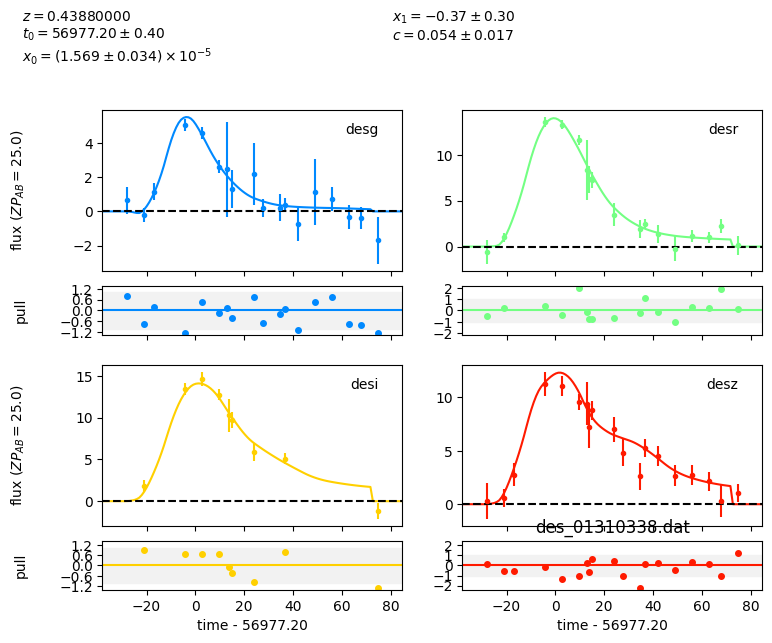

Processing: des_01310395.dat
Fitness within 2σ: 92.86%


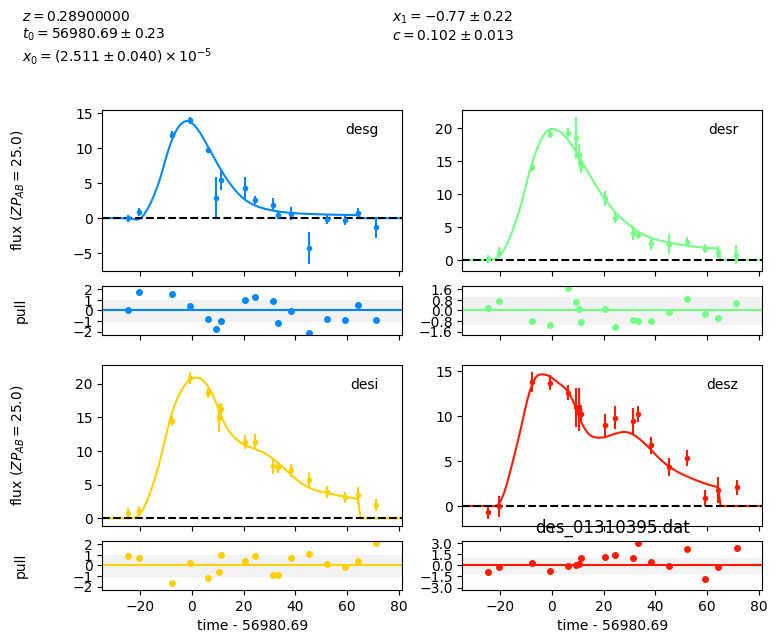

Processing: des_01312274.dat
Fitness within 2σ: 98.39%


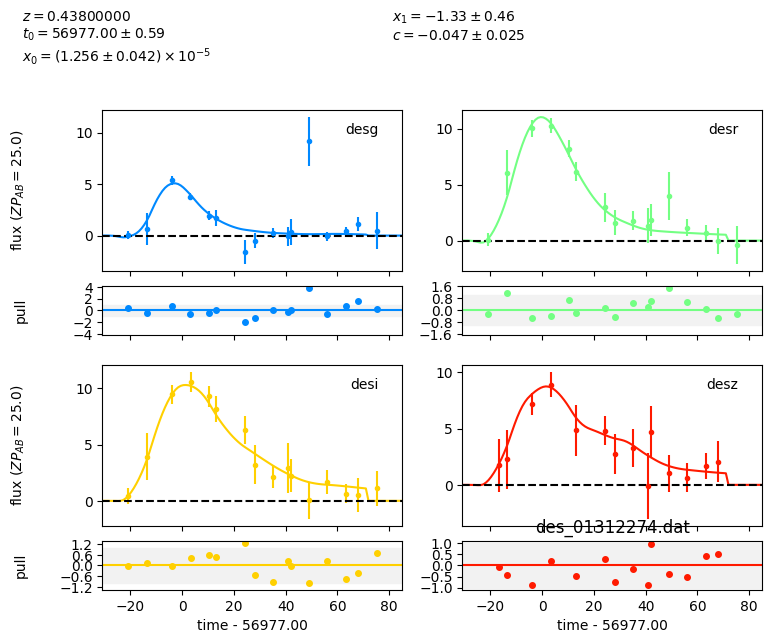

Processing: des_01313594.dat
Fitness within 2σ: 98.15%


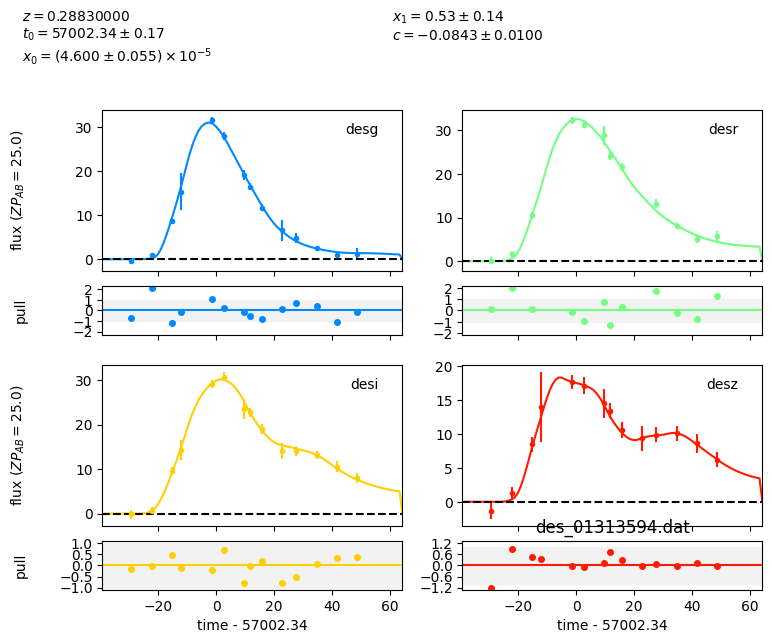

Processing: des_01314897.dat
Fitness within 2σ: 90.74%


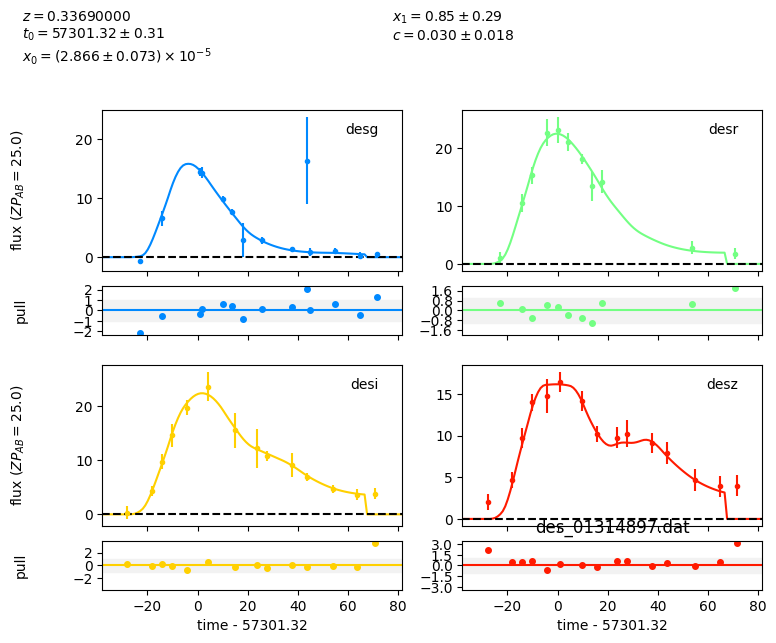

Processing: des_01315192.dat
Fitness within 2σ: 97.37%


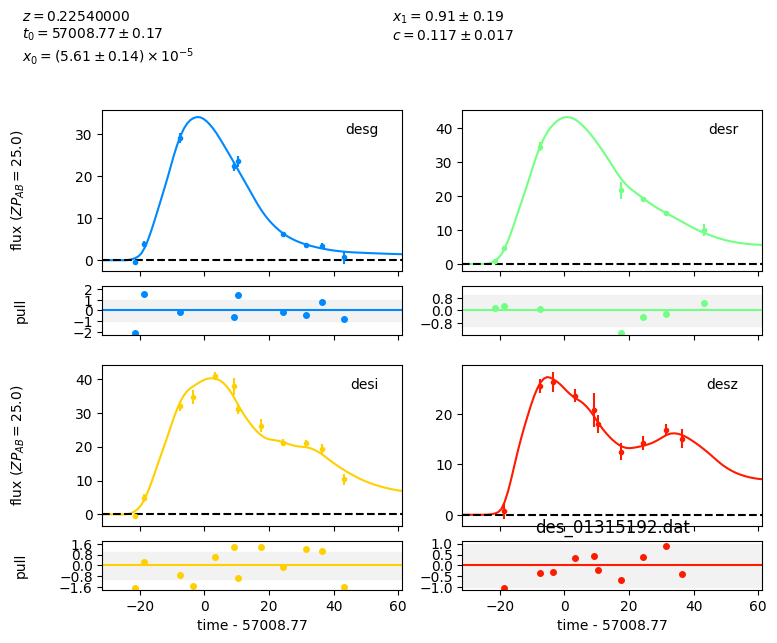

Processing: des_01315259.dat
Fitness within 2σ: 95.45%


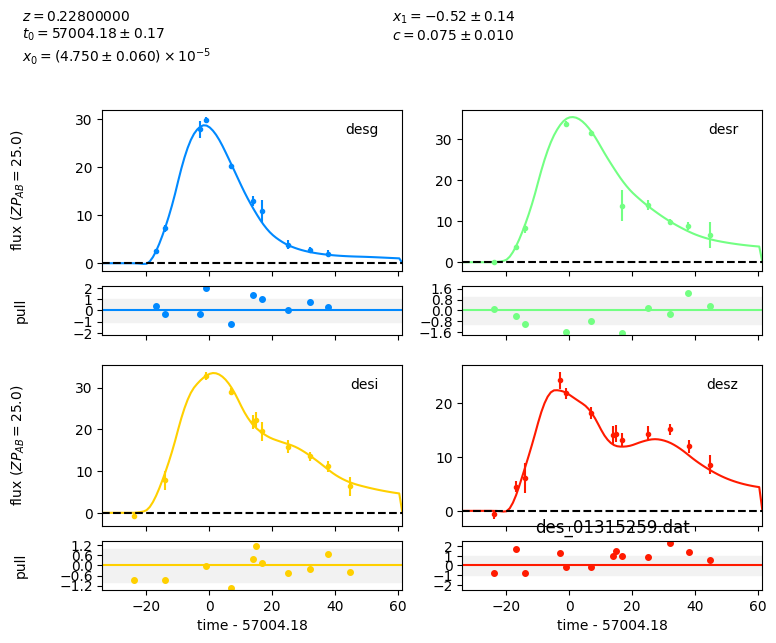

Processing: des_01315296.dat
Fitness within 2σ: 98.11%


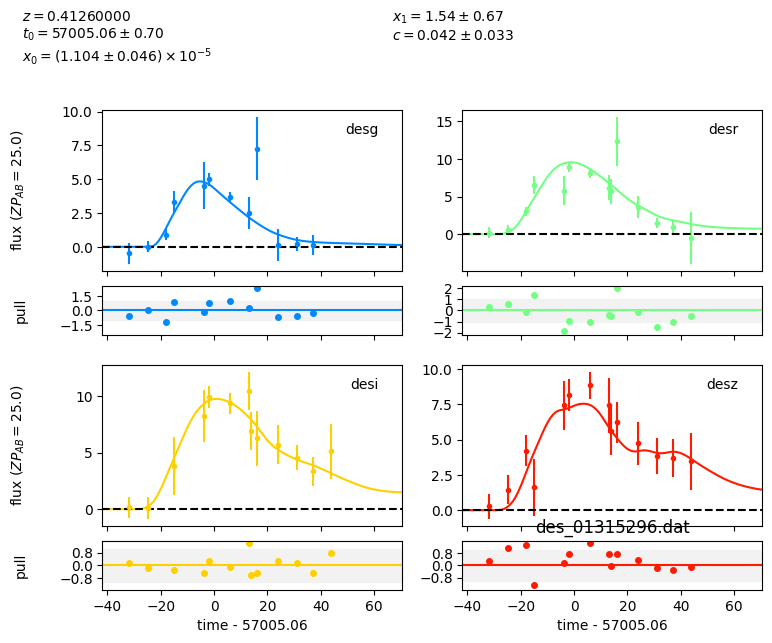

Processing: des_01316431.dat
Fitness within 2σ: 79.49%


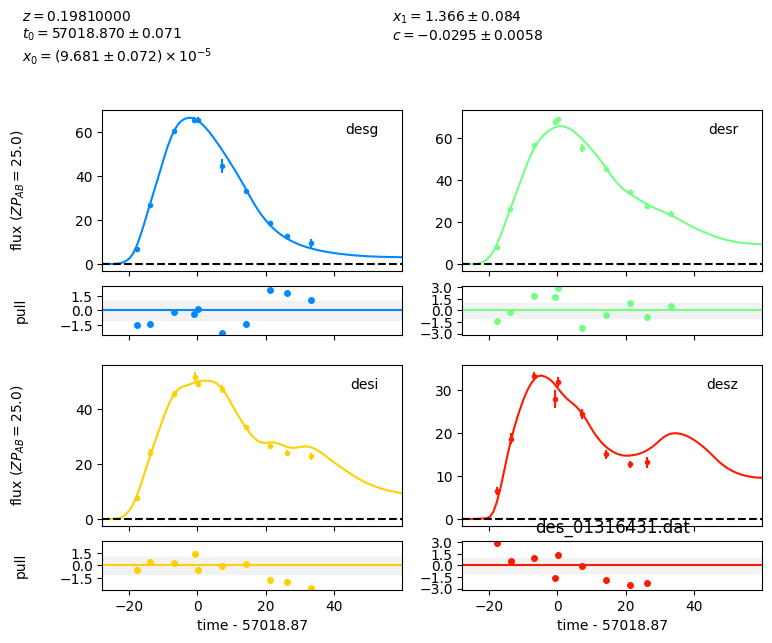

Processing: des_01316465.dat
Fitness within 2σ: 82.93%


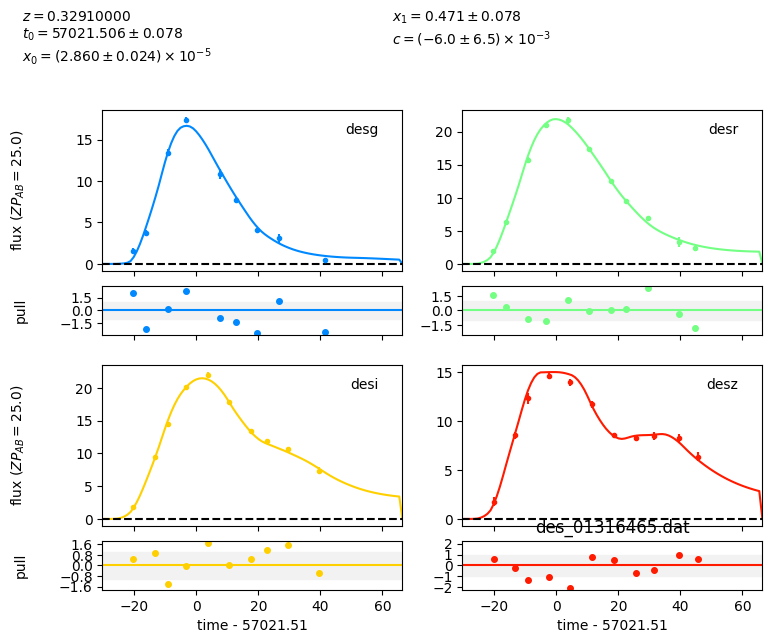

Processing: des_01316437.dat
Fitness within 2σ: 91.84%


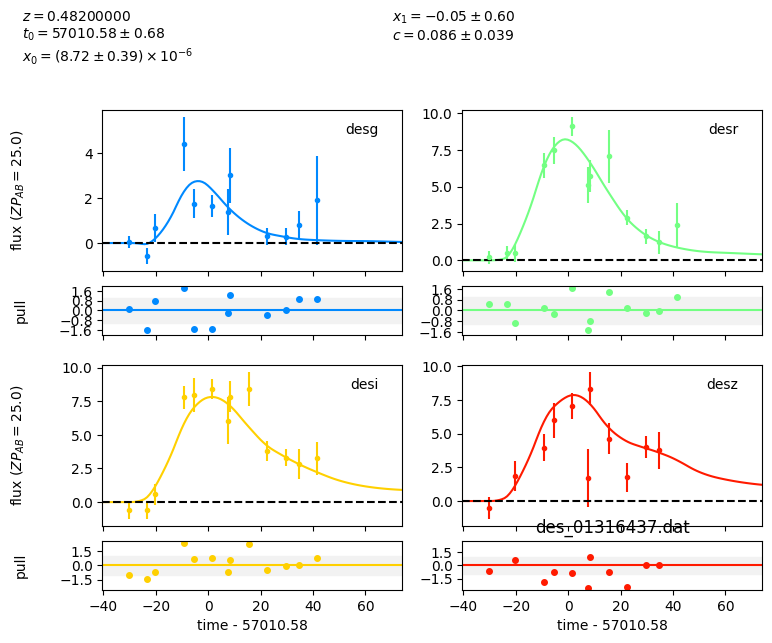

Processing: des_01317164.dat
Fitness within 2σ: 71.43%


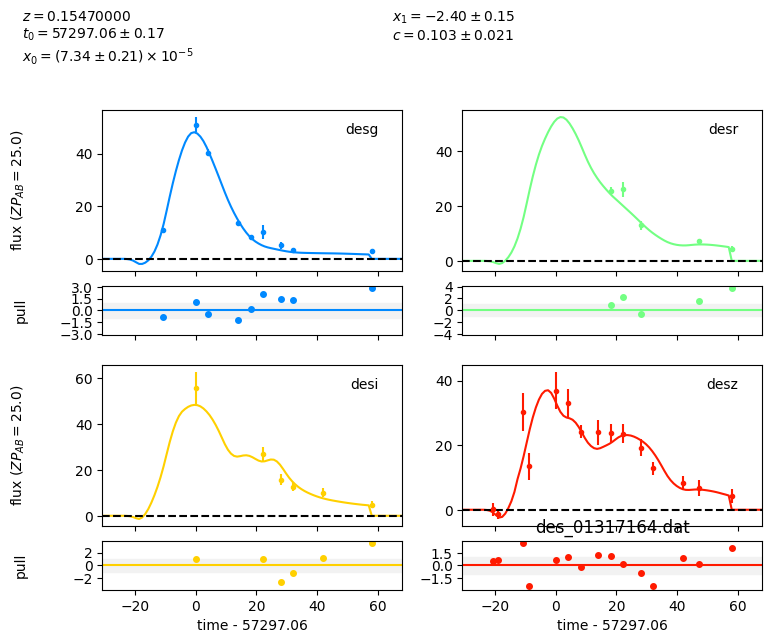

Processing: des_01317286.dat
Fitness within 2σ: 94.44%


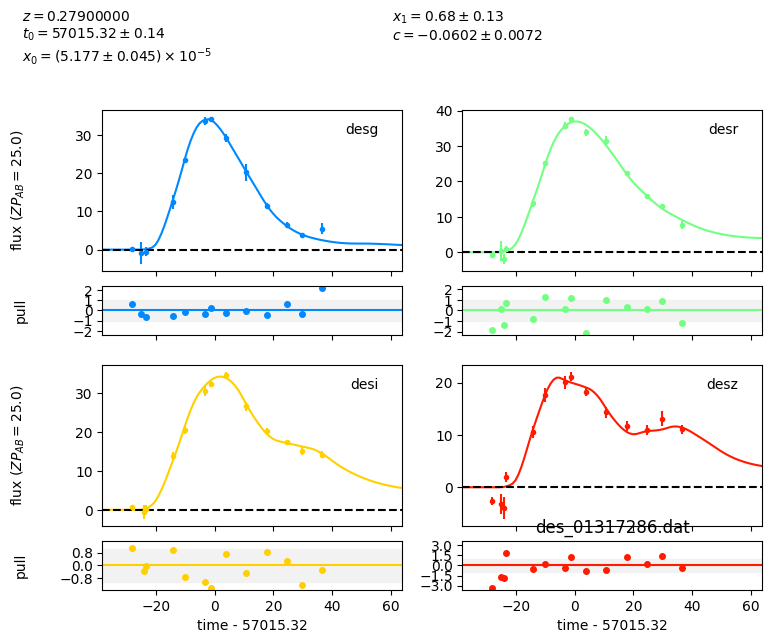

Processing: des_01317277.dat
Fitness within 2σ: 96.15%


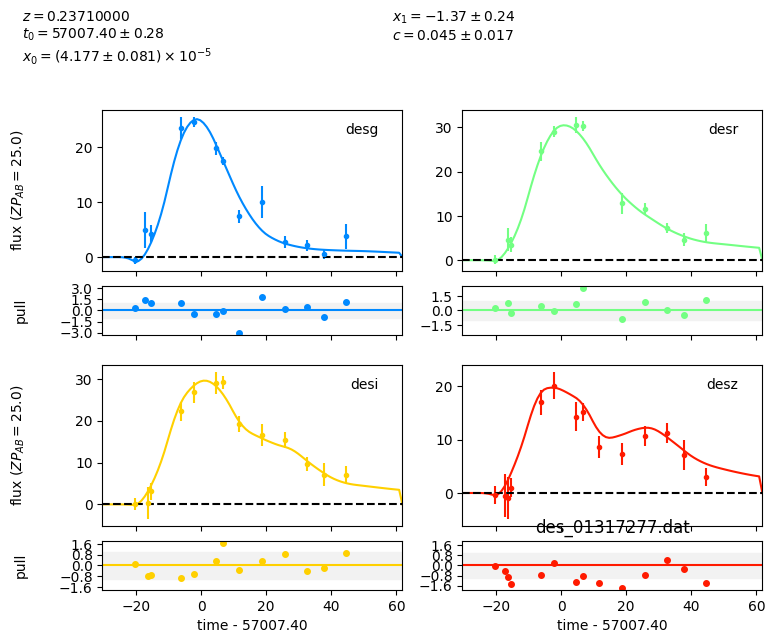

Processing: des_01317454.dat
Fitness within 2σ: 97.44%


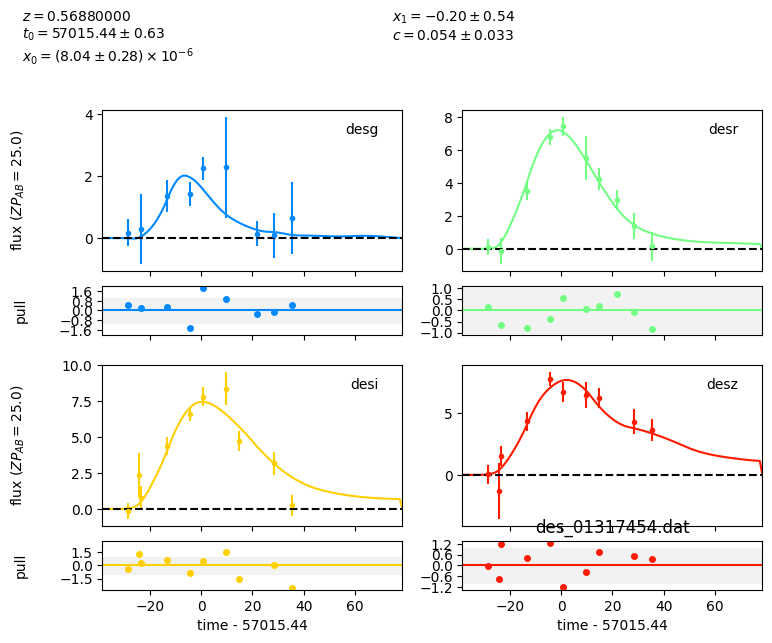

Processing: des_01317666.dat
Fitness within 2σ: 82.98%


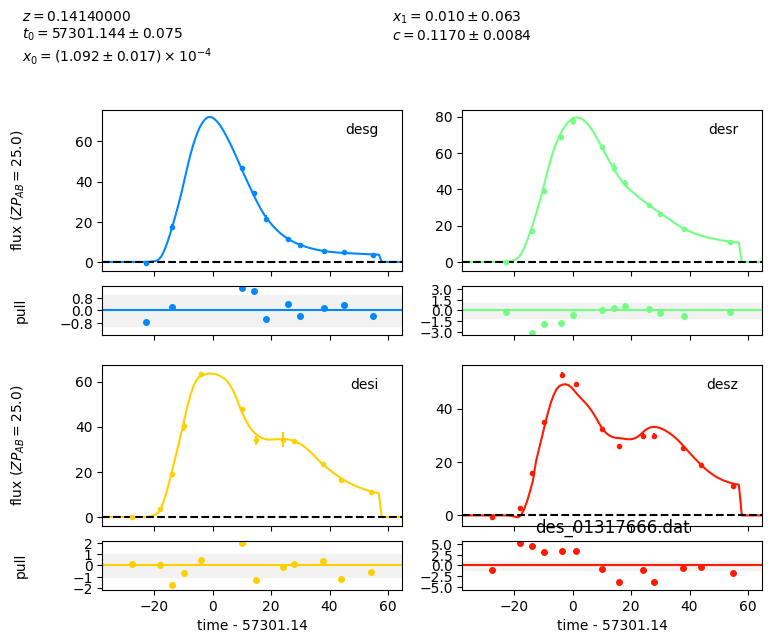

Processing: des_01319366.dat
Fitness within 2σ: 93.85%


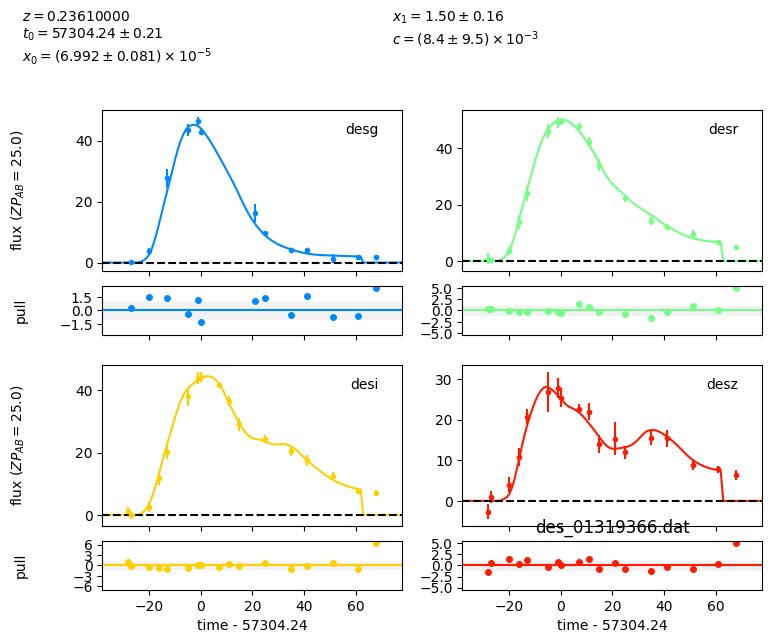

Processing: des_01319821.dat
Fitness within 2σ: 100.00%


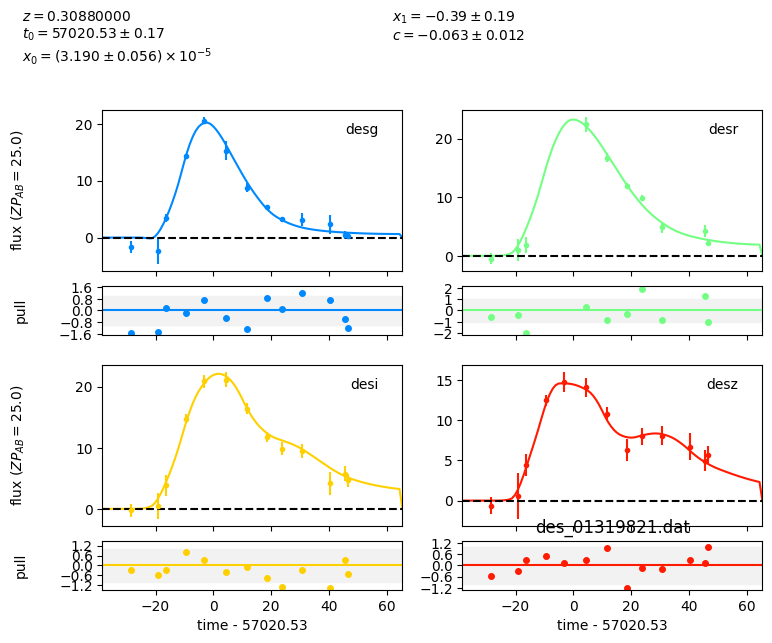

Processing: des_01320166.dat
Fitness within 2σ: 94.87%


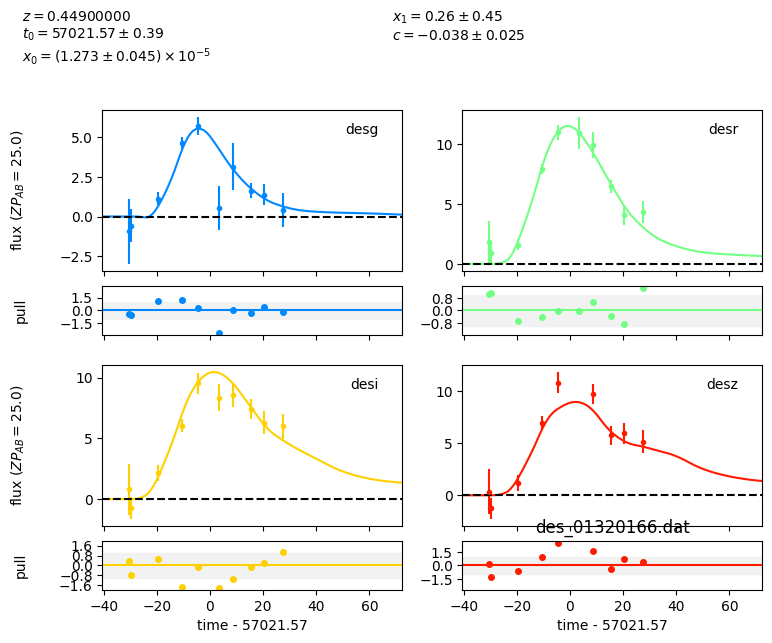

Processing: des_01322229.dat
Fitness within 2σ: 100.00%


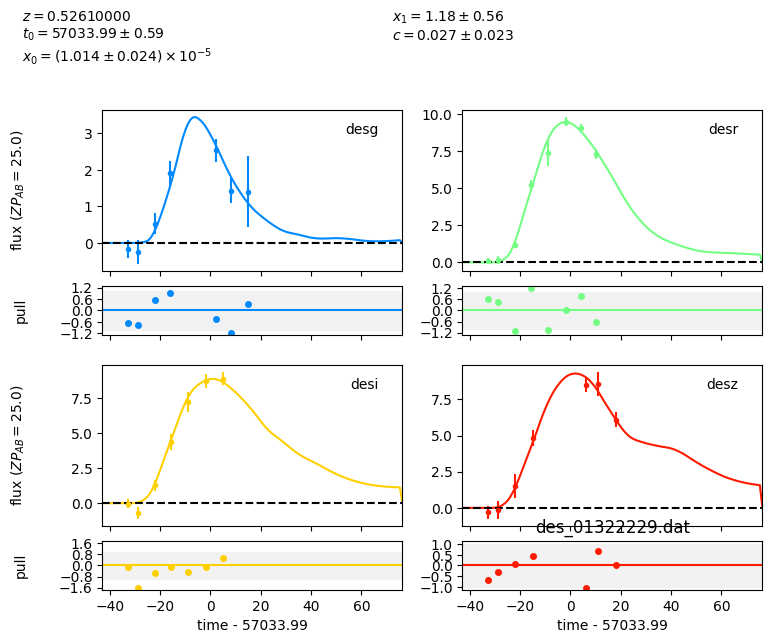

Processing: des_01322979.dat
Fitness within 2σ: 94.29%


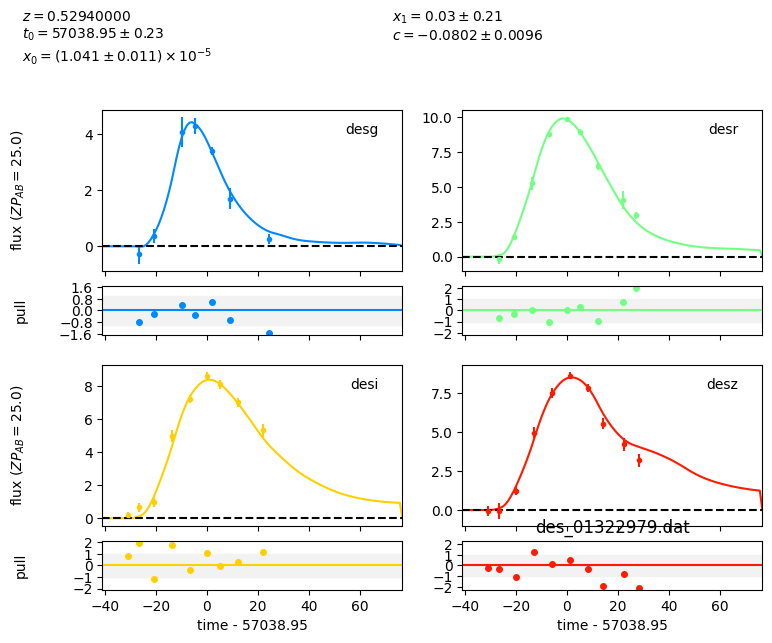

Processing: des_01324542.dat
Fitness within 2σ: 92.11%


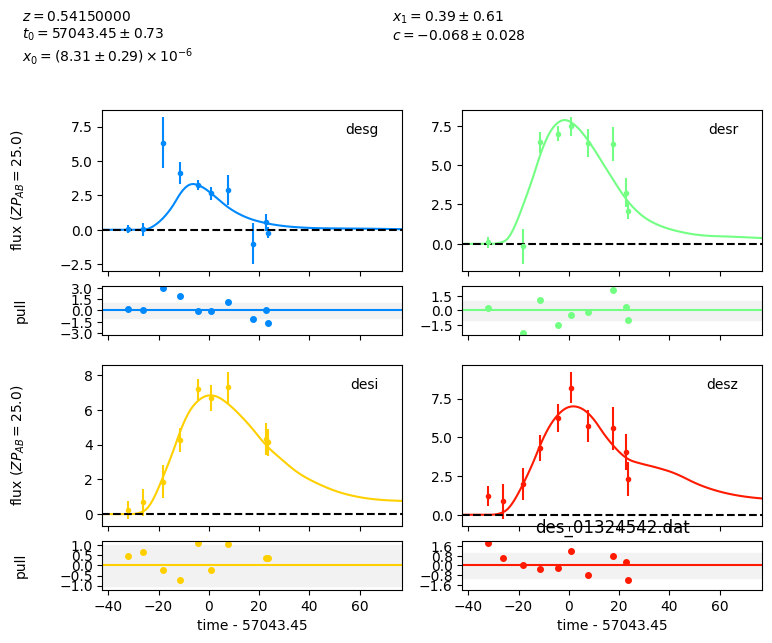

Processing: des_01325358.dat
Fitness within 2σ: 93.75%


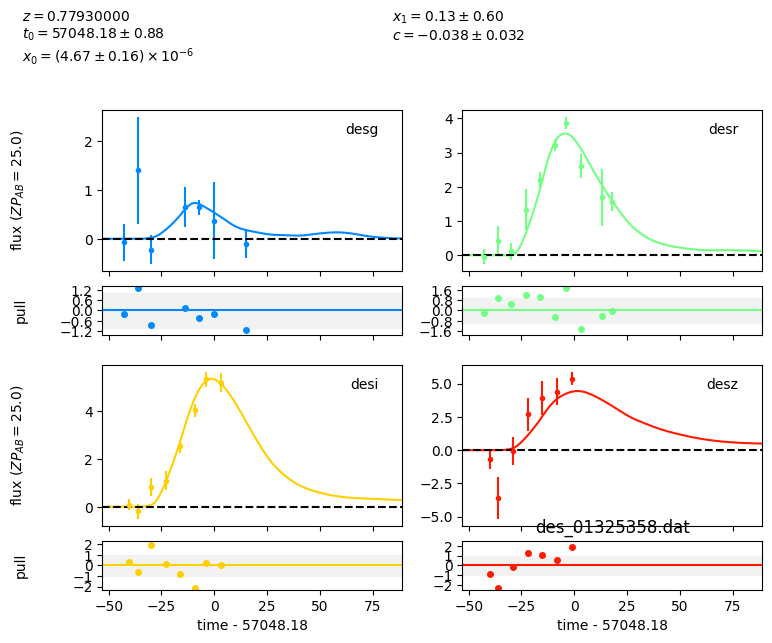

Processing: des_01327978.dat
Fitness within 2σ: 100.00%


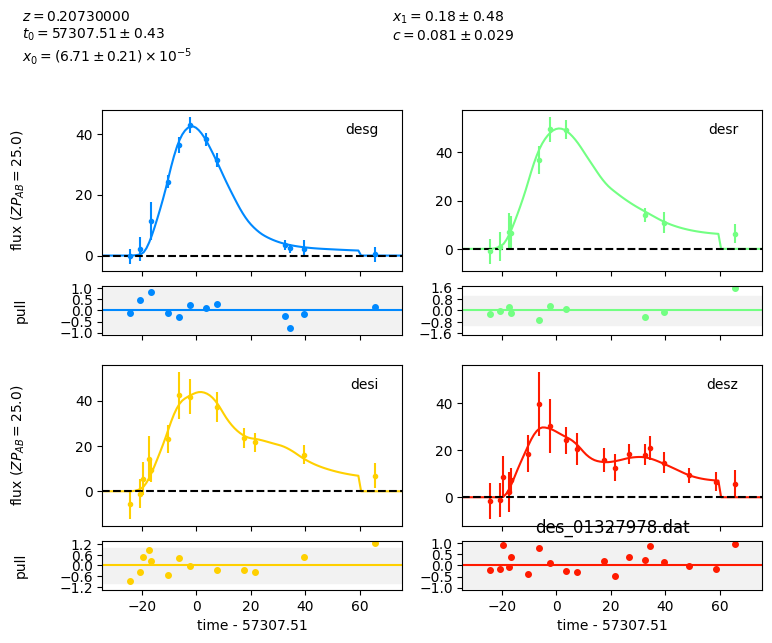

Processing: des_01328105.dat
Fitness within 2σ: 94.05%


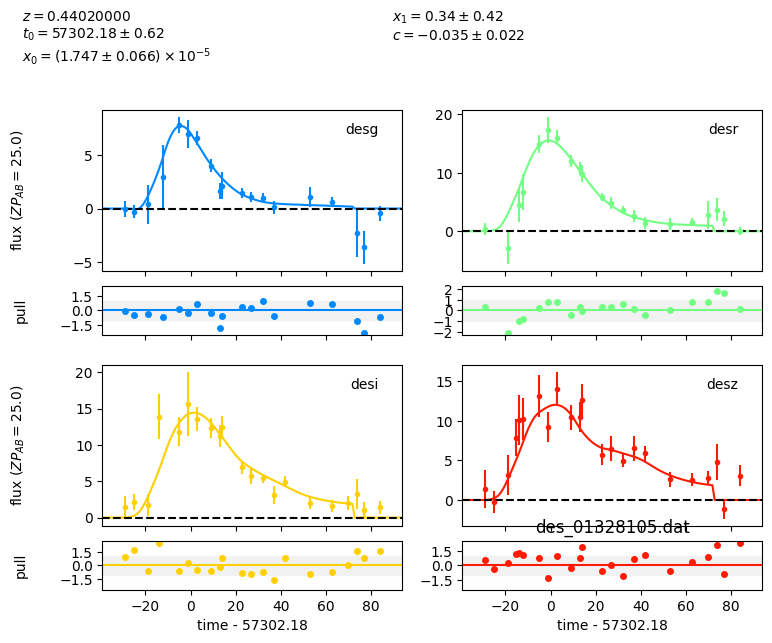

Processing: des_01328066.dat
Fitness within 2σ: 96.30%


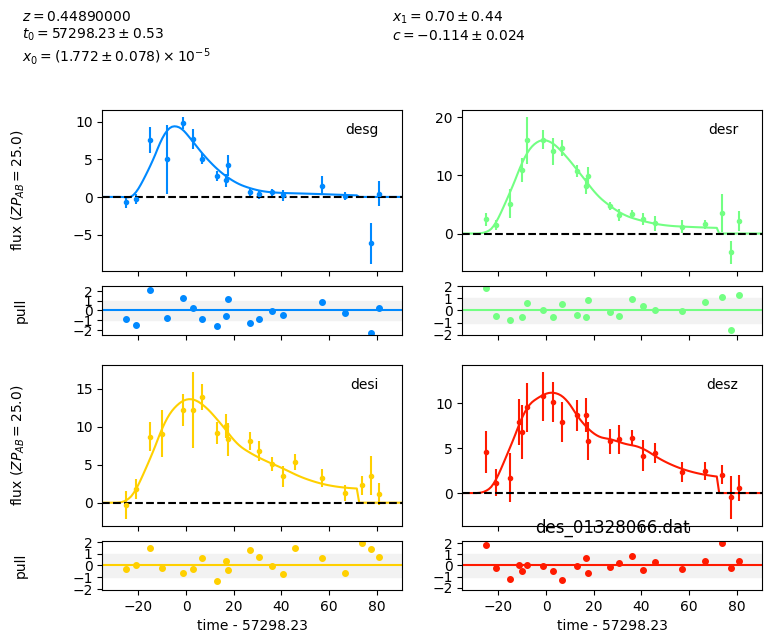

Processing: des_01329166.dat
Fitness within 2σ: 95.77%


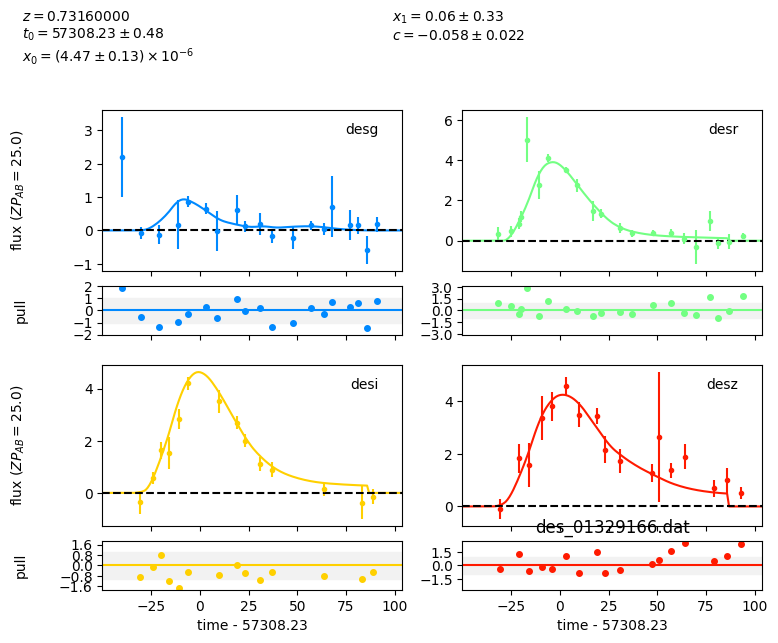

Processing: des_01329196.dat
Fitness within 2σ: 95.12%


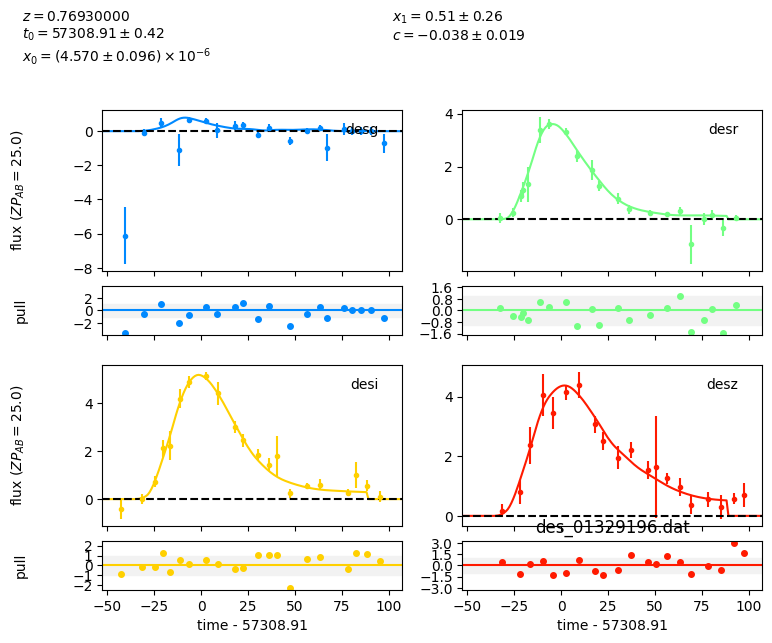

Processing: des_01329312.dat
Fitness within 2σ: 98.31%


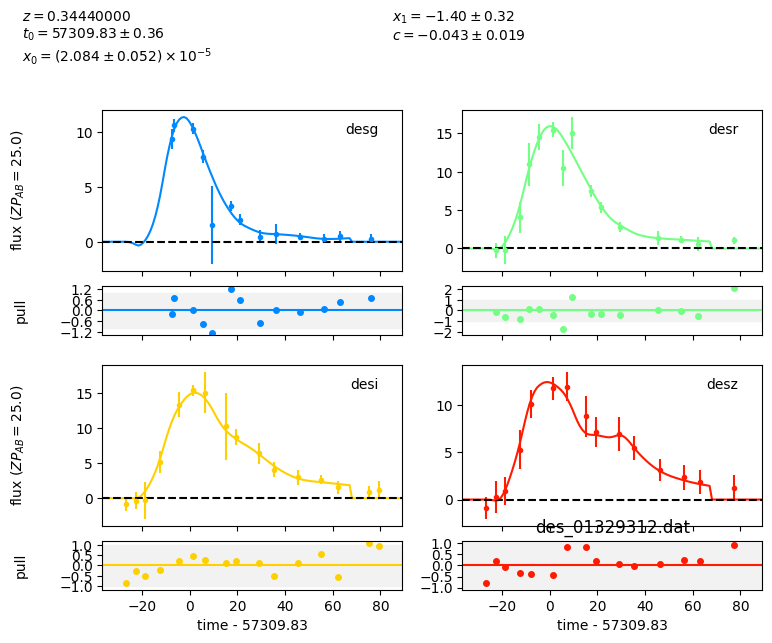

Processing: des_01329615.dat
Fitness within 2σ: 98.48%


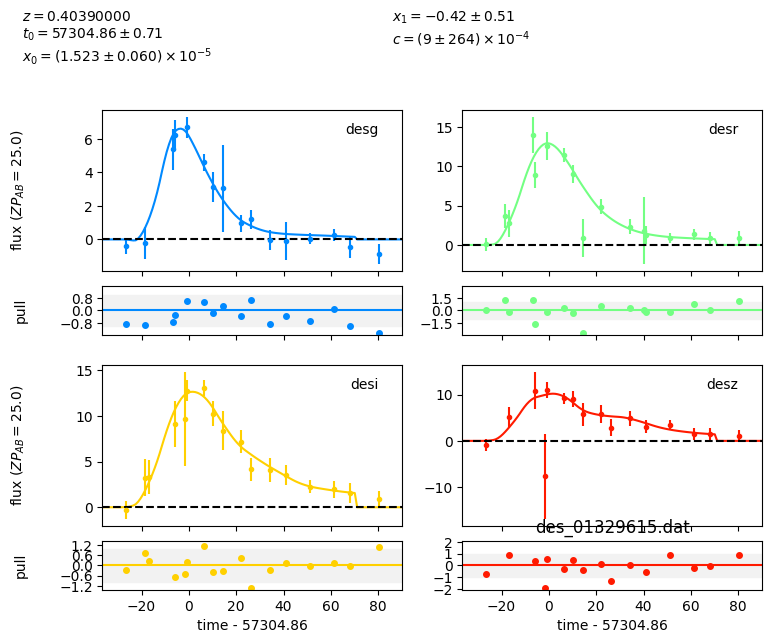

Processing: des_01330031.dat
Fitness within 2σ: 43.94%


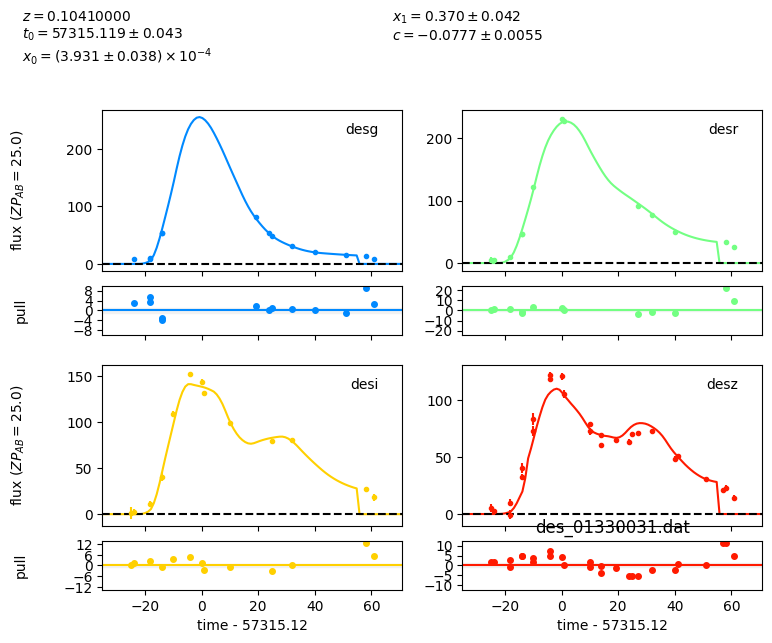

Processing: des_01330426.dat
Fitness within 2σ: 86.36%


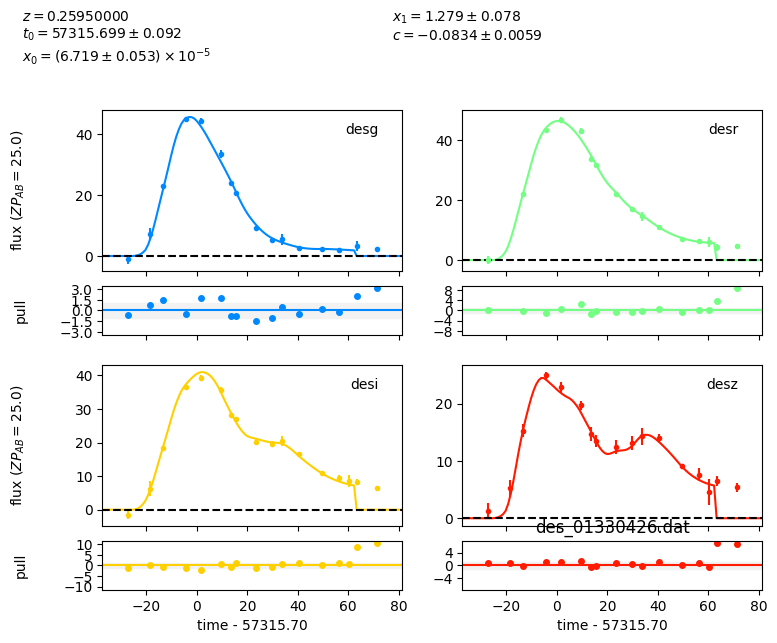

Processing: des_01330642.dat
Fitness within 2σ: 95.59%


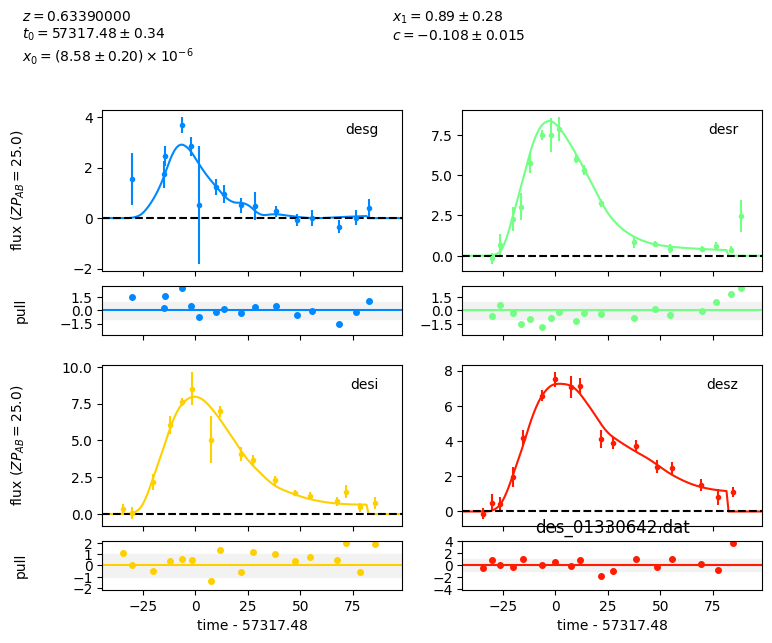

Processing: des_01330903.dat
Fitness within 2σ: 97.47%


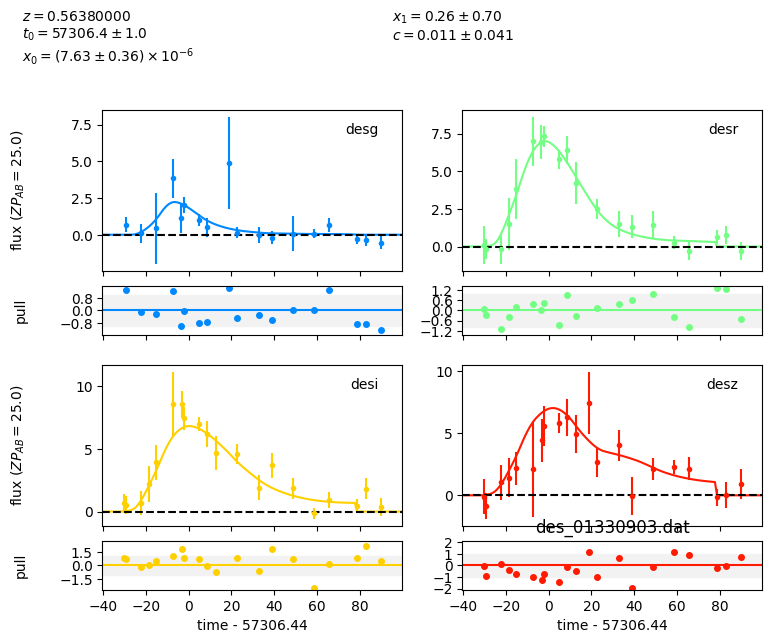

Processing: des_01331123.dat
Fitness within 2σ: 89.39%


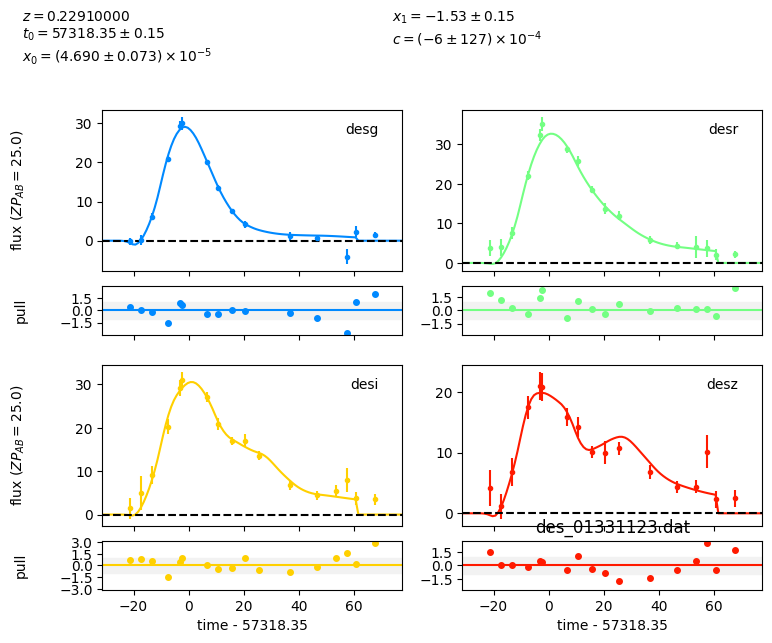

Processing: des_01331993.dat
Fitness within 2σ: 96.88%


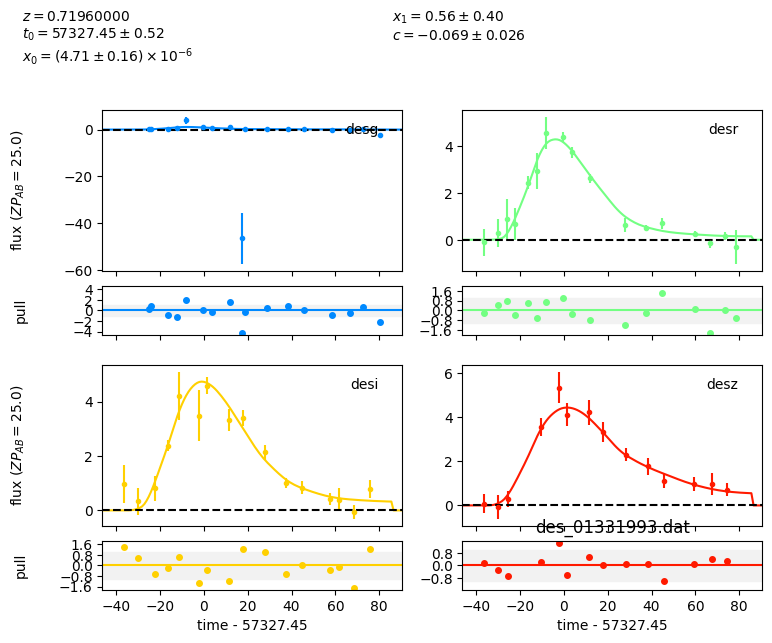

Processing: des_01332059.dat
Fitness within 2σ: 97.18%


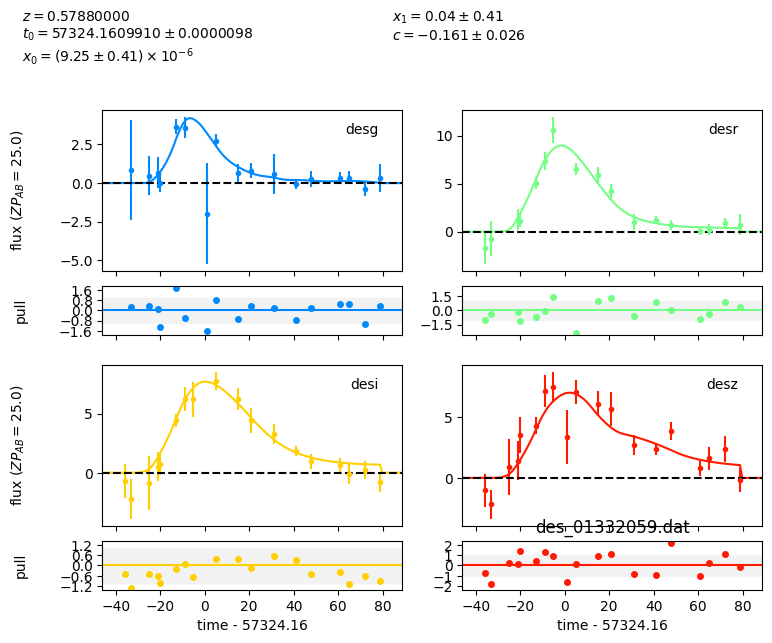

Processing: des_01332413.dat
Fitness within 2σ: 95.65%


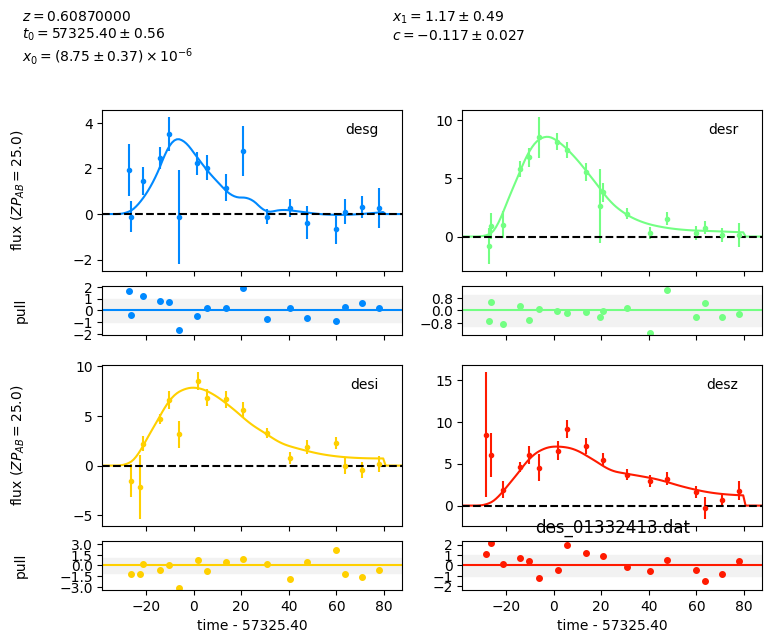

Processing: des_01333246.dat
Fitness within 2σ: 98.21%


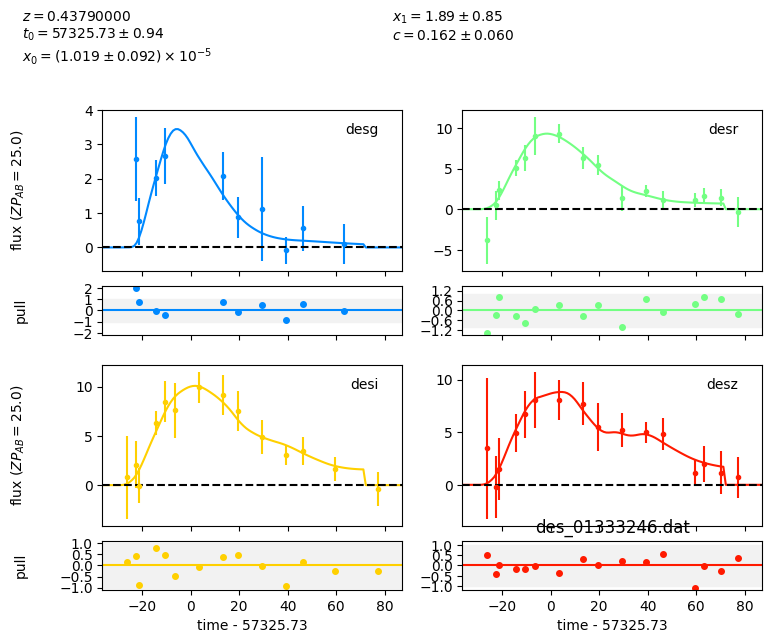

Processing: des_01333438.dat
Fitness within 2σ: 94.34%


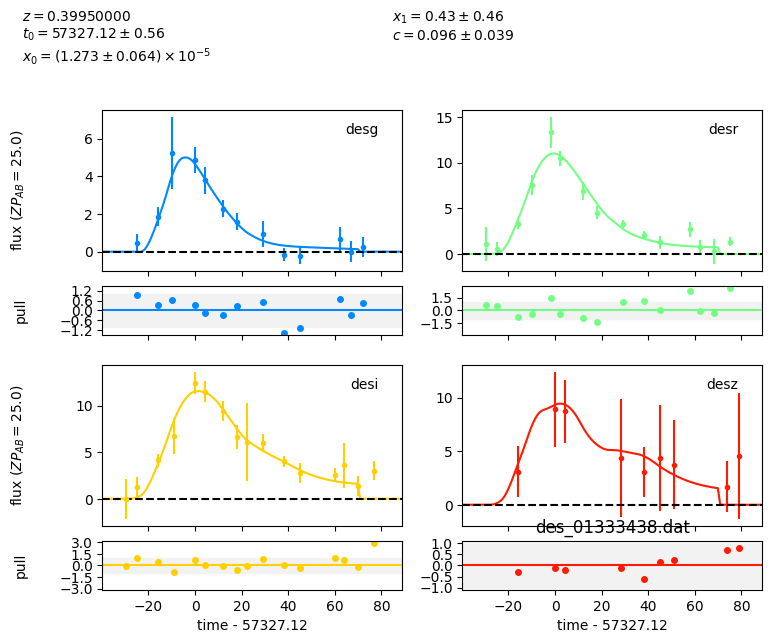

Processing: des_01334084.dat
Fitness within 2σ: 91.89%


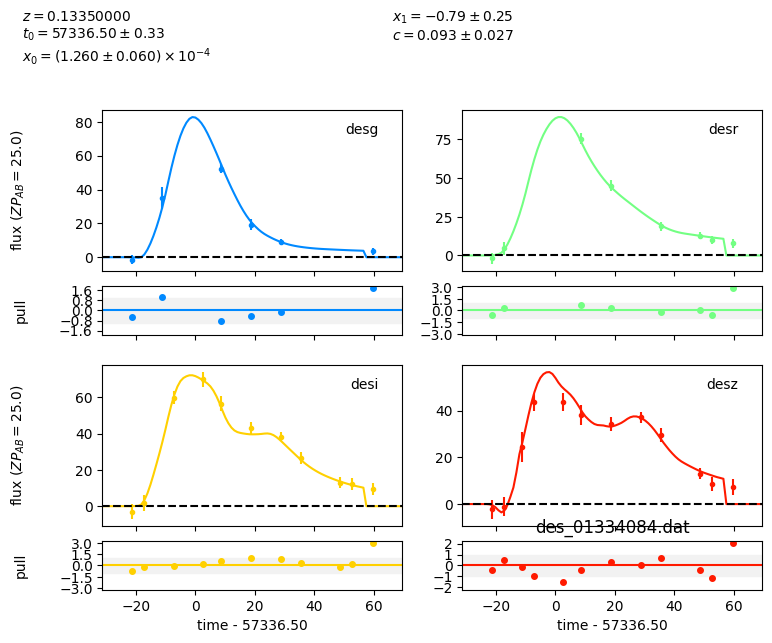

Processing: des_01334087.dat
Fitness within 2σ: 96.30%


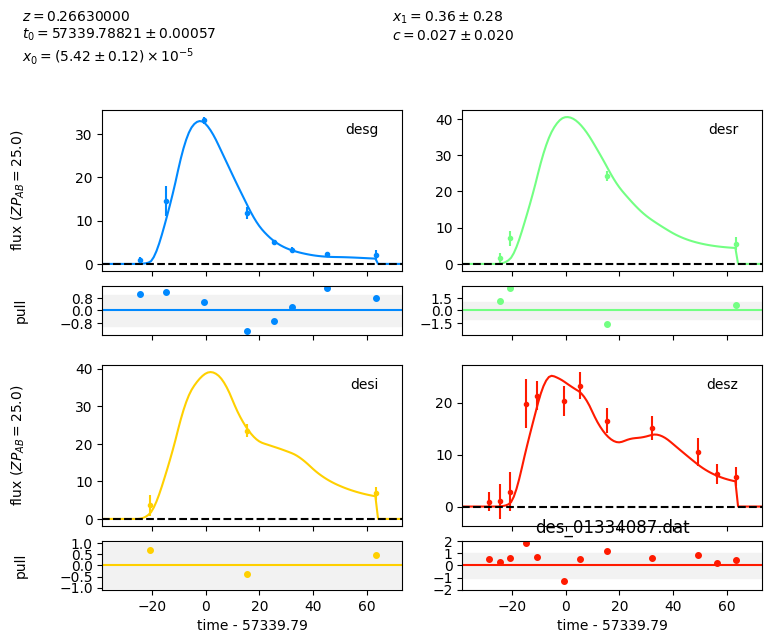

Processing: des_01334302.dat
Fitness within 2σ: 98.44%


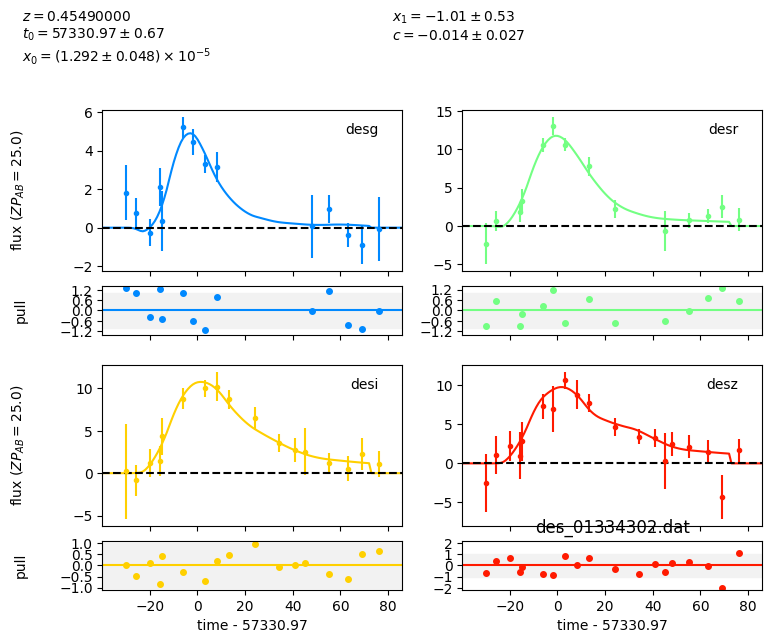

Processing: des_01334423.dat
Fitness within 2σ: 100.00%


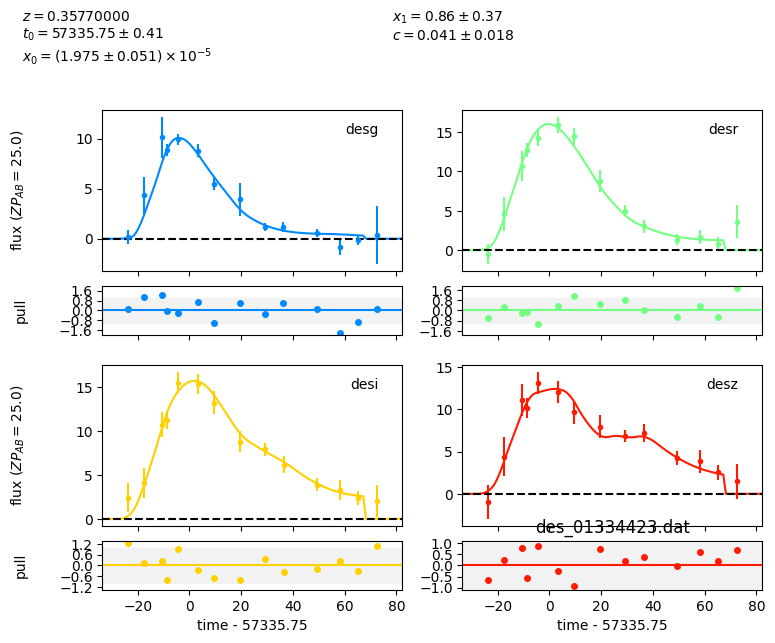

Processing: des_01334448.dat
Fitness within 2σ: 96.88%


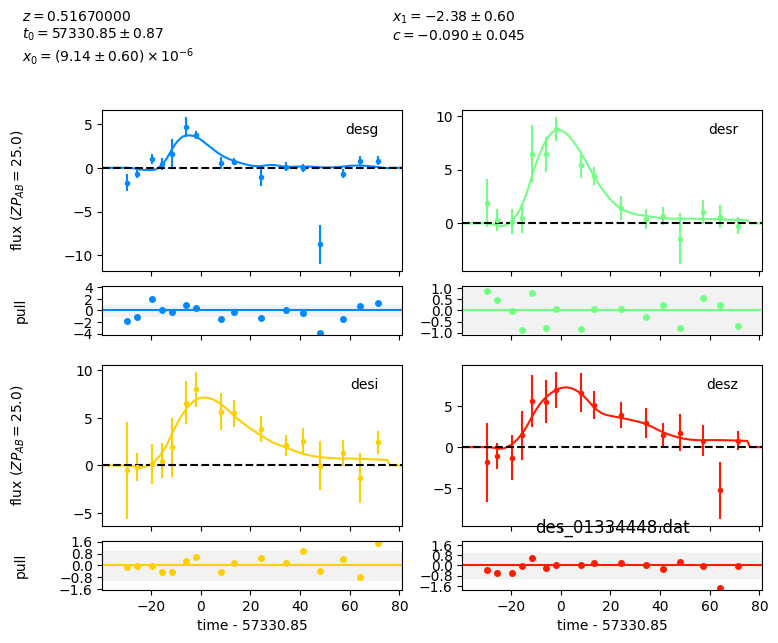

Processing: des_01334470.dat
Fitness within 2σ: 93.33%


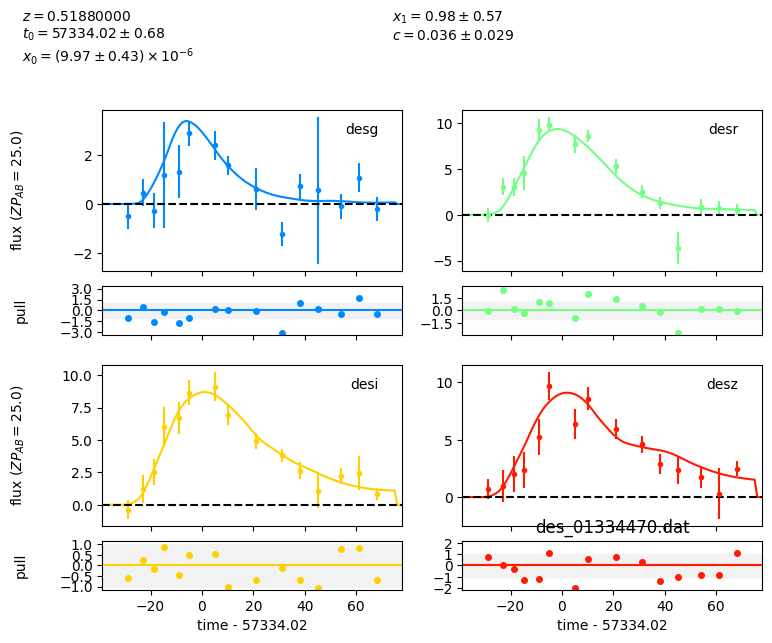

Processing: des_01334597.dat
Fitness within 2σ: 93.75%


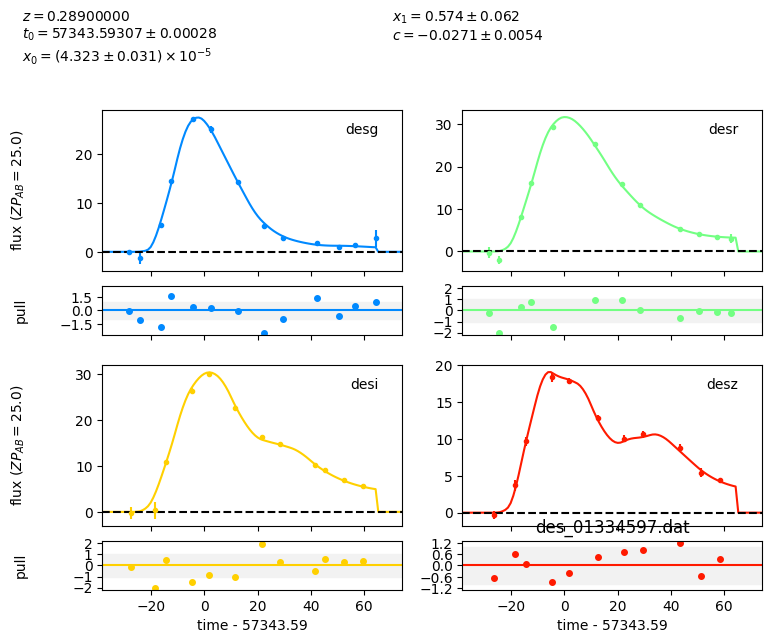

Processing: des_01334620.dat
Fitness within 2σ: 91.38%


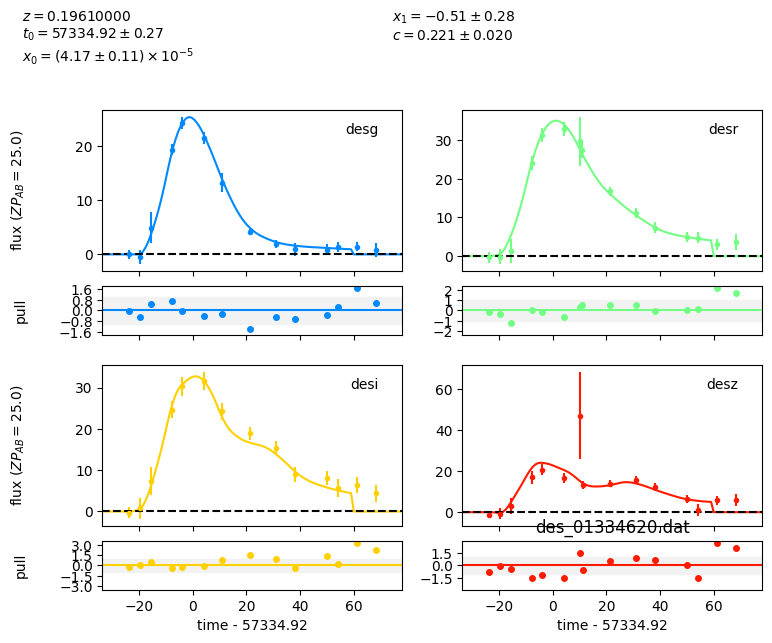

Processing: des_01334644.dat
Fitness within 2σ: 96.43%


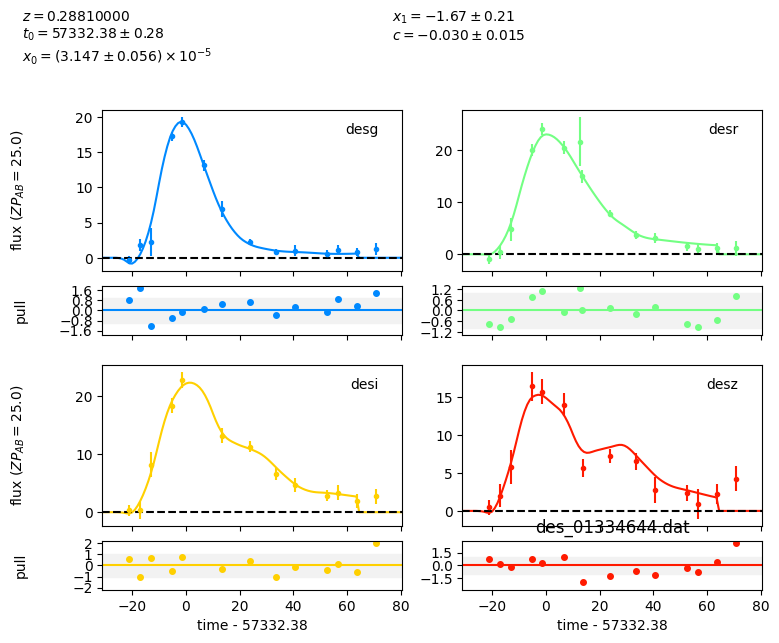

Processing: des_01334707.dat
Fitness within 2σ: 95.24%


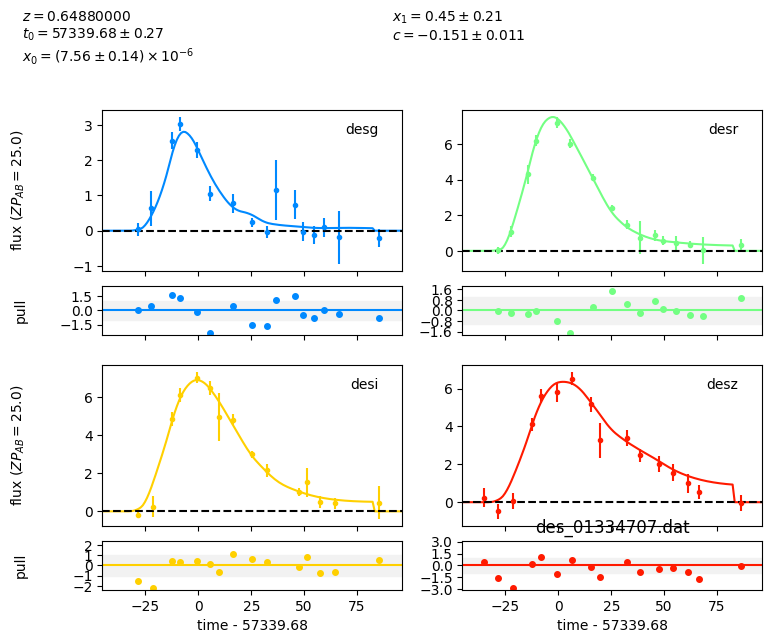

Processing: des_01334645.dat
Fitness within 2σ: 92.59%


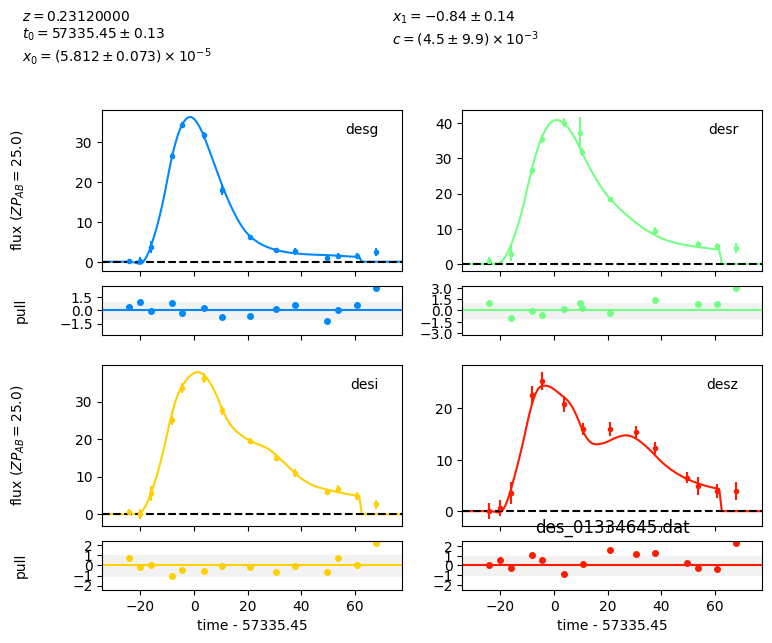

Processing: des_01334879.dat
Fitness within 2σ: 96.72%


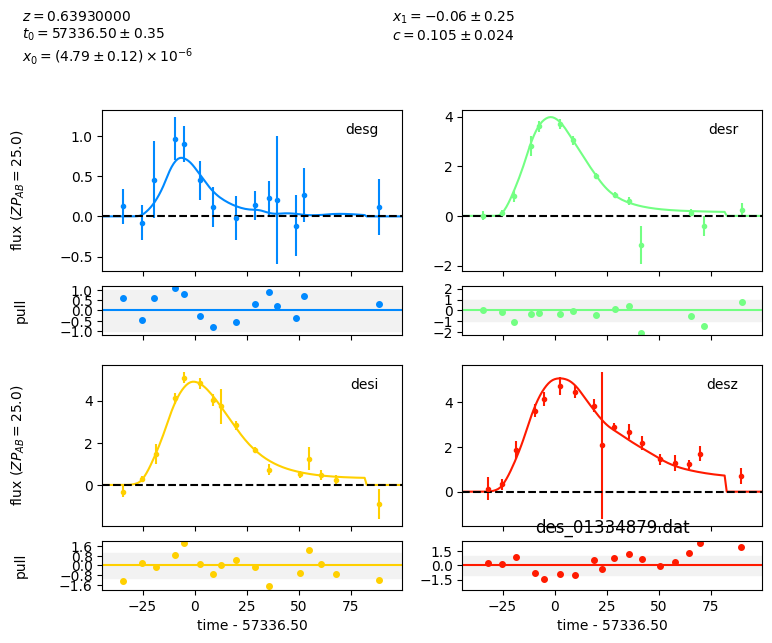

Processing: des_01335472.dat
Fitness within 2σ: 100.00%


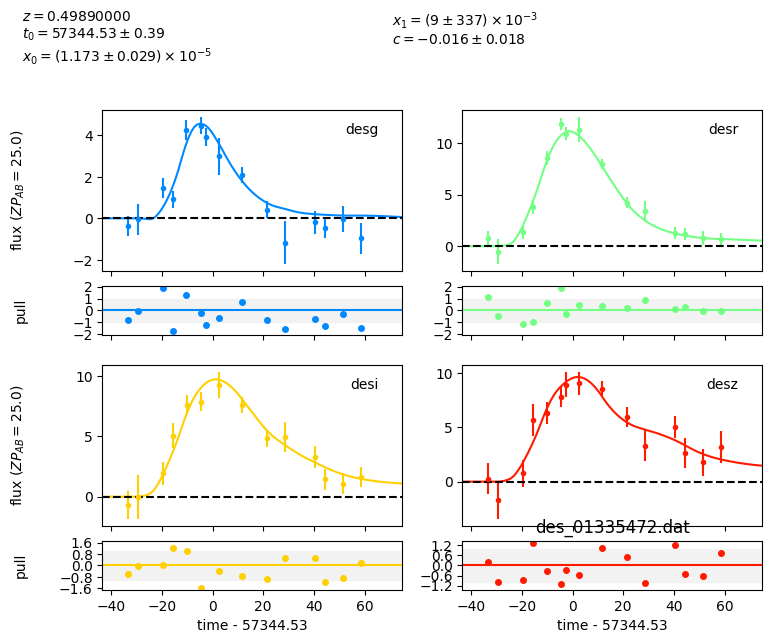

Processing: des_01335564.dat
Fitness within 2σ: 95.00%


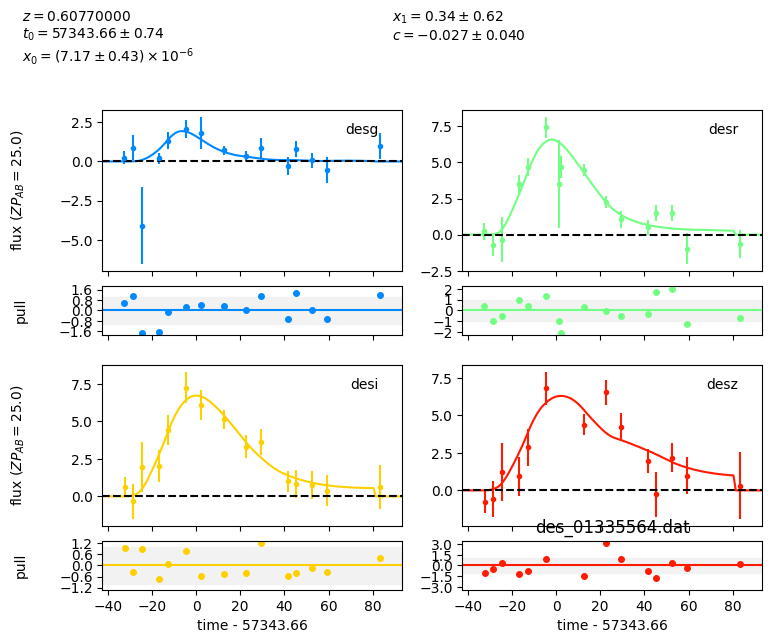

Processing: des_01335717.dat
Fitness within 2σ: 98.04%


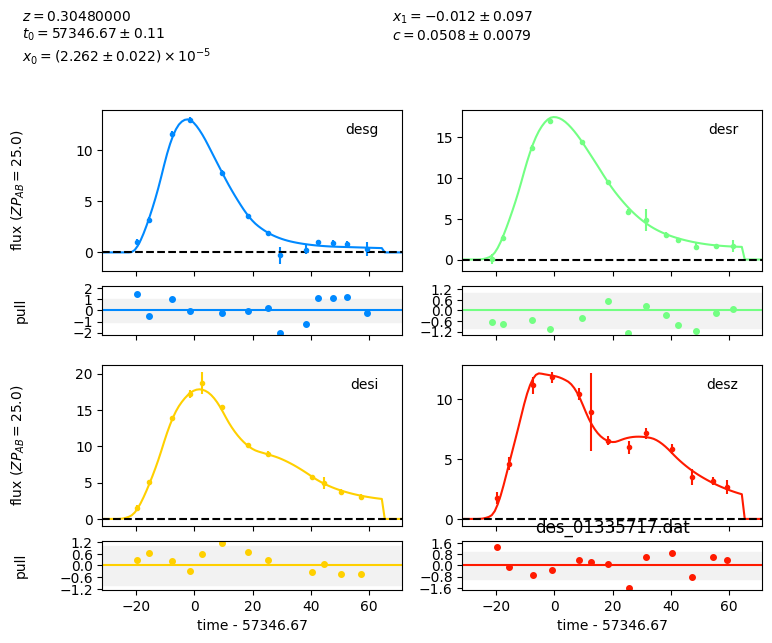

Processing: des_01335718.dat
Fitness within 2σ: 96.61%


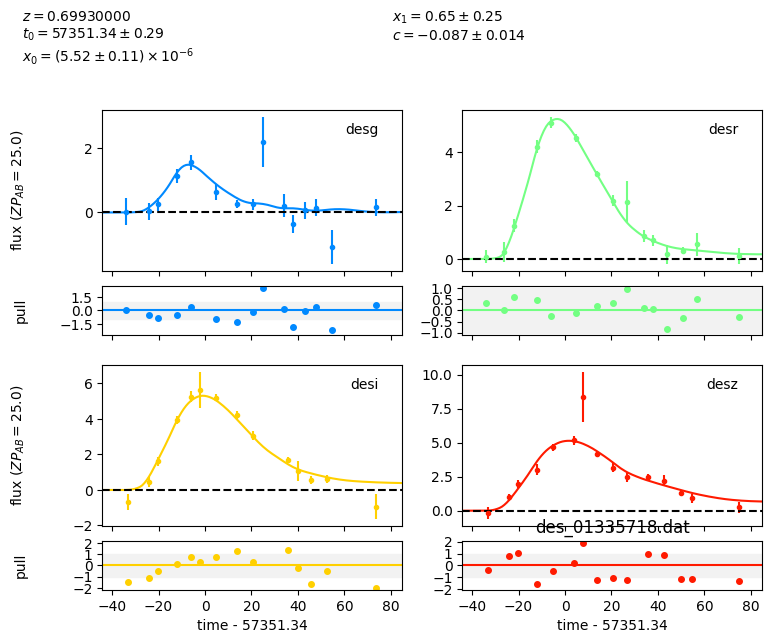

Processing: des_01335868.dat
Fitness within 2σ: 96.97%


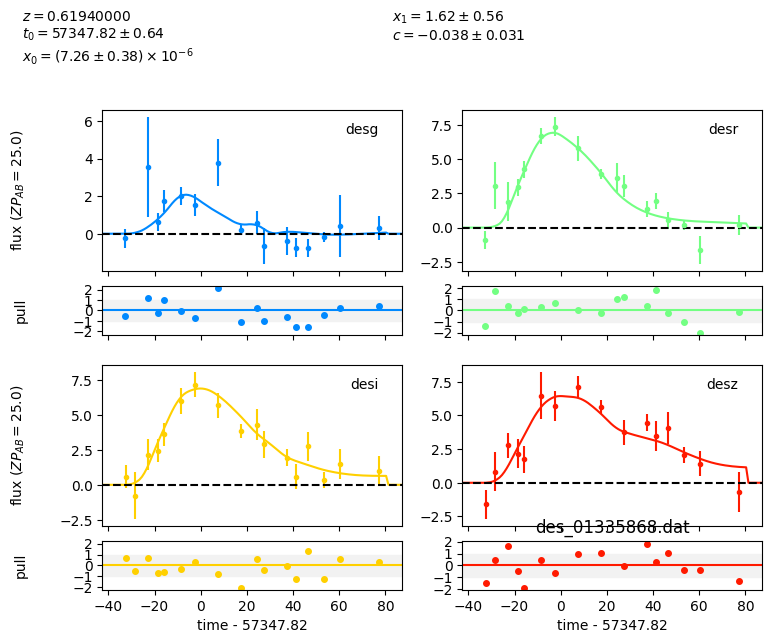

Processing: des_01336008.dat
Fitness within 2σ: 98.00%


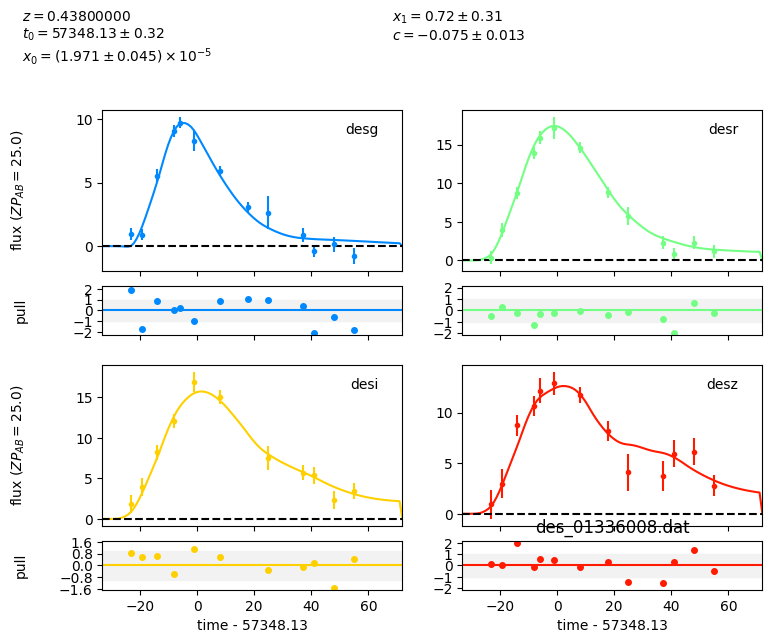

Processing: des_01336009.dat
Fitness within 2σ: 98.04%


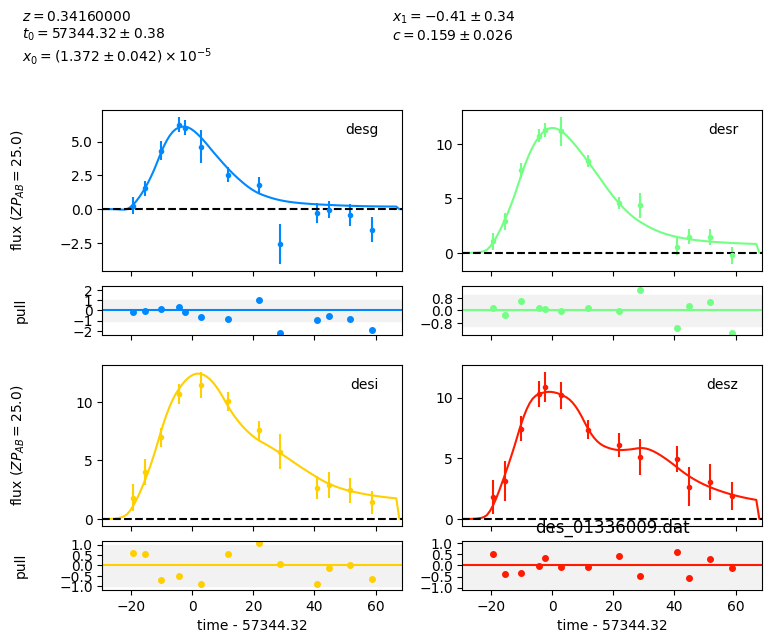

Processing: des_01336453.dat
Fitness within 2σ: 97.37%


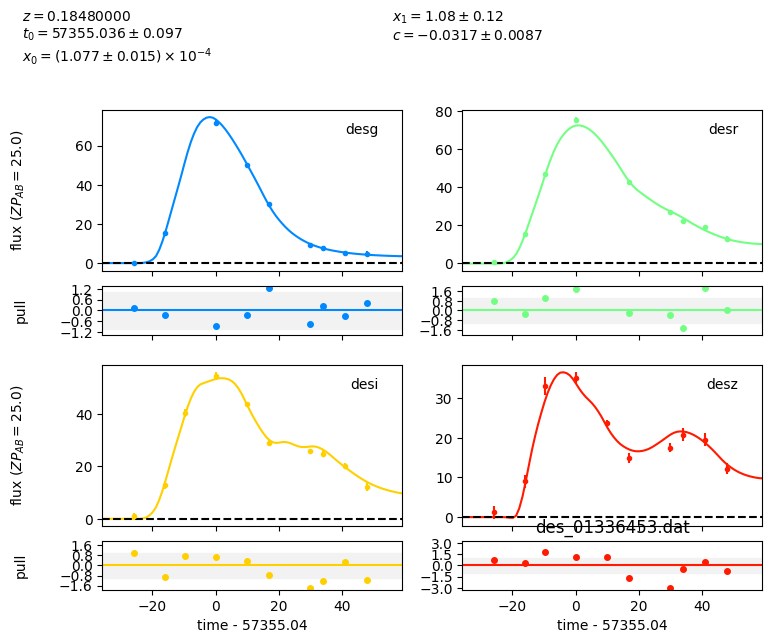

Processing: des_01336480.dat
Fitness within 2σ: 100.00%


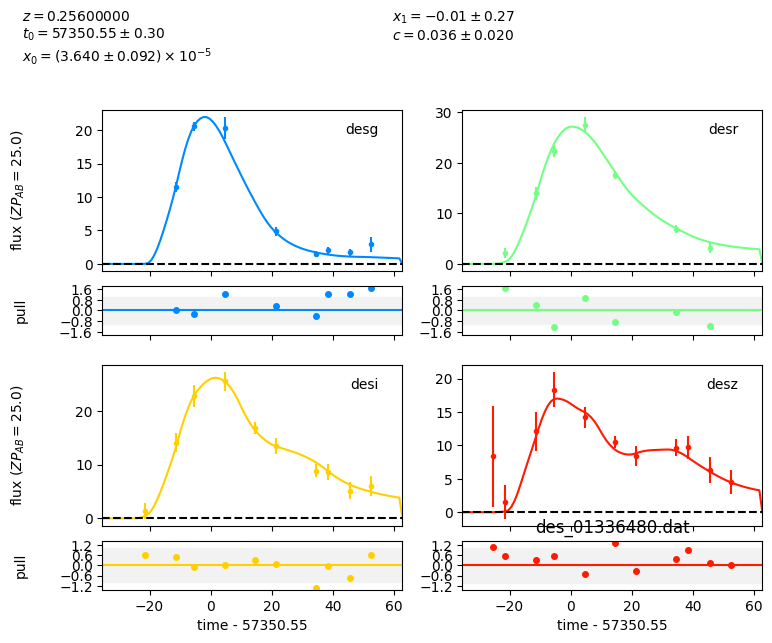

Processing: des_01336687.dat
Fitness within 2σ: 95.56%


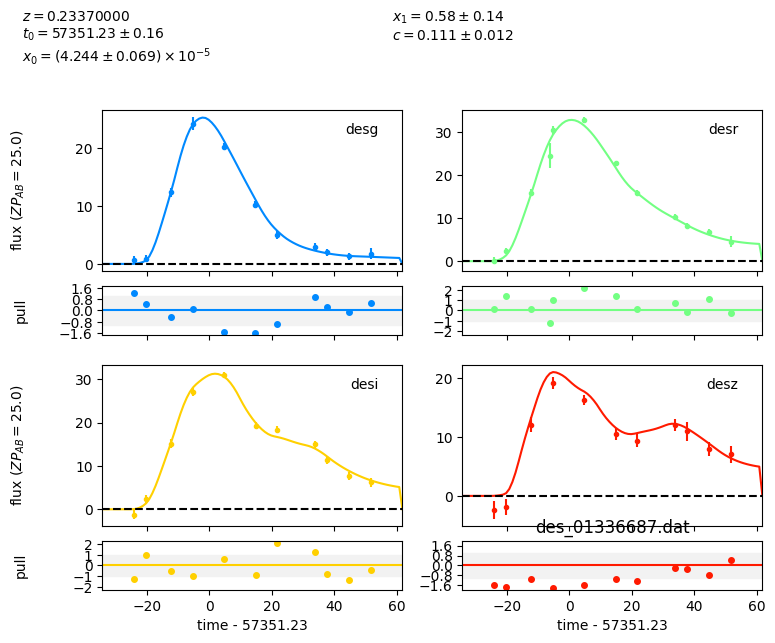

Processing: des_01337228.dat
Fitness within 2σ: 100.00%


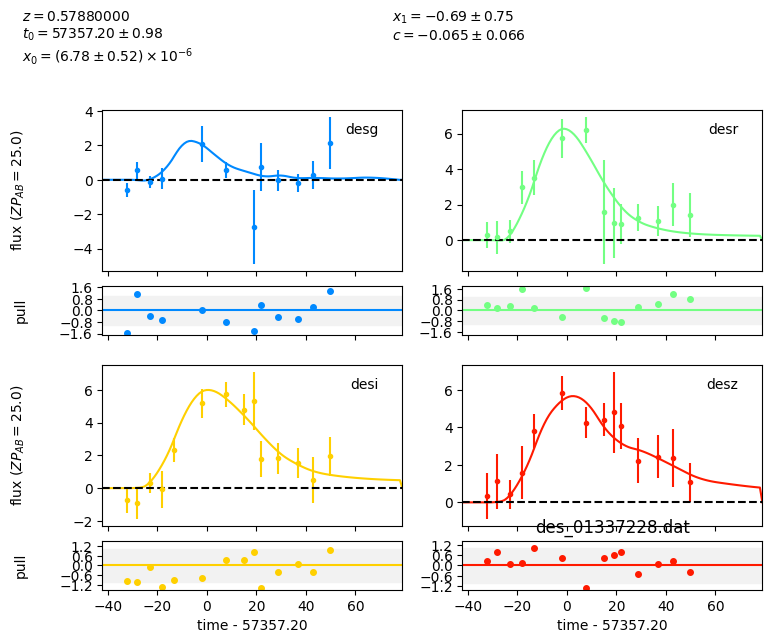

Processing: des_01337221.dat
Fitness within 2σ: 98.15%


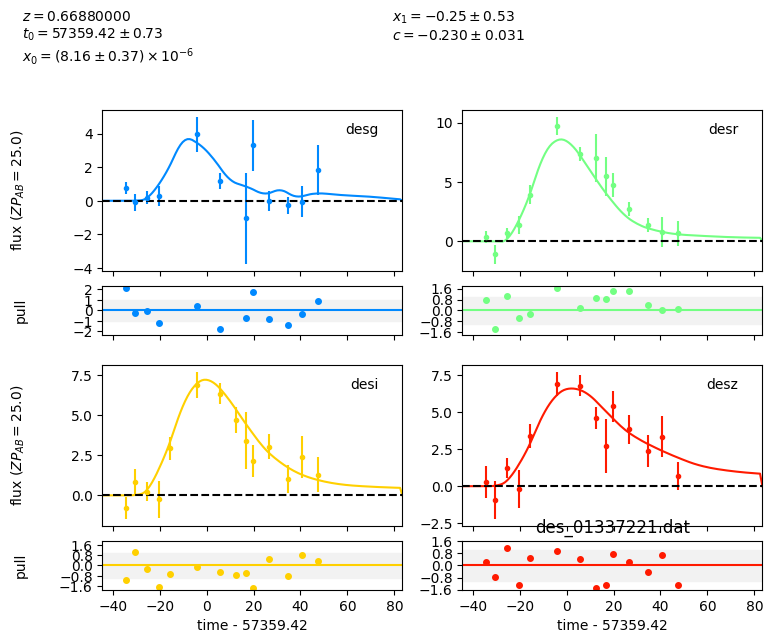

Processing: des_01337272.dat
Fitness within 2σ: 97.92%


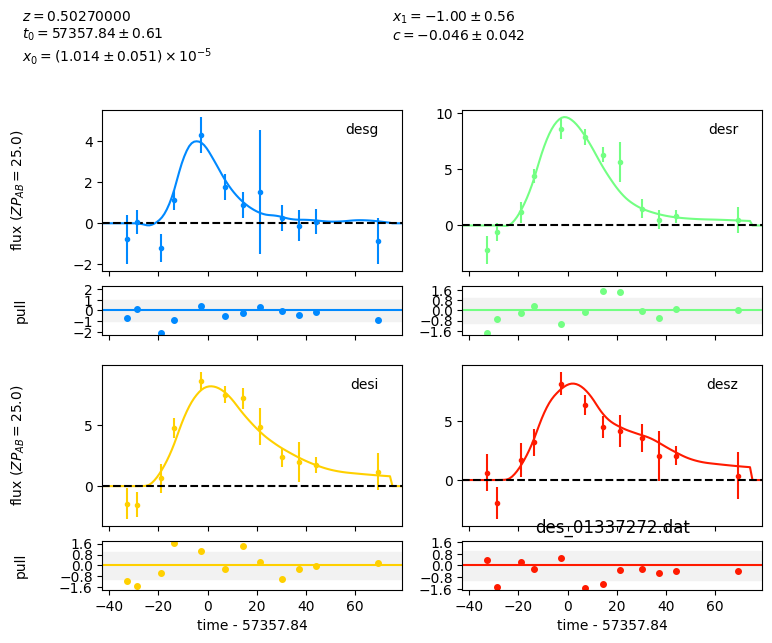

Processing: des_01337325.dat
Fitness within 2σ: 95.83%


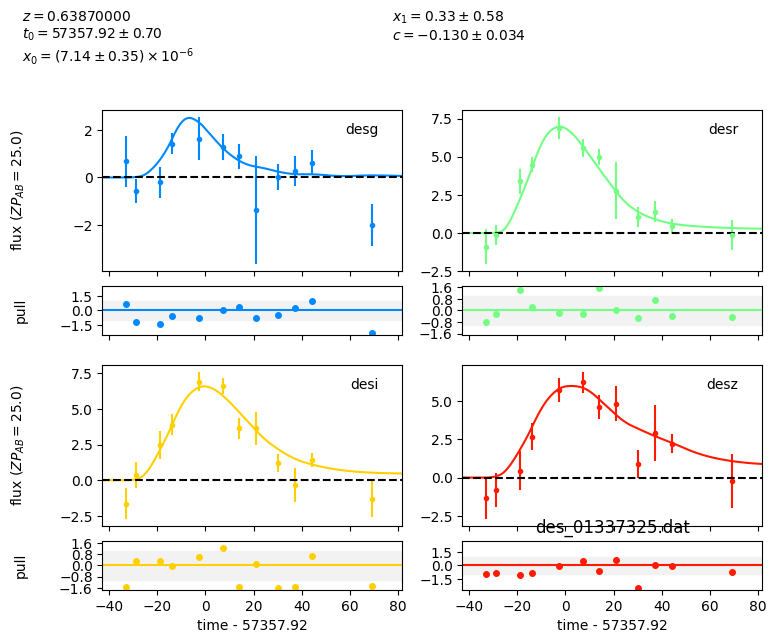

Processing: des_01337655.dat
Fitness within 2σ: 90.48%


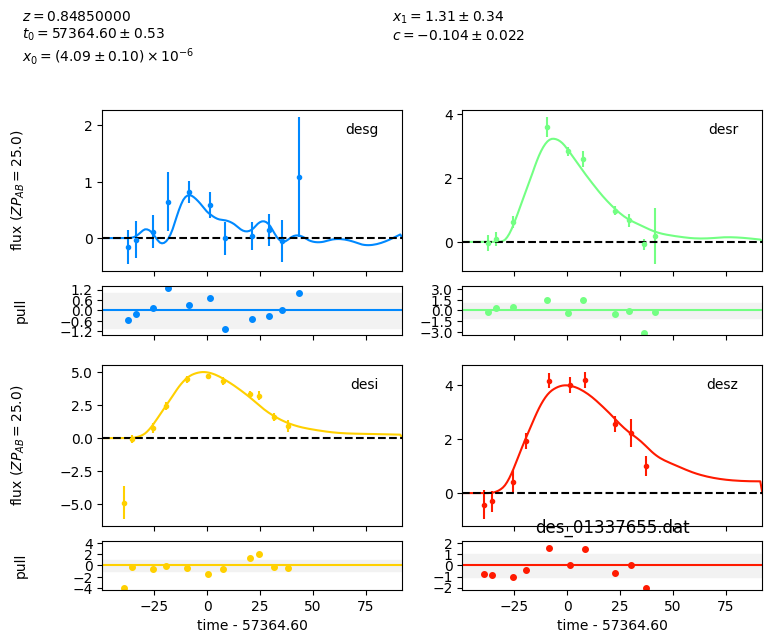

Processing: des_01337649.dat
Fitness within 2σ: 91.67%


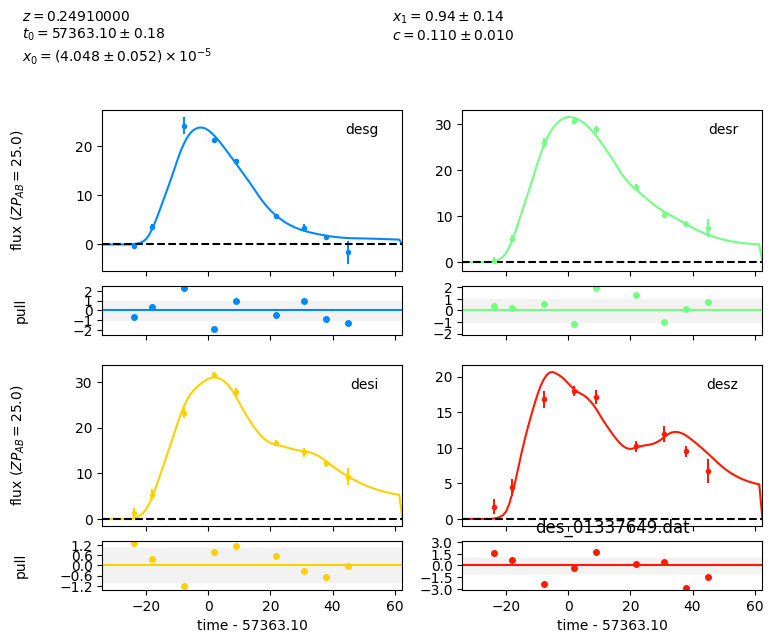

Processing: des_01337687.dat
Fitness within 2σ: 97.87%


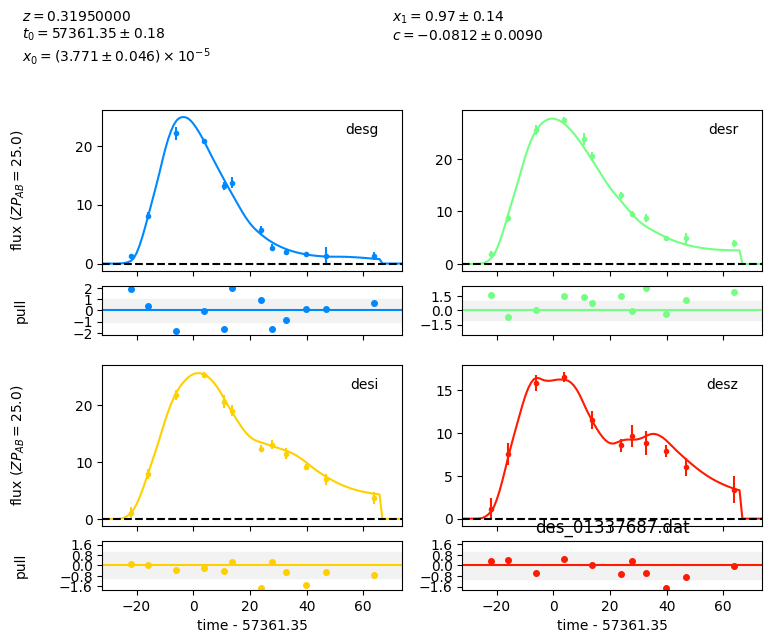

Processing: des_01337703.dat
Fitness within 2σ: 100.00%


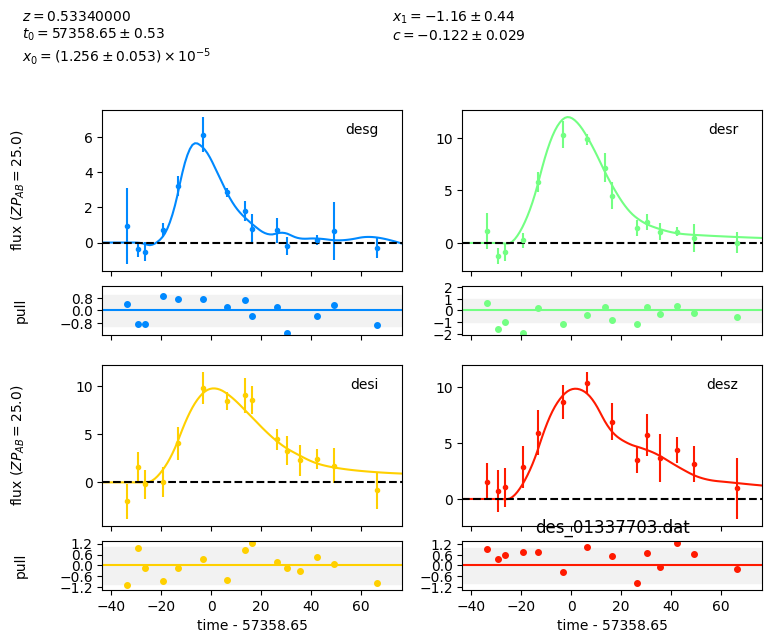

Processing: des_01337838.dat
Fitness within 2σ: 88.10%


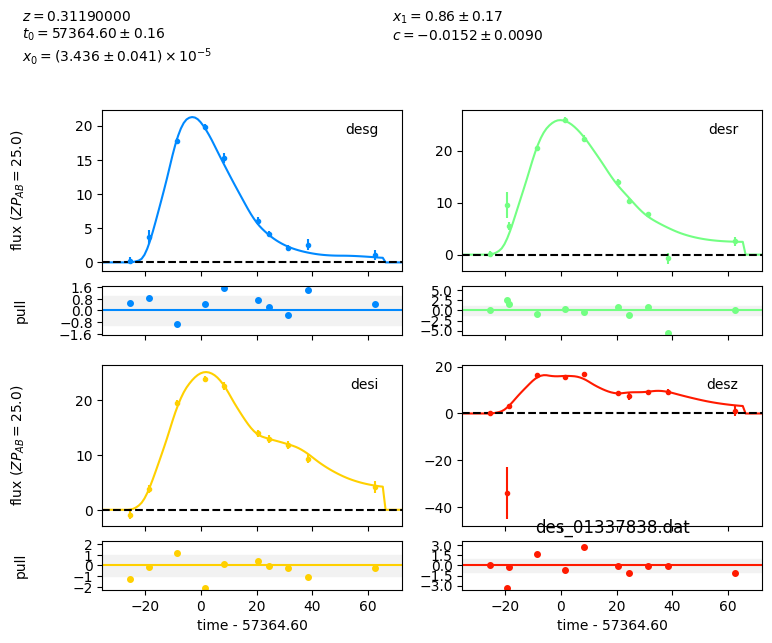

Processing: des_01338266.dat
Fitness within 2σ: 98.75%


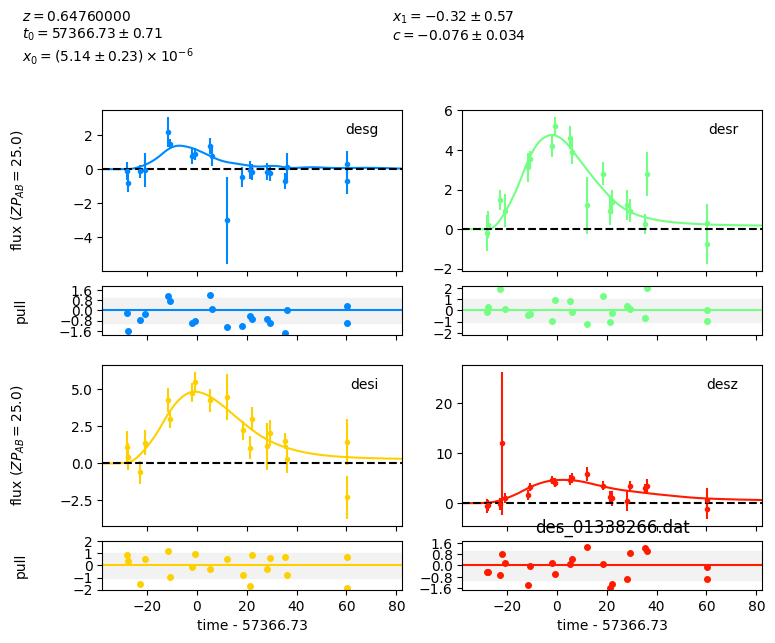

Processing: des_01338233.dat
Fitness within 2σ: 98.08%


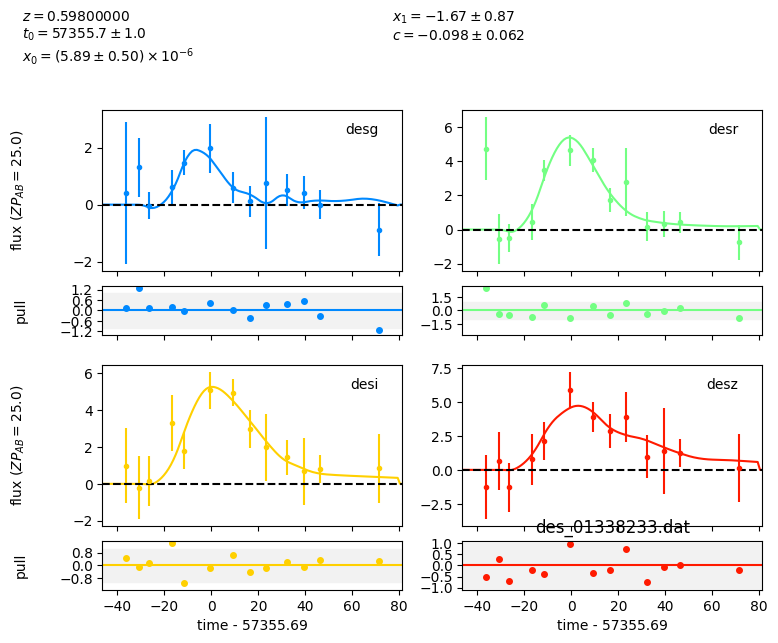

Processing: des_01338278.dat
Fitness within 2σ: 100.00%


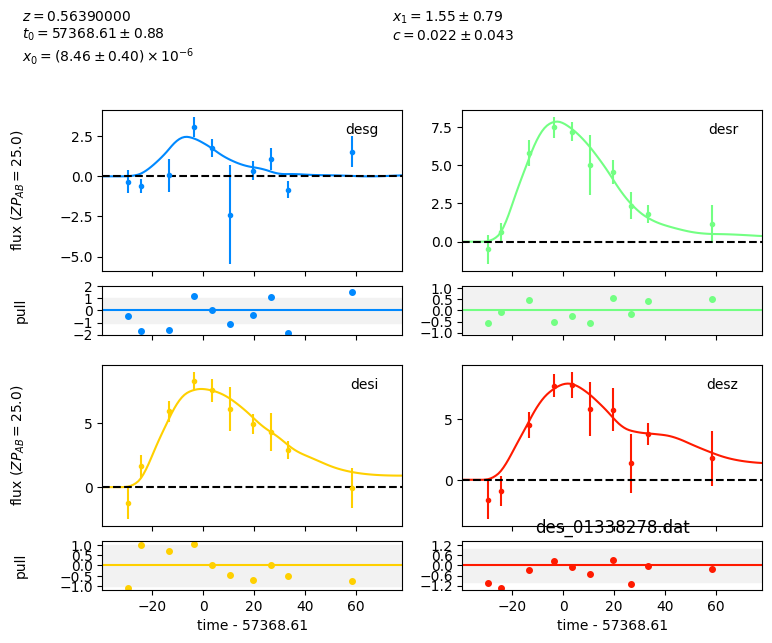

Processing: des_01338430.dat
Fitness within 2σ: 100.00%


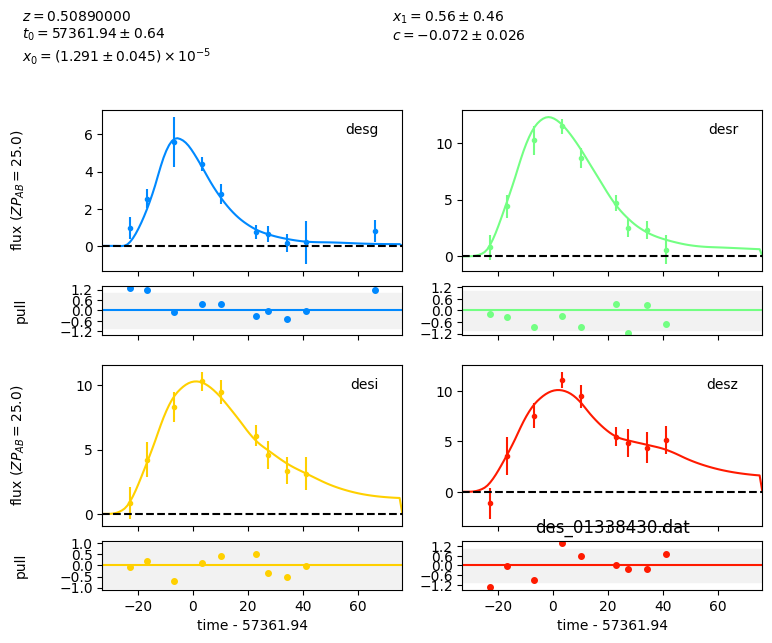

Processing: des_01338471.dat
Fitness within 2σ: 100.00%


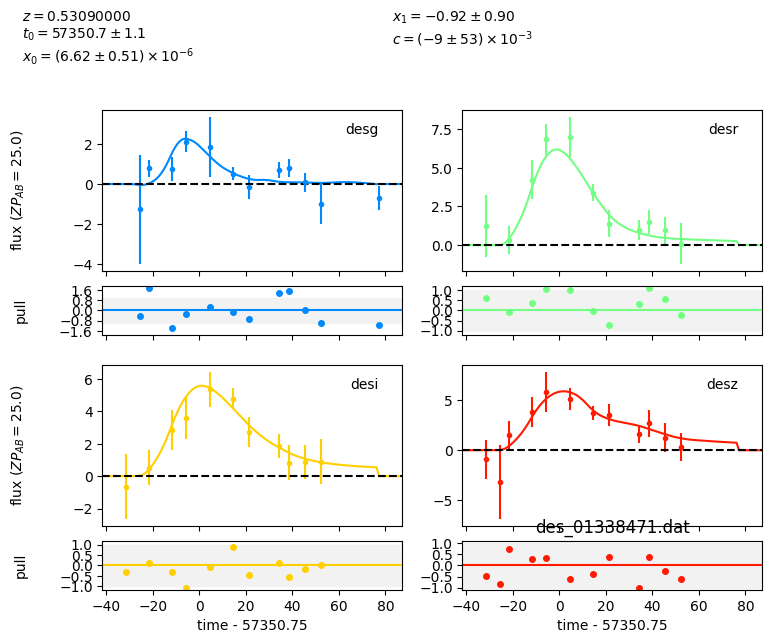

Processing: des_01338675.dat
Fitness within 2σ: 100.00%


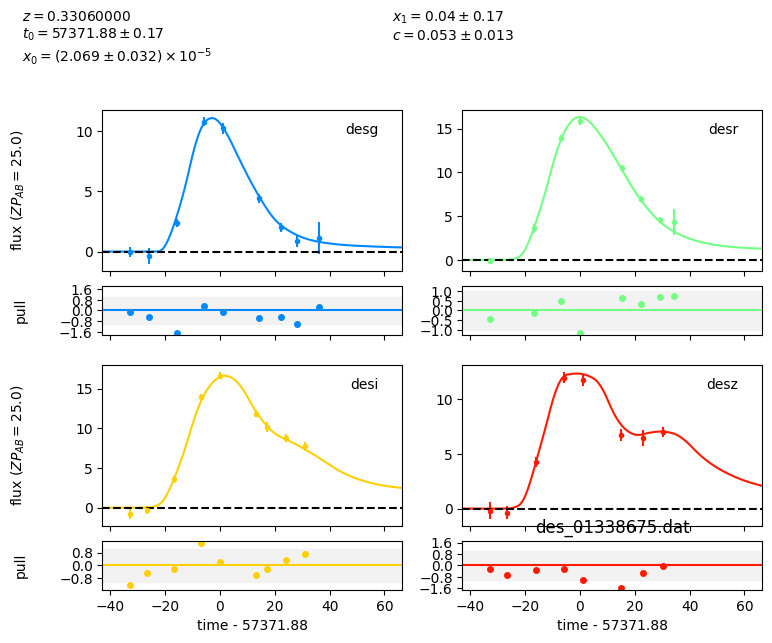

Processing: des_01339002.dat
Fitness within 2σ: 94.44%


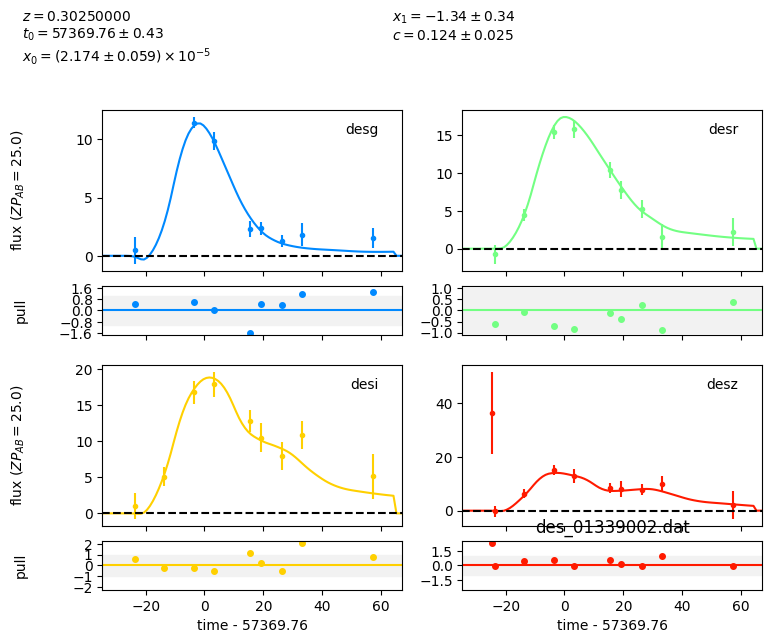

Processing: des_01339149.dat
Fitness within 2σ: 100.00%


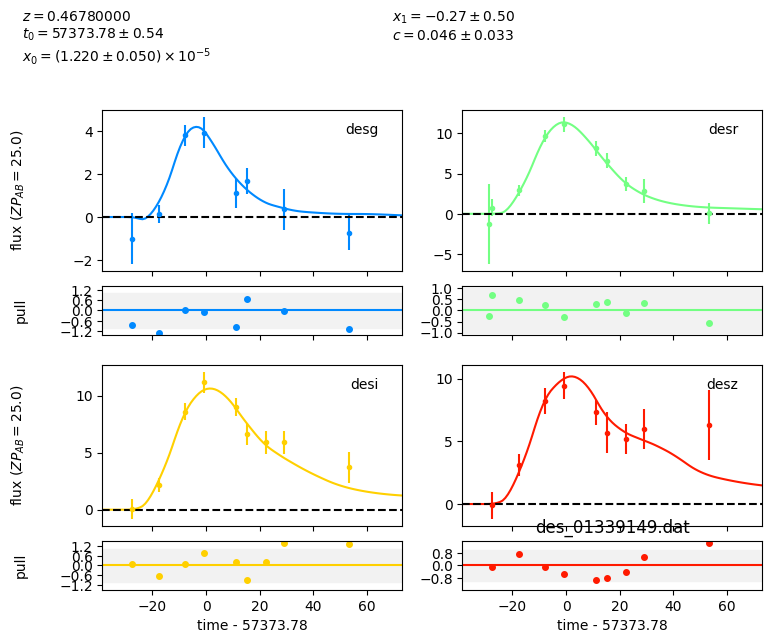

Processing: des_01339392.dat
Fitness within 2σ: 100.00%


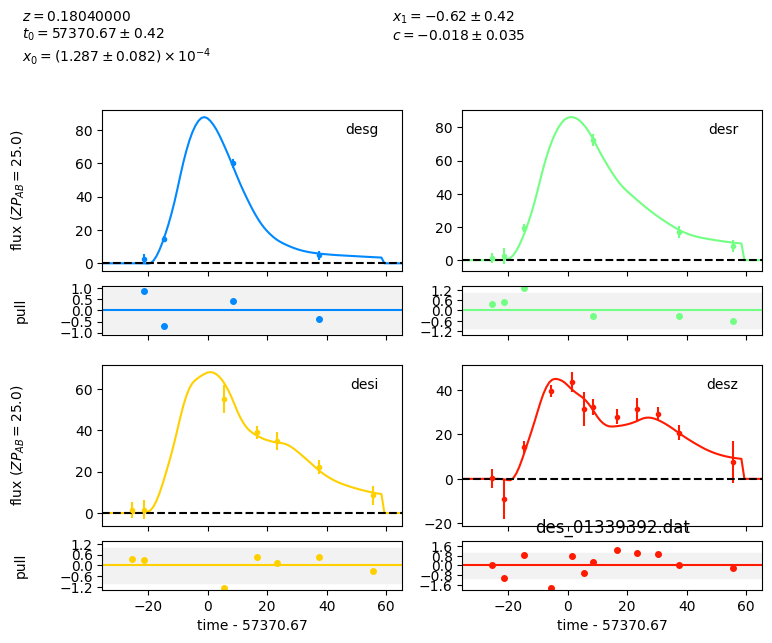

Processing: des_01339450.dat
Fitness within 2σ: 96.08%


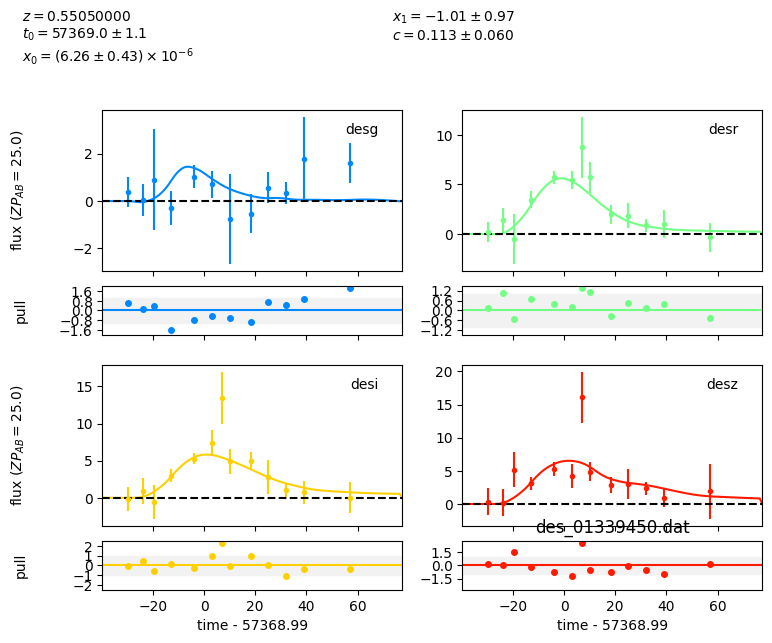

Processing: des_01340454.dat
Fitness within 2σ: 81.40%


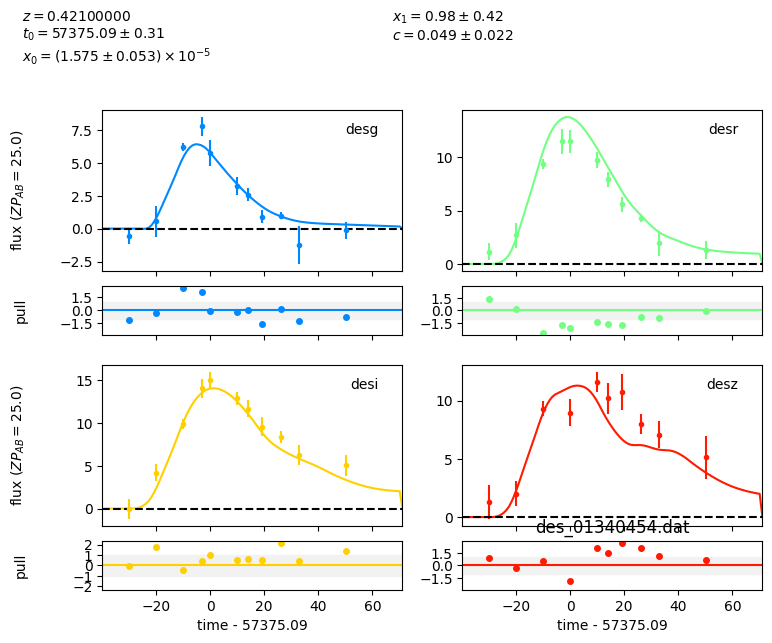

Processing: des_01341370.dat
Fitness within 2σ: 100.00%


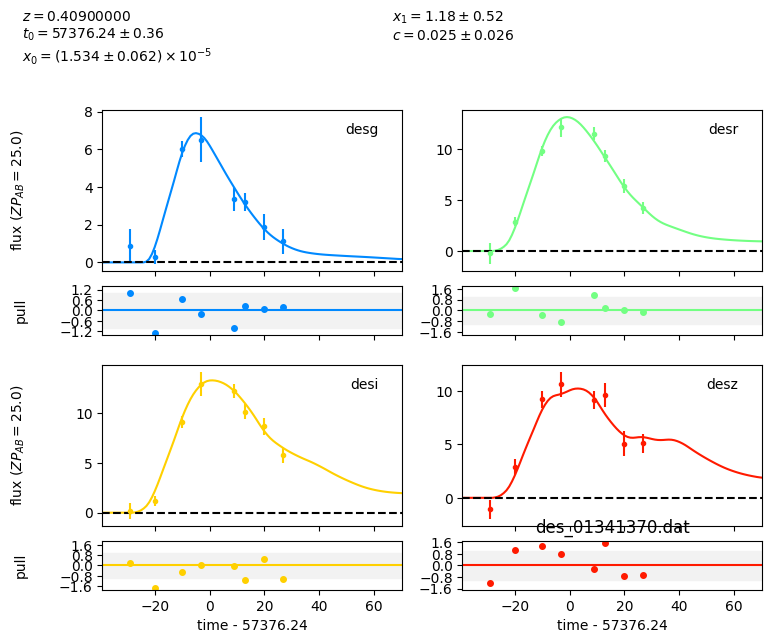

Processing: des_01342255.dat
Fitness within 2σ: 100.00%


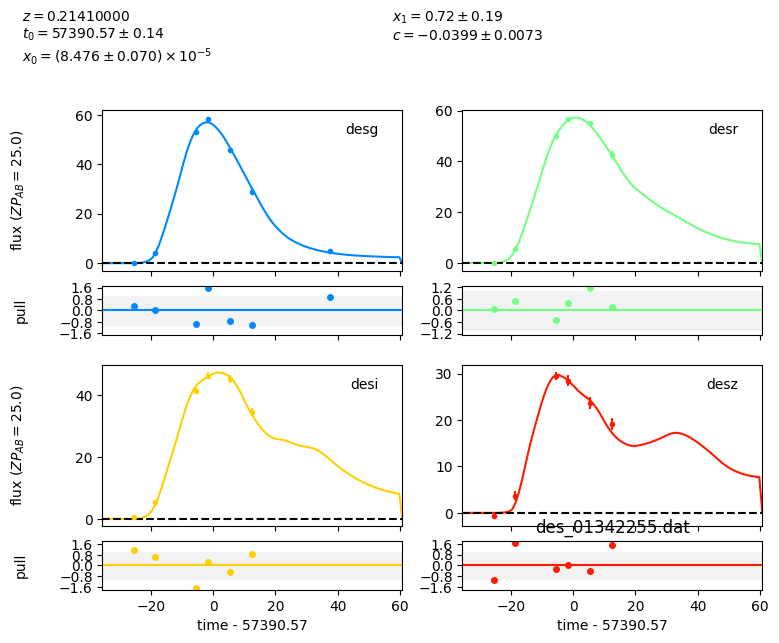

Processing: des_01343208.dat
Fitness within 2σ: 100.00%


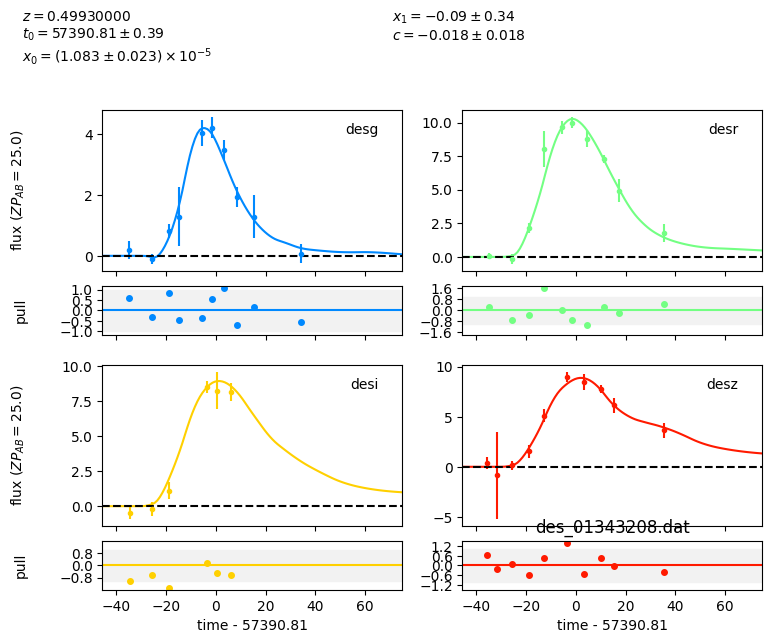

Processing: des_01343401.dat
Fitness within 2σ: 100.00%


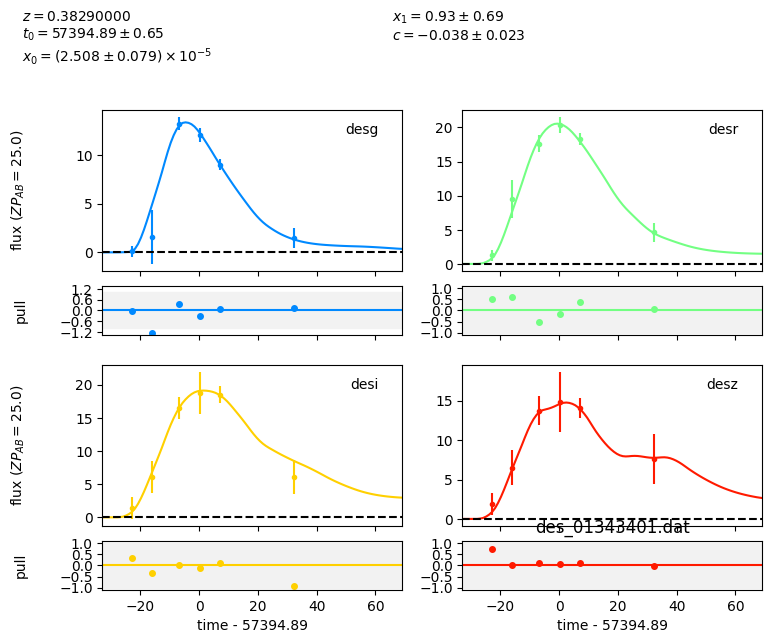

Processing: des_01343337.dat
Fitness within 2σ: 100.00%


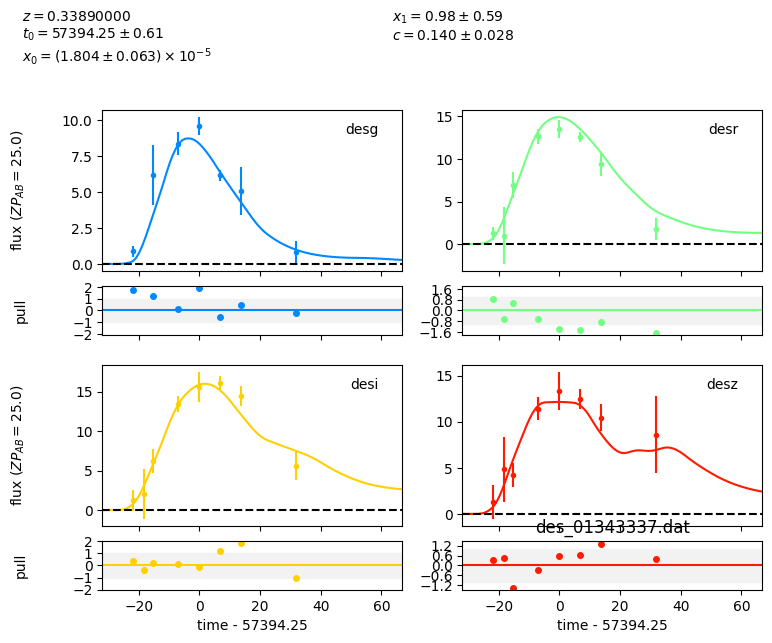

Processing: des_01343533.dat
Fitness within 2σ: 96.77%


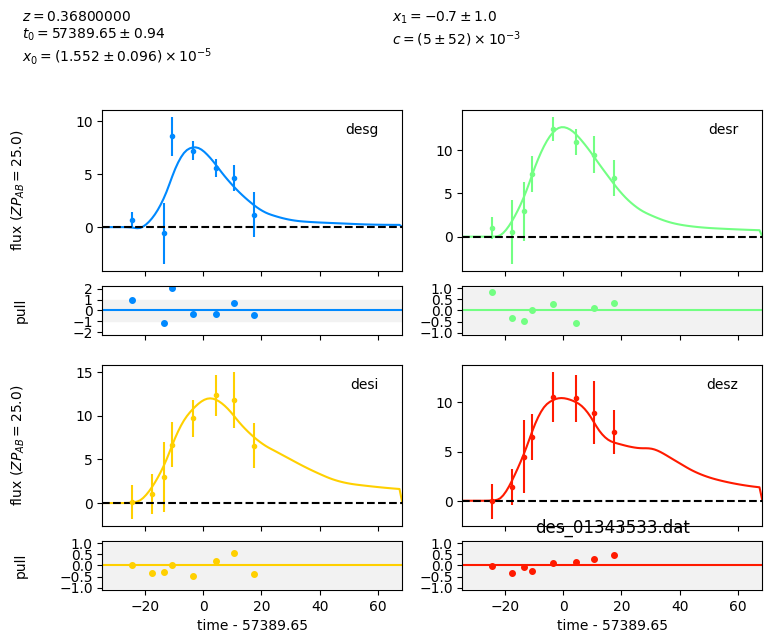

Processing: des_01343871.dat
Fitness within 2σ: 100.00%


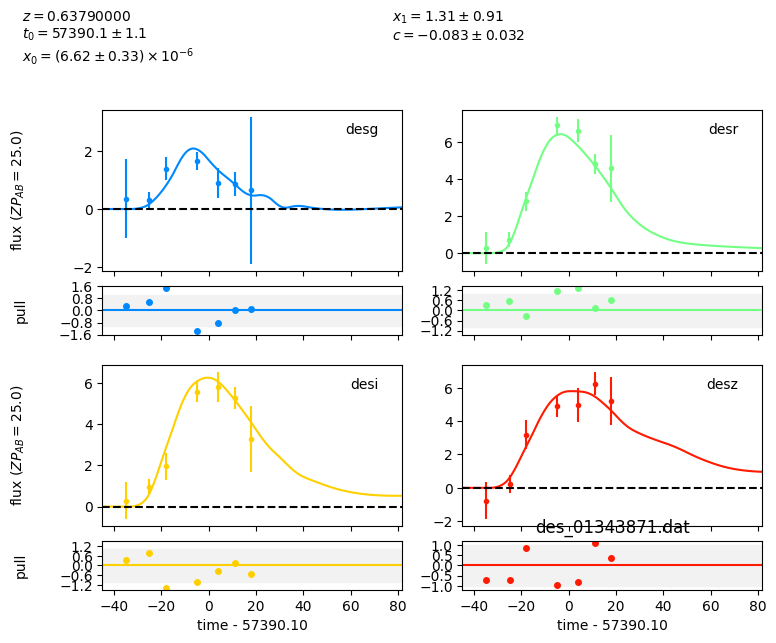

Processing: des_01344692.dat
Fitness within 2σ: 100.00%


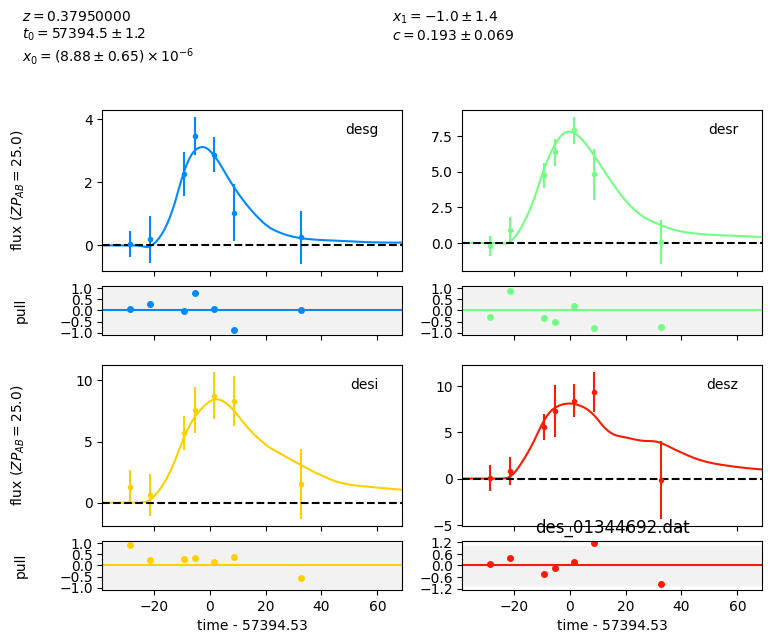

Processing: des_01345582.dat
Fitness within 2σ: 100.00%


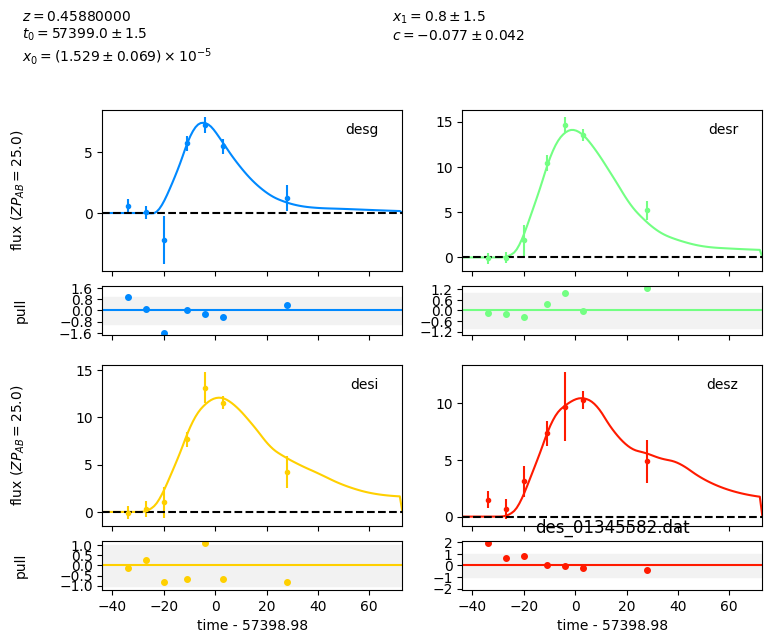

Processing: des_01345553.dat
Fitness within 2σ: 100.00%


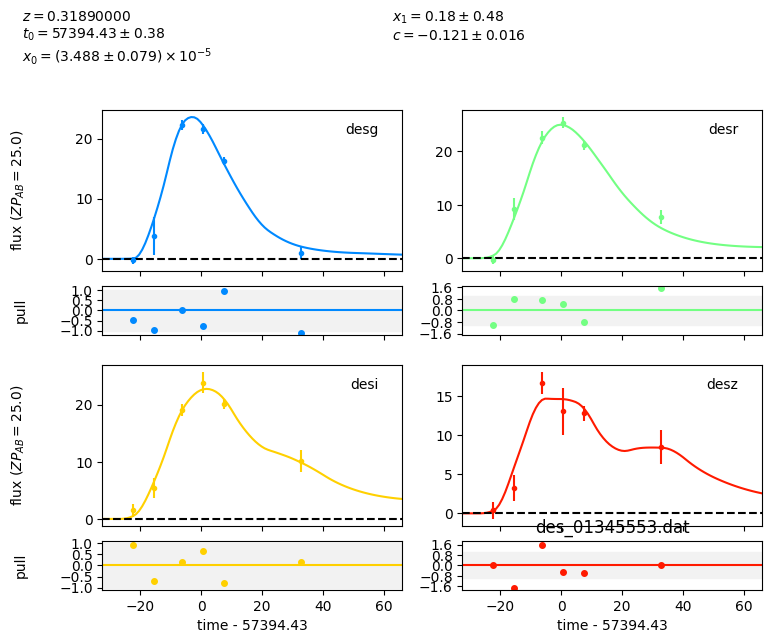

Processing: des_01346137.dat
Fitness within 2σ: 100.00%


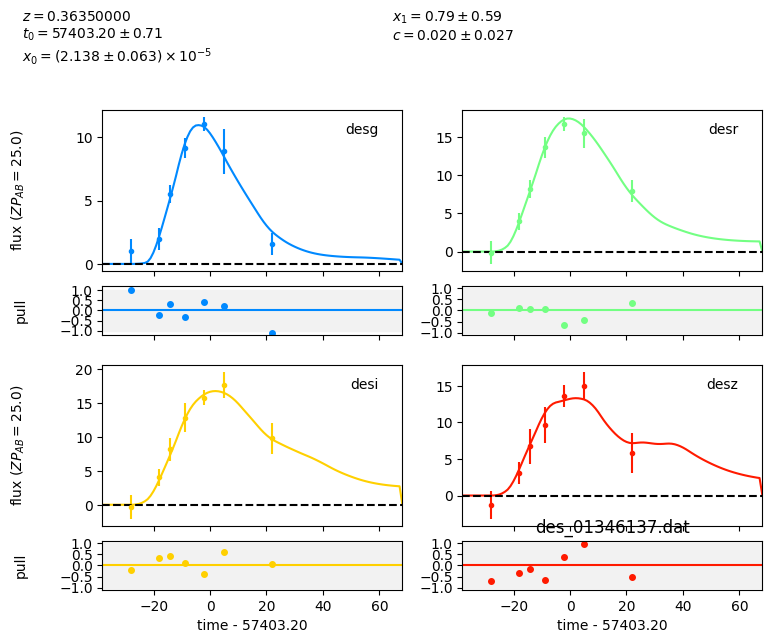

Processing: des_01346387.dat
Fitness within 2σ: 89.29%


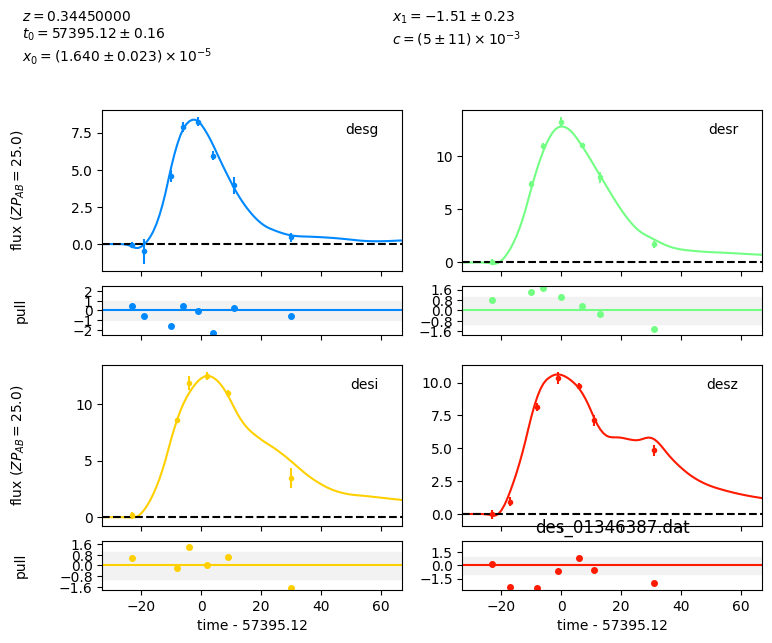

Processing: des_01346956.dat
Fitness within 2σ: 90.00%


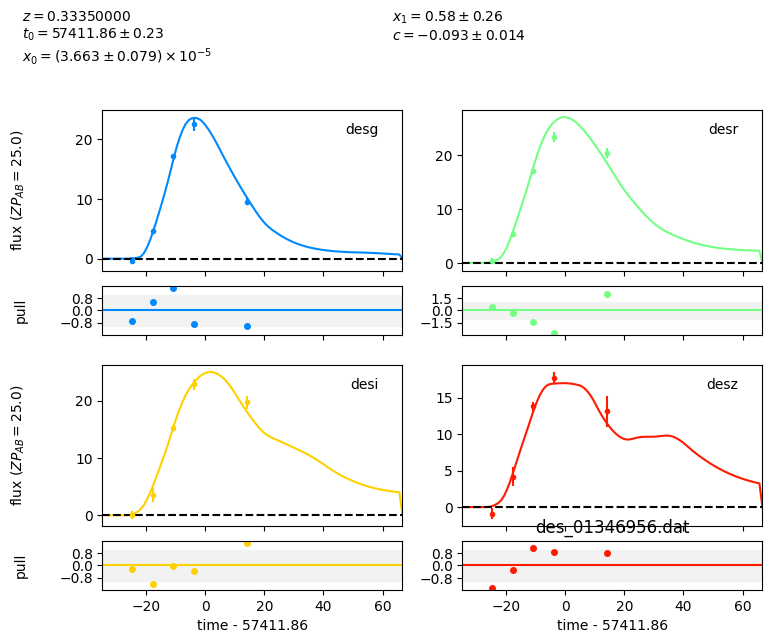

In [ ]:
# In this cell, we import the multiple supernova from drive, and have the list of all parameter correspond to each supernovae

import os

data_dir = '/content/drive/MyDrive/DES-SN'
results = []

for file in os.listdir(data_dir):
    if file.endswith('.dat'):
        full_path = os.path.join(data_dir, file)
        print(f"Processing: {file}")
        try:
            result, z, fitness_2sigma = fit_sn(full_path)



            results.append({
                'filename': file,
                'z': z,
                't0': result.parameters[1],
                'x0': result.parameters[2],
                'x1': result.parameters[3],
                'c': result.parameters[4],
                'chi2': result.chisq,
                'ndof': result.ndof,
                'errors': result.errors,
                'fitness_2sigma': fitness_2sigma


            })
        except Exception as e:
            print(f"Failed to process {file}: {e}")


# Plot's Explanation
 * Supernova emits light across the spectrum ranging from UV to infra-red. Therefore to capture the nature we used multi-filters, like griz---green-blue(400-500 nm), red(500-700 nm), infrared(700-850 nm), and depper infrared(850-1000nm).

 * The 'g' band fade faster since it has hotter emission
 * The other ones stays brighter longer due to cooler emission mostly due to foreground dust or in our own milkyway galaxy.
 * Analysing in all filter's helps to understand temperature evolution, energy output, distance inference and indeed the supernova physics.

 * The SALT-2 EXTENDED model has the algorithm to fit the data points most accurately by varying the parameters(x0,t0,x1,c).



===== des_01248677 (1).dat =====
Redshift: 0.3502
         time  band      flux  fluxerr    zp zpsys
0   56538.281  desz   67.6920   5.3595  27.5    ab
1   56538.340  desi   76.9530   3.6008  27.5    ab
2   56538.398  desr   88.7790   2.6651  27.5    ab
3   56543.247  desg  158.4800   2.6739  27.5    ab
4   56544.257  desz  132.0200   7.3078  27.5    ab
5   56545.228  desi  169.3100   3.8357  27.5    ab
6   56545.251  desr  199.7400   2.5468  27.5    ab
7   56547.281  desg  201.1300   2.8512  27.5    ab
8   56548.267  desz  156.2000   3.6443  27.5    ab
9   56552.357  desi  219.7700   8.6643  27.5    ab
10  56558.186  desz  160.6700   4.7563  27.5    ab
11  56558.245  desr  246.1300   4.5543  27.5    ab
12  56558.378  desi  230.0000   3.9383  27.5    ab
13  56559.182  desg  156.8600   7.5057  27.5    ab
14  56559.274  desi  229.6500   3.4292  27.5    ab
15  56563.281  desg  127.3800   3.3379  27.5    ab
16  56563.292  desz  150.1100   3.8257  27.5    ab
17  56564.238  desi  203.8200  

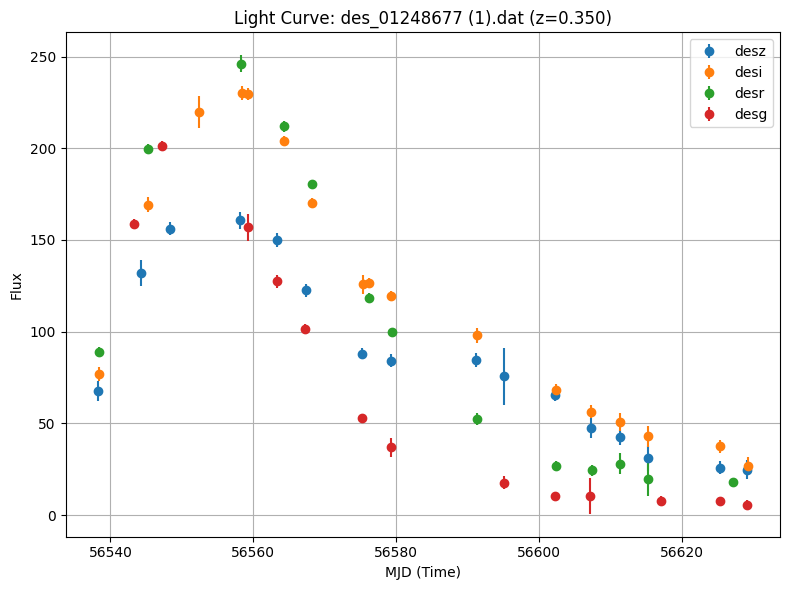


===== des_01250017.dat =====
Redshift: 0.1817
         time  band     flux  fluxerr    zp zpsys
0   56534.233  desg   16.680   8.3694  27.5    ab
1   56534.235  desr   26.022  12.4220  27.5    ab
2   56536.241  desg   70.062   8.4596  27.5    ab
3   56536.243  desr   38.585  27.8010  27.5    ab
4   56536.245  desi   51.432  24.4420  27.5    ab
5   56537.220  desg  101.340   9.2575  27.5    ab
6   56537.222  desr   93.470  12.7770  27.5    ab
7   56537.227  desz   47.509  18.9990  27.5    ab
8   56543.282  desg  486.450   7.0087  27.5    ab
9   56543.284  desr  432.100   9.9600  27.5    ab
10  56543.287  desi  395.250  11.0180  27.5    ab
11  56543.289  desz  307.200  11.7640  27.5    ab
12  56547.240  desg  706.300   9.0913  27.5    ab
13  56547.242  desr  643.490  11.2480  27.5    ab
14  56547.244  desi  513.150  11.0360  27.5    ab
15  56547.247  desz  361.420  11.4520  27.5    ab
16  56551.233  desr  763.400  24.8590  27.5    ab
17  56551.235  desi  570.790  23.1810  27.5    ab
18 

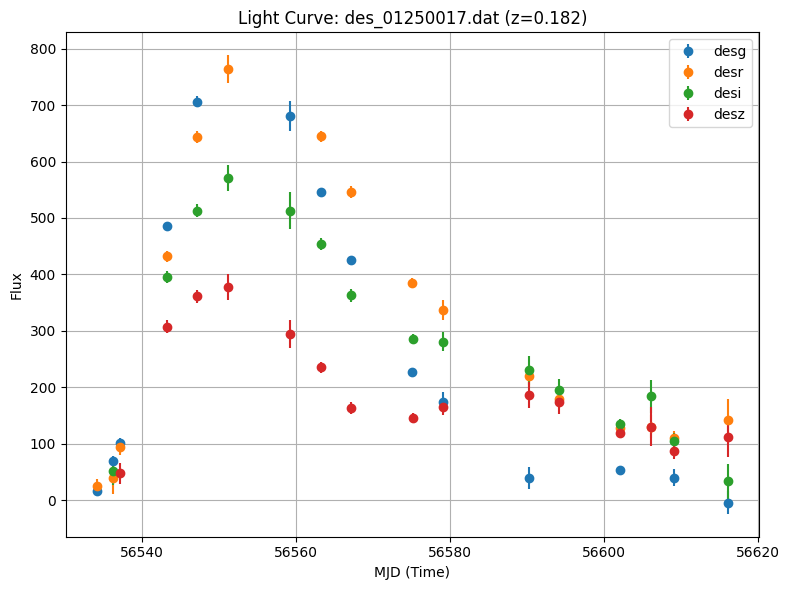


===== des_01253039.dat =====
Redshift: 0.4535
         time  band        flux   fluxerr    zp zpsys
0   56547.268  desg    1.329000    3.7015  27.5    ab
1   56547.270  desr    5.815300    4.9407  27.5    ab
2   56547.272  desi    0.078534    6.1593  27.5    ab
3   56547.274  desz    3.047200    7.7615  27.5    ab
4   56551.245  desg    9.990000   23.0790  27.5    ab
5   56551.247  desr   -9.954000   19.4870  27.5    ab
6   56551.249  desi   26.229000   14.8150  27.5    ab
7   56551.252  desz  -29.724000   13.5660  27.5    ab
8   56552.271  desg   33.311000   19.3840  27.5    ab
9   56552.274  desr    5.462300   14.2550  27.5    ab
10  56552.276  desi   10.786000    9.2963  27.5    ab
11  56552.278  desz  -12.839000   10.3800  27.5    ab
12  56559.190  desg   57.331000   12.7160  27.5    ab
13  56559.193  desr   43.963000    9.6776  27.5    ab
14  56559.195  desi   36.011000    9.5455  27.5    ab
15  56559.198  desz   38.325000    8.5191  27.5    ab
16  56563.200  desg   67.005000    

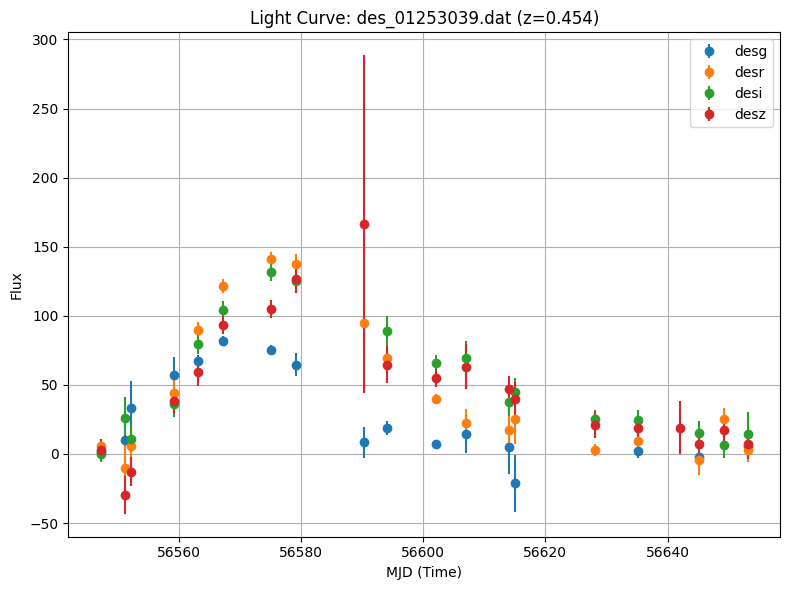


===== des_01253101.dat =====
Redshift: 0.4596
         time  band      flux  fluxerr    zp zpsys
0   56543.092  desg    5.7590   4.8371  27.5    ab
1   56543.094  desr   -3.9610   8.3988  27.5    ab
2   56543.096  desi    0.4310  10.3480  27.5    ab
3   56543.099  desz   -4.9610  14.0760  27.5    ab
4   56547.081  desg   -4.9170   9.6849  27.5    ab
5   56547.083  desr   -1.7850  10.0760  27.5    ab
6   56547.085  desi   15.5460   9.3344  27.5    ab
7   56547.087  desz    9.4420  10.7230  27.5    ab
8   56551.260  desg   -6.2940  22.7020  27.5    ab
9   56551.262  desr  -15.2150  18.7330  27.5    ab
10  56551.264  desi  -16.8990  17.6210  27.5    ab
11  56551.267  desz    4.8385  16.3170  27.5    ab
12  56558.052  desg    9.6939   3.7600  27.5    ab
13  56558.054  desr   30.8750   6.9969  27.5    ab
14  56558.056  desi   16.4920   7.5027  27.5    ab
15  56558.059  desz   42.5210   9.9609  27.5    ab
16  56563.037  desg   23.9460   4.9284  27.5    ab
17  56563.039  desr   63.4410   9.1

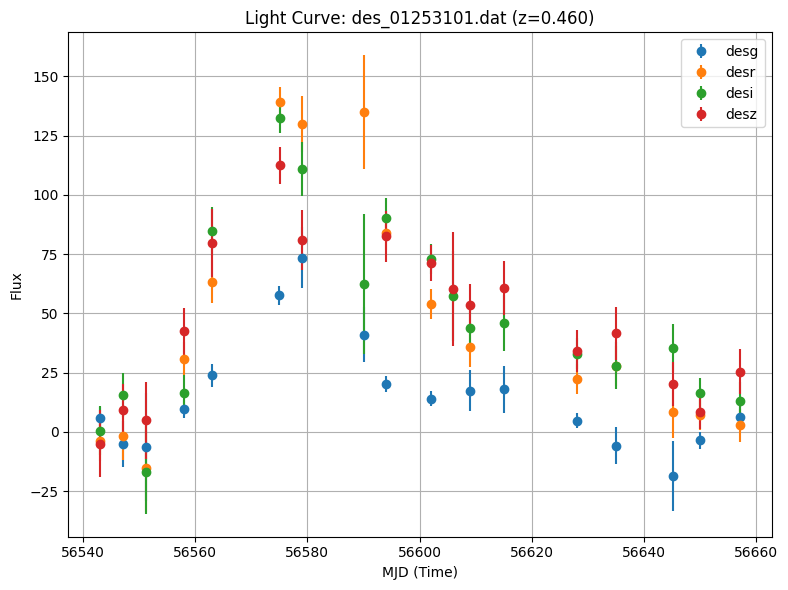


===== des_01253920.dat =====
Redshift: 0.1956
         time  band      flux  fluxerr    zp zpsys
0   56559.190  desg    6.1980  14.7790  27.5    ab
1   56559.193  desr    8.5890  13.9590  27.5    ab
2   56559.195  desi   -3.1920  14.4500  27.5    ab
3   56559.198  desz   -1.1460  14.1490  27.5    ab
4   56563.200  desg    5.9050   5.3578  27.5    ab
5   56563.203  desr    2.0278   7.9410  27.5    ab
6   56563.205  desi    1.0364  10.9890  27.5    ab
7   56563.207  desz   -3.2390  14.3970  27.5    ab
8   56567.219  desg   68.5930   4.8309  27.5    ab
9   56567.222  desr   66.3390   6.9539  27.5    ab
10  56567.224  desi   64.4520   9.5113  27.5    ab
11  56567.224  desz   52.0320  15.0110  27.5    ab
12  56575.191  desg  504.2300   7.0743  27.5    ab
13  56575.194  desr  423.4800   8.7888  27.5    ab
14  56575.196  desi  392.7300  10.0960  27.5    ab
15  56575.199  desz  302.0600  10.7720  27.5    ab
16  56579.181  desg  652.2700  11.7300  27.5    ab
17  56579.183  desr  549.9400  12.5

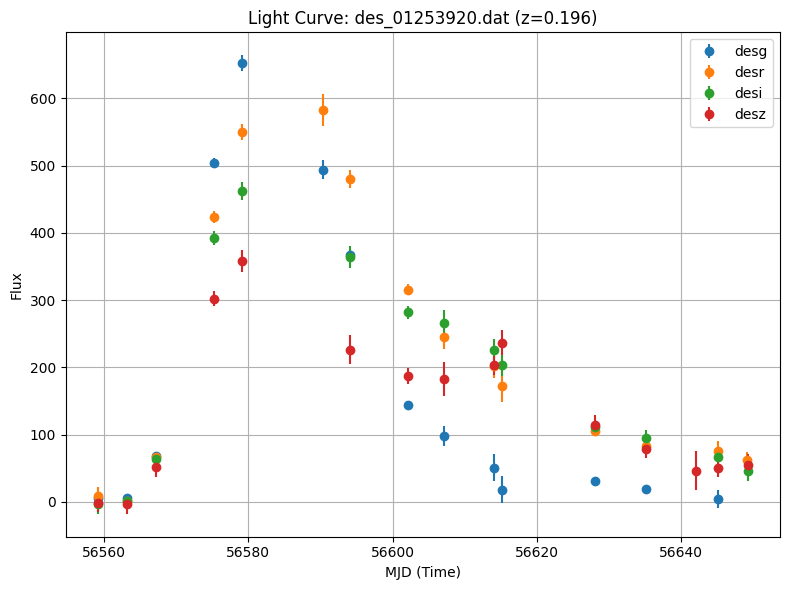


===== des_01255502.dat =====
Redshift: 0.1482
         time  band     flux   fluxerr    zp zpsys
0   56563.266  desz   -6.758   14.8190  27.5    ab
1   56567.164  desz   -5.697   18.0820  27.5    ab
2   56575.143  desz  107.370   11.0340  27.5    ab
3   56579.125  desg  551.420   19.2590  27.5    ab
4   56579.128  desr  516.010   18.6220  27.5    ab
5   56579.133  desz  333.110   15.4740  27.5    ab
6   56591.081  desi  955.100   22.6640  27.5    ab
7   56591.084  desz  723.110   22.1250  27.5    ab
8   56595.087  desi  999.700   53.6550  27.5    ab
9   56595.088  desz  666.890   58.5360  27.5    ab
10  56602.069  desz  508.270   16.9220  27.5    ab
11  56607.041  desz  502.020   35.7390  27.5    ab
12  56615.023  desg  399.010   14.4340  27.5    ab
13  56615.025  desr  722.480   19.6800  27.5    ab
14  56615.032  desz   86.672  115.6500  27.5    ab
15  56618.038  desz  402.740   15.7720  27.5    ab
16  56627.059  desz  443.070   15.7210  27.5    ab
17  56635.054  desg  115.760    9.0

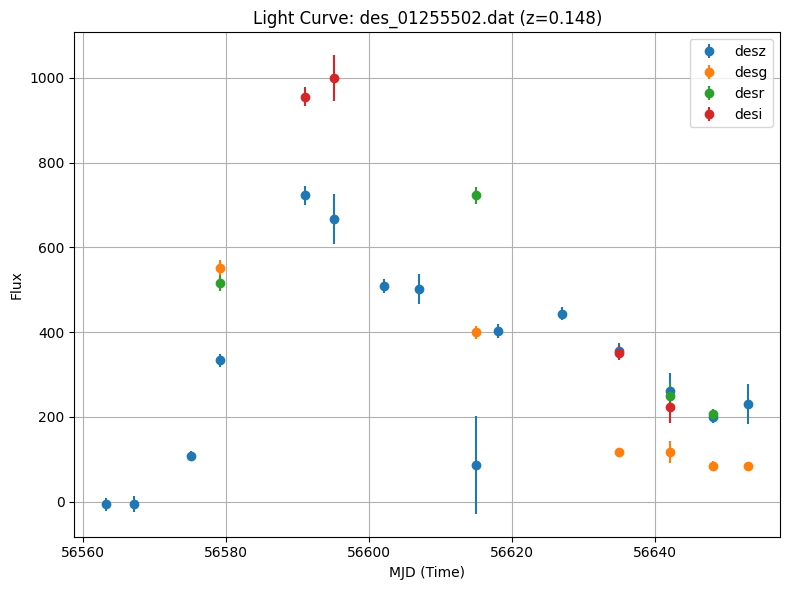


===== des_01257366.dat =====
Redshift: 0.2114
         time  band     flux  fluxerr    zp zpsys
0   56590.341  desg    5.192   14.777  27.5    ab
1   56590.343  desr  -30.065   25.696  27.5    ab
2   56594.140  desz   29.636   22.333  27.5    ab
3   56602.123  desi  204.050   12.978  27.5    ab
4   56602.125  desz  177.850   12.483  27.5    ab
5   56607.055  desg  262.140   17.919  27.5    ab
6   56607.062  desz  272.650   30.555  27.5    ab
7   56614.073  desg  263.600   31.332  27.5    ab
8   56614.075  desr  352.390   22.747  27.5    ab
9   56614.078  desi  320.270   21.486  27.5    ab
10  56614.080  desz  220.360   16.938  27.5    ab
11  56615.096  desg  251.750   20.694  27.5    ab
12  56615.098  desr  355.500   27.152  27.5    ab
13  56615.101  desi  313.360   21.983  27.5    ab
14  56615.105  desz  170.700   26.170  27.5    ab
15  56628.080  desi  187.100   15.582  27.5    ab
16  56628.083  desz  112.090   17.758  27.5    ab
17  56635.132  desi  186.020   16.786  27.5    ab
18 

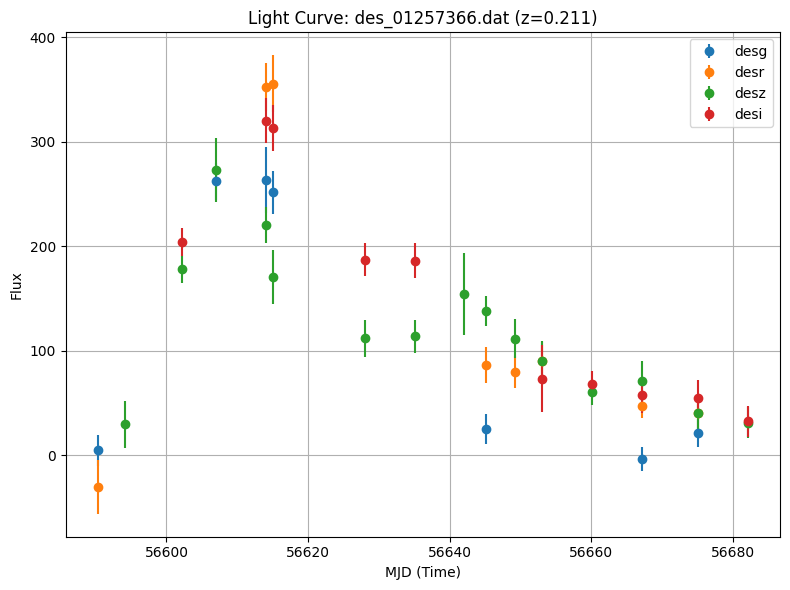


===== des_01257695.dat =====
Redshift: 0.1838
         time  band      flux  fluxerr    zp zpsys
0   56590.025  desg    8.4692  13.2780  27.5    ab
1   56590.027  desr   -7.9560  26.3130  27.5    ab
2   56590.029  desi  -12.3490  27.5540  27.5    ab
3   56594.026  desg   35.6690   4.1147  27.5    ab
4   56594.028  desr   29.0850   8.1419  27.5    ab
5   56594.030  desi   40.3660  10.7350  27.5    ab
6   56594.033  desz   28.6640  12.7440  27.5    ab
7   56602.027  desg  440.6800   6.1863  27.5    ab
8   56602.029  desr  361.8000   7.9301  27.5    ab
9   56602.031  desi  321.5300   8.1698  27.5    ab
10  56602.034  desz  258.0700   8.8598  27.5    ab
11  56606.041  desi  540.3000  23.5120  27.5    ab
12  56606.044  desz  393.0700  22.8420  27.5    ab
13  56609.040  desg  868.9700  12.1150  27.5    ab
14  56609.042  desr  735.8200  11.6580  27.5    ab
15  56609.044  desi  569.8300  11.1430  27.5    ab
16  56609.047  desz  445.2200   9.8594  27.5    ab
17  56615.081  desg  876.1000  13.7

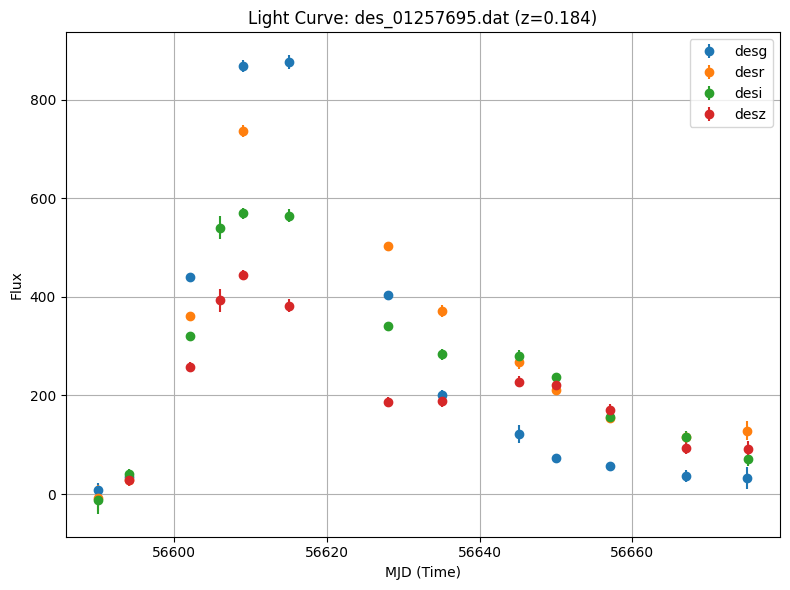


===== des_01258906.dat =====
Redshift: 0.3492
         time  band      flux  fluxerr    zp zpsys
0   56594.012  desg   -4.7570   5.0016  27.5    ab
1   56594.015  desr   -5.8730   7.1504  27.5    ab
2   56594.017  desi   -0.8840   9.8930  27.5    ab
3   56594.019  desz   -6.7580  12.2780  27.5    ab
4   56602.013  desg    8.2617   4.1044  27.5    ab
5   56602.016  desr   15.5300   6.1473  27.5    ab
6   56602.018  desi   14.3280   7.4527  27.5    ab
7   56602.021  desz   12.9470  10.9990  27.5    ab
8   56606.025  desr   49.3470  14.5910  27.5    ab
9   56606.028  desz   99.6860  37.1310  27.5    ab
10  56609.026  desg   38.9120   9.3535  27.5    ab
11  56609.029  desr   82.9190   9.1409  27.5    ab
12  56609.031  desi   74.1220   9.4130  27.5    ab
13  56609.034  desz   79.0030  10.2540  27.5    ab
14  56615.068  desg   92.4390   9.2072  27.5    ab
15  56615.070  desr  155.1600  10.9940  27.5    ab
16  56615.072  desi  137.0100   9.9496  27.5    ab
17  56615.074  desz  123.5800  10.7

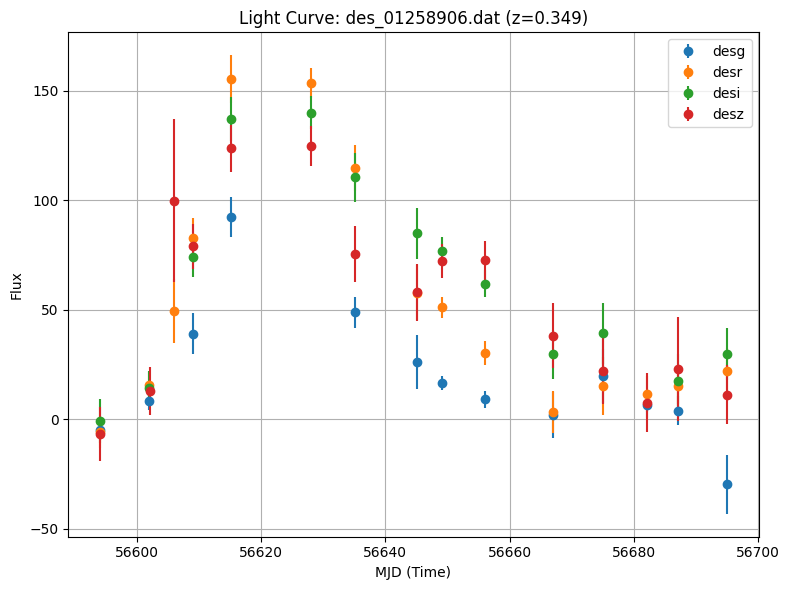


===== des_01258940.dat =====
Redshift: 0.4259
         time  band      flux  fluxerr    zp zpsys
0   56590.311  desg   17.9720  17.6530  27.5    ab
1   56590.313  desr   -6.7620  15.8820  27.5    ab
2   56590.315  desi    8.6160  21.5550  27.5    ab
3   56590.318  desz   22.5160  17.2520  27.5    ab
4   56594.118  desg   16.7400   9.3636  27.5    ab
5   56594.121  desr    3.5080  11.1020  27.5    ab
6   56594.123  desi    3.2273  14.9480  27.5    ab
7   56594.126  desz  -10.1000  17.3310  27.5    ab
8   56602.091  desg   15.3580   4.3010  27.5    ab
9   56602.093  desr   32.8570   4.9185  27.5    ab
10  56602.095  desi   28.7570   6.7308  27.5    ab
11  56602.098  desz   19.3870   7.8131  27.5    ab
12  56606.083  desr   78.5920  16.5650  27.5    ab
13  56606.085  desi   95.5570  21.0480  27.5    ab
14  56606.089  desz   84.2040  28.2730  27.5    ab
15  56609.082  desg   53.4250  11.6740  27.5    ab
16  56609.085  desr   84.0120  10.6430  27.5    ab
17  56609.087  desi   85.1430  12.5

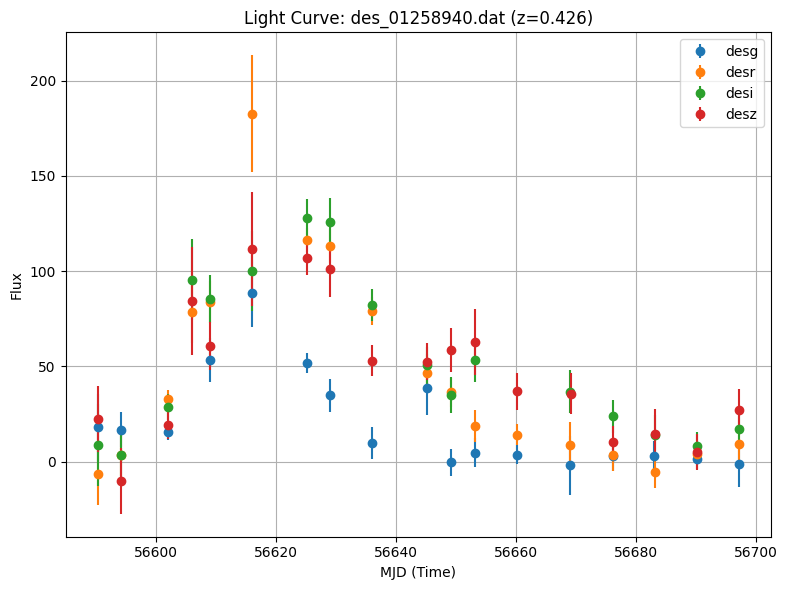


===== des_01259412.dat =====
Redshift: 0.3047
         time  band      flux  fluxerr    zp zpsys
0   56602.144  desg    7.6880   2.4262  27.5    ab
1   56602.205  desz    7.0480   5.0642  27.5    ab
2   56602.251  desi   11.6870   4.5663  27.5    ab
3   56603.052  desr   16.1200   4.1155  27.5    ab
4   56607.158  desg   35.3170   8.0215  27.5    ab
5   56608.133  desz   64.6080   5.8979  27.5    ab
6   56608.206  desi   77.0490   5.6199  27.5    ab
7   56615.109  desz  149.2500  10.3240  27.5    ab
8   56615.207  desi  194.0300   9.4504  27.5    ab
9   56616.087  desr  241.3400  38.0630  27.5    ab
10  56617.033  desg  217.4000   3.8917  27.5    ab
11  56627.064  desg  211.6600   3.1868  27.5    ab
12  56627.072  desz  159.1100   3.9229  27.5    ab
13  56627.116  desi  268.5200   6.1817  27.5    ab
14  56627.161  desr  266.1500   3.3404  27.5    ab
15  56635.141  desg  142.8000   5.0198  27.5    ab
16  56635.149  desz  132.6200   7.5277  27.5    ab
17  56636.104  desi  209.2700   4.9

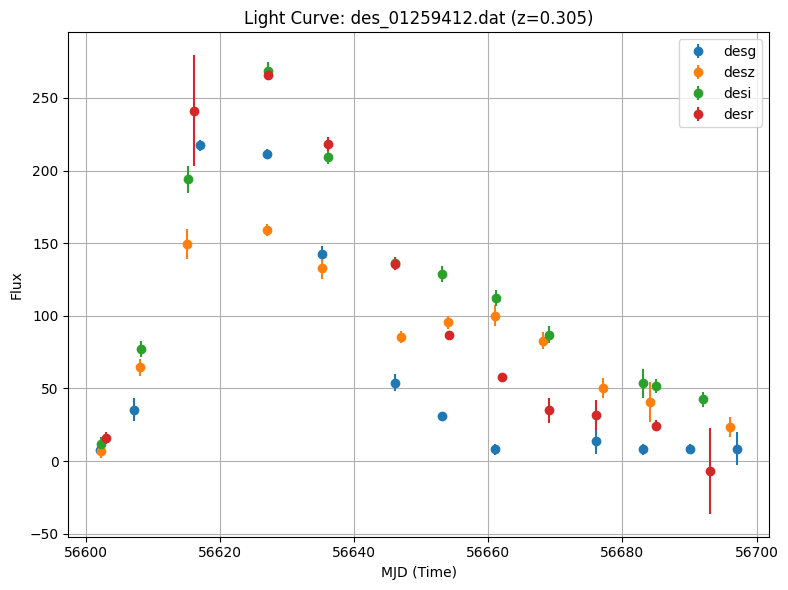


===== des_01261579.dat =====
Redshift: 0.3222
         time  band      flux  fluxerr    zp zpsys
0   56615.111  desz    4.7966   8.9629  27.5    ab
1   56615.206  desi   -8.4750   7.8033  27.5    ab
2   56616.087  desr  -46.1150  20.3680  27.5    ab
3   56617.033  desg   -1.5290   2.2508  27.5    ab
4   56627.064  desg  100.4900   2.0363  27.5    ab
5   56627.072  desz  110.7900   4.0250  27.5    ab
6   56627.119  desi  119.6500   3.3504  27.5    ab
7   56627.161  desr  123.7900   2.2099  27.5    ab
8   56635.141  desg  170.1400   4.1343  27.5    ab
9   56635.151  desz  150.3900   7.1956  27.5    ab
10  56636.104  desi  217.0500   4.0003  27.5    ab
11  56636.153  desr  222.9000   3.6583  27.5    ab
12  56646.077  desg  114.8300   3.4346  27.5    ab
13  56646.086  desi  211.0500   3.4399  27.5    ab
14  56646.110  desr  205.0800   3.4533  27.5    ab
15  56647.047  desz  141.7500   3.7176  27.5    ab
16  56653.114  desg   66.3440   2.7113  27.5    ab
17  56653.123  desi  155.9600   4.5

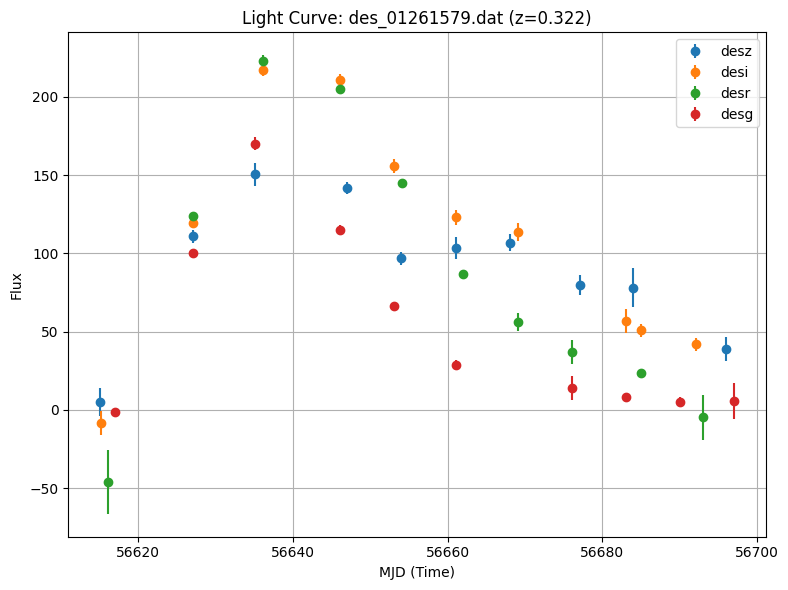


===== des_01262214.dat =====
Redshift: 0.6894
         time  band     flux  fluxerr    zp zpsys
0   56625.224  desg  -0.6500   1.6033  27.5    ab
1   56625.281  desi  -1.5560   2.6783  27.5    ab
2   56627.145  desr   1.8842   1.1277  27.5    ab
3   56628.062  desg  -0.6950   3.6968  27.5    ab
4   56628.065  desr   5.2096   4.4478  27.5    ab
5   56628.067  desi  -1.8730   6.0062  27.5    ab
6   56629.052  desg  -2.6980   2.5330  27.5    ab
7   56629.124  desi  -0.9490   3.7229  27.5    ab
8   56635.114  desg   1.8239   5.0962  27.5    ab
9   56635.116  desr  12.6540   4.9817  27.5    ab
10  56635.118  desi  11.8190   6.3139  27.5    ab
11  56635.198  desr   8.6785   1.7408  27.5    ab
12  56635.258  desg   2.2137   2.0791  27.5    ab
13  56636.128  desi   9.4945   2.5890  27.5    ab
14  56645.064  desg   3.0627   8.8911  27.5    ab
15  56645.067  desr  38.6480   7.6680  27.5    ab
16  56645.069  desi  49.2200   7.5251  27.5    ab
17  56645.151  desi  38.0260   3.0322  27.5    ab
18 

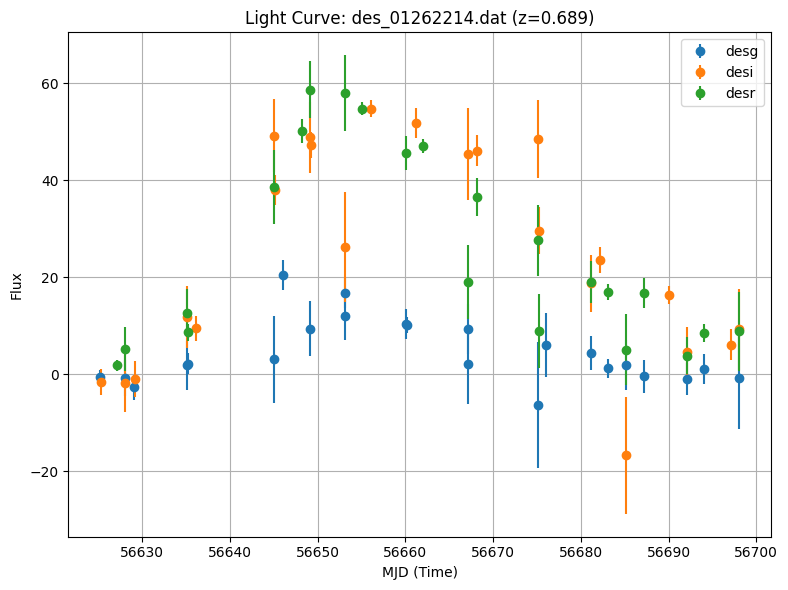


===== des_01262715.dat =====
Redshift: 0.6894
         time  band      flux  fluxerr    zp zpsys
0   56625.224  desg   1.39000   1.3888  27.5    ab
1   56625.228  desz  -0.45400   4.5693  27.5    ab
2   56625.281  desi  -3.10400   3.2738  27.5    ab
3   56627.145  desr   2.01630   1.1659  27.5    ab
4   56629.052  desg  -0.16300   2.2919  27.5    ab
5   56629.079  desz  -0.08600   5.7542  27.5    ab
6   56629.124  desi   1.59100   4.7481  27.5    ab
7   56635.198  desr   6.13600   1.6489  27.5    ab
8   56635.258  desg  -1.02400   1.9259  27.5    ab
9   56636.058  desz   4.73400   3.7388  27.5    ab
10  56636.127  desi   4.82270   2.9574  27.5    ab
11  56641.075  desz  23.49200   5.0554  27.5    ab
12  56645.151  desi  37.90400   3.6154  27.5    ab
13  56646.067  desg  17.37000   2.7507  27.5    ab
14  56648.044  desz  41.90800   6.6235  27.5    ab
15  56648.209  desr  53.77500   2.5089  27.5    ab
16  56649.182  desi  50.01300   3.3300  27.5    ab
17  56653.062  desg  13.83600   2.7

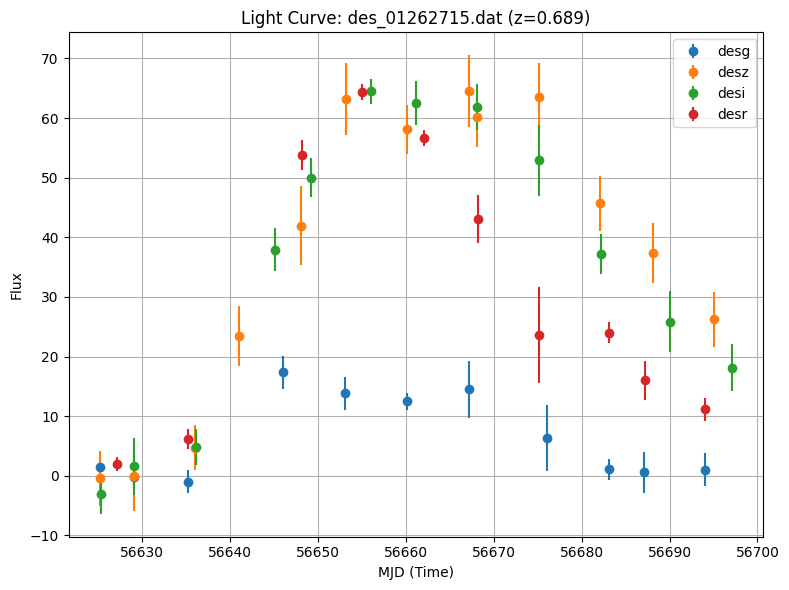


===== des_01263369.dat =====
Redshift: 0.3125
         time  band       flux  fluxerr    zp zpsys
0   56645.136  desg   16.51000  16.7040  27.5    ab
1   56645.138  desr    7.34250  12.6200  27.5    ab
2   56645.140  desi    0.77591  14.6450  27.5    ab
3   56645.143  desz   16.12200  12.2140  27.5    ab
4   56649.132  desg   37.27000   7.0039  27.5    ab
5   56649.134  desr   39.19800   9.3785  27.5    ab
6   56649.136  desi   39.82400  15.2460  27.5    ab
7   56649.139  desz   57.53400  14.5680  27.5    ab
8   56653.147  desg  109.90000   7.8528  27.5    ab
9   56653.149  desr  118.36000  10.7940  27.5    ab
10  56653.151  desi  100.69000  16.9460  27.5    ab
11  56653.153  desz   93.06300  23.5850  27.5    ab
12  56660.061  desg  185.65000   5.6012  27.5    ab
13  56660.063  desr  219.94000   7.6241  27.5    ab
14  56660.065  desi  178.62000  12.9390  27.5    ab
15  56660.068  desz  168.85000  13.3970  27.5    ab
16  56669.044  desg  167.57000  17.7430  27.5    ab
17  56669.046  de

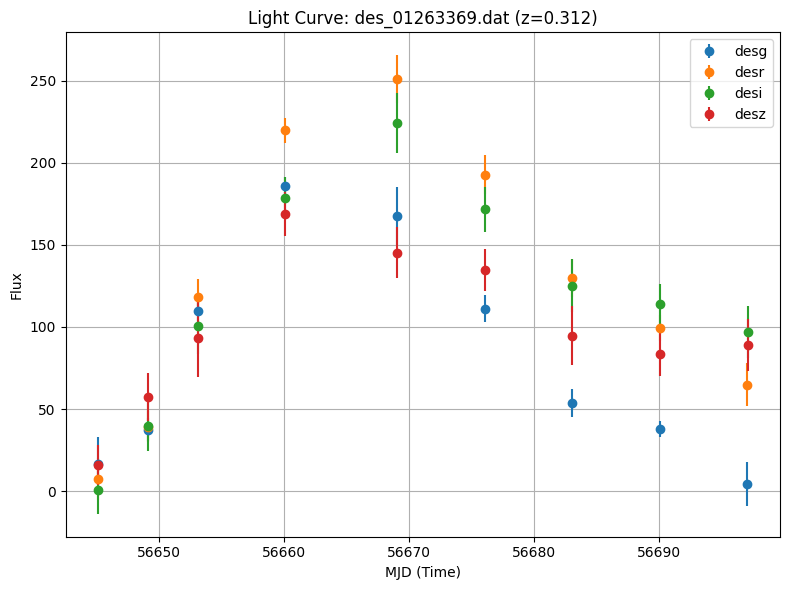


===== des_01263715.dat =====
Redshift: 0.2919
         time  band     flux  fluxerr    zp zpsys
0   56645.050  desg    6.095  11.0750  27.5    ab
1   56645.052  desr    2.439   9.0871  27.5    ab
2   56645.054  desi   -1.316   8.9811  27.5    ab
3   56645.057  desz    5.853   8.2781  27.5    ab
4   56649.118  desg   21.370   6.3087  27.5    ab
5   56649.121  desr   40.816   6.5926  27.5    ab
6   56649.123  desi   43.030  11.5590  27.5    ab
7   56649.126  desz   33.883  11.8150  27.5    ab
8   56653.102  desr  108.580   8.4233  27.5    ab
9   56653.104  desi  115.540   8.9405  27.5    ab
10  56653.107  desz  108.830  10.7160  27.5    ab
11  56660.047  desg  223.160   6.9357  27.5    ab
12  56660.050  desr  239.990   6.7435  27.5    ab
13  56660.052  desi  216.840   7.7916  27.5    ab
14  56660.049  desz  171.280  13.4620  27.5    ab
15  56667.088  desg  199.270  28.3390  27.5    ab
16  56667.091  desr  221.420  33.9790  27.5    ab
17  56667.093  desi  284.190  16.6750  27.5    ab
18 

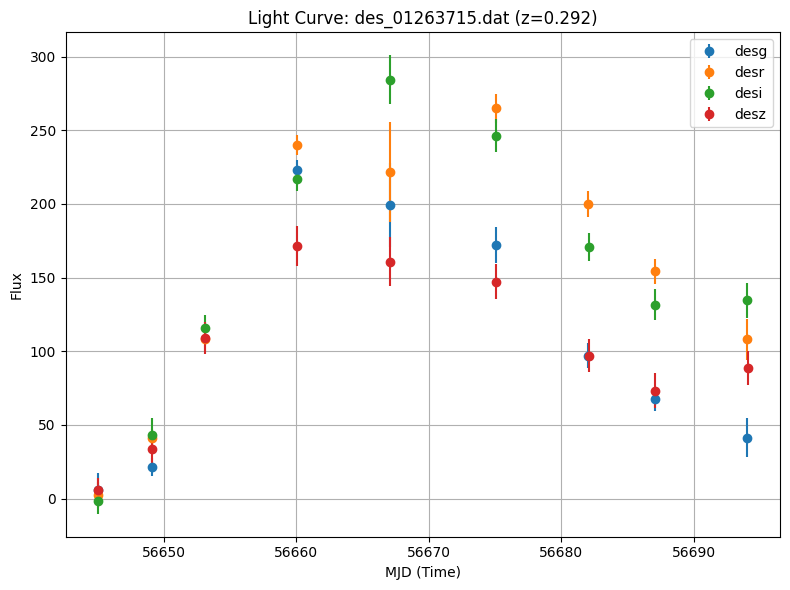


===== des_01275946.dat =====
Redshift: 0.2321
         time  band     flux  fluxerr    zp zpsys
0   57248.373  desg  271.920   7.8635  27.5    ab
1   57248.375  desr  264.660  10.0950  27.5    ab
2   57248.378  desi  224.550  16.1730  27.5    ab
3   57248.380  desz  151.080  16.8630  27.5    ab
4   57252.215  desg  416.450   5.7796  27.5    ab
5   57252.218  desr  409.260   6.2769  27.5    ab
6   57252.220  desi  334.980   8.0161  27.5    ab
7   57252.222  desz  253.780   8.5428  27.5    ab
8   57256.225  desr  528.340  11.9110  27.5    ab
9   57256.227  desi  403.060  15.2010  27.5    ab
10  57256.229  desz  237.080  15.2720  27.5    ab
11  57257.225  desg  542.870   8.8783  27.5    ab
12  57257.227  desr  539.140  12.0460  27.5    ab
13  57257.229  desi  428.260  12.7430  27.5    ab
14  57257.232  desz  279.680  11.9530  27.5    ab
15  57265.223  desg  382.490  22.5490  27.5    ab
16  57265.225  desr  554.180  16.6330  27.5    ab
17  57265.227  desi  469.750  12.7780  27.5    ab
18 

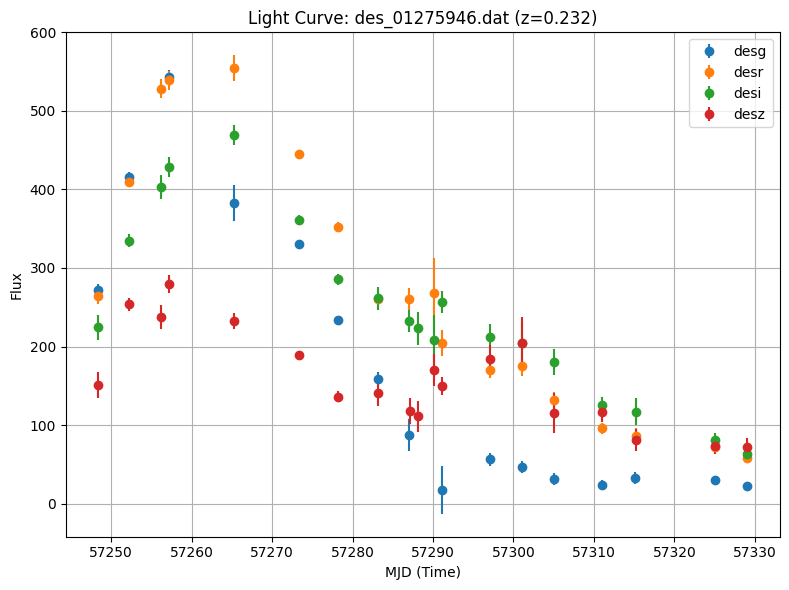


===== des_01279500.dat =====
Redshift: 0.235
         time  band     flux  fluxerr    zp zpsys
0   57249.293  desg  375.220   6.5986  27.5    ab
1   57249.302  desr  409.180   5.3846  27.5    ab
2   57249.318  desi  367.860   6.4098  27.5    ab
3   57249.341  desz  228.830   6.5371  27.5    ab
4   57253.343  desg  372.800   4.8574  27.5    ab
5   57253.352  desr  414.010   4.7924  27.5    ab
6   57253.373  desi  379.190   6.0654  27.5    ab
7   57255.289  desz  204.360   9.4670  27.5    ab
8   57257.322  desg  311.450   5.7693  27.5    ab
9   57257.332  desr  394.090   4.6934  27.5    ab
10  57257.352  desi  360.670   5.3389  27.5    ab
11  57265.240  desz  133.380   9.1316  27.5    ab
12  57265.392  desi  266.760   9.4113  27.5    ab
13  57273.342  desi  191.450   5.7588  27.5    ab
14  57273.364  desz  106.890   6.0076  27.5    ab
15  57278.217  desr  167.290   4.3069  27.5    ab
16  57278.257  desg   66.508   3.5609  27.5    ab
17  57283.189  desi  171.940   5.9010  27.5    ab
18  

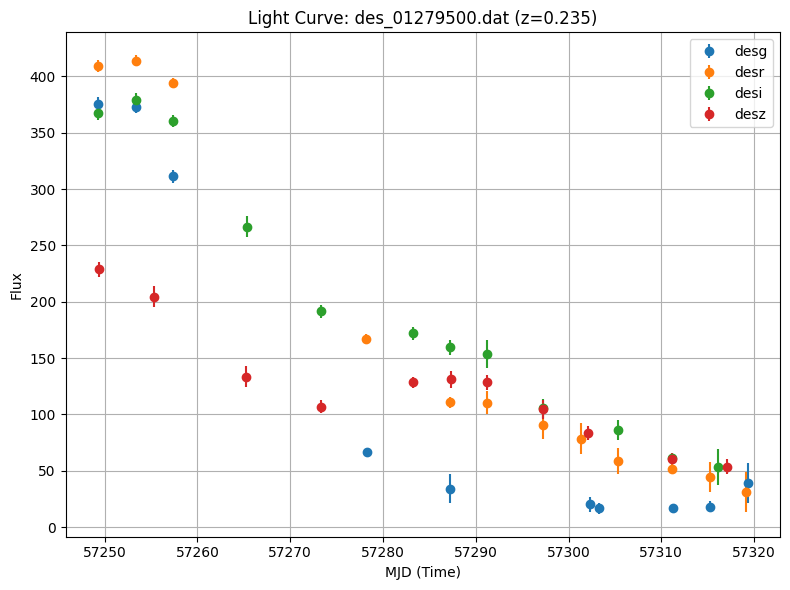


===== des_01280217.dat =====
Redshift: 0.359
         time  band      flux  fluxerr    zp zpsys
0   57248.388  desg  109.7700   8.4467  27.5    ab
1   57248.391  desr  154.0600   9.6932  27.5    ab
2   57248.393  desi  166.1800  13.6110  27.5    ab
3   57248.395  desz  143.5800  17.8150  27.5    ab
4   57252.303  desg  101.3000   6.3749  27.5    ab
5   57252.305  desr  179.6500   7.5312  27.5    ab
6   57252.307  desi  149.6100   9.9740  27.5    ab
7   57252.310  desz  144.3100  13.2420  27.5    ab
8   57256.292  desg   75.1220   8.3173  27.5    ab
9   57256.295  desr  158.2000  10.8810  27.5    ab
10  57256.297  desi  170.1400  11.0760  27.5    ab
11  57256.299  desz  116.3900  16.6320  27.5    ab
12  57265.286  desg   -0.2480  30.5780  27.5    ab
13  57265.288  desr   76.7640  19.5190  27.5    ab
14  57265.291  desi  143.2300  14.5350  27.5    ab
15  57265.293  desz  101.4500  11.3410  27.5    ab
16  57276.312  desr   68.8470  11.4010  27.5    ab
17  57276.314  desi  108.0600   8.25

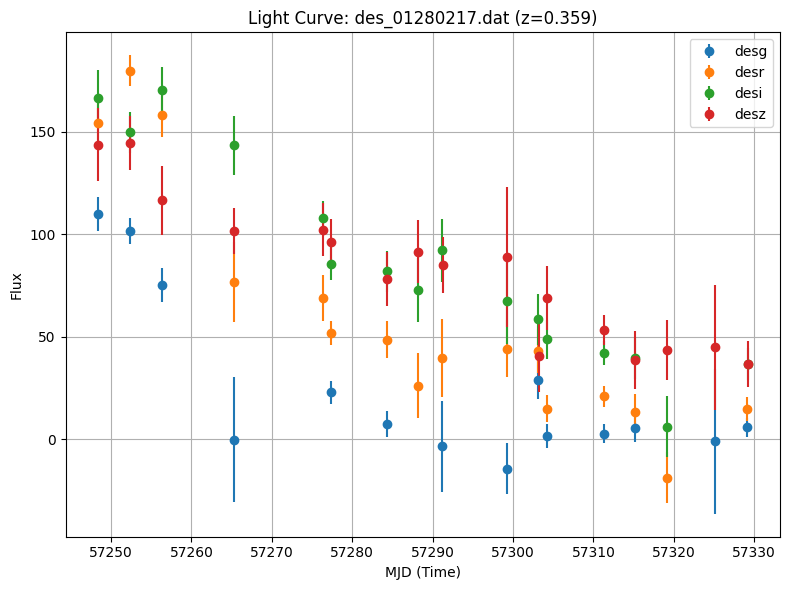


===== des_01281668.dat =====
Redshift: 0.3071
         time  band      flux  fluxerr    zp zpsys
0   57248.373  desg   20.3630   9.2266  27.5    ab
1   57248.375  desr   25.9850  13.2880  27.5    ab
2   57248.378  desi   23.1860  20.7730  27.5    ab
3   57248.380  desz   33.5190  26.2150  27.5    ab
4   57252.215  desg   14.1120   5.2968  27.5    ab
5   57252.218  desr   32.0520   6.0710  27.5    ab
6   57252.220  desi   12.1480   9.6533  27.5    ab
7   57252.222  desz   21.3750  12.7860  27.5    ab
8   57256.222  desg   82.1290   9.1002  27.5    ab
9   57256.225  desr   85.7700  14.4860  27.5    ab
10  57256.227  desi   79.9270  20.6490  27.5    ab
11  57256.229  desz  102.1200  25.4490  27.5    ab
12  57257.225  desg   93.8310   9.1182  27.5    ab
13  57257.227  desr   98.7360  14.0970  27.5    ab
14  57257.229  desi  122.6100  16.4950  27.5    ab
15  57257.232  desz   83.2440  16.3400  27.5    ab
16  57265.223  desg  233.1800  32.2570  27.5    ab
17  57265.225  desr  259.9500  19.6

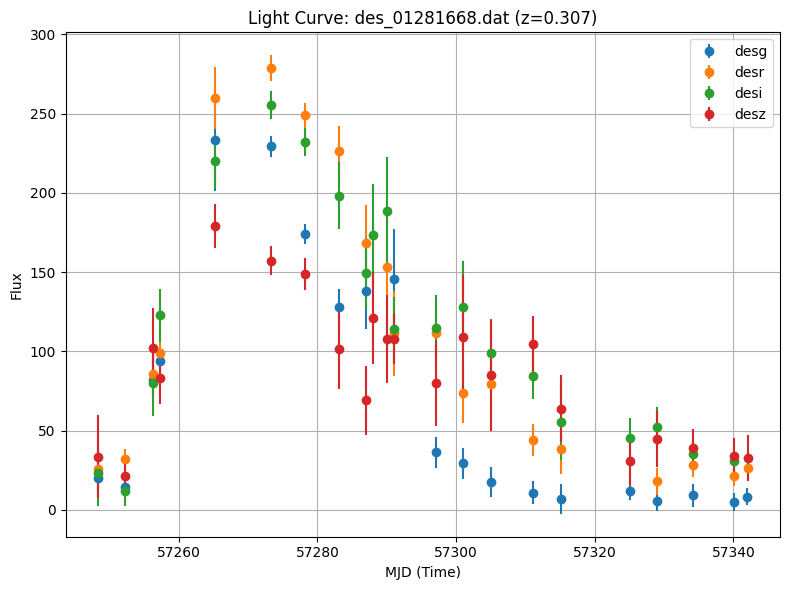


===== des_01281886.dat =====
Redshift: 0.384
         time  band     flux  fluxerr    zp zpsys
0   57248.388  desg    1.056   8.4812  27.5    ab
1   57248.391  desr   20.258  14.2370  27.5    ab
2   57248.393  desi   21.429  16.0260  27.5    ab
3   57248.395  desz   10.248  19.3440  27.5    ab
4   57252.303  desg   50.166   6.0869  27.5    ab
5   57252.305  desr   70.102   9.6242  27.5    ab
6   57252.307  desi   54.624  11.8280  27.5    ab
7   57252.310  desz   63.368  16.9030  27.5    ab
8   57256.292  desg   81.009   8.8752  27.5    ab
9   57256.295  desr   96.025  13.7970  27.5    ab
10  57256.297  desi  125.920  14.4550  27.5    ab
11  57256.300  desz   53.081  20.2980  27.5    ab
12  57265.286  desg   94.177  34.2370  27.5    ab
13  57265.288  desr  130.560  23.7350  27.5    ab
14  57265.291  desi  175.470  18.2940  27.5    ab
15  57265.293  desz  103.090  13.7670  27.5    ab
16  57276.312  desr  148.010  18.5830  27.5    ab
17  57276.314  desi  156.850  11.7020  27.5    ab
18  

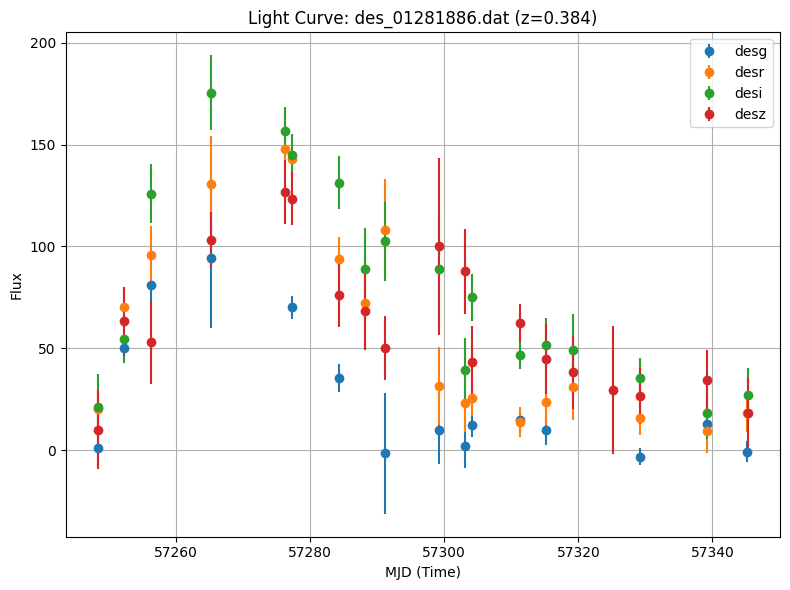


===== des_01282736.dat =====
Redshift: 0.3689
         time  band       flux   fluxerr    zp zpsys
0   57249.279  desg    2.32600    6.1700  27.5    ab
1   57249.281  desr   23.72500   10.2910  27.5    ab
2   57249.283  desi    6.64190   11.5800  27.5    ab
3   57249.286  desz   29.92200   13.2750  27.5    ab
4   57253.330  desg   26.06200    4.6778  27.5    ab
5   57253.332  desr   54.23000    8.6981  27.5    ab
6   57253.336  desz   63.93400   11.9260  27.5    ab
7   57257.267  desg   50.68200    6.7319  27.5    ab
8   57257.270  desr   84.14900   10.9410  27.5    ab
9   57257.272  desi   85.40600   10.8130  27.5    ab
10  57257.274  desz   78.25700   12.6840  27.5    ab
11  57265.378  desg   90.28800   33.3120  27.5    ab
12  57265.380  desr  112.26000   19.2520  27.5    ab
13  57265.382  desi  126.43000   14.8880  27.5    ab
14  57265.385  desz  106.24000   12.9260  27.5    ab
15  57273.328  desg   41.12300    4.4130  27.5    ab
16  57273.331  desr   98.00200    6.9638  27.5    ab

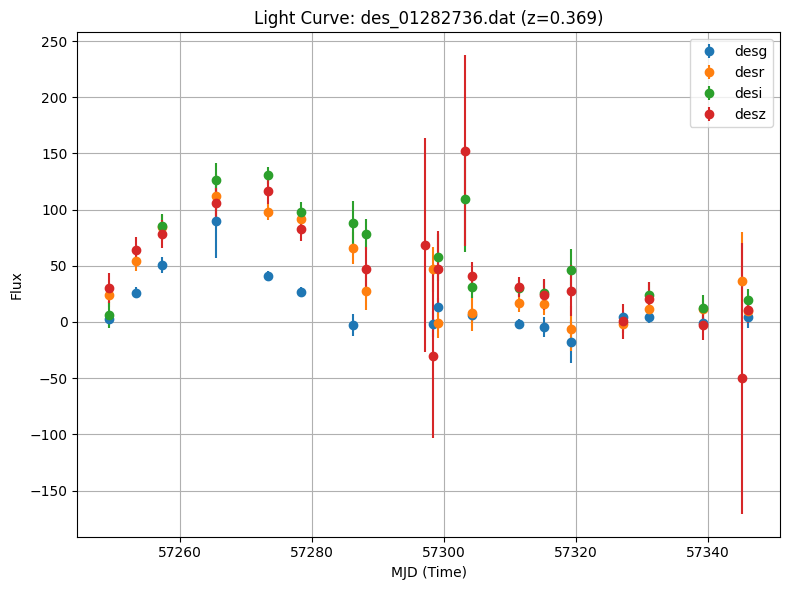


===== des_01283878.dat =====
Redshift: 0.3135
         time  band      flux  fluxerr    zp zpsys
0   57249.293  desg   13.7610   8.1570  27.5    ab
1   57249.305  desr   30.6780  27.3430  27.5    ab
2   57249.322  desi   27.4860  19.4900  27.5    ab
3   57249.341  desz   17.1630  23.3120  27.5    ab
4   57253.343  desg   66.1490   7.2486  27.5    ab
5   57253.352  desr   78.6000  13.9910  27.5    ab
6   57253.374  desi   85.5690  16.8970  27.5    ab
7   57255.288  desz   80.8440  32.2550  27.5    ab
8   57257.323  desg  109.4800   7.5352  27.5    ab
9   57257.331  desr  135.9900  17.2850  27.5    ab
10  57257.353  desi  139.4100  14.8140  27.5    ab
11  57265.238  desz  112.4900  34.3170  27.5    ab
12  57265.391  desi  184.7600  21.7770  27.5    ab
13  57273.341  desi  174.6900  16.9950  27.5    ab
14  57273.365  desz   98.4500  22.7000  27.5    ab
15  57278.219  desr  129.3500  17.6000  27.5    ab
16  57278.258  desg   58.7940   6.8464  27.5    ab
17  57283.189  desi  108.4400  14.9

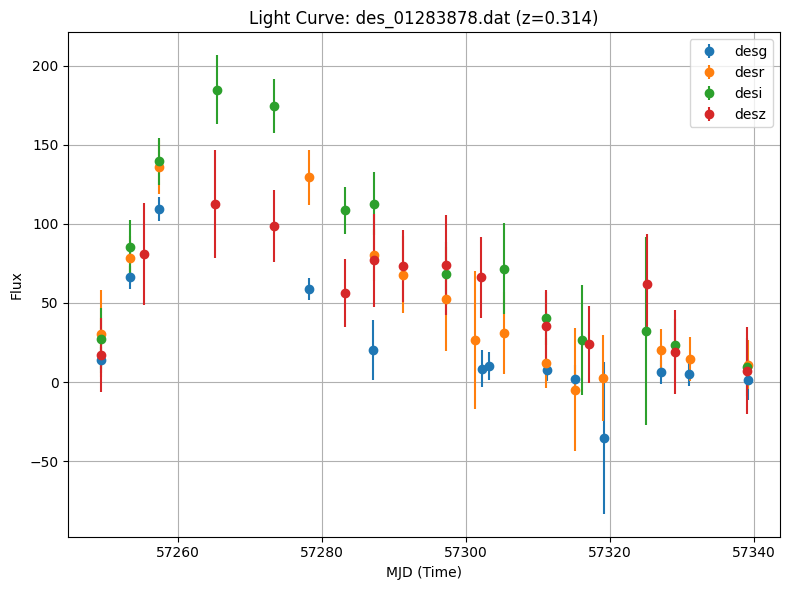


===== des_01283373.dat =====
Redshift: 0.2075
         time  band     flux  fluxerr    zp zpsys
0   57249.423  desg   -7.051   4.2667  27.5    ab
1   57250.330  desg   -4.267  16.2930  27.5    ab
2   57250.337  desz    0.108  39.2360  27.5    ab
3   57255.415  desi   85.497  16.8390  27.5    ab
4   57255.417  desz   74.045  26.0440  27.5    ab
5   57265.363  desg  412.120  25.2530  27.5    ab
6   57265.366  desr  414.870  20.2730  27.5    ab
7   57265.368  desi  336.770  18.6230  27.5    ab
8   57265.371  desz  218.620  15.3590  27.5    ab
9   57276.340  desg  250.600   6.9171  27.5    ab
10  57276.342  desr  395.760  12.0810  27.5    ab
11  57276.344  desi  284.290  16.6820  27.5    ab
12  57276.347  desz  126.600  19.3280  27.5    ab
13  57278.233  desg  234.870   6.4216  27.5    ab
14  57278.236  desr  354.290   9.8461  27.5    ab
15  57278.238  desi  247.100  12.7890  27.5    ab
16  57278.241  desz  107.560  14.8310  27.5    ab
17  57286.255  desr  220.700  13.5030  27.5    ab
18 

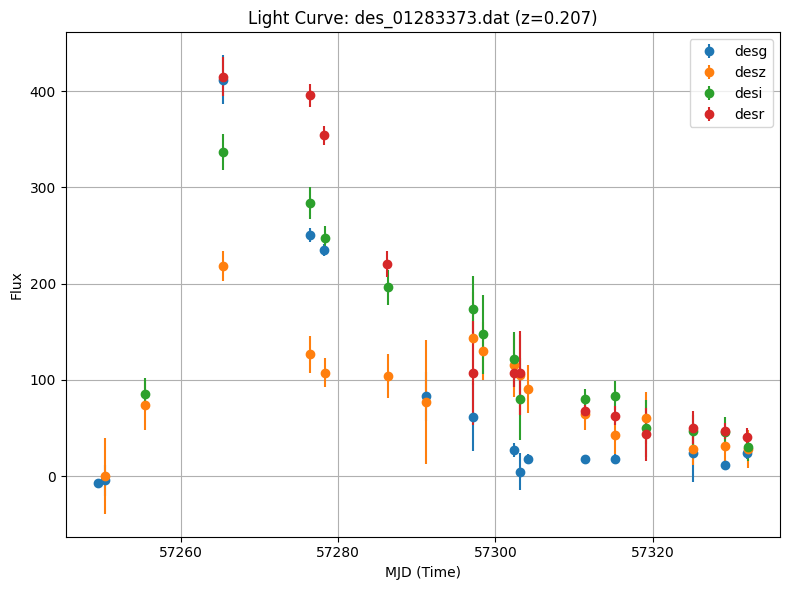


===== des_01346966.dat =====
Redshift: 0.3355
         time  band      flux  fluxerr    zp zpsys
0   57376.057  desr   -5.3940  23.9340  27.5    ab
1   57376.059  desi  -32.2960  26.6770  27.5    ab
2   57376.062  desz   30.0340  28.4810  27.5    ab
3   57379.073  desg  -19.4080  18.6780  27.5    ab
4   57379.076  desr   13.9660  15.8790  27.5    ab
5   57379.078  desi   -9.1900  13.1590  27.5    ab
6   57379.081  desz  -12.1810  12.6070  27.5    ab
7   57387.178  desg    1.4352   8.4766  27.5    ab
8   57387.181  desr   24.0030   8.7296  27.5    ab
9   57387.183  desi   11.7330  10.7920  27.5    ab
10  57387.185  desz   10.7370  11.7940  27.5    ab
11  57394.144  desg  112.1200   6.3229  27.5    ab
12  57394.146  desr  130.5000  10.9780  27.5    ab
13  57394.148  desi  105.1000  17.1480  27.5    ab
14  57394.151  desz   95.7310  18.2860  27.5    ab
15  57401.122  desg  224.2200   4.9501  27.5    ab
16  57401.125  desr  238.9700   6.8560  27.5    ab
17  57401.127  desi  220.3400   8.2

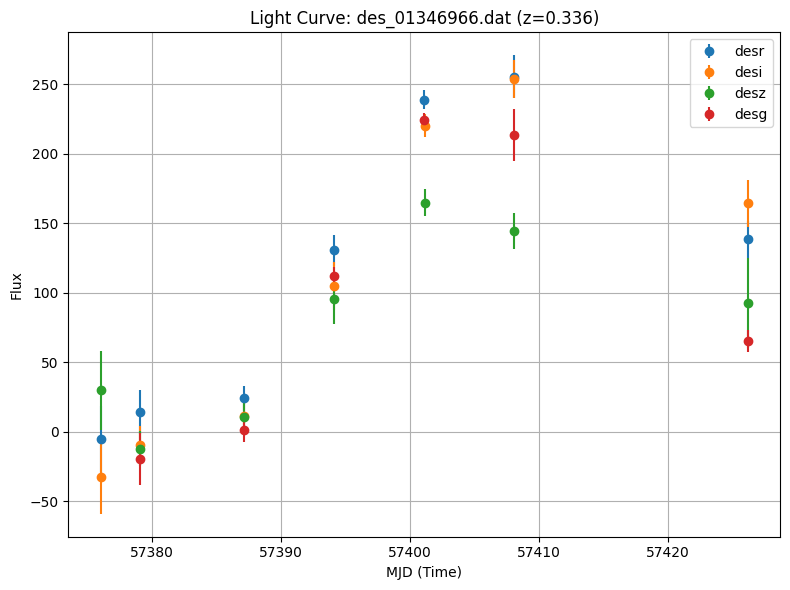


===== des_01283936.dat =====
Redshift: 0.369
         time  band      flux  fluxerr    zp zpsys
0   57248.373  desg    3.7800   7.8883  27.5    ab
1   57248.375  desr   10.1720  11.2770  27.5    ab
2   57248.378  desi   19.1750  20.1480  27.5    ab
3   57248.380  desz   -9.6510  22.5860  27.5    ab
4   57252.215  desg    6.6897   4.3424  27.5    ab
5   57252.218  desr   27.8150   6.5014  27.5    ab
6   57252.220  desi   29.9010   9.0101  27.5    ab
7   57252.222  desz   26.9670  10.7220  27.5    ab
8   57256.222  desg   26.5580   6.5527  27.5    ab
9   57256.225  desr   35.8350  14.3250  27.5    ab
10  57256.227  desi   70.9710  16.7850  27.5    ab
11  57256.229  desz   11.2950  21.2090  27.5    ab
12  57257.225  desg   19.5690   7.2470  27.5    ab
13  57257.227  desr   59.0320  13.9000  27.5    ab
14  57257.229  desi   40.3500  14.4360  27.5    ab
15  57257.232  desz   55.1400  13.2630  27.5    ab
16  57265.223  desg   59.0350  29.9890  27.5    ab
17  57265.225  desr  109.7800  21.73

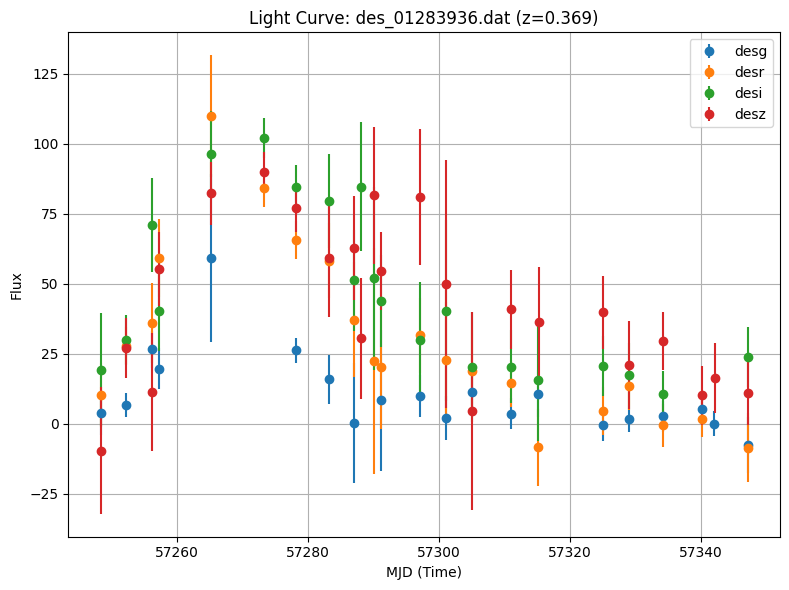


===== des_01285160.dat =====
Redshift: 0.7493
         time  band      flux   fluxerr    zp zpsys
0   57249.403  desg   0.92700   1.94400  27.5    ab
1   57249.412  desr   2.97750   1.93620  27.5    ab
2   57250.291  desr   4.68200   3.24580  27.5    ab
3   57250.305  desi   9.94980   5.06740  27.5    ab
4   57253.285  desz  11.32600   2.99420  27.5    ab
5   57255.334  desg   6.77600   3.07030  27.5    ab
6   57255.370  desr  22.73400   3.05430  27.5    ab
7   57257.281  desi  25.91300   2.68350  27.5    ab
8   57265.301  desz  40.96300   2.86660  27.5    ab
9   57265.347  desr  40.57500   4.79130  27.5    ab
10  57266.247  desi  50.91800   3.82220  27.5    ab
11  57268.254  desg  11.42100  14.12900  27.5    ab
12  57276.324  desr  38.80400   1.95140  27.5    ab
13  57277.322  desz  42.65600   2.03520  27.5    ab
14  57277.368  desi  49.77200   1.84420  27.5    ab
15  57278.247  desg   2.76000   1.87360  27.5    ab
16  57283.274  desr  27.13100   1.79450  27.5    ab
17  57284.354  de

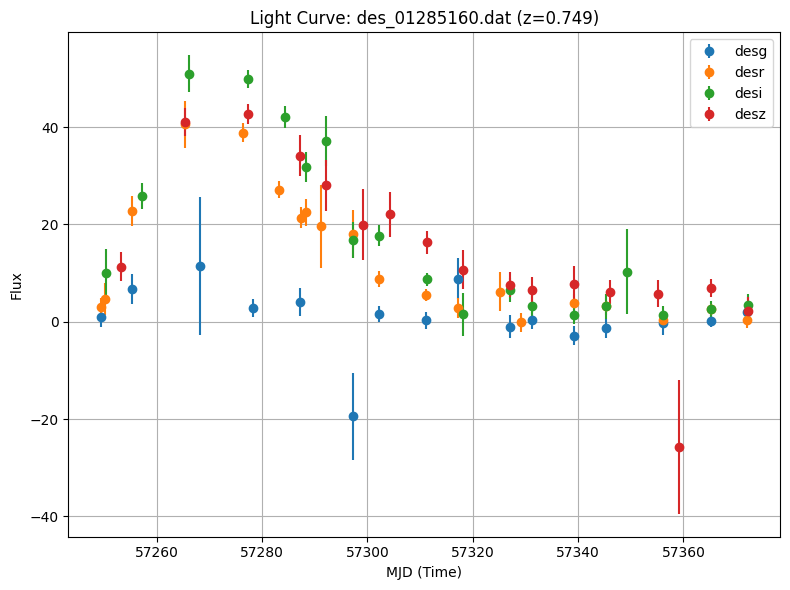


===== des_01285317.dat =====
Redshift: 0.5649
         time  band       flux  fluxerr    zp zpsys
0   57248.373  desg   -6.18500   7.6027  27.5    ab
1   57248.375  desr    4.18900  11.0200  27.5    ab
2   57248.378  desi   17.87700  17.5080  27.5    ab
3   57248.380  desz    4.33370  18.5890  27.5    ab
4   57252.215  desg   13.31300   4.1184  27.5    ab
5   57252.218  desr   37.10100   4.5347  27.5    ab
6   57252.220  desi   33.15200   7.1695  27.5    ab
7   57252.223  desz   27.80600   9.8117  27.5    ab
8   57256.222  desg   26.92100   7.2947  27.5    ab
9   57256.225  desr   50.19800  13.5040  27.5    ab
10  57256.227  desi   44.59800  14.3890  27.5    ab
11  57256.230  desz   23.62800  15.4550  27.5    ab
12  57257.225  desg   30.00100   7.3076  27.5    ab
13  57257.227  desr   63.42200  12.1390  27.5    ab
14  57257.229  desi   48.21400  12.3100  27.5    ab
15  57257.232  desz   57.69400  11.4750  27.5    ab
16  57265.223  desg   10.43100  25.6210  27.5    ab
17  57265.225  de

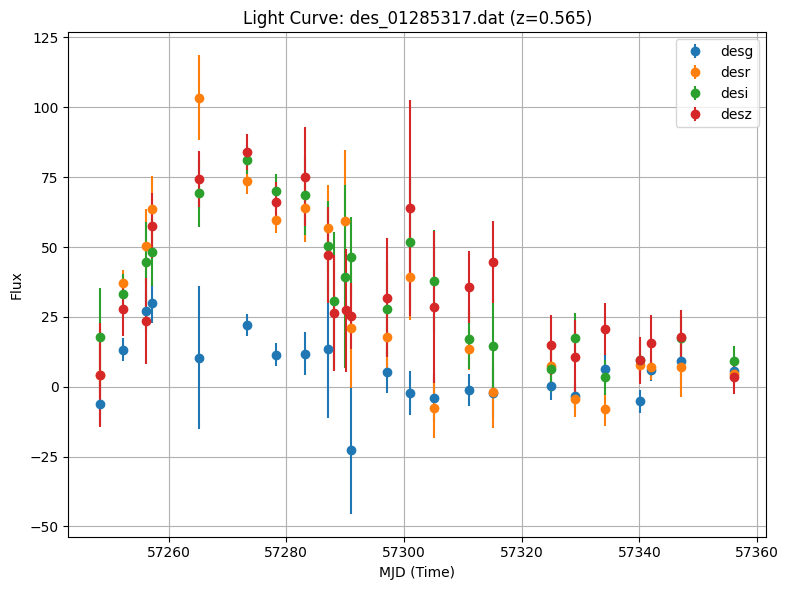


===== des_01286398.dat =====
Redshift: 0.1503
         time  band      flux  fluxerr    zp zpsys
0   57249.293  desg    2.3310   7.7728  27.5    ab
1   57249.302  desr   -7.5250  12.1860  27.5    ab
2   57249.318  desi   -8.8110  13.9100  27.5    ab
3   57249.340  desz  -26.2470  19.9440  27.5    ab
4   57253.343  desg    1.0990   6.9334  27.5    ab
5   57253.352  desr    3.1042  11.1500  27.5    ab
6   57253.373  desi   -2.0570  14.6740  27.5    ab
7   57255.288  desz    4.8560  26.5370  27.5    ab
8   57257.323  desg   81.9640   9.3401  27.5    ab
9   57257.332  desr   90.1470  11.2760  27.5    ab
10  57257.353  desi   89.1440  12.9190  27.5    ab
11  57265.240  desz  378.8300  25.5340  27.5    ab
12  57265.391  desi  528.8700  20.4020  27.5    ab
13  57273.342  desi  560.0900  16.9040  27.5    ab
14  57273.364  desz  363.8600  21.2670  27.5    ab
15  57278.219  desr  595.4900  16.8510  27.5    ab
16  57278.256  desg  479.2200  11.6100  27.5    ab
17  57283.189  desi  317.7300  13.6

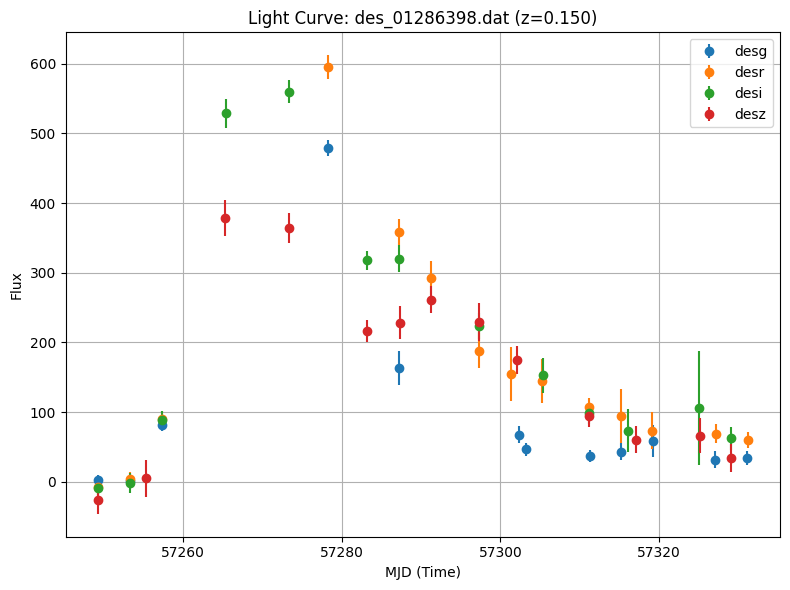


===== des_01287626.dat =====
Redshift: 0.304
         time  band      flux  fluxerr    zp zpsys
0   56653.047  desg   -9.9630  14.3090  27.5    ab
1   56653.052  desi   -8.2750  17.9550  27.5    ab
2   56653.054  desz    3.8030  16.9230  27.5    ab
3   56660.103  desg    1.4437   3.4414  27.5    ab
4   56660.105  desr   -1.1320   6.0119  27.5    ab
5   56660.105  desi   13.5050   8.3570  27.5    ab
6   56660.110  desz    7.2510  10.3290  27.5    ab
7   56667.075  desg   75.9370  13.6990  27.5    ab
8   56667.077  desr   33.5760  16.5640  27.5    ab
9   56667.079  desi   70.7090  13.6150  27.5    ab
10  56667.081  desz   55.0240  13.6470  27.5    ab
11  56675.118  desi  212.1200  14.4360  27.5    ab
12  56682.095  desg  201.0700   5.4372  27.5    ab
13  56682.098  desr  268.0400   6.7434  27.5    ab
14  56682.100  desi  265.6600   8.3077  27.5    ab
15  56682.103  desz  156.3600  12.2690  27.5    ab
16  56690.035  desg  150.0800   7.2411  27.5    ab
17  56690.038  desr  245.9500   7.44

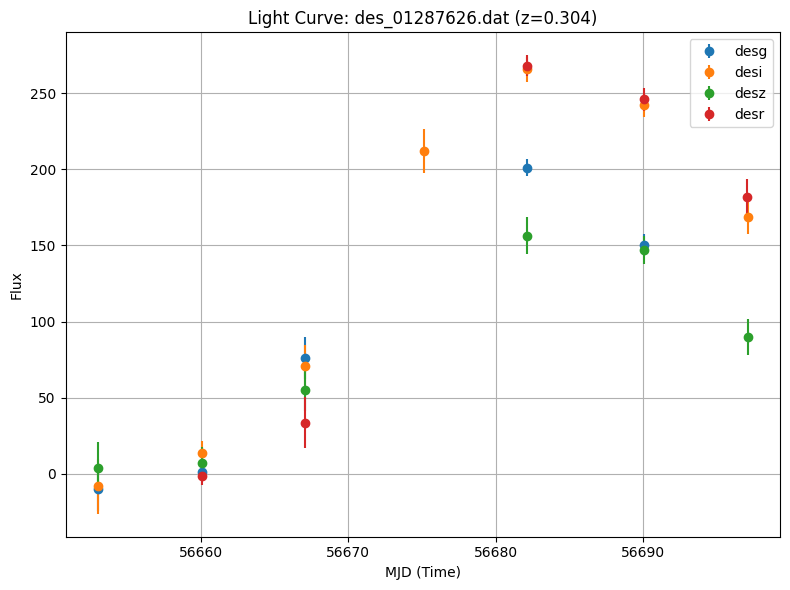


===== des_01289288 (1).dat =====
Redshift: 0.2897
         time  band       flux  fluxerr    zp zpsys
0   57248.373  desg    3.54600  10.8140  27.5    ab
1   57248.375  desr  -12.40800  23.6140  27.5    ab
2   57248.378  desi  -10.63600  38.9070  27.5    ab
3   57248.380  desz  -33.44600  39.9090  27.5    ab
4   57252.220  desi  -12.52000  20.2400  27.5    ab
5   57252.222  desz  -21.08000  23.0170  27.5    ab
6   57256.222  desg   -0.53800   9.7223  27.5    ab
7   57256.227  desi    3.46730  33.7500  27.5    ab
8   57256.229  desz  -26.09900  36.5810  27.5    ab
9   57257.225  desg   19.12100  10.1700  27.5    ab
10  57257.227  desr   19.53900  25.6260  27.5    ab
11  57257.232  desz    1.80400  28.3410  27.5    ab
12  57265.225  desr  160.10000  32.2310  27.5    ab
13  57265.227  desi  148.19000  30.4660  27.5    ab
14  57265.230  desz  111.03000  24.1220  27.5    ab
15  57273.314  desg  135.00000   6.6415  27.5    ab
16  57273.316  desr  201.53000  15.3120  27.5    ab
17  57273.318

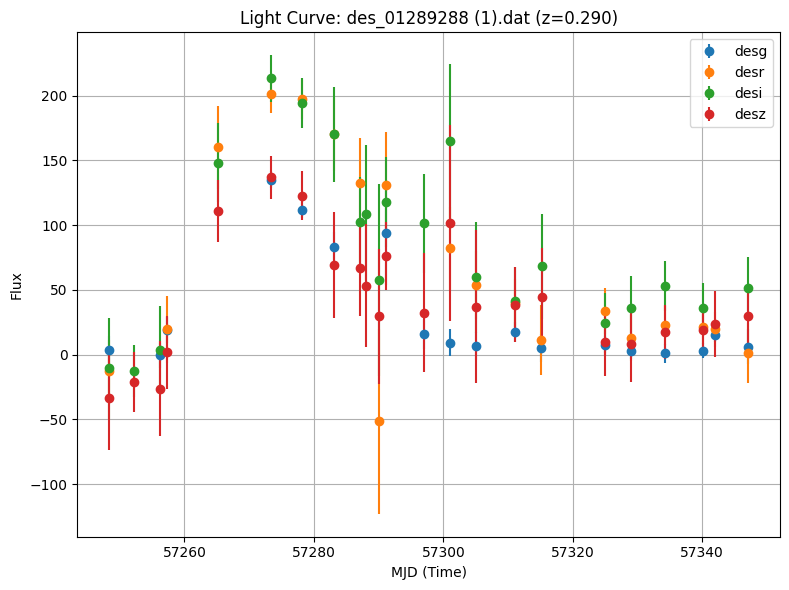


===== des_01289656.dat =====
Redshift: 0.5394
         time  band      flux  fluxerr    zp zpsys
0   57249.423  desg   7.79060   4.0817  27.5    ab
1   57250.330  desg  -1.95700  15.6670  27.5    ab
2   57250.337  desz  25.77600  21.2050  27.5    ab
3   57255.410  desg  17.55300   6.3509  27.5    ab
4   57255.413  desr  42.57800   7.1870  27.5    ab
5   57255.415  desi  34.25400   9.7561  27.5    ab
6   57255.417  desz  10.14800  14.4470  27.5    ab
7   57265.363  desg  47.80100  16.9210  27.5    ab
8   57265.368  desi  70.83200  10.0560  27.5    ab
9   57265.371  desz  68.04700   7.9481  27.5    ab
10  57276.340  desg  18.51000   4.9250  27.5    ab
11  57276.342  desr  69.00500   6.6580  27.5    ab
12  57276.344  desi  77.14600   8.1050  27.5    ab
13  57276.347  desz  83.28300  10.2600  27.5    ab
14  57278.233  desg  10.78000   4.2271  27.5    ab
15  57278.236  desr  69.97800   5.2816  27.5    ab
16  57278.238  desi  70.06700   6.0656  27.5    ab
17  57278.241  desz  73.29700   7.3

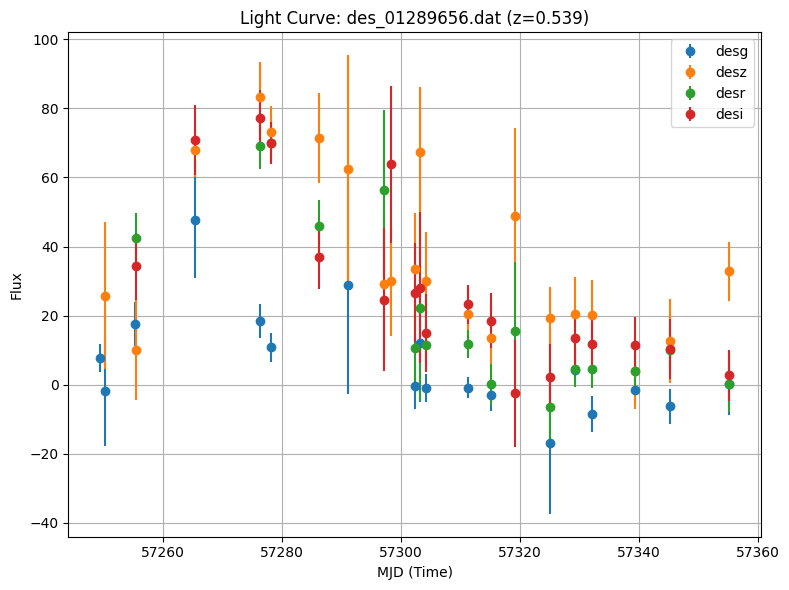


===== des_01289664.dat =====
Redshift: 0.2491
         time  band      flux  fluxerr    zp zpsys
0   57252.303  desg   -3.0950   5.6444  27.5    ab
1   57252.305  desr    6.8580   6.8944  27.5    ab
2   57252.307  desi   -8.0210   7.9789  27.5    ab
3   57252.310  desz   -1.6790  11.6180  27.5    ab
4   57256.295  desr   -5.0770   9.7767  27.5    ab
5   57256.297  desi    1.5990  10.1890  27.5    ab
6   57256.300  desz   -8.5210  15.6710  27.5    ab
7   57265.288  desr   68.7210  21.1850  27.5    ab
8   57265.291  desi   76.5010  14.9190  27.5    ab
9   57265.293  desz   61.7290  10.1160  27.5    ab
10  57276.312  desr  336.4100  12.6160  27.5    ab
11  57276.314  desi  324.5600   8.7522  27.5    ab
12  57276.317  desz  222.7200  12.0360  27.5    ab
13  57277.307  desg  313.9400   7.0608  27.5    ab
14  57277.310  desr  352.3400   7.2262  27.5    ab
15  57277.312  desi  324.8700   7.1428  27.5    ab
16  57277.315  desz  257.6300   9.8052  27.5    ab
17  57284.324  desg  241.9000   7.1

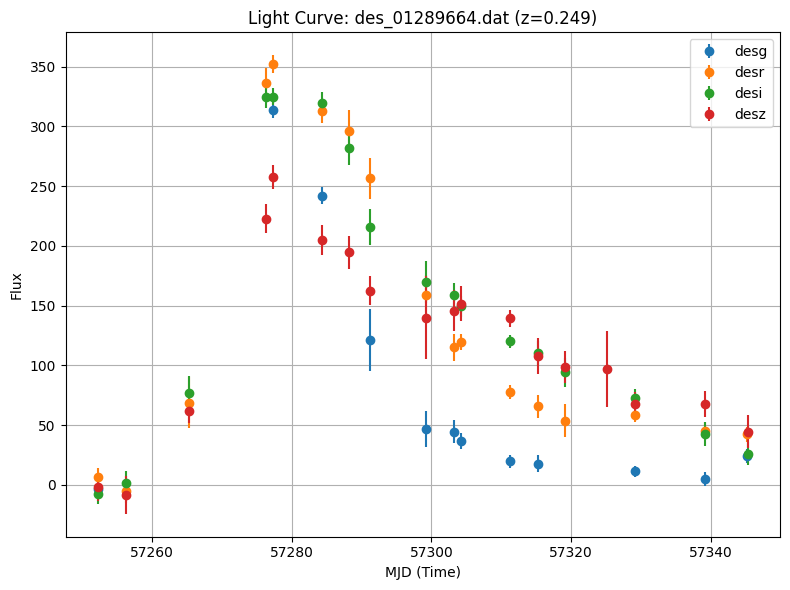


===== des_01290779.dat =====
Redshift: 0.3895
         time  band      flux  fluxerr    zp zpsys
0   56887.390  desg   75.7500   5.8541  27.5    ab
1   56887.393  desr  126.9000   5.9628  27.5    ab
2   56887.395  desi  120.3700   6.4256  27.5    ab
3   56887.398  desz  117.4000   7.7178  27.5    ab
4   56891.392  desg   86.8010   4.3986  27.5    ab
5   56891.394  desr  137.7400   5.9013  27.5    ab
6   56891.396  desi  139.7700   8.5760  27.5    ab
7   56891.399  desz  104.2300  10.8640  27.5    ab
8   56904.295  desg   30.8930   5.0919  27.5    ab
9   56904.298  desr   90.3820   5.9278  27.5    ab
10  56904.300  desi  104.6900   7.7313  27.5    ab
11  56904.302  desz   63.7860   8.9186  27.5    ab
12  56912.344  desg   36.1790  10.5830  27.5    ab
13  56912.346  desr   45.0960   8.3193  27.5    ab
14  56912.348  desi   71.7490   8.0657  27.5    ab
15  56912.351  desz   51.3750   8.1341  27.5    ab
16  56920.305  desg   14.9240   3.5394  27.5    ab
17  56920.307  desr   35.7910   4.2

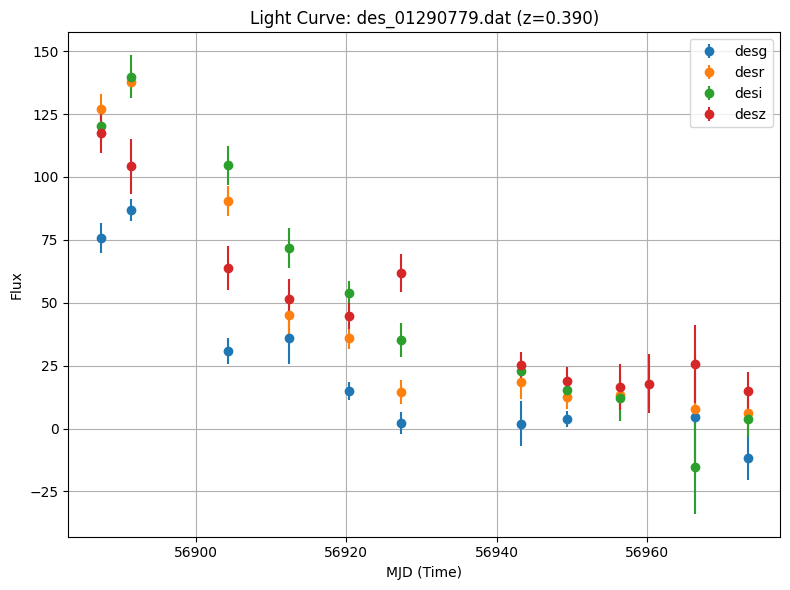


===== des_01290816.dat =====
Redshift: 0.2185
         time  band     flux  fluxerr    zp zpsys
0   56887.390  desg  394.200   7.0797  27.5    ab
1   56887.393  desr  424.670   7.7527  27.5    ab
2   56887.395  desi  349.550   7.7836  27.5    ab
3   56887.398  desz  232.890   9.0687  27.5    ab
4   56891.392  desg  407.060   6.0583  27.5    ab
5   56891.394  desr  457.670   8.1958  27.5    ab
6   56891.396  desi  393.180   9.8292  27.5    ab
7   56891.399  desz  225.700  12.0550  27.5    ab
8   56904.295  desg  224.400   5.6547  27.5    ab
9   56904.298  desr  338.800   8.1900  27.5    ab
10  56904.300  desi  287.780   9.6094  27.5    ab
11  56904.302  desz  133.850  10.1020  27.5    ab
12  56912.344  desg  124.920  11.8610  27.5    ab
13  56912.346  desr  223.520   9.5264  27.5    ab
14  56912.348  desi  205.060   9.3644  27.5    ab
15  56912.350  desz  104.720   9.4011  27.5    ab
16  56920.305  desg   64.023   3.6064  27.5    ab
17  56920.307  desr  177.660   5.9536  27.5    ab
18 

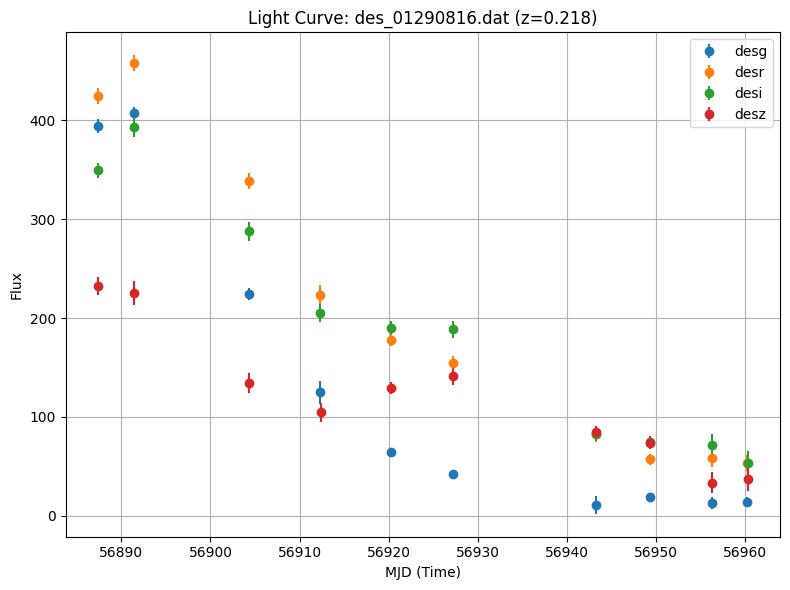


===== des_01291080.dat =====
Redshift: 0.4438
         time  band      flux  fluxerr    zp zpsys
0   56887.268  desg   26.6960   7.0980  27.5    ab
1   56887.270  desr  104.7300   8.8150  27.5    ab
2   56887.272  desi   99.3710   9.1391  27.5    ab
3   56887.275  desz   70.0760  10.8300  27.5    ab
4   56891.406  desg   23.6540   4.1505  27.5    ab
5   56891.409  desr   98.4450   5.1477  27.5    ab
6   56891.411  desi  103.9800   7.9386  27.5    ab
7   56891.414  desz   89.9730  10.5640  27.5    ab
8   56904.221  desg  -21.5650  13.8010  27.5    ab
9   56904.223  desr   38.4770   8.7713  27.5    ab
10  56904.225  desi   65.2300   9.7082  27.5    ab
11  56904.227  desz   54.3270  10.9360  27.5    ab
12  56915.292  desg   14.1320   8.7005  27.5    ab
13  56915.294  desr   28.3970   7.9307  27.5    ab
14  56915.296  desi   34.3480   7.8743  27.5    ab
15  56915.299  desz   16.7860   8.3791  27.5    ab
16  56923.302  desg  -11.4240   6.2193  27.5    ab
17  56923.304  desr    7.9630   8.4

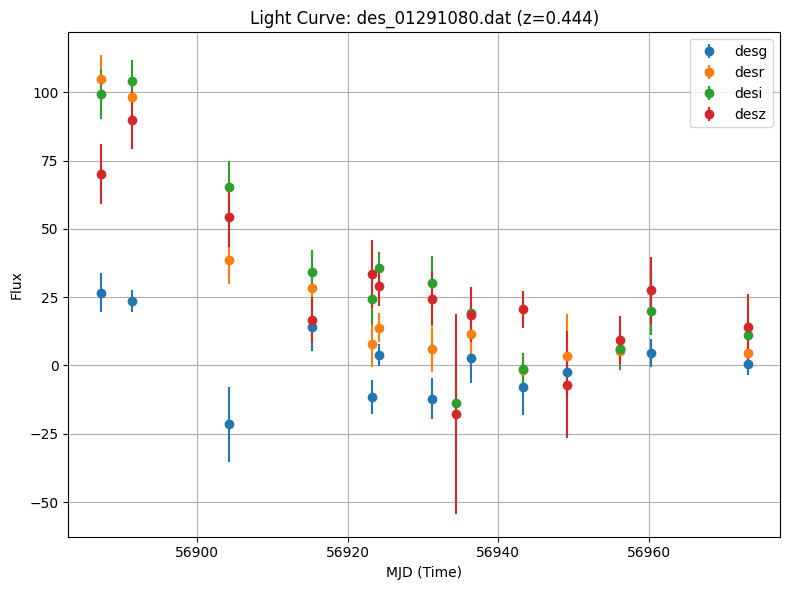


===== des_01291090.dat =====
Redshift: 0.292
         time  band     flux  fluxerr    zp zpsys
0   56887.211  desg   50.026   3.8648  27.5    ab
1   56887.213  desr   67.826   6.3371  27.5    ab
2   56887.215  desi   57.947   7.1674  27.5    ab
3   56887.218  desz   55.019   8.6037  27.5    ab
4   56891.377  desg  148.850   5.6574  27.5    ab
5   56891.380  desr  171.650   9.9854  27.5    ab
6   56891.382  desi  159.160  14.8960  27.5    ab
7   56891.384  desz  117.720  17.7090  27.5    ab
8   56903.120  desg  306.480  14.1620  27.5    ab
9   56903.123  desr  369.620  22.7630  27.5    ab
10  56903.125  desi  326.870  25.1070  27.5    ab
11  56903.128  desz  168.600  26.1100  27.5    ab
12  56912.096  desg  249.770  20.8330  27.5    ab
13  56912.098  desr  330.310  17.3730  27.5    ab
14  56912.101  desi  301.440  19.2870  27.5    ab
15  56912.103  desz  192.760  18.4130  27.5    ab
16  56916.089  desg  194.550  13.6250  27.5    ab
17  56916.091  desr  318.120  40.8690  27.5    ab
18  

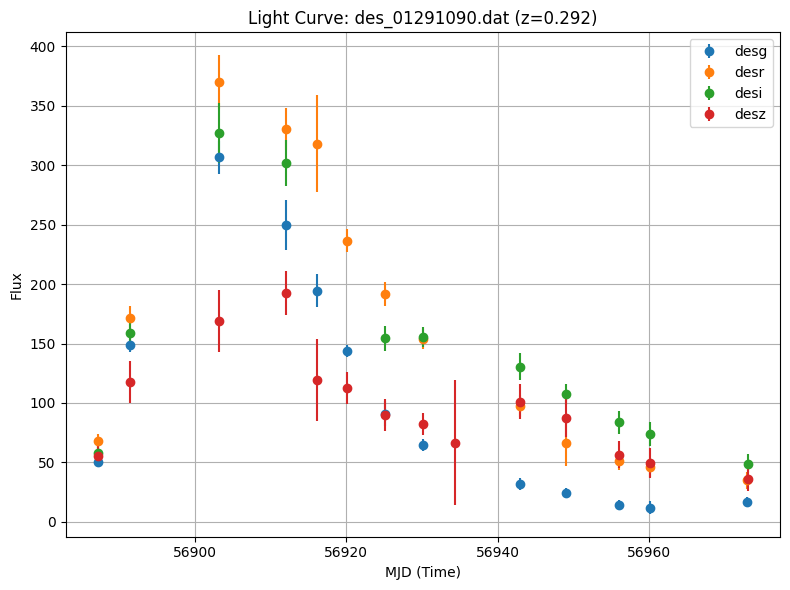


===== des_01291794.dat =====
Redshift: 0.3951
         time  band      flux  fluxerr    zp zpsys
0   57252.289  desg    0.1630   5.8952  27.5    ab
1   57252.291  desr   -6.0540  10.7750  27.5    ab
2   57252.293  desi   -2.5280  17.9600  27.5    ab
3   57252.296  desz   14.6850  24.4540  27.5    ab
4   57256.281  desr    4.7680  14.9220  27.5    ab
5   57256.283  desi  -24.7270  24.7470  27.5    ab
6   57256.285  desz   -3.0740  28.9330  27.5    ab
7   57257.309  desg   -0.3140   6.7105  27.5    ab
8   57257.311  desr    8.7707  10.9930  27.5    ab
9   57257.313  desi    8.7937  15.9720  27.5    ab
10  57257.316  desz   29.2930  18.2120  27.5    ab
11  57266.270  desg   40.4890  24.3430  27.5    ab
12  57266.273  desr  104.8800  25.1550  27.5    ab
13  57266.275  desi   68.3390  19.9450  27.5    ab
14  57266.277  desz   93.3440  16.5610  27.5    ab
15  57276.356  desr  182.6200  15.2460  27.5    ab
16  57276.358  desi  129.8400  16.1250  27.5    ab
17  57276.360  desz  110.6600  19.0

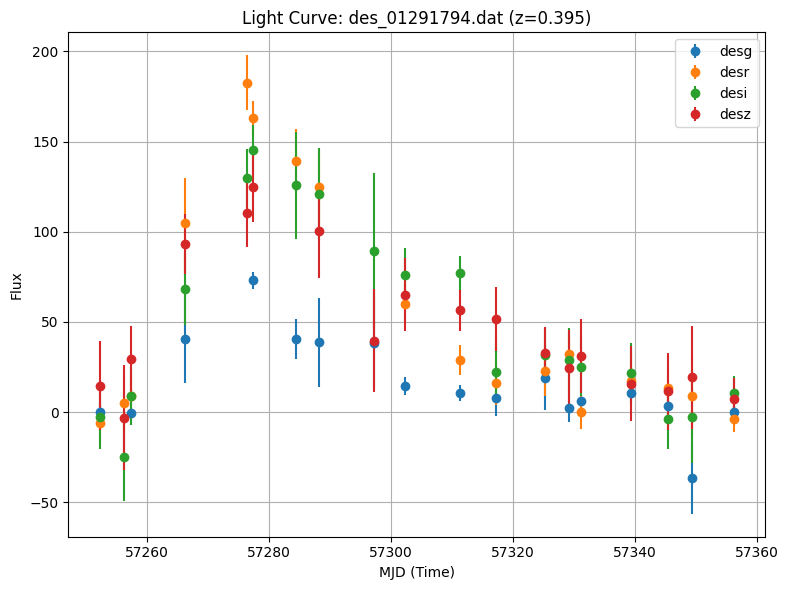


===== des_01291957.dat =====
Redshift: 0.36
         time  band      flux  fluxerr    zp zpsys
0   56877.179  desg  -63.4690  31.6090  27.5    ab
1   56877.181  desr    2.8560  18.7670  27.5    ab
2   56877.183  desi   21.9600  12.7590  27.5    ab
3   56877.186  desz   -1.0320  12.8060  27.5    ab
4   56885.209  desg   11.3980   9.3326  27.5    ab
5   56885.212  desr   17.8780   7.1892  27.5    ab
6   56885.214  desi   25.6010   6.5952  27.5    ab
7   56885.217  desz   15.0170   6.8629  27.5    ab
8   56890.218  desg   46.4720   4.9190  27.5    ab
9   56890.220  desr   69.9050   5.4680  27.5    ab
10  56890.222  desi   57.8370   6.7036  27.5    ab
11  56890.225  desz   57.9180   6.8221  27.5    ab
12  56903.107  desg  125.3600  19.0400  27.5    ab
13  56903.109  desr  199.9500  16.3950  27.5    ab
14  56903.111  desi  210.2100  13.3560  27.5    ab
15  56903.114  desz  139.8400  14.7470  27.5    ab
16  56912.083  desg   70.1810   9.5182  27.5    ab
17  56912.085  desr  179.8400   9.432

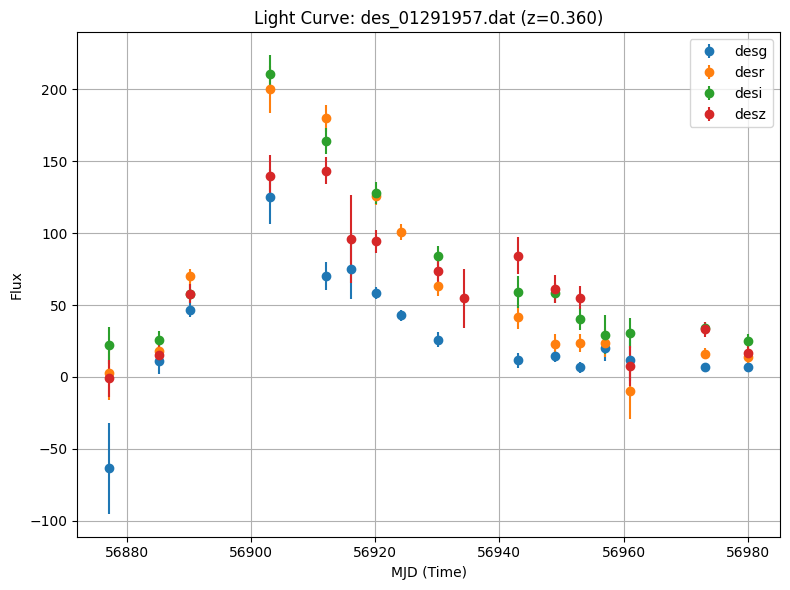


===== des_01292145.dat =====
Redshift: 0.4925
         time  band      flux  fluxerr    zp zpsys
0   57252.289  desg   4.96590   5.1443  27.5    ab
1   57252.291  desr   7.37600   6.3468  27.5    ab
2   57252.293  desi   2.50020  10.4400  27.5    ab
3   57252.296  desz  15.06300  14.2620  27.5    ab
4   57256.281  desr  22.19700   9.7319  27.5    ab
5   57256.283  desi  25.06500  14.3530  27.5    ab
6   57256.286  desz  45.86200  19.2270  27.5    ab
7   57257.309  desg   2.50090   5.5427  27.5    ab
8   57257.311  desr  23.17000   6.7123  27.5    ab
9   57257.313  desi  16.97400   9.2224  27.5    ab
10  57257.316  desz  24.45600  10.8290  27.5    ab
11  57266.270  desg -22.48900  27.2400  27.5    ab
12  57266.273  desr  51.61100  15.3280  27.5    ab
13  57266.275  desi  52.57400  12.3510  27.5    ab
14  57266.277  desz  59.18000   9.8747  27.5    ab
15  57276.356  desr  77.87000   9.0042  27.5    ab
16  57276.358  desi  50.72200   8.9675  27.5    ab
17  57276.360  desz  58.15200  10.9

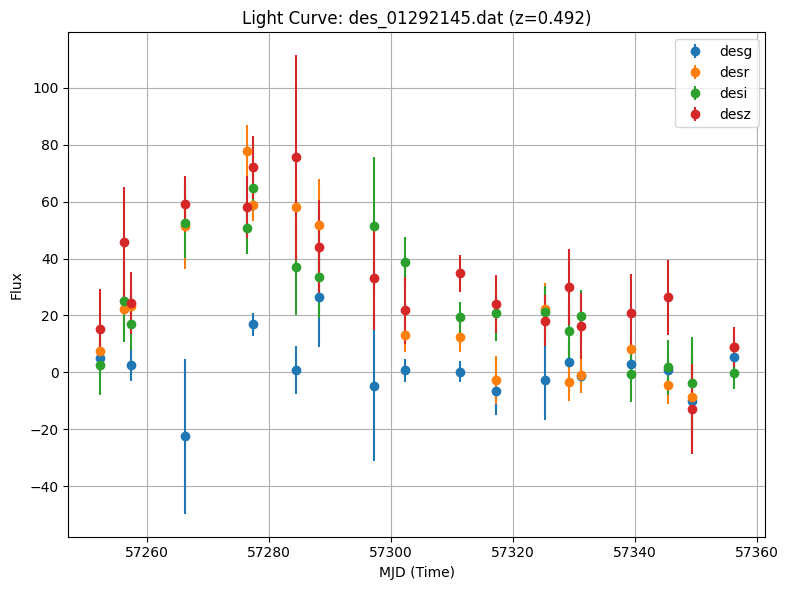


===== des_01292195.dat =====
Redshift: 0.8293
         time  band      flux   fluxerr    zp zpsys
0   57249.403  desg   1.34100   1.84880  27.5    ab
1   57249.412  desr  -3.37500   2.01090  27.5    ab
2   57250.290  desr   1.83100   3.53790  27.5    ab
3   57250.305  desi   2.45440   5.65980  27.5    ab
4   57253.265  desz  33.28800  13.40000  27.5    ab
5   57255.334  desg   3.34100   2.92360  27.5    ab
6   57255.370  desr   3.13760   3.17640  27.5    ab
7   57257.281  desi  11.45000   2.76220  27.5    ab
8   57265.305  desz  14.55300   3.53640  27.5    ab
9   57265.347  desr  10.09300   5.06600  27.5    ab
10  57266.247  desi  17.76200   4.07630  27.5    ab
11  57268.253  desg -33.78600  11.75600  27.5    ab
12  57276.324  desr  19.63200   2.01420  27.5    ab
13  57277.322  desz  27.05100   2.31200  27.5    ab
14  57277.368  desi  35.91600   1.91860  27.5    ab
15  57278.247  desg   1.54600   1.91540  27.5    ab
16  57283.275  desr  19.99800   1.86670  27.5    ab
17  57284.355  de

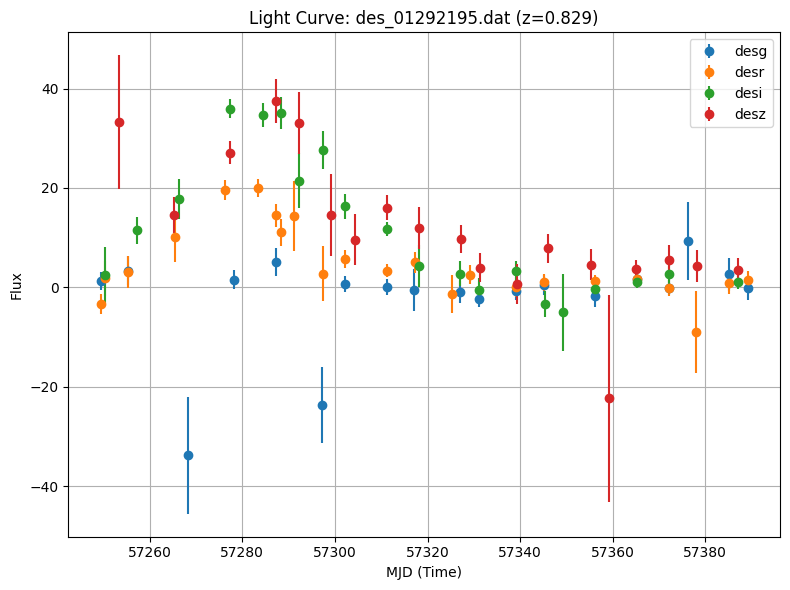


===== des_01292336.dat =====
Redshift: 0.2336
         time  band     flux  fluxerr    zp zpsys
0   56890.328  desg  140.020   5.5725  27.5    ab
1   56890.331  desr  154.950   9.5999  27.5    ab
2   56890.333  desi  162.670  11.3470  27.5    ab
3   56890.335  desz  111.250  14.2570  27.5    ab
4   56894.288  desi  231.500  25.8890  27.5    ab
5   56903.383  desg  266.910   8.0932  27.5    ab
6   56903.386  desr  335.550  14.1950  27.5    ab
7   56903.388  desi  332.550  22.1240  27.5    ab
8   56903.391  desz  161.790  17.3530  27.5    ab
9   56915.265  desg  149.710  25.5670  27.5    ab
10  56915.267  desr  294.070  29.7160  27.5    ab
11  56915.269  desi  224.580  24.2870  27.5    ab
12  56915.271  desz  116.580  17.2630  27.5    ab
13  56923.315  desg   50.404   7.2111  27.5    ab
14  56923.318  desr  160.010  12.4580  27.5    ab
15  56923.320  desi  170.580  13.4700  27.5    ab
16  56923.322  desz  121.250  16.2330  27.5    ab
17  56927.280  desg   34.143   6.1675  27.5    ab
18 

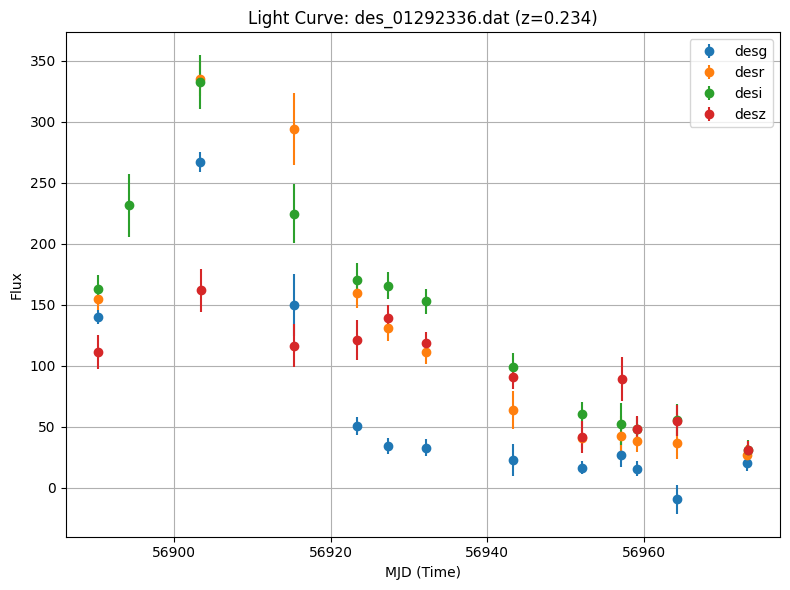


===== des_01292332.dat =====
Redshift: 0.2735
         time  band     flux  fluxerr    zp zpsys
0   56890.328  desg  215.470   6.4672  27.5    ab
1   56890.331  desr  218.380  10.9560  27.5    ab
2   56890.333  desi  198.320  18.8120  27.5    ab
3   56890.335  desz  159.900  20.7780  27.5    ab
4   56894.288  desi  265.640  33.1480  27.5    ab
5   56903.383  desg  327.740   8.4820  27.5    ab
6   56903.386  desr  377.480  16.9940  27.5    ab
7   56903.388  desi  347.770  28.9780  27.5    ab
8   56903.391  desz  186.720  24.9410  27.5    ab
9   56915.265  desg  158.750  20.4950  27.5    ab
10  56915.267  desr  290.500  34.5470  27.5    ab
11  56915.269  desi  227.800  29.8230  27.5    ab
12  56915.272  desz  121.220  25.1630  27.5    ab
13  56923.315  desg   73.736   6.4697  27.5    ab
14  56923.318  desr  172.120  14.3760  27.5    ab
15  56923.320  desi  187.760  21.6660  27.5    ab
16  56923.323  desz   77.567  23.0000  27.5    ab
17  56927.280  desg   52.639   5.7829  27.5    ab
18 

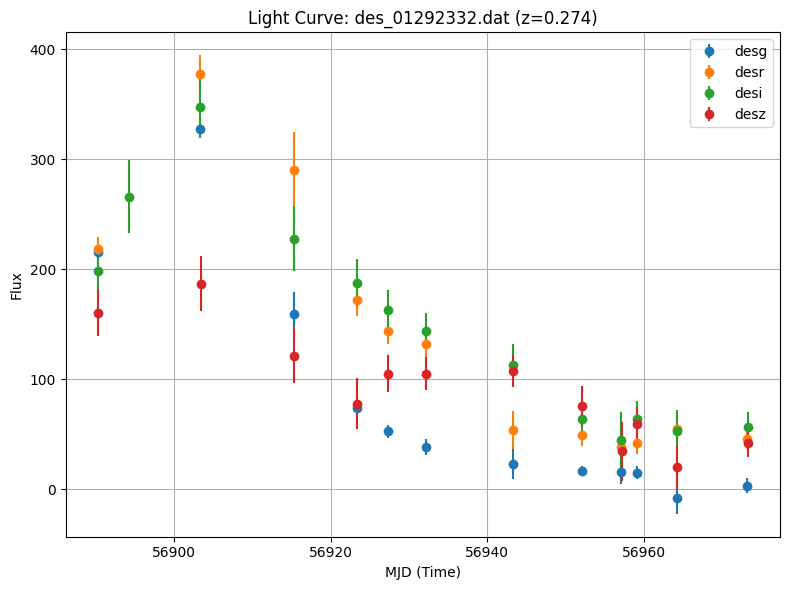


===== des_01292560.dat =====
Redshift: 0.2248
         time  band     flux  fluxerr    zp zpsys
0   56890.263  desi  131.180  11.0520  27.5    ab
1   56890.265  desz  111.790  13.9310  27.5    ab
2   56894.269  desi  252.040  20.7750  27.5    ab
3   56903.223  desg  553.410  12.8410  27.5    ab
4   56903.225  desr  533.280  11.8010  27.5    ab
5   56903.228  desi  446.980  12.3260  27.5    ab
6   56903.230  desz  277.340  16.1140  27.5    ab
7   56915.190  desg  317.980   9.1227  27.5    ab
8   56915.193  desr  399.310  12.2590  27.5    ab
9   56915.195  desi  336.790  12.0340  27.5    ab
10  56915.198  desz  158.810  13.5700  27.5    ab
11  56923.288  desg  155.920   9.0142  27.5    ab
12  56923.291  desr  277.430  14.2020  27.5    ab
13  56923.293  desi  250.220  14.2770  27.5    ab
14  56923.296  desz  103.540  15.8820  27.5    ab
15  56924.166  desg  153.060   6.7508  27.5    ab
16  56924.169  desr  266.130   9.1948  27.5    ab
17  56924.171  desi  237.360   9.3355  27.5    ab
18 

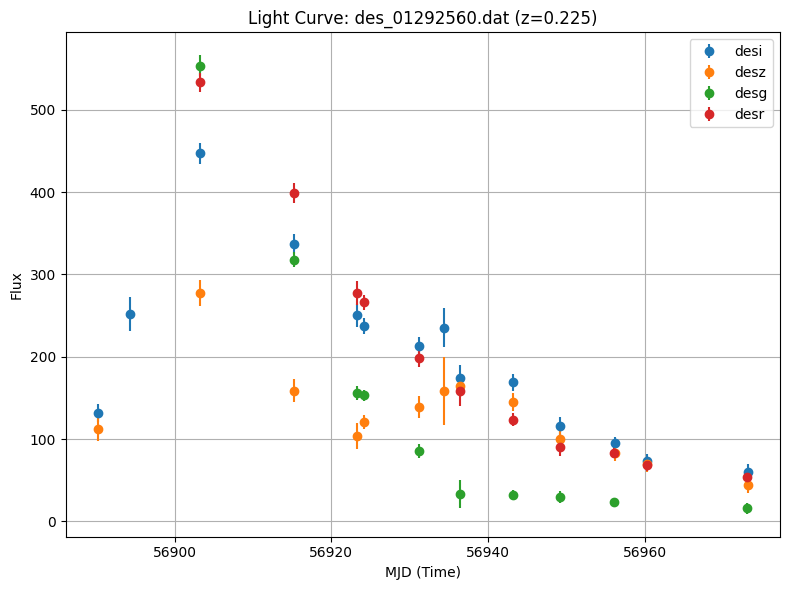


===== des_01293319.dat =====
Redshift: 0.2969
         time  band     flux  fluxerr    zp zpsys
0   56887.268  desg    2.870   7.0730  27.5    ab
1   56887.270  desr    8.904   9.2973  27.5    ab
2   56887.272  desi   -1.724  10.8900  27.5    ab
3   56887.275  desz    2.620  11.7560  27.5    ab
4   56891.406  desg   16.957   4.4332  27.5    ab
5   56891.409  desr   23.703   5.7533  27.5    ab
6   56891.411  desi   11.472   8.1309  27.5    ab
7   56891.414  desz   12.551  11.0160  27.5    ab
8   56904.221  desg  252.270  13.8970  27.5    ab
9   56904.223  desr  226.030  11.0220  27.5    ab
10  56904.225  desi  223.640  10.9520  27.5    ab
11  56904.227  desz  173.200  12.2240  27.5    ab
12  56915.292  desg  232.880  10.4690  27.5    ab
13  56915.294  desr  303.950  10.4650  27.5    ab
14  56915.296  desi  317.910   9.3893  27.5    ab
15  56915.299  desz  171.060  10.3820  27.5    ab
16  56923.302  desg  170.780   6.8027  27.5    ab
17  56923.304  desr  249.150  10.3960  27.5    ab
18 

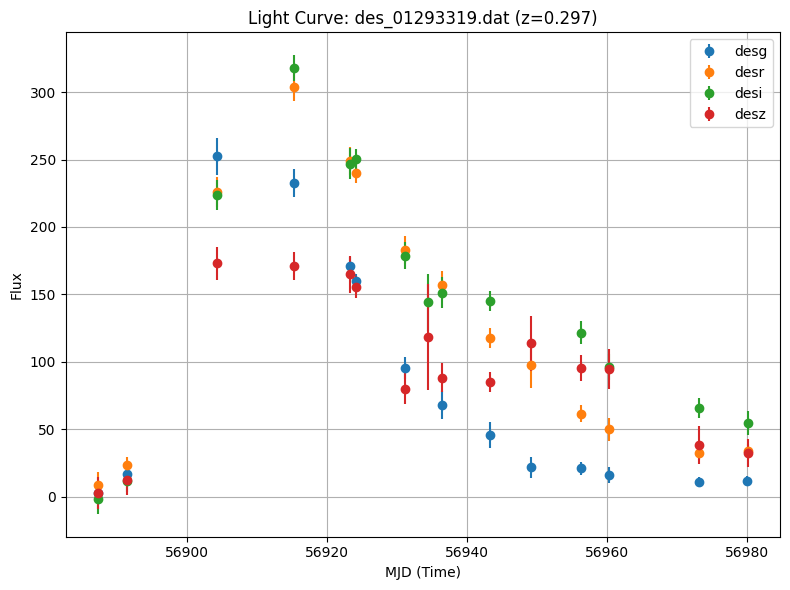


===== des_01293758.dat =====
Redshift: 0.1472
         time  band     flux  fluxerr    zp zpsys
0   56891.384  desz   -2.713  20.1760  27.5    ab
1   56903.107  desg  145.490  31.0010  27.5    ab
2   56903.109  desr  221.850  24.7720  27.5    ab
3   56903.114  desz   78.560  23.2390  27.5    ab
4   56903.120  desg  185.030  14.4880  27.5    ab
5   56903.128  desz  113.430  27.4310  27.5    ab
6   56912.083  desg  838.300  14.6200  27.5    ab
7   56912.096  desg  858.930  22.1100  27.5    ab
8   56912.098  desr  753.260  20.7700  27.5    ab
9   56916.071  desg  822.620  28.9840  27.5    ab
10  56916.074  desr  828.440  78.4380  27.5    ab
11  56916.080  desz  436.910  84.8230  27.5    ab
12  56916.091  desr  867.330  44.9860  27.5    ab
13  56916.097  desz  429.520  34.5580  27.5    ab
14  56920.082  desz  396.230  16.7520  27.5    ab
15  56925.158  desg  550.970  16.5600  27.5    ab
16  56930.123  desz  224.270  20.7620  27.5    ab
17  56930.134  desz  241.670  12.8900  27.5    ab
18 

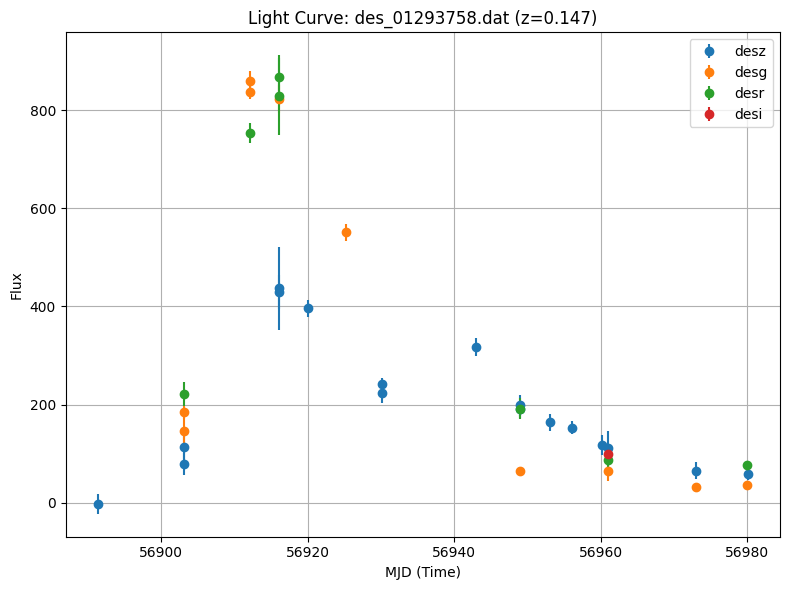


===== des_01294014.dat =====
Redshift: 0.3627
         time  band      flux  fluxerr    zp zpsys
0   56890.386  desg   18.4120   7.7966  27.5    ab
1   56890.388  desr   -7.9180  13.0180  27.5    ab
2   56903.397  desg   37.0750   6.4575  27.5    ab
3   56903.399  desr   54.8300  11.2630  27.5    ab
4   56903.401  desi   50.5350  16.8290  27.5    ab
5   56903.404  desz   86.1220  19.4780  27.5    ab
6   56915.280  desr  271.3100  34.4110  27.5    ab
7   56915.283  desi  201.3000  19.1260  27.5    ab
8   56915.285  desz  145.8300  18.1050  27.5    ab
9   56923.331  desr  188.6300   9.8156  27.5    ab
10  56927.294  desg   89.7350   5.2666  27.5    ab
11  56927.296  desr  154.9200   7.7694  27.5    ab
12  56927.298  desi  156.1400   9.3591  27.5    ab
13  56932.270  desg   58.6070   4.6063  27.5    ab
14  56932.273  desr  137.3400   7.1076  27.5    ab
15  56943.215  desg   26.9280  12.5290  27.5    ab
16  56943.218  desr  102.6700  18.3140  27.5    ab
17  56956.141  desg   11.1280   4.1

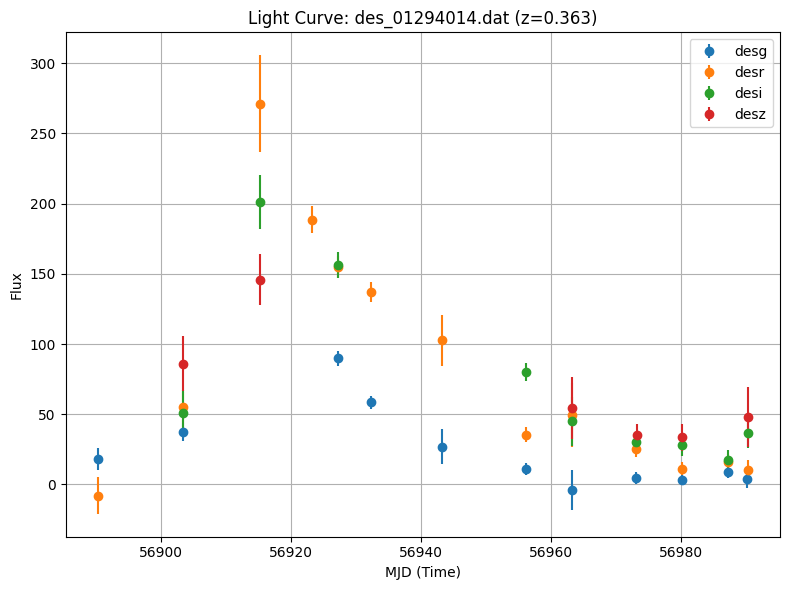


===== des_01294743.dat =====
Redshift: 0.3126
         time  band       flux  fluxerr    zp zpsys
0   56890.285  desz   -3.64400   9.7826  27.5    ab
1   56890.340  desi    4.19430   8.1069  27.5    ab
2   56890.366  desr    1.63730   9.0210  27.5    ab
3   56903.237  desg   56.59100   4.8645  27.5    ab
4   56903.361  desi   94.70600  15.6780  27.5    ab
5   56904.238  desz  103.13000   7.7517  27.5    ab
6   56912.209  desz   84.85400  21.9460  27.5    ab
7   56915.202  desr  141.74000  15.7420  27.5    ab
8   56915.232  desi  160.33000  12.3860  27.5    ab
9   56915.255  desg   68.33400  10.6310  27.5    ab
10  56916.195  desg   60.66300  10.8050  27.5    ab
11  56916.272  desz  112.25000   8.7133  27.5    ab
12  56924.193  desr   97.53800   4.6300  27.5    ab
13  56924.209  desi  118.01000   5.6628  27.5    ab
14  56924.234  desz   79.93400   6.0656  27.5    ab
15  56925.179  desg   34.45300   3.5695  27.5    ab
16  56931.175  desr   65.80600   5.1952  27.5    ab
17  56931.191  de

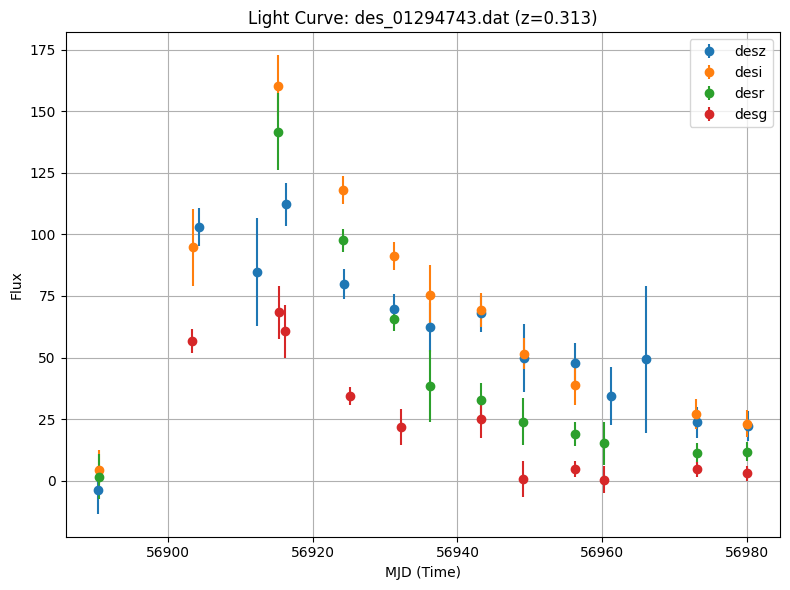


===== des_01295027.dat =====
Redshift: 0.4254
         time  band      flux  fluxerr    zp zpsys
0   56887.268  desg   -3.0350   7.6596  27.5    ab
1   56887.270  desr  -17.1090  10.8520  27.5    ab
2   56887.272  desi    1.0244  14.2760  27.5    ab
3   56887.275  desz   -5.6040  13.0950  27.5    ab
4   56891.406  desg    5.3632   5.3859  27.5    ab
5   56891.409  desr   25.2550   6.9275  27.5    ab
6   56891.411  desi   24.8740  10.7040  27.5    ab
7   56891.414  desz   28.5470  15.1120  27.5    ab
8   56904.221  desg   48.9470  17.1160  27.5    ab
9   56904.223  desr  122.9700  12.9780  27.5    ab
10  56904.225  desi   90.0170  12.9040  27.5    ab
11  56904.228  desz   84.9310  14.7060  27.5    ab
12  56915.292  desg   43.6170  10.5090  27.5    ab
13  56915.294  desr  133.2200  11.7770  27.5    ab
14  56915.296  desi  127.3100  11.9060  27.5    ab
15  56915.299  desz  100.5200  12.6570  27.5    ab
16  56923.302  desg   24.8840   7.7794  27.5    ab
17  56923.304  desr   80.7620  11.4

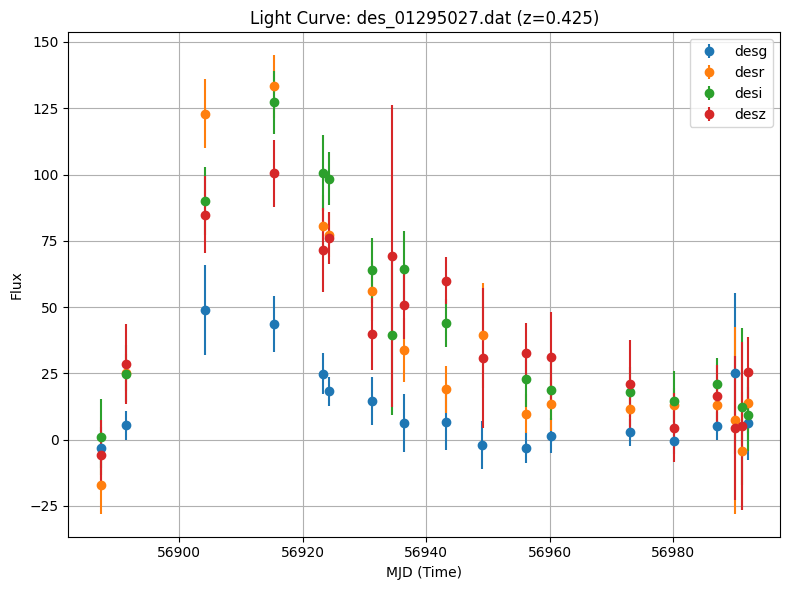


===== des_01295256.dat =====
Redshift: 0.4425
         time  band      flux  fluxerr    zp zpsys
0   56904.295  desg    1.4670   4.3266  27.5    ab
1   56904.298  desr    2.7542   5.4898  27.5    ab
2   56904.300  desi   13.3150   7.4001  27.5    ab
3   56904.303  desz   -2.5910   8.6151  27.5    ab
4   56912.348  desi   52.2830   7.6674  27.5    ab
5   56912.350  desz   20.2900   8.3612  27.5    ab
6   56920.305  desg   54.1350   3.7099  27.5    ab
7   56920.307  desr  120.3800   4.9502  27.5    ab
8   56920.309  desi   96.2400   5.0951  27.5    ab
9   56920.312  desz   85.5630   6.0095  27.5    ab
10  56927.235  desg   64.1810   4.4249  27.5    ab
11  56927.237  desr  141.1500   5.4553  27.5    ab
12  56927.239  desi  120.8100   6.4275  27.5    ab
13  56927.242  desz   93.1640   8.2710  27.5    ab
14  56943.230  desg   44.3410   9.5477  27.5    ab
15  56943.232  desr   86.3430   7.1106  27.5    ab
16  56943.234  desi   83.8430   5.8168  27.5    ab
17  56943.237  desz   64.6020   5.8

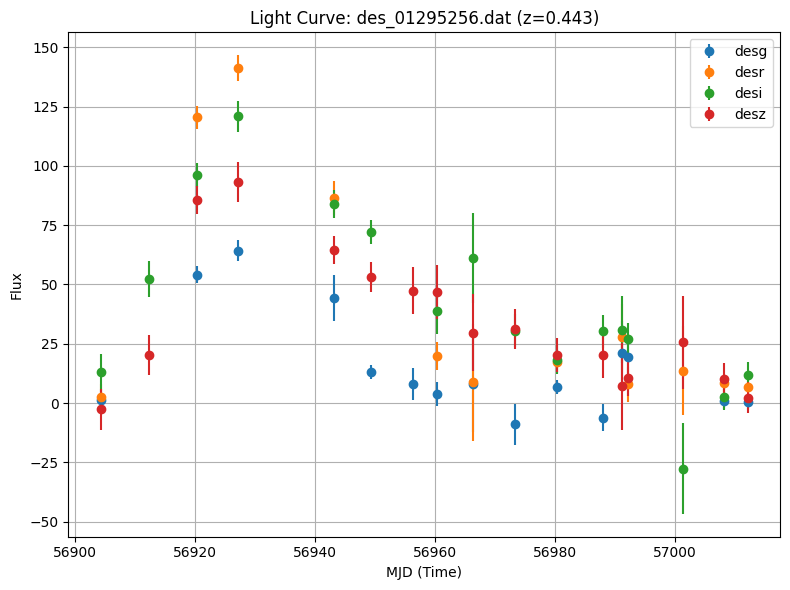


===== des_01295305.dat =====
Redshift: 0.6117
         time  band     flux  fluxerr    zp zpsys
0   56890.285  desz  -6.0170   4.2884  27.5    ab
1   56890.340  desi   4.9444   2.9866  27.5    ab
2   56890.366  desr  -0.5170   4.1445  27.5    ab
3   56903.237  desg   9.9786   3.2237  27.5    ab
4   56903.360  desi  42.0060   6.0579  27.5    ab
5   56904.238  desz  38.1730   3.3289  27.5    ab
6   56912.210  desz  31.5820   8.6535  27.5    ab
7   56915.203  desr  68.2270   6.6358  27.5    ab
8   56915.232  desi  68.9330   5.2182  27.5    ab
9   56915.255  desg  17.2670   7.4256  27.5    ab
10  56916.195  desg  13.0660   7.2557  27.5    ab
11  56916.272  desz  59.5560   3.7141  27.5    ab
12  56924.193  desr  49.1610   1.8175  27.5    ab
13  56924.209  desi  59.2720   2.0300  27.5    ab
14  56924.234  desz  54.8070   2.6095  27.5    ab
15  56925.179  desg   7.3503   2.1071  27.5    ab
16  56931.174  desr  33.3580   2.1682  27.5    ab
17  56931.191  desi  43.6830   2.1358  27.5    ab
18 

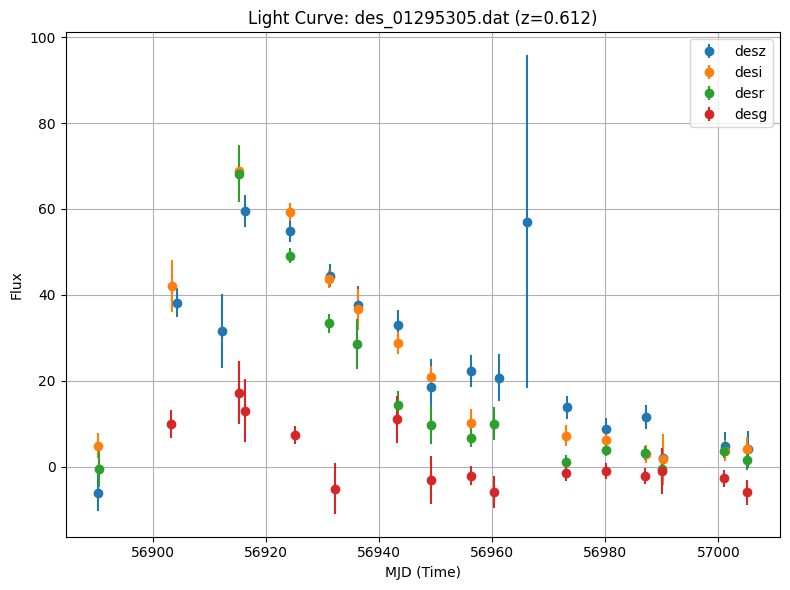


===== des_01296273.dat =====
Redshift: 0.397
         time  band      flux  fluxerr    zp zpsys
0   56903.383  desg   -0.2310   6.4395  27.5    ab
1   56903.386  desr   -0.5700  10.1740  27.5    ab
2   56903.388  desi   -3.8280  16.6690  27.5    ab
3   56903.391  desz   31.6450  13.1960  27.5    ab
4   56915.265  desg  121.7600  19.8630  27.5    ab
5   56915.267  desr   84.9800  25.7630  27.5    ab
6   56915.269  desi  115.3800  24.4420  27.5    ab
7   56915.272  desz  107.4700  12.7780  27.5    ab
8   56923.315  desg  168.3300   7.3009  27.5    ab
9   56923.318  desr  206.5600   9.4578  27.5    ab
10  56923.320  desi  173.5700  11.9590  27.5    ab
11  56923.322  desz  149.7900  12.9130  27.5    ab
12  56927.280  desg  137.0200   5.9446  27.5    ab
13  56927.283  desr  204.2300   7.5883  27.5    ab
14  56927.285  desi  186.2300   8.9210  27.5    ab
15  56927.288  desz  160.1100   9.2328  27.5    ab
16  56932.217  desg  108.1500   7.6847  27.5    ab
17  56932.220  desr  201.8200   7.81

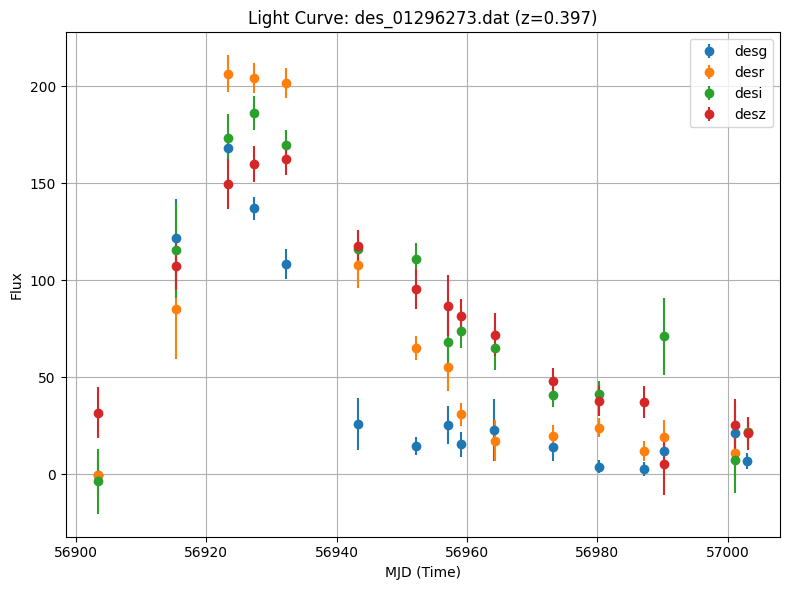


===== des_01295921.dat =====
Redshift: 0.5239
         time  band      flux  fluxerr    zp zpsys
0   56890.386  desg   -0.3390   9.0608  27.5    ab
1   56890.388  desr   -0.8550  10.9320  27.5    ab
2   56890.390  desi   16.4390  15.9790  27.5    ab
3   56890.393  desz   17.8630  18.3500  27.5    ab
4   56903.397  desg   19.4000   6.6563  27.5    ab
5   56903.399  desr   49.4890   9.0880  27.5    ab
6   56903.401  desi   76.1870  12.1480  27.5    ab
7   56903.404  desz   52.6430  16.0240  27.5    ab
8   56915.278  desg   19.1100  23.2700  27.5    ab
9   56915.280  desr  158.7500  31.6350  27.5    ab
10  56915.283  desi   51.0250  16.4020  27.5    ab
11  56915.285  desz   77.6420  15.0170  27.5    ab
12  56923.331  desr   56.9750   8.9040  27.5    ab
13  56923.333  desi   59.4800   9.2425  27.5    ab
14  56923.336  desz   80.9030  13.0300  27.5    ab
15  56927.294  desg   12.5180   5.5375  27.5    ab
16  56927.296  desr   51.7640   6.9163  27.5    ab
17  56927.298  desi   57.0910   7.2

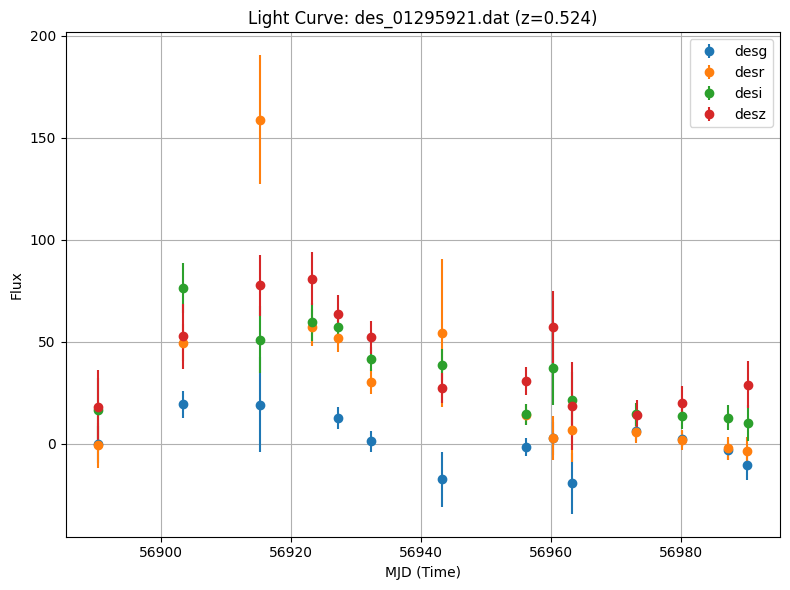


===== des_01296321.dat =====
Redshift: 0.1844
         time  band     flux  fluxerr    zp zpsys
0   56915.265  desg  102.520  17.9430  27.5    ab
1   56915.267  desr   96.704  31.8070  27.5    ab
2   56915.269  desi   62.844  28.4740  27.5    ab
3   56915.271  desz   54.893  22.0530  27.5    ab
4   56923.315  desg  294.050   9.3090  27.5    ab
5   56923.318  desr  334.150  12.4710  27.5    ab
6   56923.320  desi  317.910  15.4380  27.5    ab
7   56923.322  desz  232.280  19.8130  27.5    ab
8   56927.280  desg  354.430   9.0040  27.5    ab
9   56927.283  desr  403.370  12.4910  27.5    ab
10  56927.285  desi  336.870  13.5580  27.5    ab
11  56927.287  desz  246.810  14.5950  27.5    ab
12  56932.217  desg  324.810   9.8966  27.5    ab
13  56932.220  desr  416.950  11.6500  27.5    ab
14  56932.222  desi  336.110  12.8050  27.5    ab
15  56932.224  desz  208.190  12.5010  27.5    ab
16  56943.202  desg  184.670  17.4130  27.5    ab
17  56943.204  desr  277.550  17.3090  27.5    ab
18 

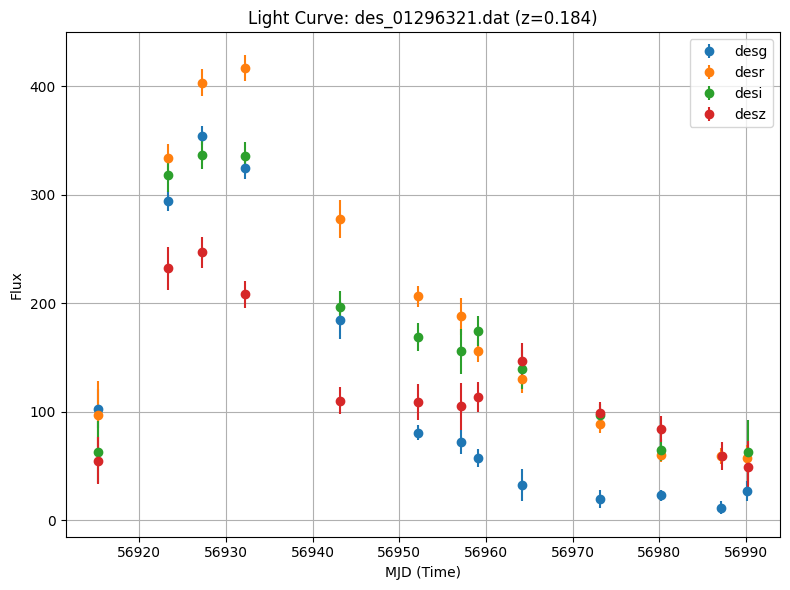


===== des_01296657.dat =====
Redshift: 0.1462
         time  band     flux  fluxerr    zp zpsys
0   56904.221  desg   21.887   40.767  27.5    ab
1   56904.223  desr    9.610   24.348  27.5    ab
2   56904.225  desi   15.795   26.308  27.5    ab
3   56904.227  desz    5.004   21.927  27.5    ab
4   56915.292  desg  755.480   29.542  27.5    ab
5   56915.296  desi  612.480   26.648  27.5    ab
6   56915.299  desz  396.190   21.067  27.5    ab
7   56923.306  desi  730.750   31.232  27.5    ab
8   56923.309  desz  462.960   25.949  27.5    ab
9   56924.187  desz  462.480   16.965  27.5    ab
10  56931.165  desi  685.350   29.799  27.5    ab
11  56931.168  desz  371.590   22.357  27.5    ab
12  56934.371  desi  546.970   46.514  27.5    ab
13  56934.372  desz  317.760   67.376  27.5    ab
14  56936.361  desg  540.650   29.221  27.5    ab
15  56936.363  desr  683.630   25.826  27.5    ab
16  56936.365  desi  473.210   28.564  27.5    ab
17  56936.368  desz  262.010   20.846  27.5    ab
18 

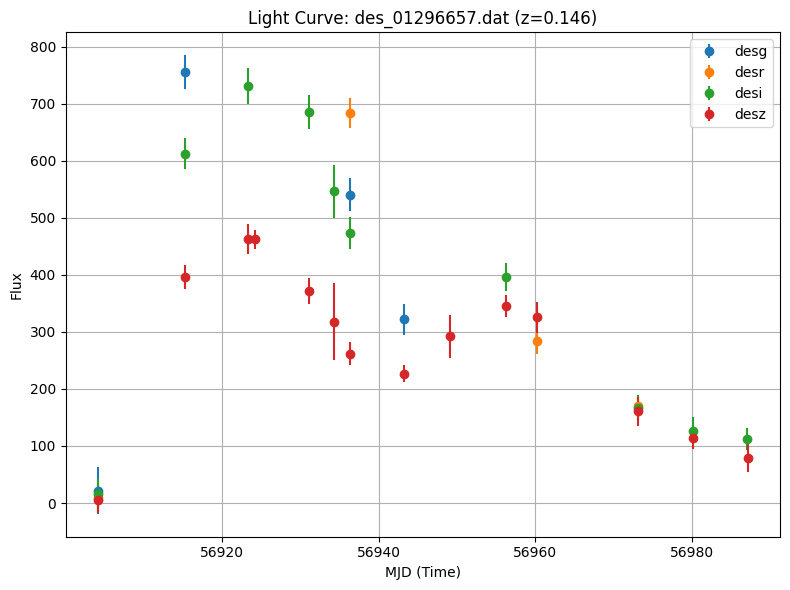


===== des_01297465.dat =====
Redshift: 0.2778
         time  band      flux  fluxerr    zp zpsys
0   56912.258  desz   -0.5660   7.8292  27.5    ab
1   56912.304  desr   -3.1500   6.0796  27.5    ab
2   56912.320  desi   -2.6230   5.1905  27.5    ab
3   56915.221  desg    6.6870   6.0632  27.5    ab
4   56916.204  desg    4.1916   7.0042  27.5    ab
5   56920.196  desg   19.2500   2.5342  27.5    ab
6   56920.205  desr   34.9460   3.1177  27.5    ab
7   56920.221  desi   35.3640   3.4769  27.5    ab
8   56920.245  desz   34.6510   4.5747  27.5    ab
9   56925.188  desg   85.3500   2.8374  27.5    ab
10  56925.306  desr  116.1300   3.7121  27.5    ab
11  56925.329  desi  112.9100   3.5654  27.5    ab
12  56927.177  desz  121.9600   7.1910  27.5    ab
13  56932.162  desg  186.5700   8.7353  27.5    ab
14  56932.172  desr  210.8200   5.8053  27.5    ab
15  56932.188  desi  205.8000   4.8135  27.5    ab
16  56933.175  desz  176.9600  42.7930  27.5    ab
17  56935.311  desz  174.4800  35.7

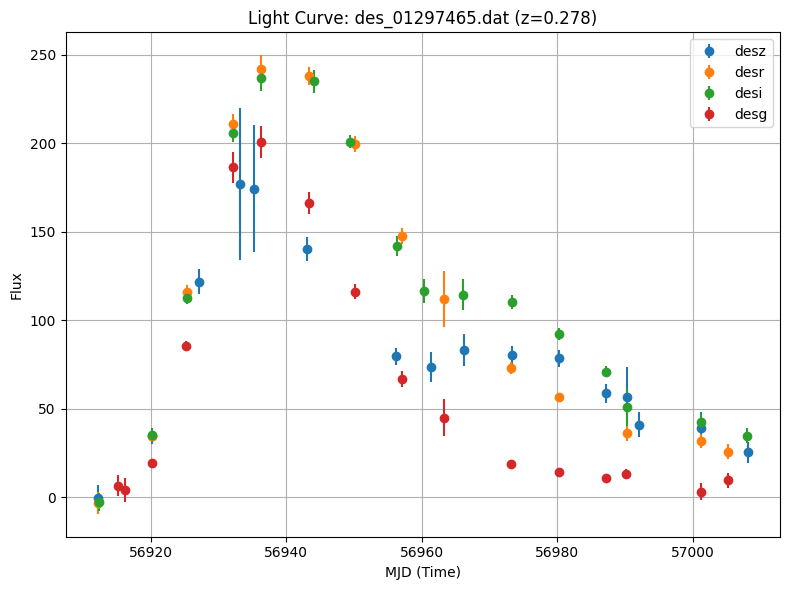


===== des_01297026.dat =====
Redshift: 0.2585
         time  band      flux  fluxerr    zp zpsys
0   56903.237  desg   -2.0180   4.9822  27.5    ab
1   56903.360  desi   -2.4480  22.5020  27.5    ab
2   56904.234  desz   -7.7640  17.3630  27.5    ab
3   56912.209  desz   26.9080  46.2970  27.5    ab
4   56915.203  desr  103.6000  19.9570  27.5    ab
5   56915.225  desi   69.1040  52.6460  27.5    ab
6   56915.255  desg   73.1640  11.3120  27.5    ab
7   56916.195  desg   93.6520  11.8440  27.5    ab
8   56916.271  desz  101.8500  20.1520  27.5    ab
9   56924.193  desr  273.3900  10.7130  27.5    ab
10  56924.209  desi  261.9200  11.2490  27.5    ab
11  56924.233  desz  188.5300  14.9670  27.5    ab
12  56925.179  desg  262.2900   4.8742  27.5    ab
13  56931.174  desr  297.6100   9.6548  27.5    ab
14  56931.190  desi  293.5400  13.0180  27.5    ab
15  56931.278  desz  173.6700  14.5110  27.5    ab
16  56932.152  desg  237.6900   9.0611  27.5    ab
17  56936.157  desr  267.3700  20.6

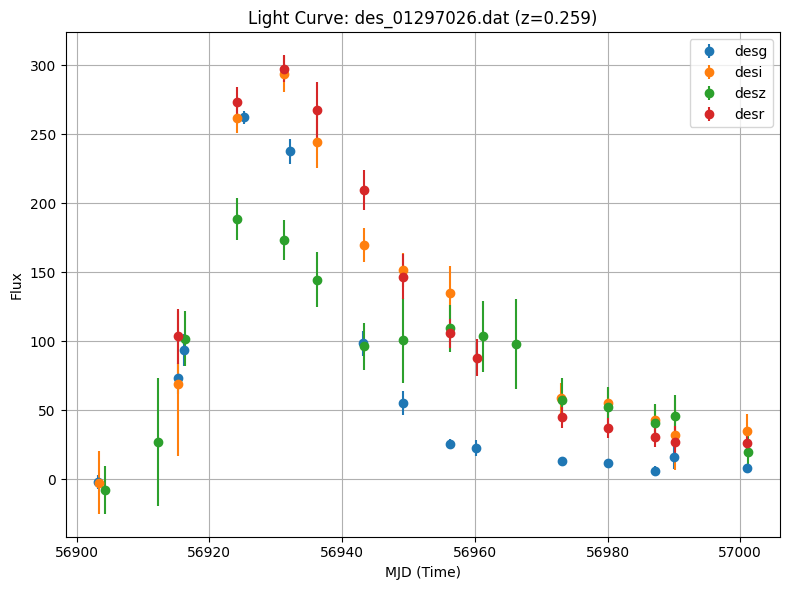


===== des_01298281.dat =====
Redshift: 0.2351
         time  band      flux  fluxerr    zp zpsys
0   56915.265  desg   36.5960  18.2480  27.5    ab
1   56915.267  desr   48.0220  25.5270  27.5    ab
2   56915.269  desi   -7.6370  24.2730  27.5    ab
3   56915.272  desz   17.0700  15.6410  27.5    ab
4   56923.315  desg  164.7300   7.2622  27.5    ab
5   56923.318  desr  200.8700  10.2490  27.5    ab
6   56923.320  desi  204.3300  11.4320  27.5    ab
7   56923.323  desz  158.4200  14.9170  27.5    ab
8   56927.280  desg  217.7900   7.1192  27.5    ab
9   56927.283  desr  260.8400   9.6071  27.5    ab
10  56927.285  desi  268.9500  10.3470  27.5    ab
11  56927.287  desz  172.4600  11.3940  27.5    ab
12  56932.217  desg  209.2100   8.2017  27.5    ab
13  56932.220  desr  287.9700   8.8533  27.5    ab
14  56932.222  desi  275.4600   9.3739  27.5    ab
15  56932.224  desz  177.4500   9.6815  27.5    ab
16  56943.204  desr  192.9800  15.5300  27.5    ab
17  56943.206  desi  174.3500  11.8

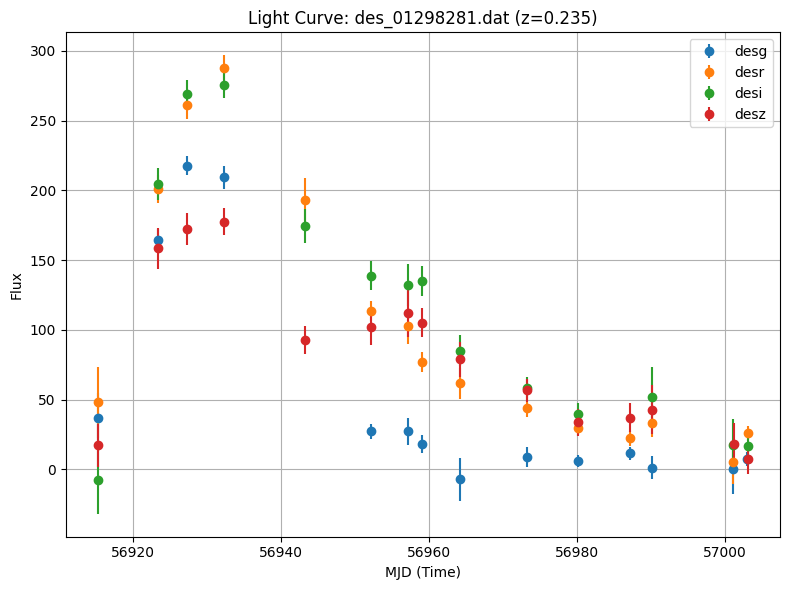


===== des_01298893.dat =====
Redshift: 0.1962
         time  band     flux   fluxerr    zp zpsys
0   56915.299  desz   -8.739   22.9220  27.5    ab
1   56923.307  desz   34.310   41.4040  27.5    ab
2   56924.185  desz   77.302   28.4110  27.5    ab
3   56931.161  desg  362.750   11.3720  27.5    ab
4   56931.166  desz  245.650   39.2910  27.5    ab
5   56934.371  desi  406.870   45.4460  27.5    ab
6   56934.372  desz  353.480   94.9720  27.5    ab
7   56943.247  desr  367.990   15.7510  27.5    ab
8   56943.249  desi  299.020   16.7740  27.5    ab
9   56943.252  desz  160.710   18.6990  27.5    ab
10  56949.115  desr  217.260   31.4440  27.5    ab
11  56949.117  desz  113.240   77.8390  27.5    ab
12  56956.203  desg   50.893    6.3487  27.5    ab
13  56956.206  desr  176.020   12.8570  27.5    ab
14  56956.208  desi  171.450   19.7380  27.5    ab
15  56956.211  desz  161.760   23.4690  27.5    ab
16  56990.071  desg   33.374   43.2260  27.5    ab
17  56990.076  desi  137.940  297.1

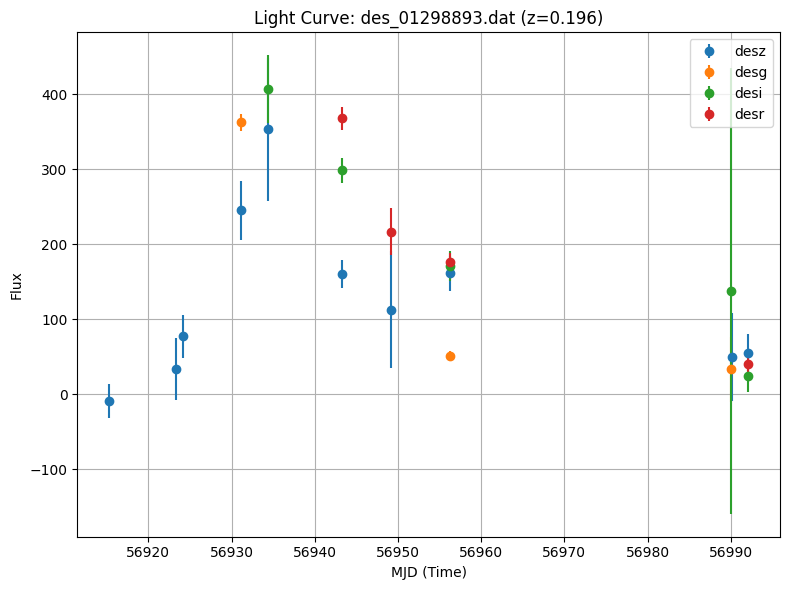


===== des_01299643.dat =====
Redshift: 0.38
         time  band      flux  fluxerr    zp zpsys
0   56912.344  desg  -11.4230  12.9030  27.5    ab
1   56912.346  desr  -12.2000   8.9647  27.5    ab
2   56912.348  desi    9.3370   9.5786  27.5    ab
3   56912.350  desz   -0.2090   9.8233  27.5    ab
4   56920.305  desg    3.7834   3.4097  27.5    ab
5   56920.307  desr   15.0990   4.9875  27.5    ab
6   56920.309  desi   12.9730   5.3600  27.5    ab
7   56920.312  desz   10.9900   6.6706  27.5    ab
8   56927.235  desg   67.9360   4.1204  27.5    ab
9   56927.237  desr   97.7940   6.5112  27.5    ab
10  56927.239  desi   79.2700   8.1879  27.5    ab
11  56927.242  desz   82.2620   9.3802  27.5    ab
12  56943.230  desg  114.2500   8.9416  27.5    ab
13  56943.232  desr  203.6400   8.1959  27.5    ab
14  56943.234  desi  177.7100   7.6804  27.5    ab
15  56943.237  desz  133.8200   6.8417  27.5    ab
16  56949.323  desg   84.4860   3.6041  27.5    ab
17  56949.326  desr  167.6200   6.223

KeyboardInterrupt: 

In [ ]:
# This cell gives you the table of data and only light-curve plot for each supernoave.

# === Directory with SN .dat files ===
data_dir = '/content/drive/MyDrive/DES-SN'

# === Loop over each SN file ===
for file in os.listdir(data_dir):
    if file.endswith('.dat'):
        full_path = os.path.join(data_dir, file)

        try:
            # Read photometric data
            data_table, redshift = read_sn_file(full_path)
            df = data_table.to_pandas()

            print(f"\n===== {file} =====")
            print(f"Redshift: {redshift}")
            print(df)

            # === Plot light curve ===
            plt.figure(figsize=(8, 6))
            for band in df['band'].unique():
                band_data = df[df['band'] == band]
                plt.errorbar(band_data['time'], band_data['flux'],
                             yerr=band_data['fluxerr'],
                             fmt='o', label=band)

            plt.title(f'Light Curve: {file} (z={redshift:.3f})')
            plt.xlabel('MJD (Time)')
            plt.ylabel('Flux')
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()

        except Exception as e:
            print(f"Failed to process {file}: {e}")


In [ ]:
# Saved the parameter information in a csv file
df_results = pd.DataFrame(results)
df_results.to_csv('sncosmo_multifit_results.csv', index=False)


Distance Modulus:

* Distance Modulus is a quantity used to measure the distance of distant objects
having known the absolute and apparent magnitude of that object.


 * Observationally one cna determine using Tripp's formula:
           μ_obs = m - M + α*x1 - β*c
 *   m = -2.5log(x0)       
 *   Now, we have the information of x0,x1, and from fitting using that we inferred the observed distance modulus

In [ ]:
df = pd.read_csv("/content/sncosmo_multifit_results.csv")

# Constants
alpha = 0.14   # Stretch coefficient
beta = 3.1     # Color coefficient
M = -27  # Absolute magnitude of SNe Ia

# Compute m_B and distance modulus
df['mB'] = -2.5 * np.log10(df['x0'])  # Apparent peak magnitude
df['mu'] = df['mB'] - M + alpha * df['x1'] - beta * df['c']



In [ ]:
df['mB']

,mB
0,11.191912
1,9.858694
2,11.962842
3,12.071896
4,9.992745
5,9.148373
6,10.855846
7,9.738339
8,11.717232
9,11.981583


In [ ]:
df['mu'].mean()

np.float64(38.662952390340564)

In [ ]:
df['fitness_2sigma'].mean()

np.float64(0.9349995073212031)

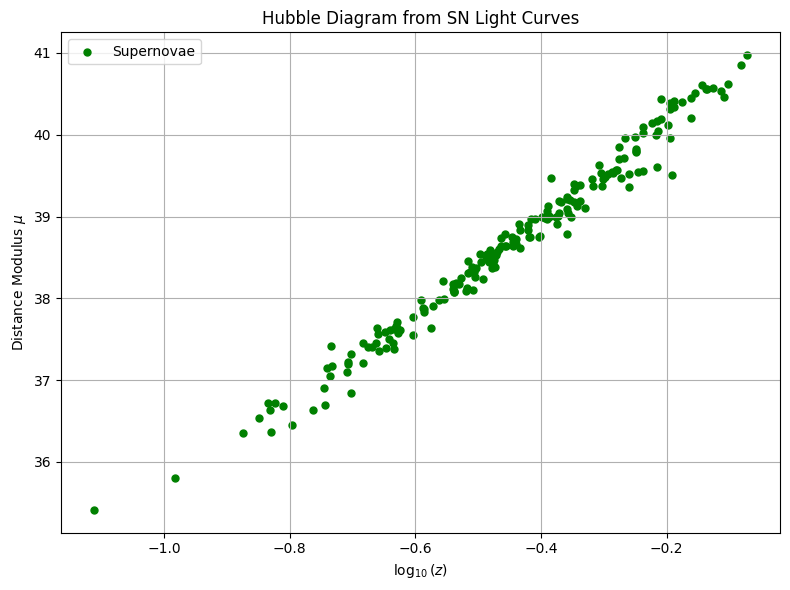

In [ ]:
# Plot

plt.figure(figsize=(8,6))
plt.scatter(np.log10(df['z']), df['mu'], c='green', s=25, label='Supernovae')
plt.xlabel(r'$\log_{10}(z)$')
plt.ylabel(r'Distance Modulus $\mu$')
plt.title("Hubble Diagram from SN Light Curves")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


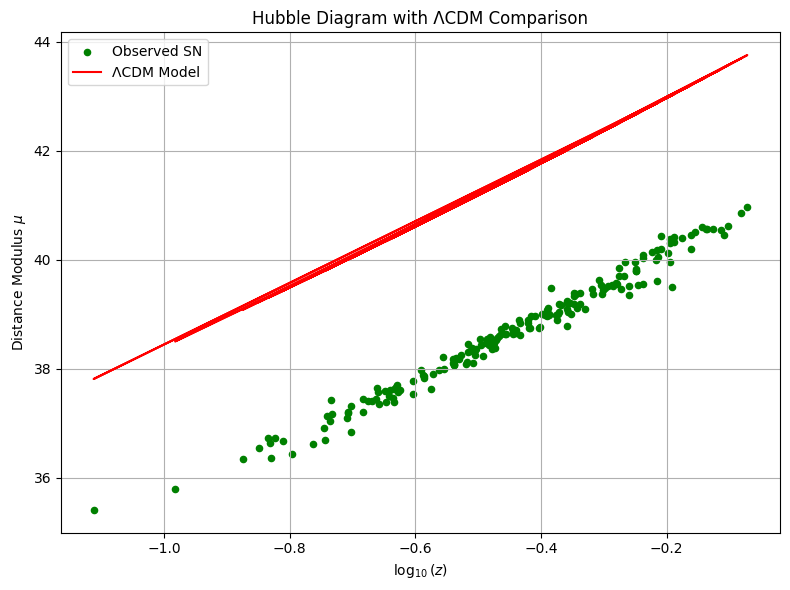

In [ ]:
# Comparing distance modulus from observatios and model prediction.


from astropy.cosmology import FlatLambdaCDM

cosmo = FlatLambdaCDM(H0=67, Om0=0.3)
z_vals = df['z']
mu_model = cosmo.distmod(z_vals).value   # built-in function distance modulus

plt.figure(figsize=(8,6))
plt.scatter(np.log10(df['z']), df['mu'], label='Observed SN', color='green', s=20)



plt.plot(np.log10(z_vals), mu_model, label='ΛCDM Model', color='red')
plt.xlabel(r'$\log_{10}(z)$')
plt.ylabel(r'Distance Modulus $\mu$')
plt.legend()
plt.title("Hubble Diagram with ΛCDM Comparison")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# Calculate reduced chi-squared for each SN
df['chi2_reduced'] = df['chi2'] / df['ndof']




In [ ]:
df['chi2_reduced'].mean()

np.float64(1.9754889075156015)

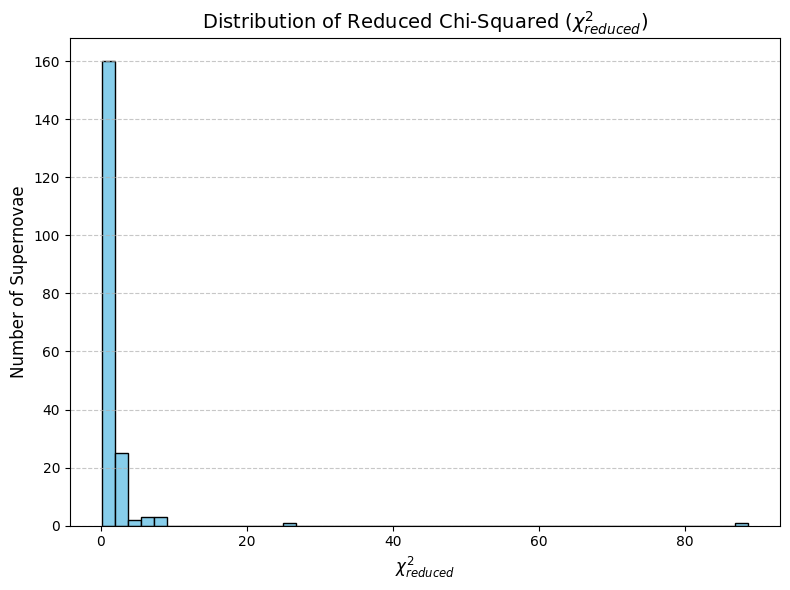

In [ ]:
# Plot histogram of reduced chi-squared
plt.figure(figsize=(8, 6))
plt.hist(df['chi2_reduced'], bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Reduced Chi-Squared ($\chi^2_{reduced}$)', fontsize=14)
plt.xlabel('$\chi^2_{reduced}$', fontsize=12)
plt.ylabel('Number of Supernovae', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()




Result and Conclusion:
---

We obtained the light curve plots and the parameters, x0,x1,t0,c by fitting salt2-extended model.
* x0: Shows the amplitude, and can convert into 'm'
apparent magnitude.
* x1: Describes time stretching of the light curve, more means broader---brighter SN.
* t0: peak time corresponding to peak brightness.
* c:  reflects the color excess, positive--redder, negative---bluer.

All this parameter gives you the information on nature of SNe and eventually also tells you the distance. Followed by this we compute distance modulus, although it matched the hubble diagram---distant object are more farther and less appeared luminous, means universe is expanding. There is a offset with the lcdm model and the reason one can deduce was due to complexcity that's why not considering the bias factor in distance modulus. Which required further an simulation processes.

We have also compute the fitness of the model with the data within 2 sigma and got an average 93% . We plotted histogram for the reduced chi-square and the average value produce to ≈ 1.97. Which is moderately good, usually it has to be around ≈1. But here as we mentioned, we didn't take any bias factor.


Future Work:
---
* Working on bias to improve the accuracy.
* Cosmological parameter estimation, H_0, Ω_m, Ω_DE. And beyond ΛCDM we can use different model for analysis.
* Another important work is to implement the ML and neural networks.





In [ ]:
from astropy.io import fits

In [ ]:
with fits.open('/content/DES-SN5YR_DES_PHOT.FITS.gz') as hdul:
  hdul.info()
  data = hdul[0].data
  print(data.shape)

Filename: /content/DES-SN5YR_DES_PHOT.FITS.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      19   (0,)      
  1  Photometry    1 BinTableHDU     69   1798736R x 20C   [1D, 20A, 1I, 1J, 12A, 1J, 1E, 1E, 1E, 1E, 1E, 1E, 1E, 1E, 1E, 1E, 1E, 1E, 1E, 1E]   
(0,)
